In [ ]:
import sys

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PARENT_DIR  = '/content/drive/MyDrive/AUS LAB II'
    IN_COLAB    = True
except ModuleNotFoundError:
    PARENT_DIR  = '/home/tildai/Desktop/Development/drone-detection-api/deployment/v2'
    IN_COLAB    = False

print(f"Running {'in Colab' if IN_COLAB else 'locally'}, PARENT_DIR={PARENT_DIR}")


PACKAGE_DIR = PARENT_DIR + '/drone_detection'

# Remove the package directory itself if it was added earlier
sys.path = [p for p in sys.path if p != PACKAGE_DIR]

# Ensure only the parent is on sys.path
if PARENT_DIR not in sys.path:
  sys.path.insert(0, PARENT_DIR)

# Clear stale top-level and package modules
to_delete = []
for name in list(sys.modules):
  if name in {
    'config', 'audio_processing', 'models', 'datasets', 'training',
    'inference', 'tracking', 'multidrone', 'visualization',
    'batch_testing', 'orchestration'
  }:
    to_delete.append(name)
  elif name == 'drone_detection' or name.startswith('drone_detection.'):
    to_delete.append(name)

for name in to_delete:
  del sys.modules[name]

print("Removed stale modules:", sorted(to_delete))
print("sys.path[0:5] =", sys.path[:5])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab, PARENT_DIR=/content/drive/MyDrive/AUS LAB II
Removed stale modules: ['drone_detection', 'drone_detection.audio_processing', 'drone_detection.batch_testing', 'drone_detection.config', 'drone_detection.dataset_visualizer', 'drone_detection.datasets', 'drone_detection.dunakeszi_segment_analysis_inference', 'drone_detection.inference', 'drone_detection.mems_inference', 'drone_detection.models', 'drone_detection.multi_drone_audio_demo', 'drone_detection.multidrone', 'drone_detection.orchestration', 'drone_detection.synthetic_dataset_generator', 'drone_detection.test_multi_drone_audio', 'drone_detection.tracking', 'drone_detection.training', 'drone_detection.utils', 'drone_detection.visualization']
sys.path[0:5] = ['/content/drive/MyDrive/AUS LAB II', '/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12']


In [ ]:
from pathlib import Path
import re

try:
    from google.colab import drive
    drive.mount('/content/drive')
    root = Path('/content/drive/MyDrive/AUS LAB II/drone_detection')
except ModuleNotFoundError:
    root = Path('/home/tildai/Desktop/Development/drone-detection-api/deployment/v2')


for pyfile in sorted(root.glob('*.py')):
  print(f"\n--- {pyfile.name} ---")
  text = pyfile.read_text(errors='ignore')
  for line in text.splitlines():
    s = line.strip()
    if s.startswith('import ') or s.startswith('from '):
      print(s)


--- app_v2.py ---
from __future__ import annotations
import sys
from pathlib import Path
import json
import logging
import os
import tempfile
import threading
import time
from flask import Flask, jsonify, render_template, request, send_from_directory
from flask_cors import CORS
from flask_socketio import SocketIO, emit
from drone_detection import Config
from drone_detection import load_detection_model
from drone_detection import AudioProcessor, detect, localize
from drone_detection import AudioProcessor, detect, localize
from drone_detection import AudioProcessor, detect, localize_multi_drone
from drone_detection import AudioProcessor, detect, synthesise_drone
import numpy as np
from drone_detection import AudioProcessor, detect, localize, synthesise_drone
from realtime_sessions import PathTracker, DroneTrack
import numpy as np
import math
from realtime_sessions import SimulatedRealtimeSession, RealRealtimeSession
import pyaudio

--- dunakeszi_extractor.py ---
from dunakeszi_extractor

In [ ]:
# Import the project API

from drone_detection.config import config
from drone_detection.orchestration import (
  quickstart_notebook_setup_v2,
  configure_custom_dataset,
  describe_custom_dataset,
  validate_custom_dataset_structure,
  upload_custom_dataset_artifacts,
  import_custom_builder_dataset,
  collect_background_pool,
  generate_mixed_drone_training_audio,
  report_detection_split_counts,
  audit_localization_labels,
  diagnose_uavirbase,
  verify_tdoa_accuracy,
  train_detection,
  train_localization,
  train_all,
  quick_demo,
  launch_ui,
  build_thesis_figures,
)
from drone_detection.inference import comprehensive_pipeline_test
# Synthetic dataset generator
from drone_detection.synthetic_dataset_generator import (
  generate_single_drone_dataset,
  generate_multi_drone_dataset,
  generate_hover_grid_dataset,
  generate_scenario_dataset,
  generate_all_test_suites,
  describe_test_zip,
)
# Dataset Visualization
from drone_detection.dataset_visualizer import (
  plot_dataset_overview,
  plot_sample_session,
  plot_position_coverage,
  plot_noise_profiles,
  plot_all,
  plot_test_zip_overview,
  plot_test_session,
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_w4bpjuxq
📦 Loading test dataset from dunakeszi_pipeline_ready_B.zip …
✅ Extracted to /tmp/drone_test_w4bpjuxq
   Indexing sessions (format='generic_triplet') …
✅ Indexed 9 sessions  (3 labelled, 6 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_B.zip
  Format: generic_triplet  |  Sessions: 9
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr=0.055)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=50, val_loss=0.33388)
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_005_hover_val             YES  0.628  0.640   0.578   -134.3        -       -   47.55       -  35.91
seg_006_hover_val             YES  0.162  0.095   0.430   -107.0        -       -   43.75       -  40

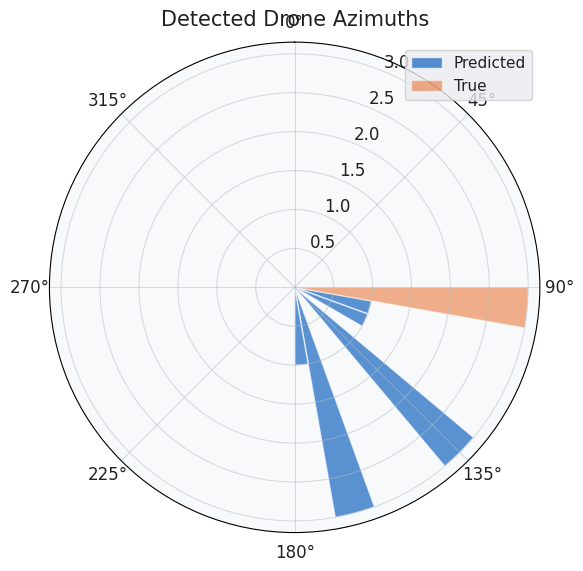

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/dunakeszi_pipeline_ready_B.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/dunakeszi_pipeline_ready_P.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_t63tr82n
📦 Loading test dataset from dunakeszi_pipeline_ready_P.zip …
✅ Extracted to /tmp/drone_test_t63tr82n
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (0 labelled, 3 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_P.zip
  Format: generic_triplet  |  Sessions: 3
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          YES  0.212  0.040   0.901    148.8        -       -   42.87       -  39.00
seg_031_circle_train          YES  0.809  0.723   0.904   -179.9        -       -   42.46       -  41.73
seg_032_circle_train          YES  0.228  0.080   0.821   -145.5        -       -   46.19       -  34.65

  Sessions evaluated : 3
  Detection rate     : 100.0%  (3/3)
  (no labe

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/dunakeszi_pipeline_ready_P_and_Q.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_73mkjezp
📦 Loading test dataset from dunakeszi_pipeline_ready_P_and_Q.zip …
✅ Extracted to /tmp/drone_test_73mkjezp
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (0 labelled, 3 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_P_and_Q.zip
  Format: generic_triplet  |  Sessions: 3
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          YES  0.212  0.040   0.901    148.8        -       -   42.87       -  39.00
seg_031_circle_train          YES  0.809  0.723   0.904   -179.9        -       -   42.46       -  41.73
seg_032_circle_train          YES  0.228  0.080   0.821   -145.5        -       -   46.19       -  34.65

  Sessions evaluated : 3
  Detection rate     : 100.0%  (3/3

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/dunakeszi_pipeline_ready_U_and_J.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_0tbu_btg
📦 Loading test dataset from dunakeszi_pipeline_ready_U_and_J.zip …
✅ Extracted to /tmp/drone_test_0tbu_btg
   Indexing sessions (format='generic_triplet') …
✅ Indexed 6 sessions  (0 labelled, 6 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_U_and_J.zip
  Format: generic_triplet  |  Sessions: 6
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_019_circle_train          no   0.000  0.000   0.000      nan        -       -     nan       -    nan
seg_020_circle_train          YES  0.346  0.247   0.742   -143.4        -       -   47.72       -  39.51
seg_021_figure8_train         YES  0.223  0.074   0.818   -168.2        -       -   45.08       -  34.45
seg_036_circle_test           YES  0.261  0.114   0.847   -15

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_005_hover_val_ch0.wav",
  "/content/seg_005_hover_val_ch1.wav",
  "/content/seg_005_hover_val_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_006_hover_val_ch0.wav",
  "/content/seg_006_hover_val_ch1.wav",
  "/content/seg_006_hover_val_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_007_transit_train_ch0.wav",
  "/content/seg_007_transit_train_ch1.wav",
  "/content/seg_007_transit_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_008_transit_train_ch0.wav",
  "/content/seg_008_transit_train_ch1.wav",
  "/content/seg_008_transit_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_010_diagonal_train_ch0.wav",
  "/content/seg_010_diagonal_train_ch1.wav",
  "/content/seg_010_diagonal_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(727650,)  rms=-20.97 dB  duration=33.0s
  Ch2: shape=(727650,)  rms=-19.64 dB  duration=33.0s
  Ch3: shape=(727650,)  rms=-20.65 dB  duration=33.0s

📊 Analysing seg_011_diagonal_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.766  cnn=0.674  rms=-27.5 dB  az=-164.2°
  Seg   2  🚁  conf=0.242  cnn=0.083  rms=-27.8 dB
  Seg   3  🚁  conf=0.524  cnn=0.434  rms=-27.0 dB  az=-155.3°
  Seg   4  🚁  conf=0.994  cnn=0.969  rms=-28.2 dB  az=-146.7°
  Seg   5  🚁  conf=0.243  cnn=0.082  rms=-25.5 dB
  Seg   6  🚁  conf=0.218  cnn=0.051  rms=-17.3 dB
  Seg   7  🚁  conf=0.163  cnn=0.024  rms=-13.8 dB
  Seg   8  🚁  conf=0.200  cnn=0.045  rms=-21.0 dB
  Seg   9  🚁  conf=0.270  cnn=0.129  rms=-25.4 dB
  Seg  10  🚁  conf=0.222  cnn=0.056  rms=-25.7 dB
  Seg  11  🚁  conf=0.264  cnn=0.107  rms=-24.2 dB

  📊 11/11 segments detected  |  1 confirmed track(s)  |  3 segments localised

🖼️  Generating analysis dashboard for seg_011_dia

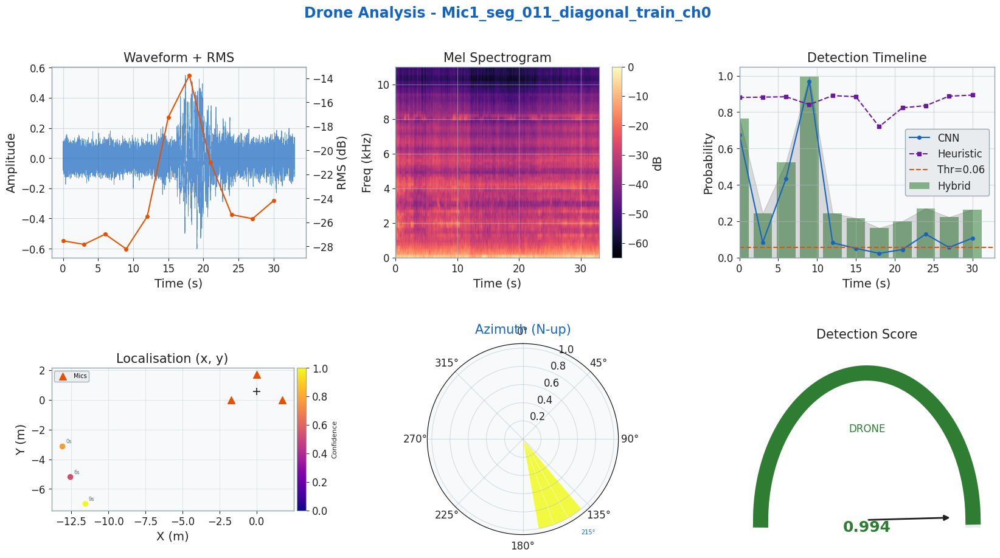

  📍 Plotting Kalman tracks for seg_011_diagonal_train_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_011_di.png


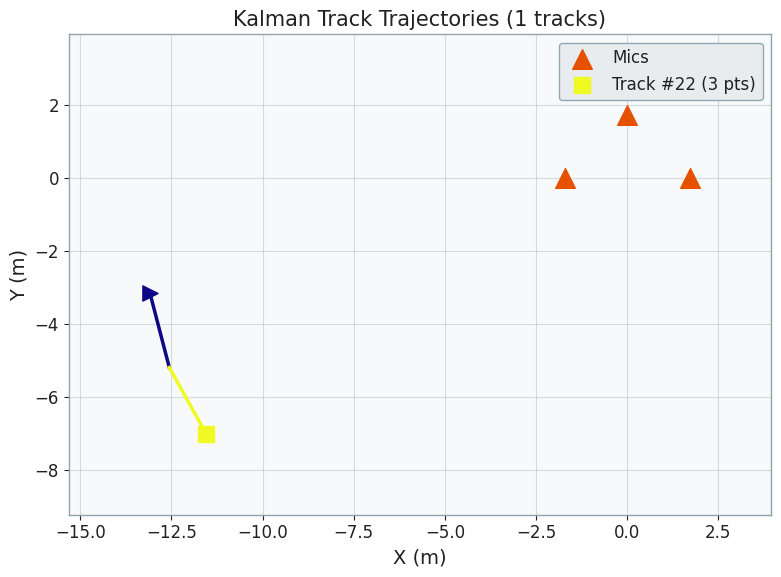


📊 Analysing seg_011_diagonal_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.766  cnn=0.674  rms=-25.5 dB  az=-168.7°
  Seg   2  🚁  conf=0.242  cnn=0.083  rms=-25.7 dB
  Seg   3  🚁  conf=0.524  cnn=0.434  rms=-25.1 dB  az=-163.4°
  Seg   4  🚁  conf=0.994  cnn=0.969  rms=-26.3 dB  az=-156.0°
  Seg   5  🚁  conf=0.243  cnn=0.082  rms=-23.4 dB
  Seg   6  🚁  conf=0.218  cnn=0.051  rms=-16.2 dB
  Seg   7  🚁  conf=0.163  cnn=0.024  rms=-12.6 dB
  Seg   8  🚁  conf=0.200  cnn=0.045  rms=-19.7 dB
  Seg   9  🚁  conf=0.270  cnn=0.129  rms=-23.6 dB
  Seg  10  🚁  conf=0.222  cnn=0.056  rms=-24.1 dB
  Seg  11  🚁  conf=0.264  cnn=0.107  rms=-22.6 dB

  📊 11/11 segments detected  |  1 confirmed track(s)  |  3 segments localised

🖼️  Generating analysis dashboard for seg_011_diagonal_train_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_011_diagonal_train_ch1_seg_011_di.png


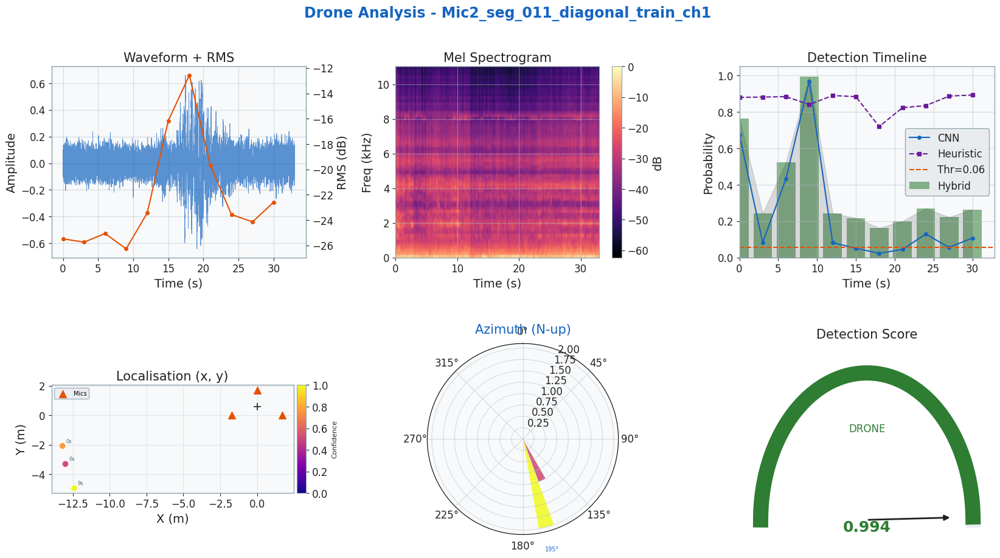

  📍 Plotting Kalman tracks for seg_011_diagonal_train_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_011_di.png


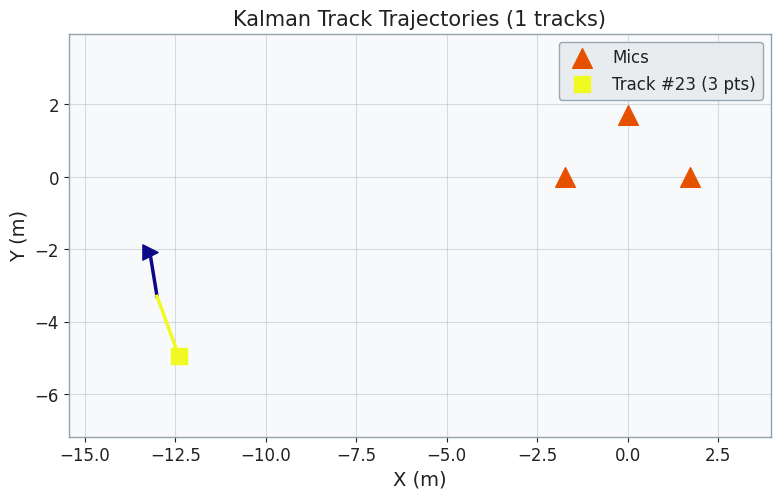


📊 Analysing seg_011_diagonal_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.766  cnn=0.674  rms=-27.4 dB  az=-163.8°
  Seg   2  🚁  conf=0.242  cnn=0.083  rms=-27.7 dB
  Seg   3  🚁  conf=0.524  cnn=0.434  rms=-26.8 dB  az=-152.4°
  Seg   4  🚁  conf=0.994  cnn=0.969  rms=-28.0 dB  az=-144.4°
  Seg   5  🚁  conf=0.243  cnn=0.082  rms=-25.3 dB
  Seg   6  🚁  conf=0.218  cnn=0.051  rms=-16.8 dB
  Seg   7  🚁  conf=0.163  cnn=0.024  rms=-13.5 dB
  Seg   8  🚁  conf=0.200  cnn=0.045  rms=-20.8 dB
  Seg   9  🚁  conf=0.270  cnn=0.129  rms=-24.9 dB
  Seg  10  🚁  conf=0.222  cnn=0.056  rms=-25.2 dB
  Seg  11  🚁  conf=0.264  cnn=0.107  rms=-23.9 dB

  📊 11/11 segments detected  |  1 confirmed track(s)  |  3 segments localised

🖼️  Generating analysis dashboard for seg_011_diagonal_train_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_011_diagonal_train_ch2_seg_011_di.png


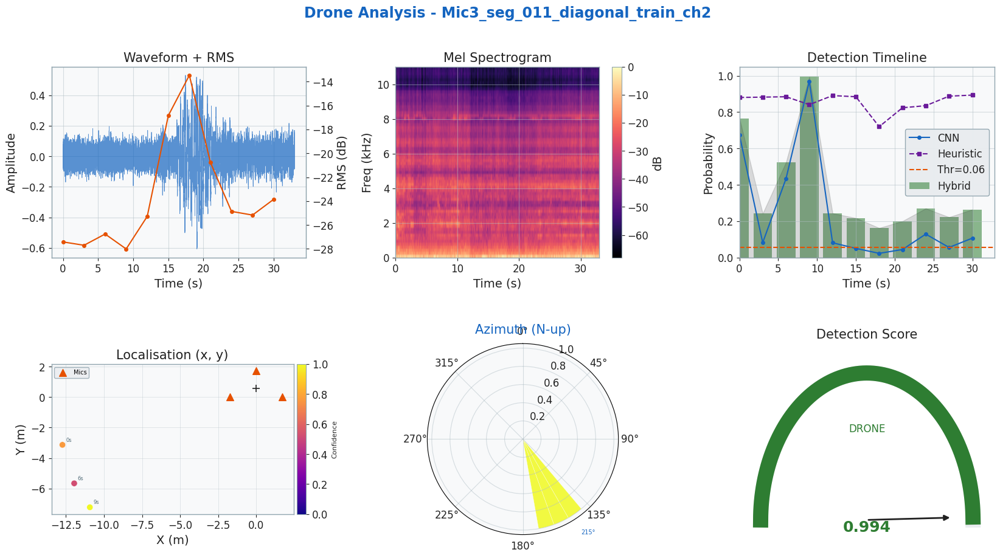

  📍 Plotting Kalman tracks for seg_011_diagonal_train_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_011_di.png


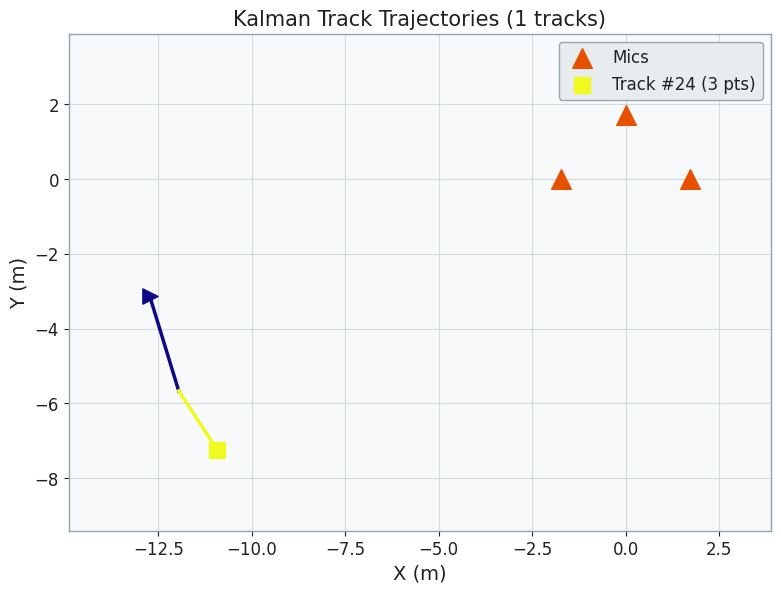


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

  ⚠  Multi-drone result suppressed: all 3 positions within 1.5 m — likely one drone.

🧭 Polar azimuth summary (9 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth_seg_011_di.png


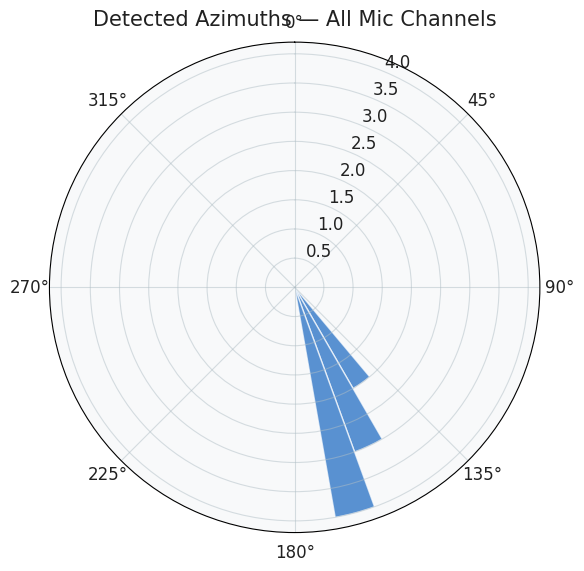


🗺️  Single-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_011_di.png


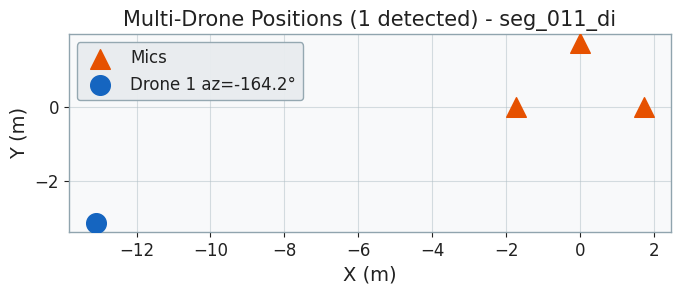


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_011_di.png


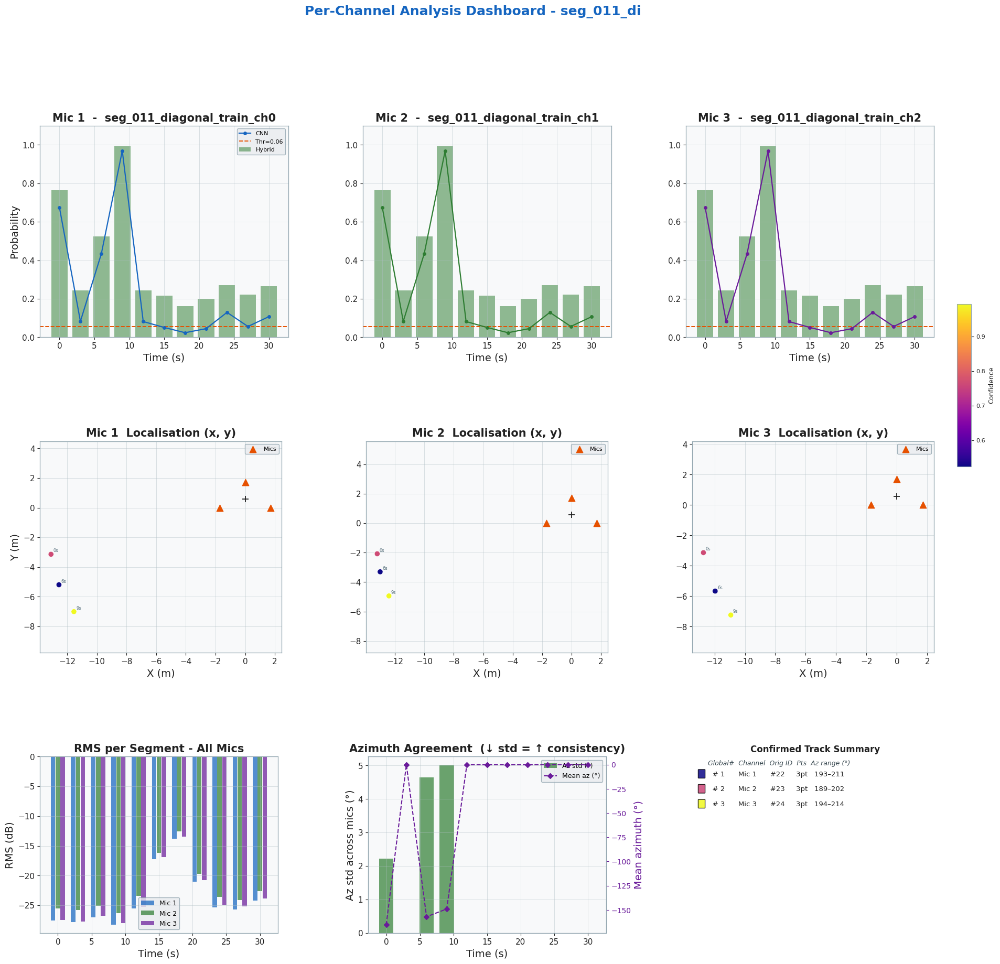

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_011_di.png


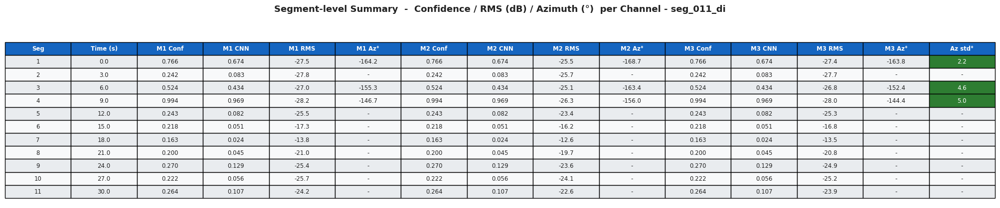


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_011_di.png


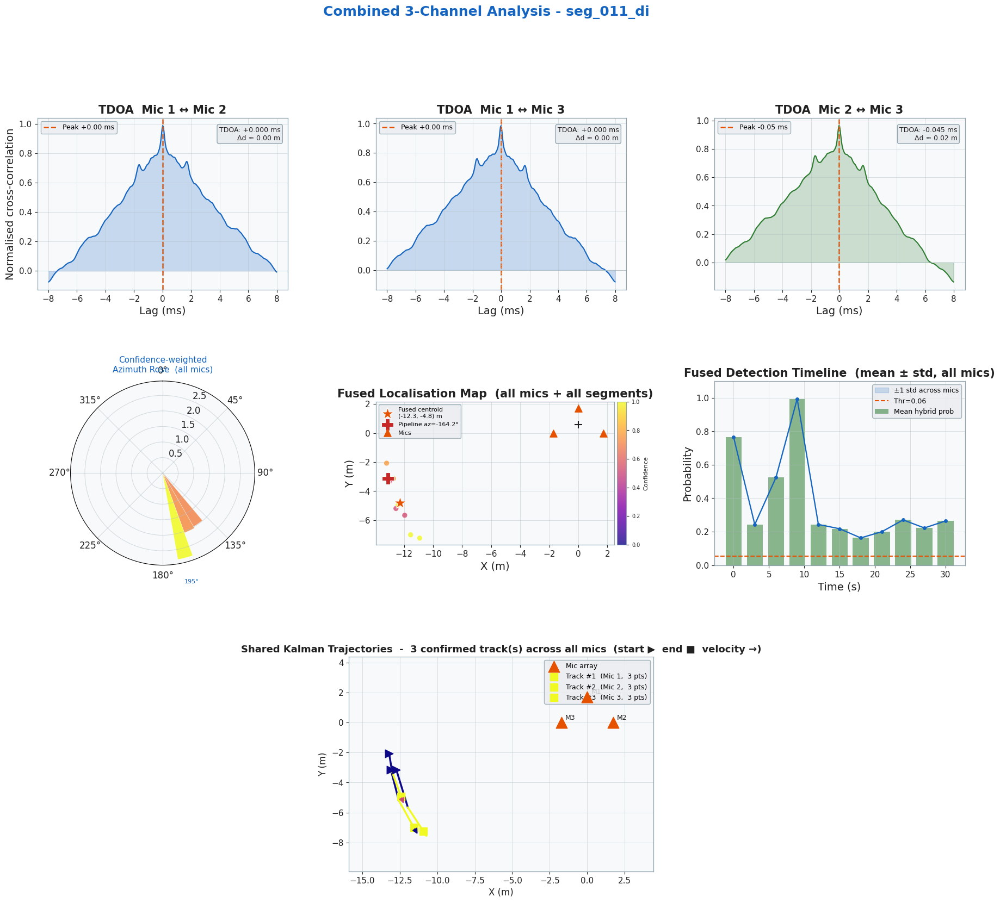


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_011_diagonal_train_ch0.wav
  Mic 2: /content/seg_011_diagonal_train_ch1.wav
  Mic 3: /content/seg_011_diagonal_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(727650,)  dtype=float32  min=-0.60183  max=0.54951  rms=-20.97 dB
  Ch2: shape=(727650,)  dtype=float32  min=-0.64261  max=0.66074  rms=-19.64 dB
  Ch3: shape=(727650,)  dtype=float32  min=-0.60740  max=0.53127  rms=-20.65 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.7656
  cnn_probability        : 0.6744
  heuristic_probability  : 0.8803
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-164.17°  dist=13.61m  ht=12.96m  xy=(-13.093, -3.140)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.7656
  cnn_probability        : 0.6744
  heuristic_probability  : 0.8803
  drones_found           : 3
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_011_diagonal_train_ch0.wav",
  "/content/seg_011_diagonal_train_ch1.wav",
  "/content/seg_011_diagonal_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(2072700,)  rms=-31.43 dB  duration=94.0s
  Ch2: shape=(2072700,)  rms=-29.81 dB  duration=94.0s
  Ch3: shape=(2072700,)  rms=-31.13 dB  duration=94.0s

📊 Analysing seg_019_circle_train_ch0.wav (channel 1)...
  Seg   1  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   2  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   3  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   4  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   5  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   6  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   7  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   8  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   9  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  10  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  11  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  12  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  13  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  14  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB


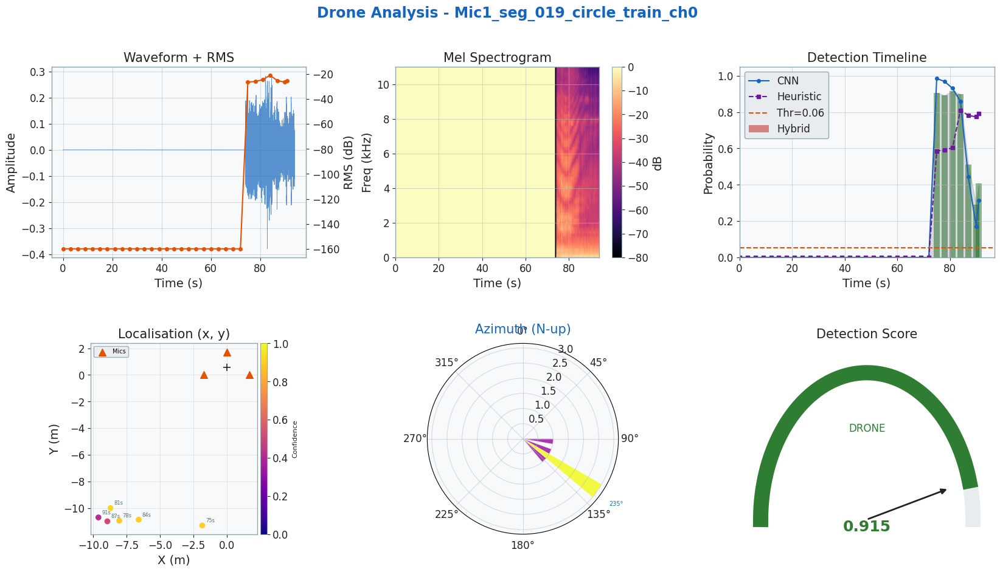

  📍 Plotting Kalman tracks for seg_019_circle_train_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_019_ci.png


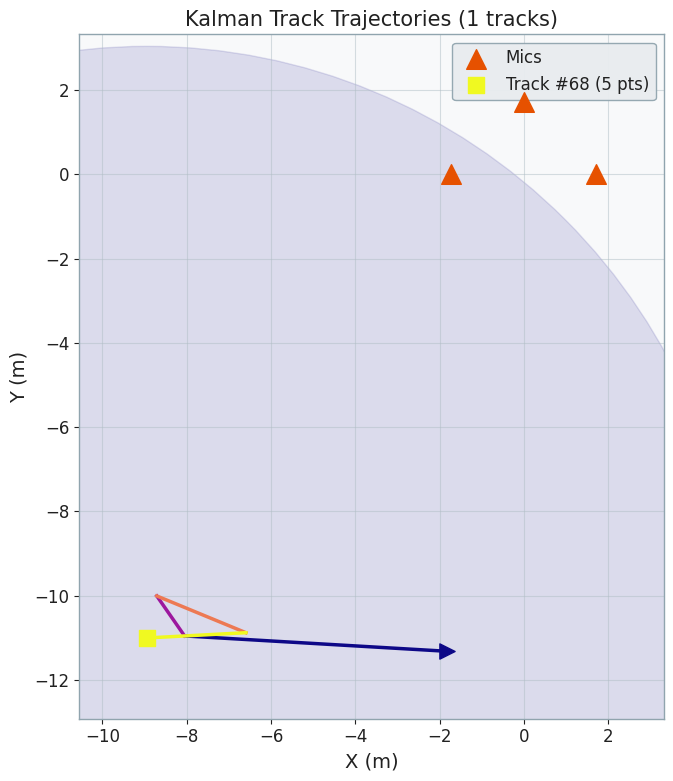


📊 Analysing seg_019_circle_train_ch1.wav (channel 2)...
  Seg   1  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   2  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   3  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   4  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   5  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   6  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   7  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   8  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   9  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  10  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  11  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  12  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  13  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  14  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  15  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  16  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  17  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  18  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  19  🌳  conf=0.000 

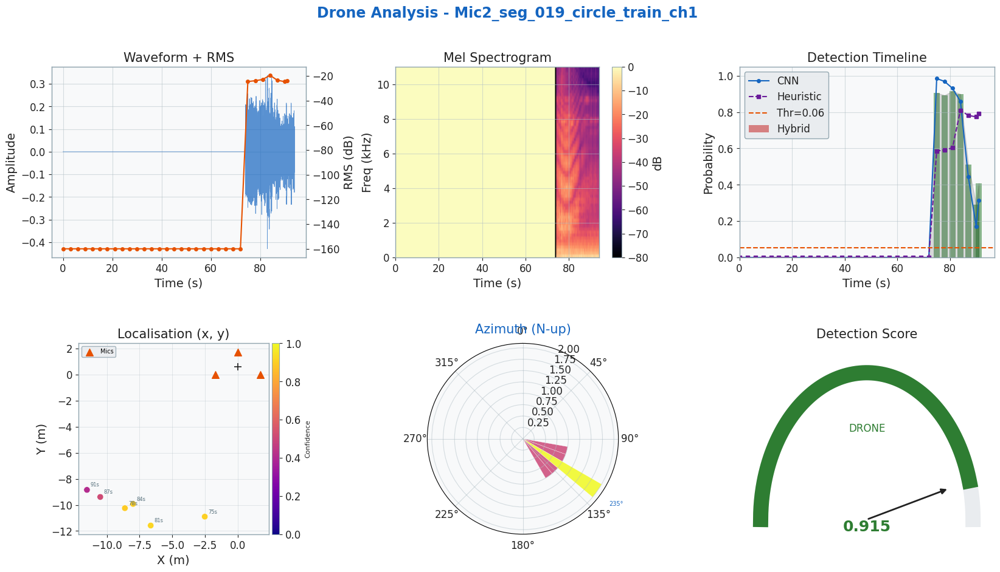

  📍 Plotting Kalman tracks for seg_019_circle_train_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_019_ci.png


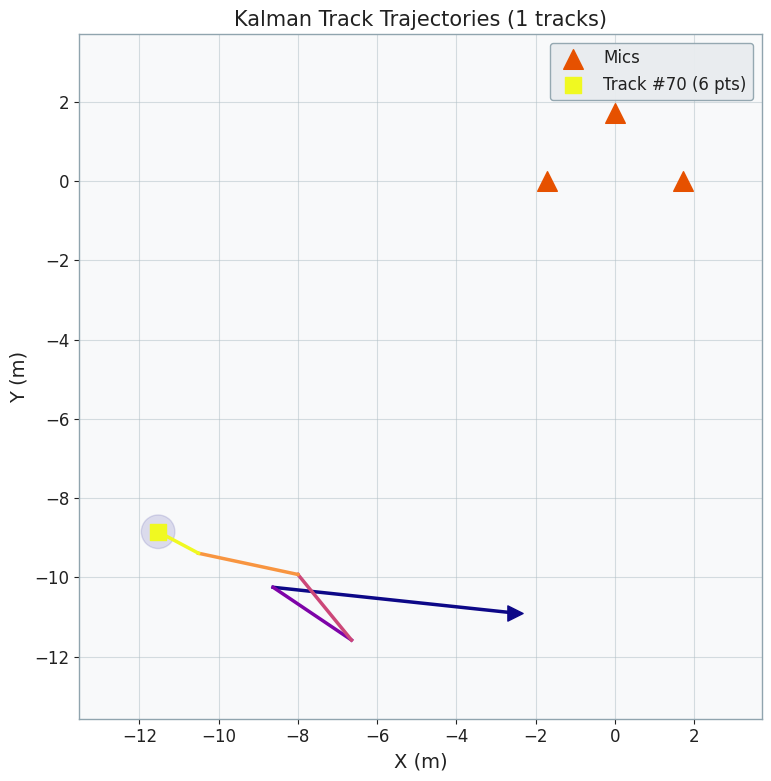


📊 Analysing seg_019_circle_train_ch2.wav (channel 3)...
  Seg   1  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   2  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   3  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   4  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   5  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   6  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   7  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   8  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg   9  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  10  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  11  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  12  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  13  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  14  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  15  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  16  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  17  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  18  🌳  conf=0.000  cnn=0.000  rms=-160.0 dB
  Seg  19  🌳  conf=0.000 

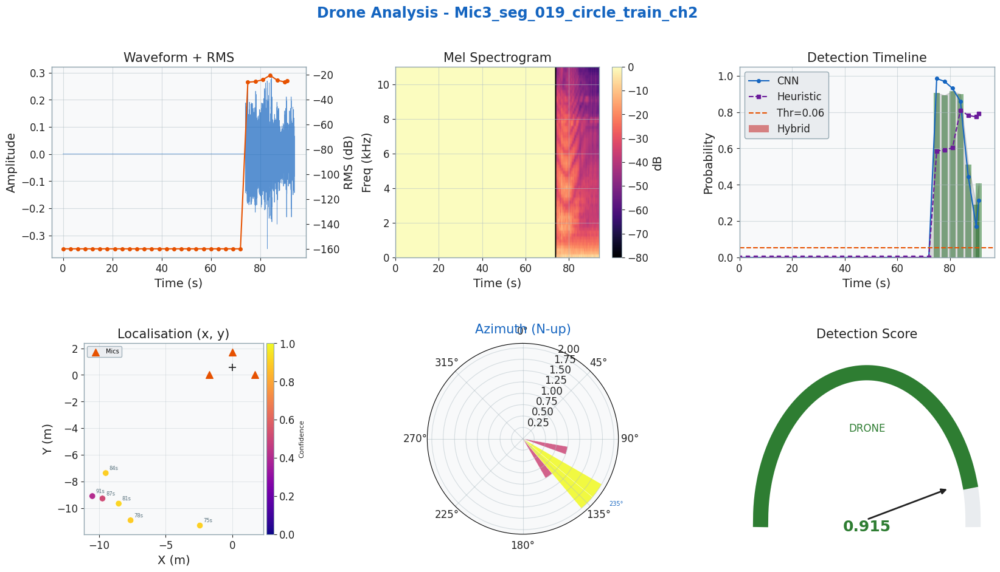

  📍 Plotting Kalman tracks for seg_019_circle_train_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_019_ci.png


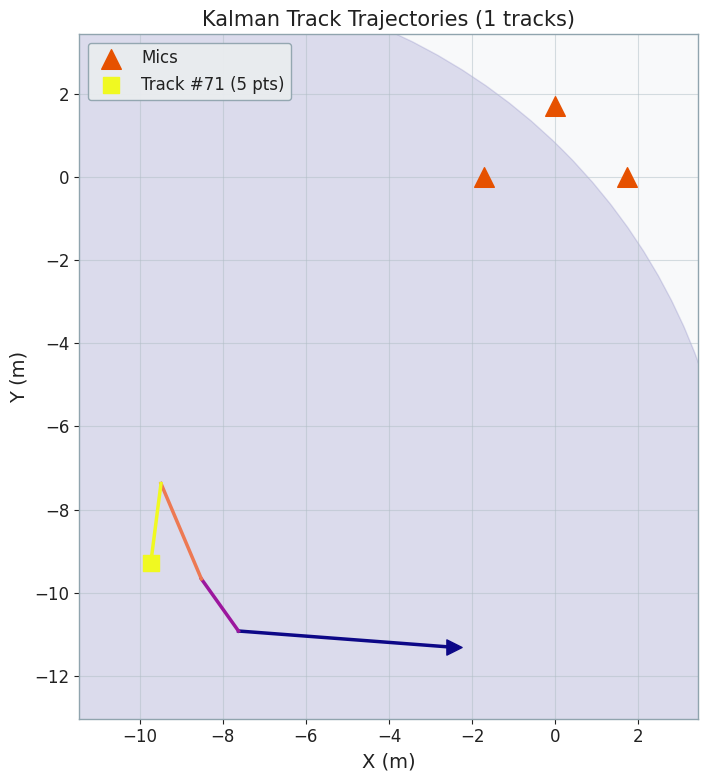


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🧭 Polar azimuth summary (18 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth_seg_019_ci.png


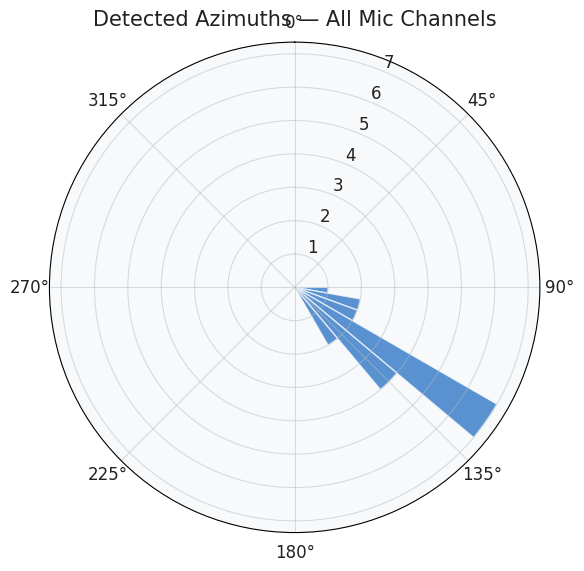


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_019_ci.png


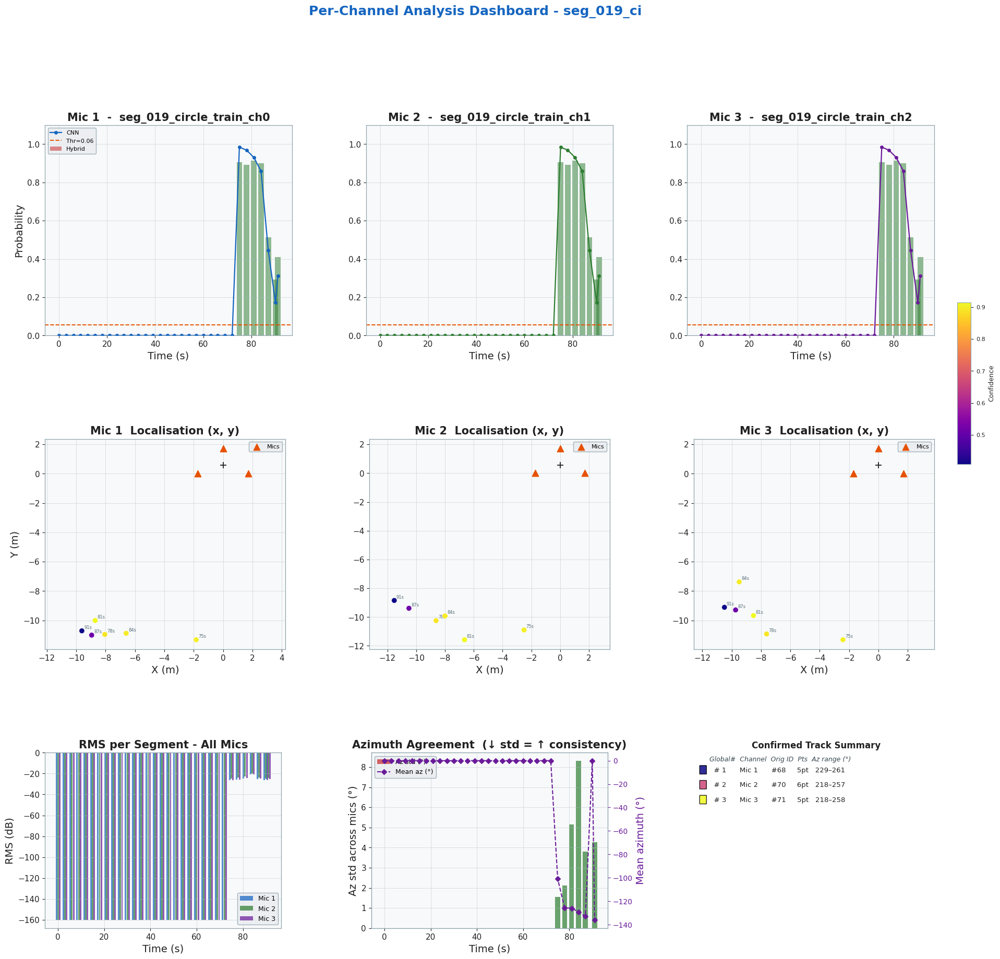

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_019_ci.png


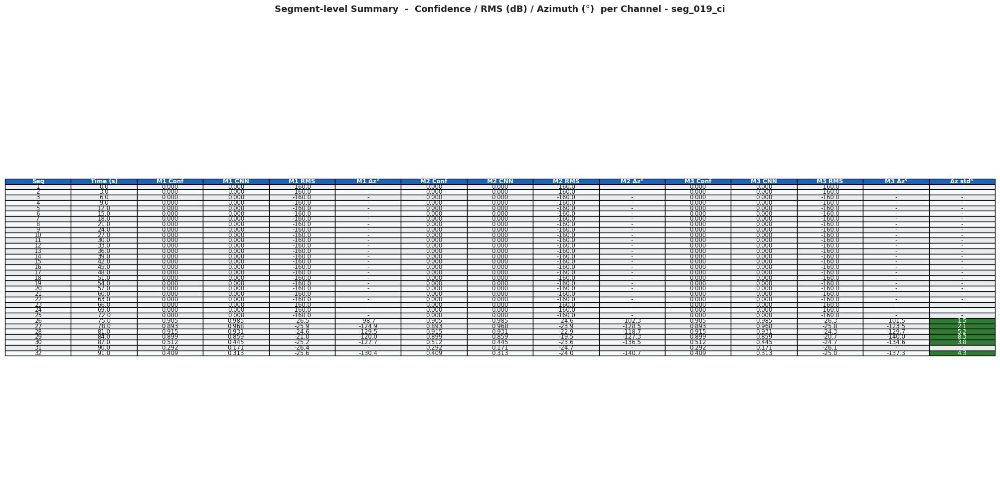


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_019_ci.png


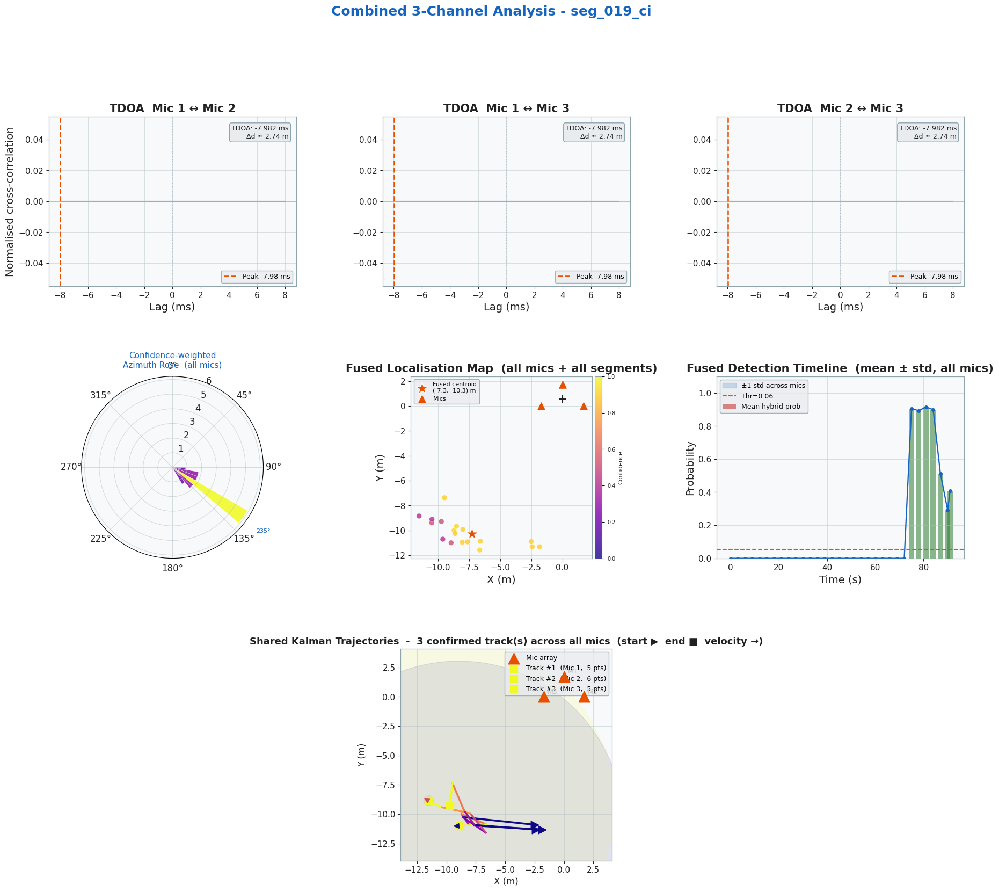


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_019_circle_train_ch0.wav
  Mic 2: /content/seg_019_circle_train_ch1.wav
  Mic 3: /content/seg_019_circle_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(2072700,)  dtype=float32  min=-0.37850  max=0.28505  rms=-31.43 dB
  Ch2: shape=(2072700,)  dtype=float32  min=-0.42869  max=0.33782  rms=-29.81 dB
  Ch3: shape=(2072700,)  dtype=float32  min=-0.34942  max=0.29028  rms=-31.13 dB

🚁 Single-drone pipeline
  detected               : False
  probability            : 0.0000
  cnn_probability        : 0.0000
  heuristic_probability  : 0.0000
  drones_found           : 0
  tracks_returned        : 0

🚁🚁 Multi-drone pipeline
  detected               : False
  probability            : 0.0000
  cnn_probability        : 0.0000
  heuristic_probability  : 0.0000
  drones_found           : 0
  tracks_returned        : 0


In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_019_circle_train_ch0.wav",
  "/content/seg_019_circle_train_ch1.wav",
  "/content/seg_019_circle_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_020_circle_train_ch0.wav",
  "/content/seg_020_circle_train_ch1.wav",
  "/content/seg_020_circle_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(1389150,)  rms=-28.74 dB  duration=63.0s
  Ch2: shape=(1389150,)  rms=-26.47 dB  duration=63.0s
  Ch3: shape=(1389150,)  rms=-28.57 dB  duration=63.0s

📊 Analysing seg_021_figure8_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.223  cnn=0.074  rms=-29.4 dB
  Seg   2  🚁  conf=0.211  cnn=0.064  rms=-29.7 dB
  Seg   3  🚁  conf=0.206  cnn=0.054  rms=-29.0 dB
  Seg   4  🚁  conf=0.235  cnn=0.102  rms=-29.7 dB
  Seg   5  🚁  conf=0.191  cnn=0.054  rms=-29.0 dB
  Seg   6  🚁  conf=0.247  cnn=0.103  rms=-27.9 dB
  Seg   7  🚁  conf=0.220  cnn=0.080  rms=-29.2 dB
  Seg   8  🚁  conf=0.234  cnn=0.103  rms=-28.5 dB
  Seg   9  🚁  conf=0.355  cnn=0.236  rms=-27.4 dB
  Seg  10  🚁  conf=0.240  cnn=0.103  rms=-28.0 dB
  Seg  11  🚁  conf=0.239  cnn=0.090  rms=-27.9 dB
  Seg  12  🚁  conf=0.249  cnn=0.106  rms=-28.2 dB
  Seg  13  🚁  conf=0.206  cnn=0.073  rms=-28.1 dB
  Seg  14  🚁  conf=0.213  cnn=0.079  rms=-28.4 dB
  Seg  15  🚁 

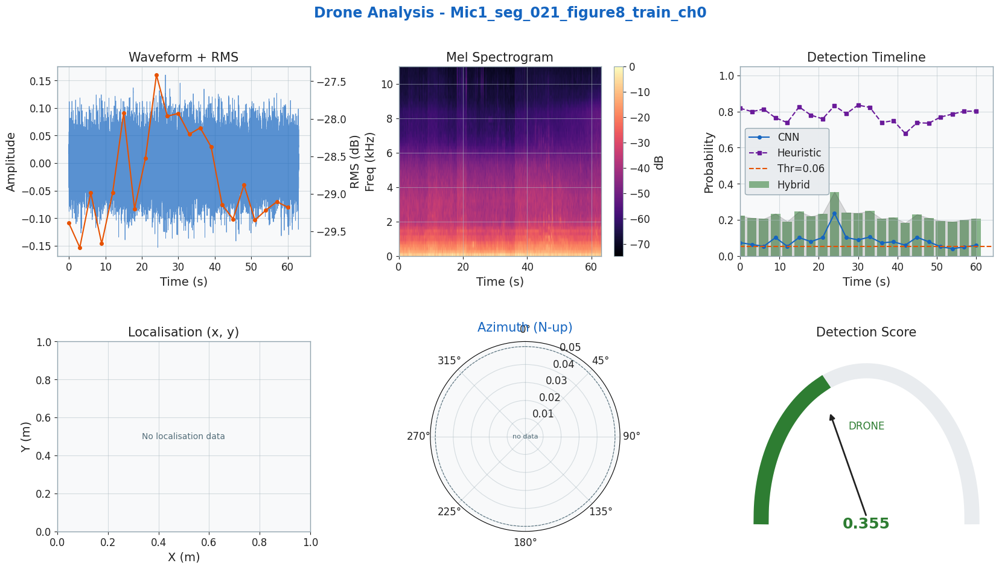


📊 Analysing seg_021_figure8_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.223  cnn=0.074  rms=-27.1 dB
  Seg   2  🚁  conf=0.211  cnn=0.064  rms=-27.4 dB
  Seg   3  🚁  conf=0.206  cnn=0.054  rms=-26.7 dB
  Seg   4  🚁  conf=0.235  cnn=0.102  rms=-27.4 dB
  Seg   5  🚁  conf=0.191  cnn=0.054  rms=-26.7 dB
  Seg   6  🚁  conf=0.247  cnn=0.103  rms=-25.6 dB
  Seg   7  🚁  conf=0.220  cnn=0.080  rms=-26.9 dB
  Seg   8  🚁  conf=0.234  cnn=0.103  rms=-26.2 dB
  Seg   9  🚁  conf=0.355  cnn=0.236  rms=-25.3 dB
  Seg  10  🚁  conf=0.240  cnn=0.103  rms=-25.7 dB
  Seg  11  🚁  conf=0.239  cnn=0.090  rms=-25.7 dB
  Seg  12  🚁  conf=0.249  cnn=0.106  rms=-25.9 dB
  Seg  13  🚁  conf=0.206  cnn=0.073  rms=-25.8 dB
  Seg  14  🚁  conf=0.213  cnn=0.079  rms=-26.1 dB
  Seg  15  🚁  conf=0.184  cnn=0.061  rms=-26.9 dB
  Seg  16  🚁  conf=0.231  cnn=0.104  rms=-27.1 dB
  Seg  17  🚁  conf=0.210  cnn=0.079  rms=-26.6 dB
  Seg  18  🚁  conf=0.195  cnn=0.052  rms=-27.1 dB
  Seg  19  🚁  conf=0.190  cnn=0.041  rms=-

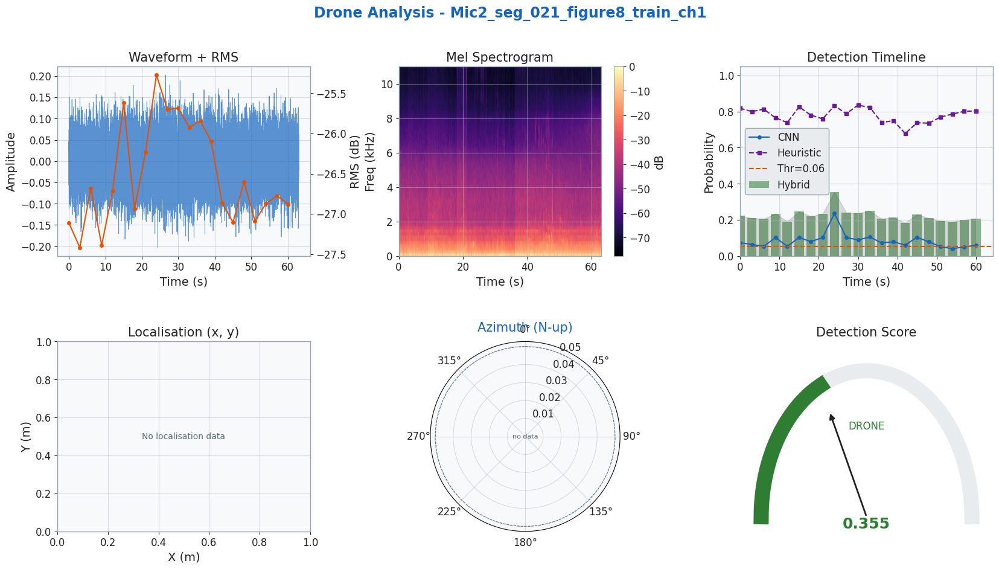


📊 Analysing seg_021_figure8_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.223  cnn=0.074  rms=-29.2 dB
  Seg   2  🚁  conf=0.211  cnn=0.064  rms=-29.6 dB
  Seg   3  🚁  conf=0.206  cnn=0.054  rms=-28.8 dB
  Seg   4  🚁  conf=0.235  cnn=0.102  rms=-29.5 dB
  Seg   5  🚁  conf=0.191  cnn=0.054  rms=-28.8 dB
  Seg   6  🚁  conf=0.247  cnn=0.103  rms=-27.8 dB
  Seg   7  🚁  conf=0.220  cnn=0.080  rms=-29.0 dB
  Seg   8  🚁  conf=0.234  cnn=0.103  rms=-28.4 dB
  Seg   9  🚁  conf=0.355  cnn=0.236  rms=-27.1 dB
  Seg  10  🚁  conf=0.240  cnn=0.103  rms=-27.8 dB
  Seg  11  🚁  conf=0.239  cnn=0.090  rms=-27.8 dB
  Seg  12  🚁  conf=0.249  cnn=0.106  rms=-28.0 dB
  Seg  13  🚁  conf=0.206  cnn=0.073  rms=-27.9 dB
  Seg  14  🚁  conf=0.213  cnn=0.079  rms=-28.2 dB
  Seg  15  🚁  conf=0.184  cnn=0.061  rms=-29.0 dB
  Seg  16  🚁  conf=0.231  cnn=0.104  rms=-29.2 dB
  Seg  17  🚁  conf=0.210  cnn=0.079  rms=-28.7 dB
  Seg  18  🚁  conf=0.195  cnn=0.052  rms=-29.2 dB
  Seg  19  🚁  conf=0.190  cnn=0.041  rms=-

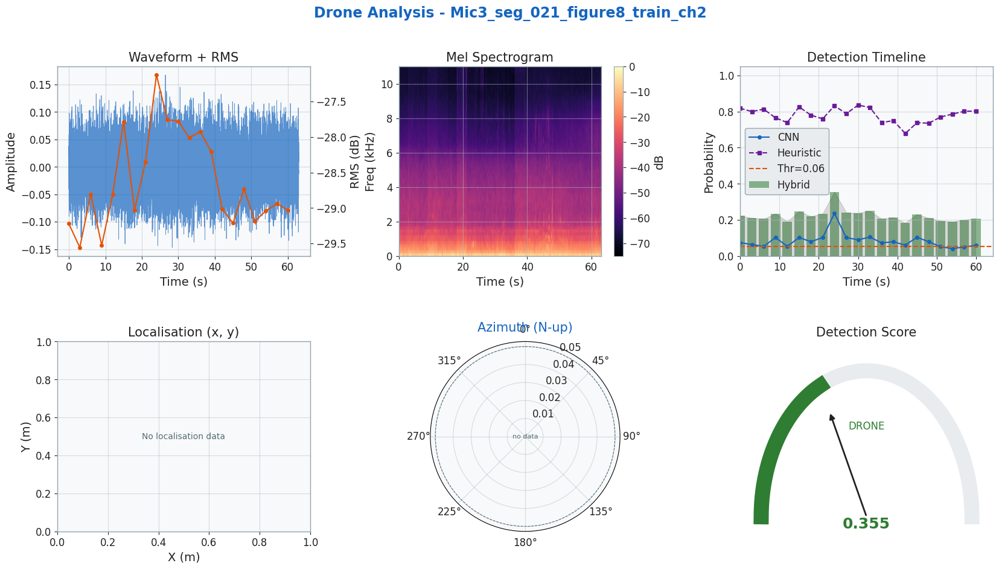


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_021_fi.png


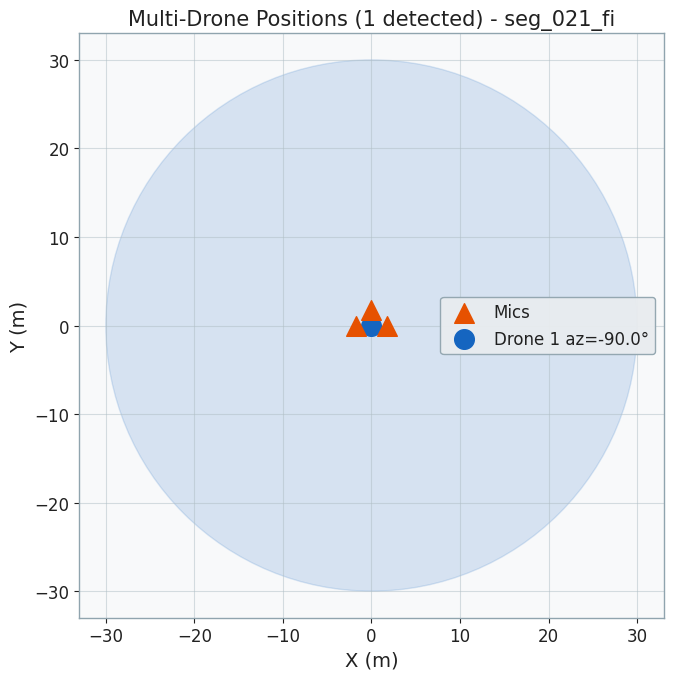


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_021_fi.png


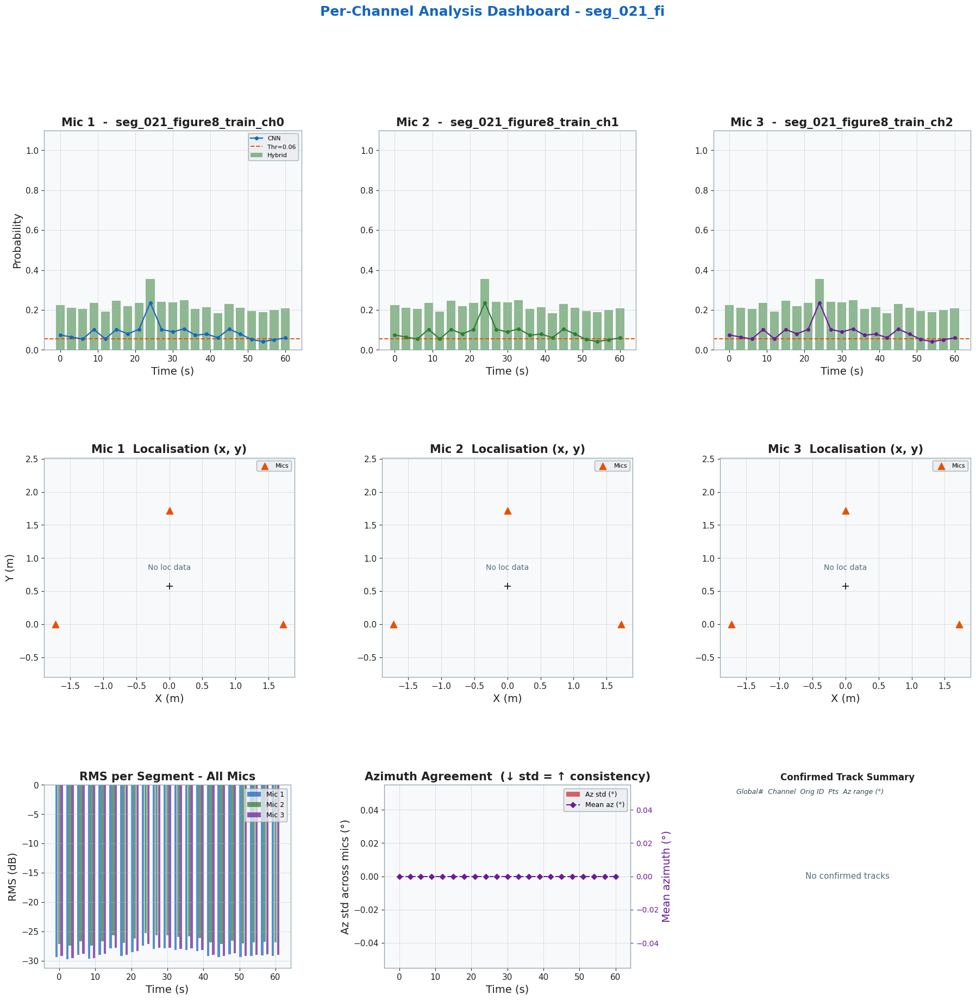

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_021_fi.png


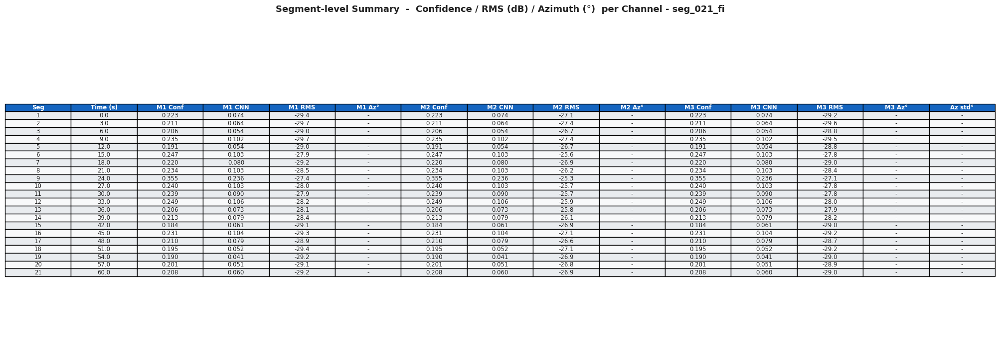


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_021_fi.png


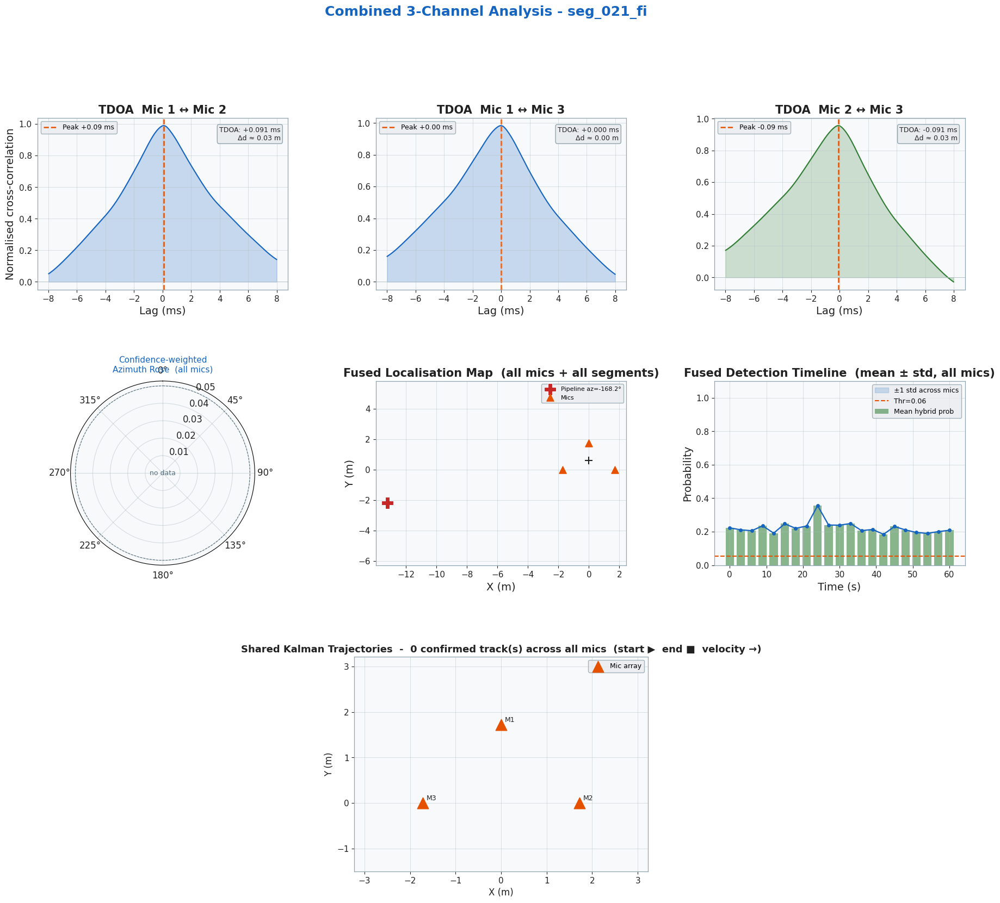


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_021_figure8_train_ch0.wav
  Mic 2: /content/seg_021_figure8_train_ch1.wav
  Mic 3: /content/seg_021_figure8_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(1389150,)  dtype=float32  min=-0.15311  max=0.16017  rms=-28.74 dB
  Ch2: shape=(1389150,)  dtype=float32  min=-0.20295  max=0.20286  rms=-26.47 dB
  Ch3: shape=(1389150,)  dtype=float32  min=-0.14686  max=0.16761  rms=-28.57 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.2231
  cnn_probability        : 0.0744
  heuristic_probability  : 0.8178
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-168.18°  dist=13.52m  ht=10.33m  xy=(-13.238, -2.196)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.2231
  cnn_probability        : 0.0744
  heuristic_probability  : 0.8178
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_021_figure8_train_ch0.wav",
  "/content/seg_021_figure8_train_ch1.wav",
  "/content/seg_021_figure8_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(176400,)  rms=-20.93 dB  duration=8.0s
  Ch2: shape=(176400,)  rms=-18.56 dB  duration=8.0s
  Ch3: shape=(176400,)  rms=-21.34 dB  duration=8.0s

📊 Analysing seg_030_circle_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.212  cnn=0.040  rms=-21.6 dB
  Seg   2  🚁  conf=0.200  cnn=0.022  rms=-20.4 dB
  Seg   3  🚁  conf=0.199  cnn=0.022  rms=-21.2 dB

  📊 3/3 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_030_circle_train_ch0.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_030_circle_train_ch0_seg_030_ci.png


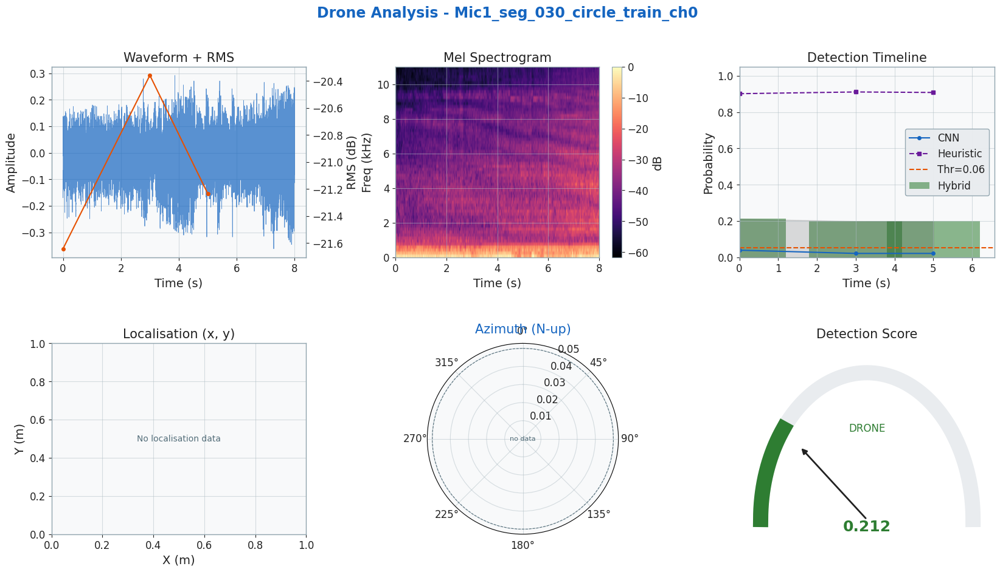


📊 Analysing seg_030_circle_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.212  cnn=0.040  rms=-19.3 dB
  Seg   2  🚁  conf=0.200  cnn=0.022  rms=-18.0 dB
  Seg   3  🚁  conf=0.199  cnn=0.022  rms=-18.9 dB

  📊 3/3 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_030_circle_train_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_030_circle_train_ch1_seg_030_ci.png


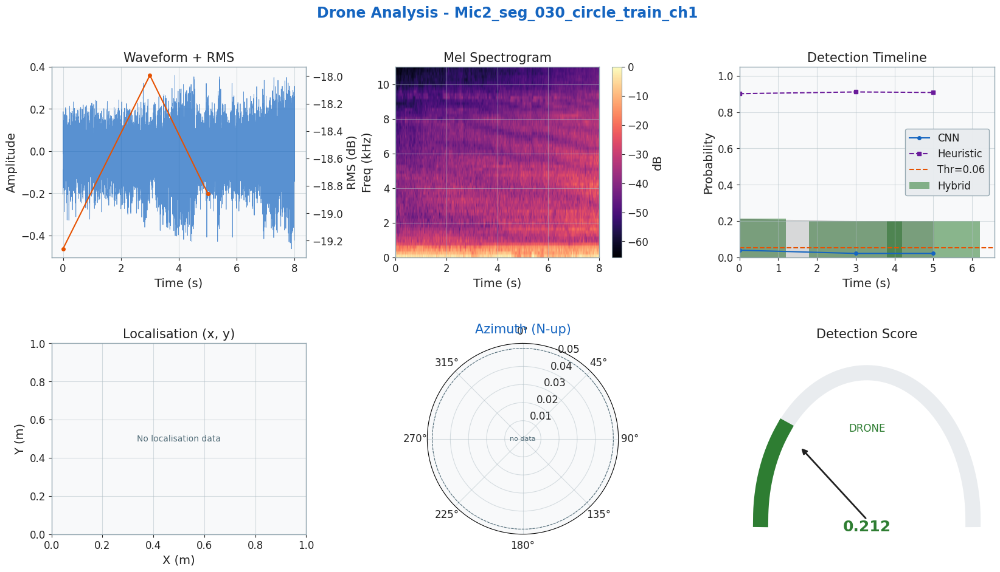


📊 Analysing seg_030_circle_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.212  cnn=0.040  rms=-22.0 dB
  Seg   2  🚁  conf=0.200  cnn=0.022  rms=-20.8 dB
  Seg   3  🚁  conf=0.199  cnn=0.022  rms=-21.7 dB

  📊 3/3 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_030_circle_train_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_030_circle_train_ch2_seg_030_ci.png


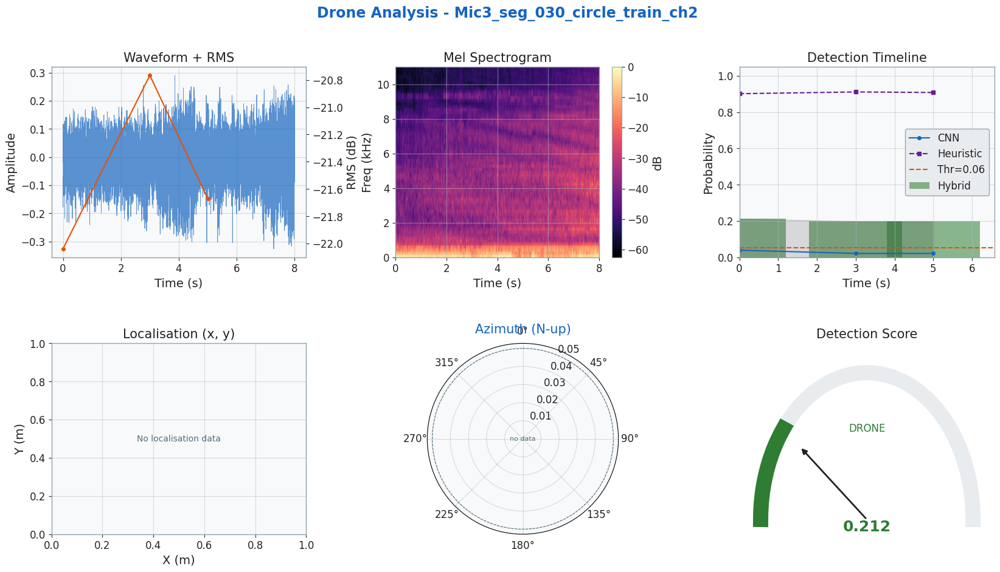


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_030_ci.png


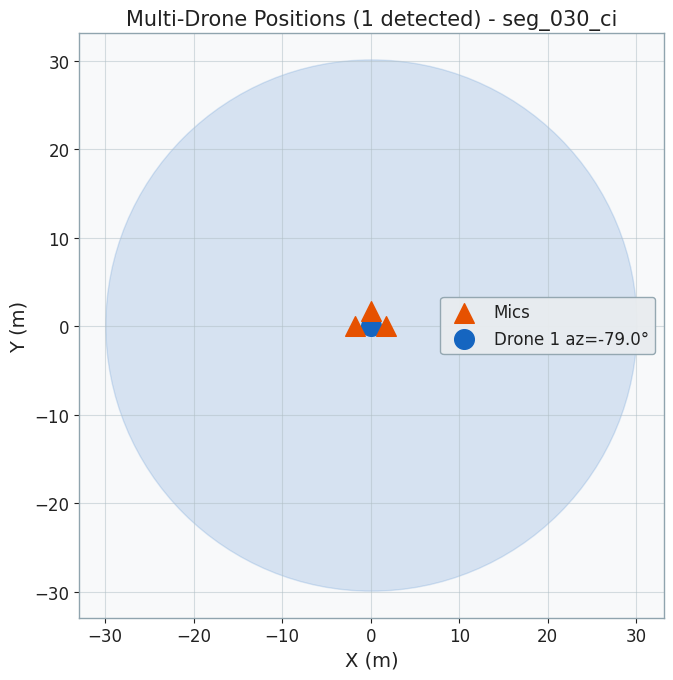


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_030_ci.png


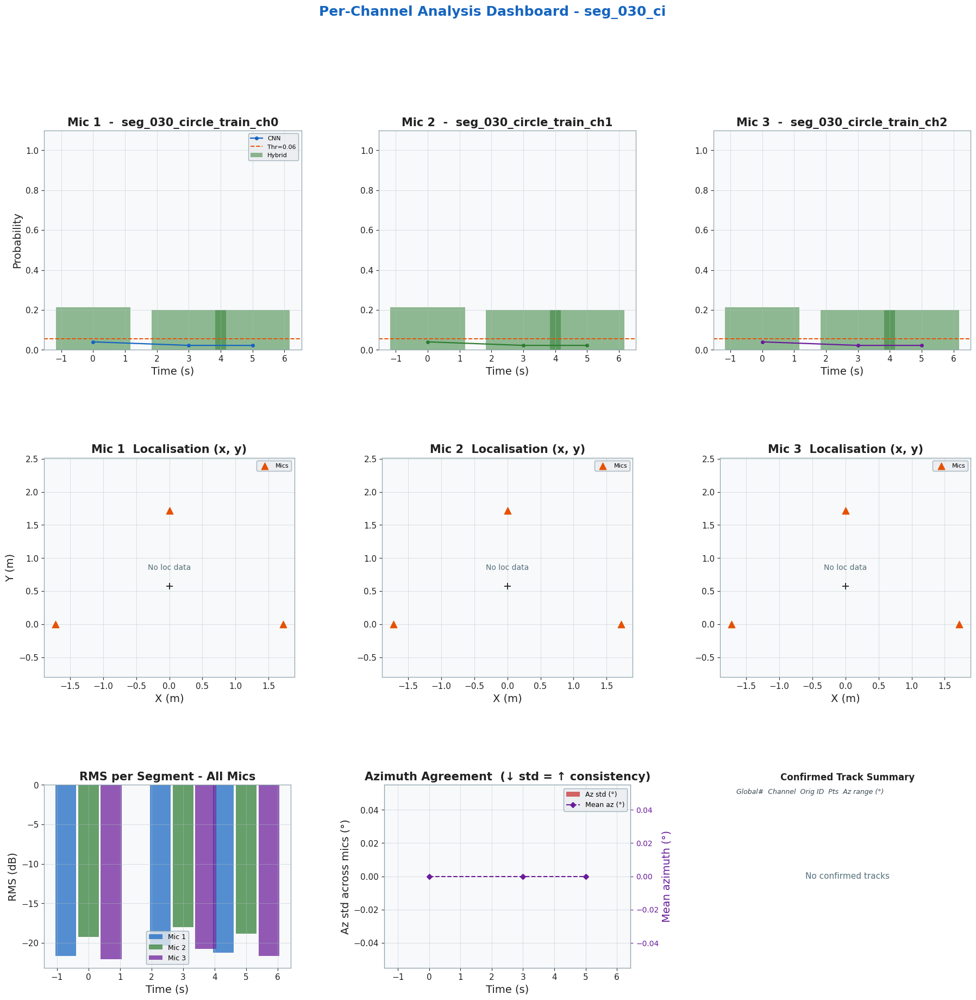

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_030_ci.png


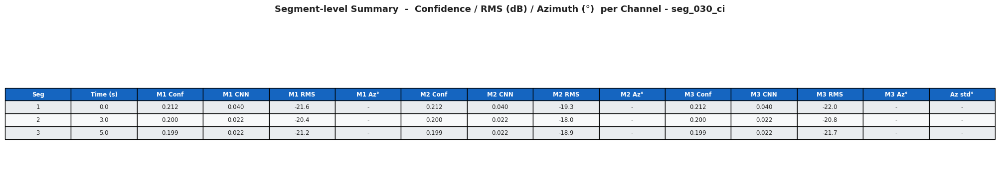


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_030_ci.png


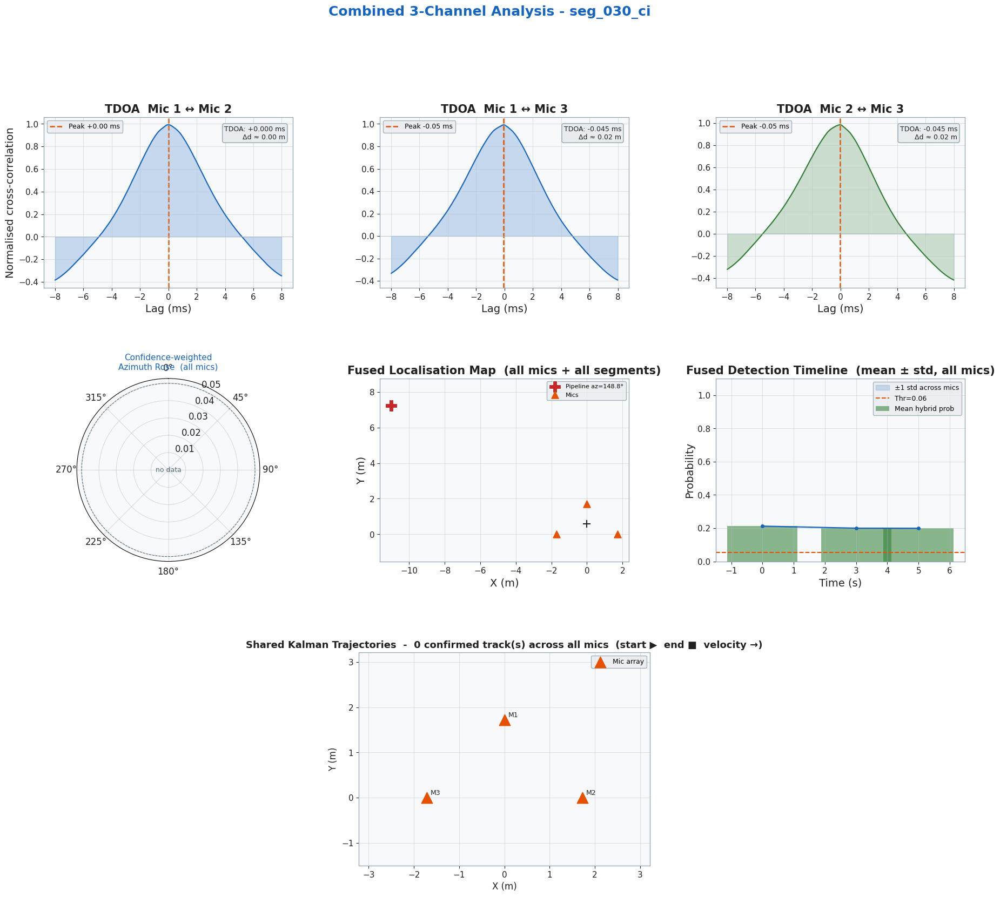


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_030_circle_train_ch0.wav
  Mic 2: /content/seg_030_circle_train_ch1.wav
  Mic 3: /content/seg_030_circle_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(176400,)  dtype=float32  min=-0.36204  max=0.29280  rms=-20.93 dB
  Ch2: shape=(176400,)  dtype=float32  min=-0.46263  max=0.35956  rms=-18.56 dB
  Ch3: shape=(176400,)  dtype=float32  min=-0.32633  max=0.29100  rms=-21.34 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.2122
  cnn_probability        : 0.0400
  heuristic_probability  : 0.9011
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=148.83°  dist=12.86m  ht=11.70m  xy=(-11.004, 7.230)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.2122
  cnn_probability        : 0.0400
  heuristic_probability  : 0.9011
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-78.98°  dist=0.49m  xy=(0

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_030_circle_train_ch0.wav",
  "/content/seg_030_circle_train_ch1.wav",
  "/content/seg_030_circle_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(1036350,)  rms=-18.81 dB  duration=47.0s
  Ch2: shape=(1036350,)  rms=-16.84 dB  duration=47.0s
  Ch3: shape=(1036350,)  rms=-19.10 dB  duration=47.0s

📊 Analysing seg_031_circle_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.809  cnn=0.723  rms=-17.0 dB  az=-179.9°
  Seg   2  🚁  conf=0.386  cnn=0.257  rms=-16.8 dB
  Seg   3  🚁  conf=0.516  cnn=0.424  rms=-16.6 dB  az=-116.9°
  Seg   4  🚁  conf=0.355  cnn=0.218  rms=-15.4 dB
  Seg   5  🚁  conf=0.961  cnn=0.904  rms=-15.9 dB  az=-126.1°
  Seg   6  🚁  conf=1.000  cnn=0.982  rms=-18.0 dB  az=-114.5°
  Seg   7  🚁  conf=0.928  cnn=0.886  rms=-22.1 dB  az=-132.4°
  Seg   8  🚁  conf=0.242  cnn=0.120  rms=-17.0 dB
  Seg   9  🚁  conf=0.198  cnn=0.056  rms=-20.4 dB
  Seg  10  🚁  conf=0.185  cnn=0.035  rms=-19.6 dB
  Seg  11  🚁  conf=0.223  cnn=0.067  rms=-22.3 dB
  Seg  12  🚁  conf=0.199  cnn=0.048  rms=-21.3 dB
  Seg  13  🚁  conf=0.236  cnn=0.091  rms=-23.1 dB
  Se

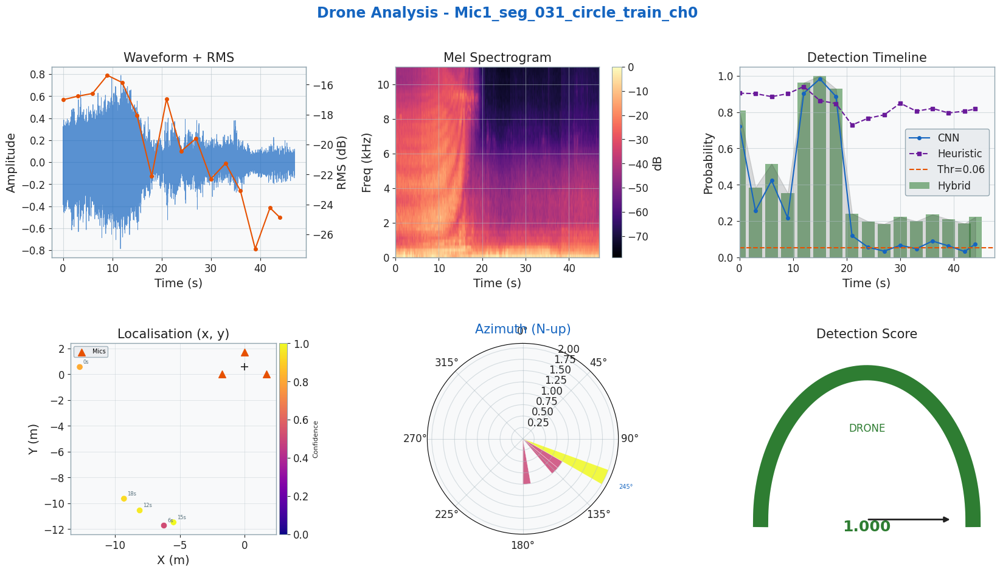

  📍 Plotting Kalman tracks for seg_031_circle_train_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_031_ci.png


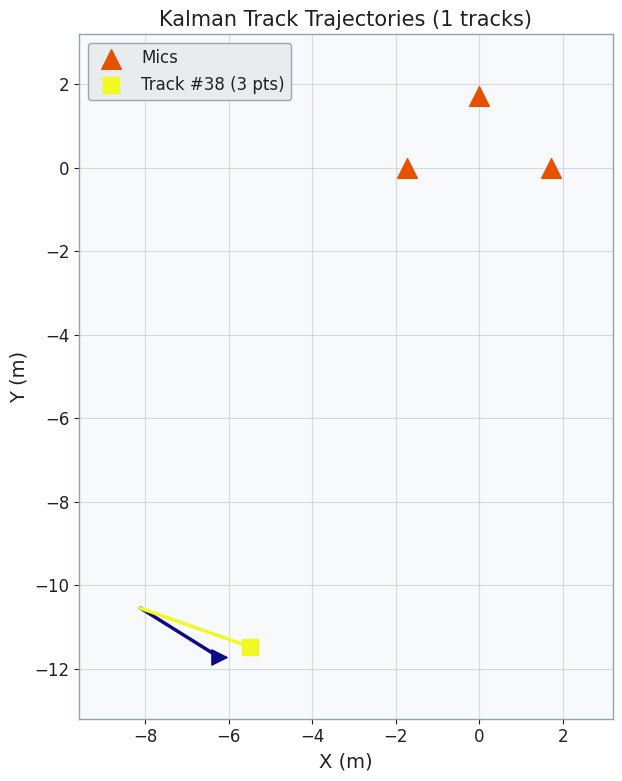


📊 Analysing seg_031_circle_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.809  cnn=0.723  rms=-14.7 dB  az=176.2°
  Seg   2  🚁  conf=0.386  cnn=0.257  rms=-14.6 dB
  Seg   3  🚁  conf=0.516  cnn=0.424  rms=-14.5 dB  az=-123.2°
  Seg   4  🚁  conf=0.355  cnn=0.218  rms=-13.3 dB
  Seg   5  🚁  conf=0.961  cnn=0.904  rms=-13.8 dB  az=-120.9°
  Seg   6  🚁  conf=1.000  cnn=0.982  rms=-16.3 dB  az=-113.0°
  Seg   7  🚁  conf=0.928  cnn=0.886  rms=-20.2 dB  az=-137.2°
  Seg   8  🚁  conf=0.242  cnn=0.120  rms=-15.4 dB
  Seg   9  🚁  conf=0.198  cnn=0.056  rms=-18.4 dB
  Seg  10  🚁  conf=0.185  cnn=0.035  rms=-18.0 dB
  Seg  11  🚁  conf=0.223  cnn=0.067  rms=-20.2 dB
  Seg  12  🚁  conf=0.199  cnn=0.048  rms=-19.4 dB
  Seg  13  🚁  conf=0.236  cnn=0.091  rms=-21.2 dB
  Seg  14  🚁  conf=0.210  cnn=0.064  rms=-24.7 dB
  Seg  15  🚁  conf=0.187  cnn=0.033  rms=-22.5 dB
  Seg  16  🚁  conf=0.223  cnn=0.074  rms=-23.1 dB

  📊 16/16 segments detected  |  1 confirmed track(s)  |  5 segments localised

🖼️  

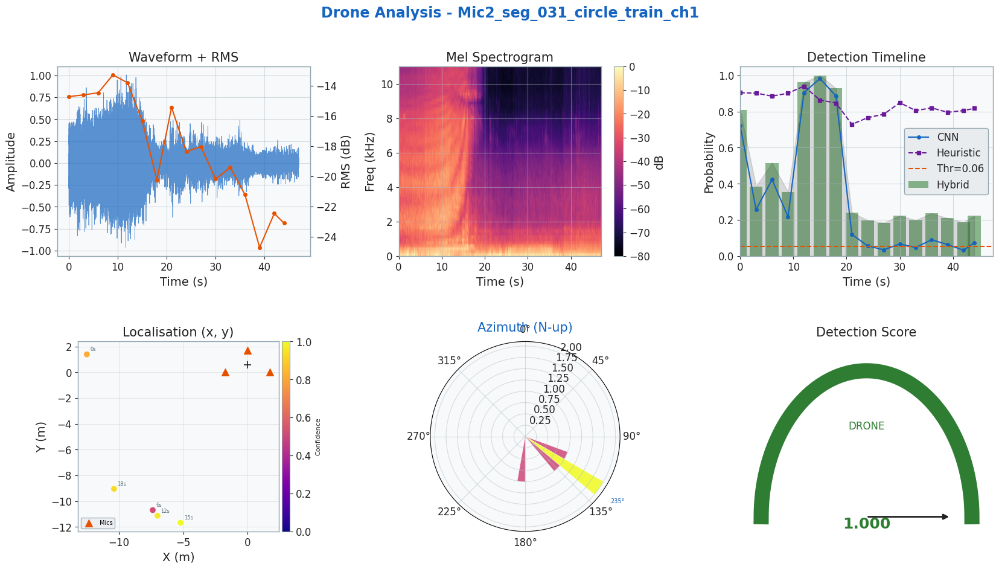

  📍 Plotting Kalman tracks for seg_031_circle_train_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_031_ci.png


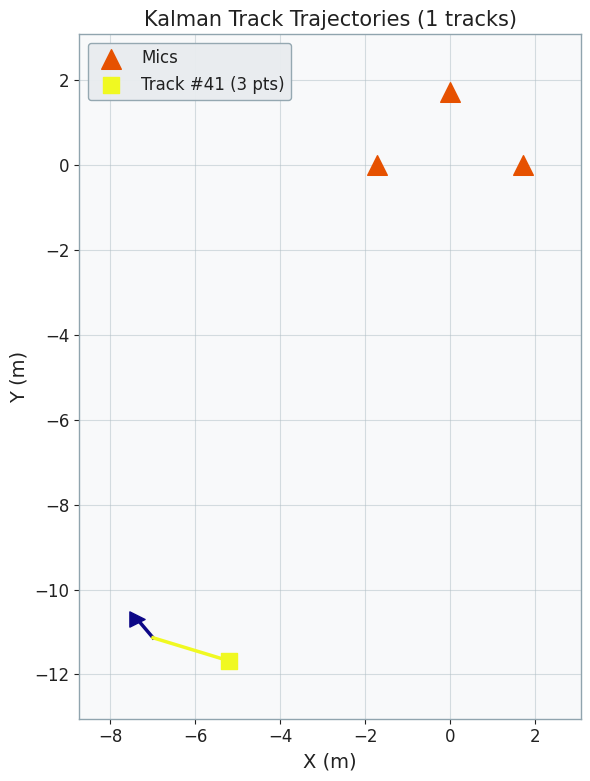


📊 Analysing seg_031_circle_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.809  cnn=0.723  rms=-17.4 dB  az=-177.1°
  Seg   2  🚁  conf=0.386  cnn=0.257  rms=-17.2 dB
  Seg   3  🚁  conf=0.516  cnn=0.424  rms=-17.0 dB  az=-116.2°
  Seg   4  🚁  conf=0.355  cnn=0.218  rms=-15.7 dB
  Seg   5  🚁  conf=0.961  cnn=0.904  rms=-16.3 dB  az=-117.0°
  Seg   6  🚁  conf=1.000  cnn=0.982  rms=-18.5 dB  az=-113.2°
  Seg   7  🚁  conf=0.928  cnn=0.886  rms=-22.3 dB  az=-135.7°
  Seg   8  🚁  conf=0.242  cnn=0.120  rms=-17.0 dB
  Seg   9  🚁  conf=0.198  cnn=0.056  rms=-20.7 dB
  Seg  10  🚁  conf=0.185  cnn=0.035  rms=-19.8 dB
  Seg  11  🚁  conf=0.223  cnn=0.067  rms=-22.5 dB
  Seg  12  🚁  conf=0.199  cnn=0.048  rms=-21.3 dB
  Seg  13  🚁  conf=0.236  cnn=0.091  rms=-23.1 dB
  Seg  14  🚁  conf=0.210  cnn=0.064  rms=-27.3 dB
  Seg  15  🚁  conf=0.187  cnn=0.033  rms=-24.3 dB
  Seg  16  🚁  conf=0.223  cnn=0.074  rms=-24.9 dB

  📊 16/16 segments detected  |  1 confirmed track(s)  |  5 segments localised

🖼️ 

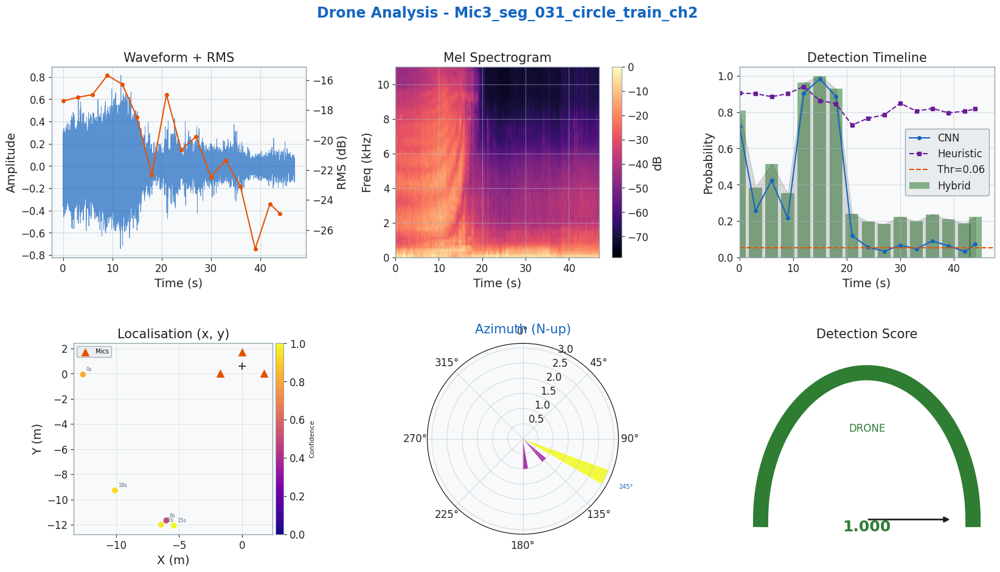

  📍 Plotting Kalman tracks for seg_031_circle_train_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_031_ci.png


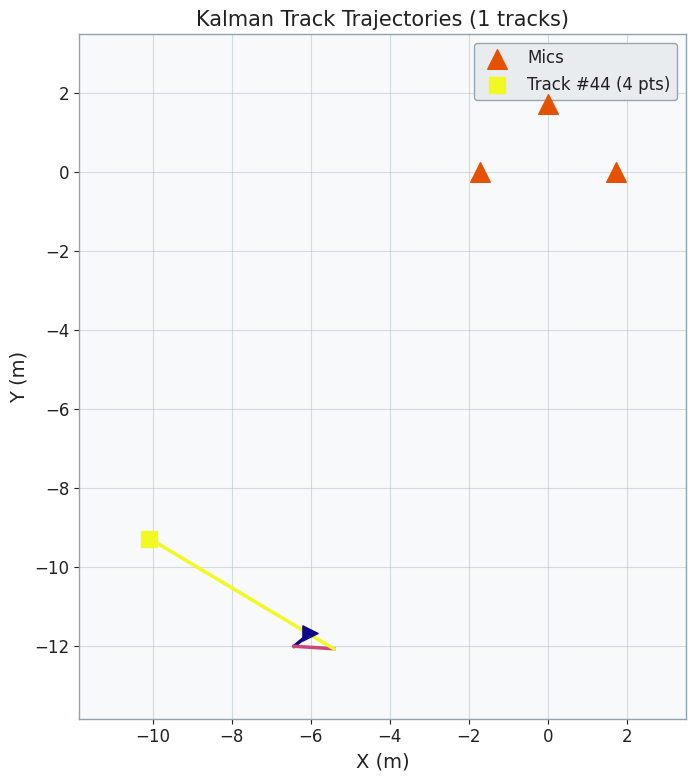


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

  ⚠  Multi-drone result suppressed: all 2 positions within 1.5 m — likely one drone.

🧭 Polar azimuth summary (15 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth_seg_031_ci.png


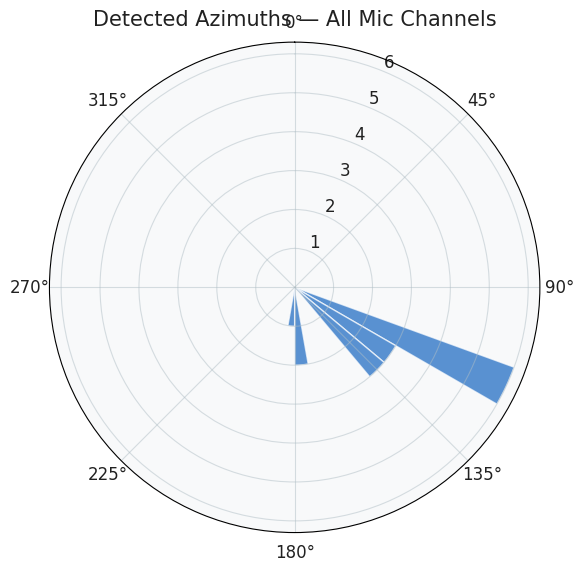


🗺️  Single-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_031_ci.png


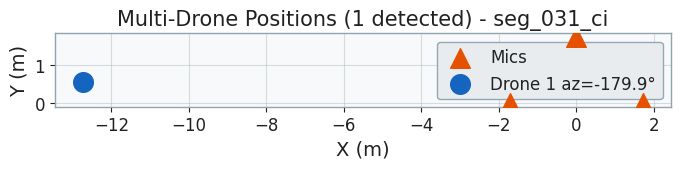


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_031_ci.png


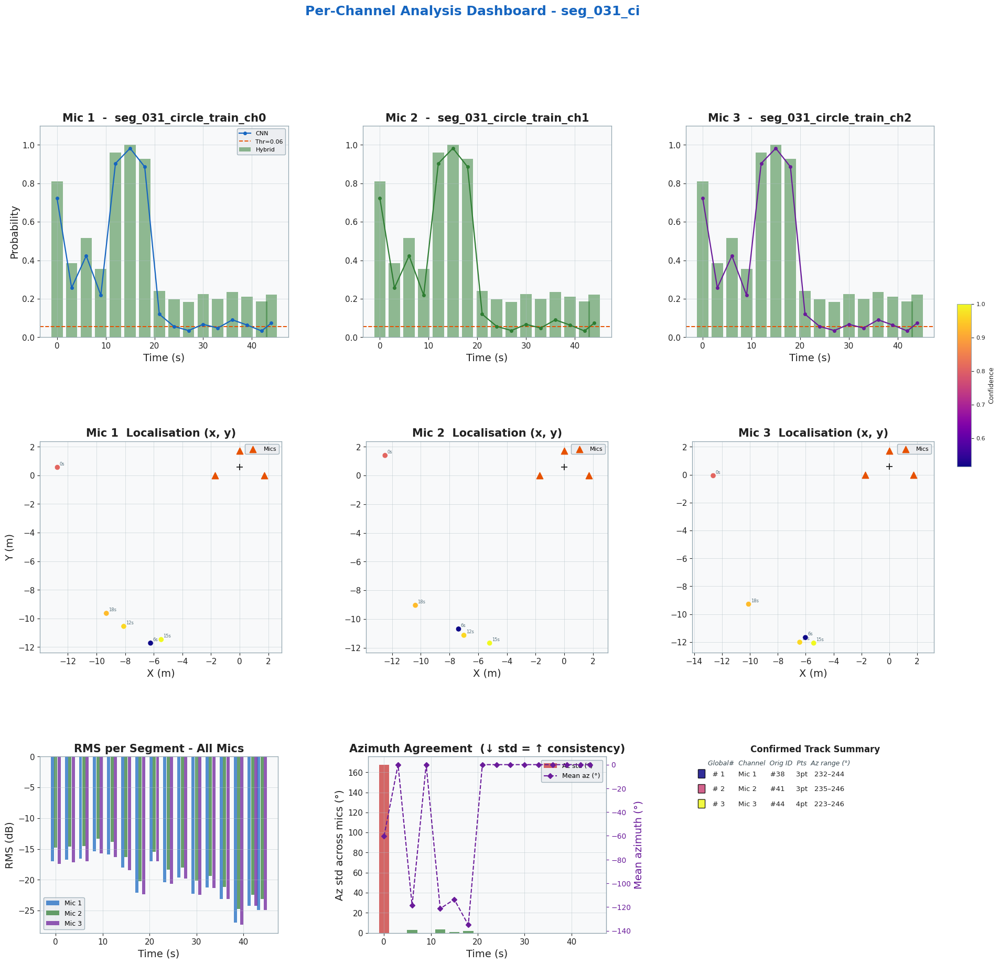

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_031_ci.png


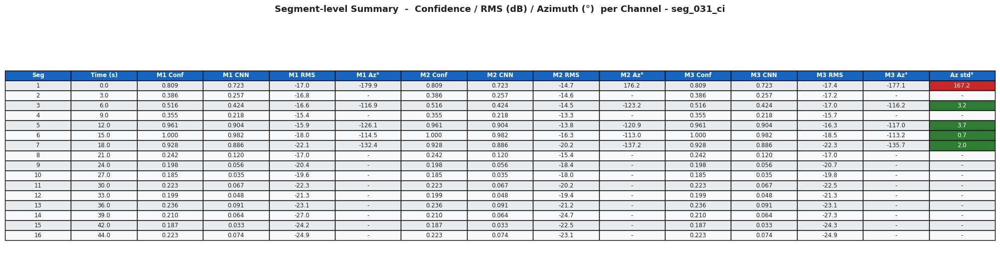


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_031_ci.png


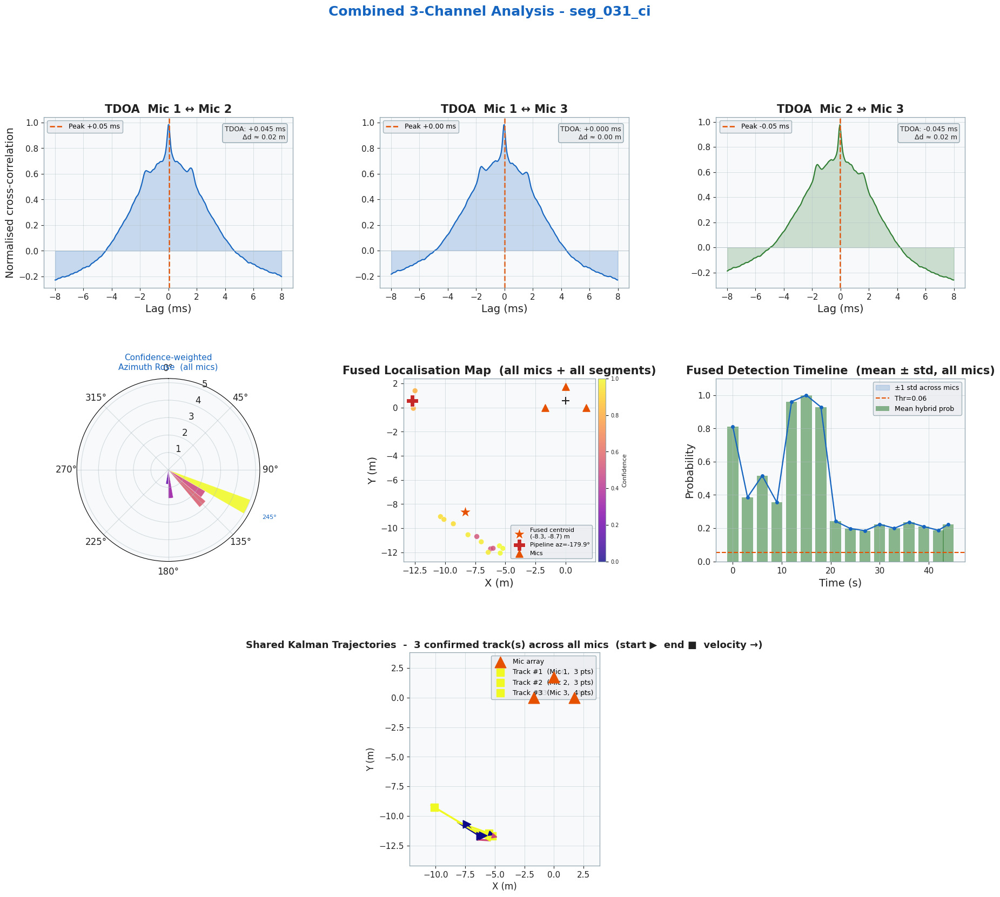


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_031_circle_train_ch0.wav
  Mic 2: /content/seg_031_circle_train_ch1.wav
  Mic 3: /content/seg_031_circle_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(1036350,)  dtype=float32  min=-0.78657  max=0.78918  rms=-18.81 dB
  Ch2: shape=(1036350,)  dtype=float32  min=-0.96426  max=1.00659  rms=-16.84 dB
  Ch3: shape=(1036350,)  dtype=float32  min=-0.74345  max=0.81412  rms=-19.10 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.8093
  cnn_probability        : 0.7231
  heuristic_probability  : 0.9038
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-179.95°  dist=12.74m  ht=12.52m  xy=(-12.737, 0.561)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.8093
  cnn_probability        : 0.7231
  heuristic_probability  : 0.9038
  drones_found           : 2
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57m  x

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_031_circle_train_ch0.wav",
  "/content/seg_031_circle_train_ch1.wav",
  "/content/seg_031_circle_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(4145400,)  rms=-28.24 dB  duration=188.0s
  Ch2: shape=(4145400,)  rms=-25.98 dB  duration=188.0s
  Ch3: shape=(4145400,)  rms=-28.56 dB  duration=188.0s

📊 Analysing seg_032_circle_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.228  cnn=0.080  rms=-26.8 dB
  Seg   2  🚁  conf=0.318  cnn=0.189  rms=-26.5 dB
  Seg   3  🚁  conf=0.242  cnn=0.096  rms=-25.5 dB
  Seg   4  🚁  conf=0.556  cnn=0.488  rms=-26.8 dB  az=-152.1°
  Seg   5  🚁  conf=0.217  cnn=0.067  rms=-26.8 dB
  Seg   6  🚁  conf=0.249  cnn=0.116  rms=-26.6 dB
  Seg   7  🚁  conf=0.193  cnn=0.044  rms=-23.3 dB
  Seg   8  🚁  conf=0.231  cnn=0.091  rms=-25.7 dB
  Seg   9  🚁  conf=0.322  cnn=0.199  rms=-27.7 dB
  Seg  10  🚁  conf=0.231  cnn=0.087  rms=-27.7 dB
  Seg  11  🚁  conf=0.208  cnn=0.060  rms=-27.0 dB
  Seg  12  🚁  conf=0.260  cnn=0.119  rms=-27.3 dB
  Seg  13  🚁  conf=0.202  cnn=0.062  rms=-27.4 dB
  Seg  14  🚁  conf=0.253  cnn=0.114  rms=-26.1 dB

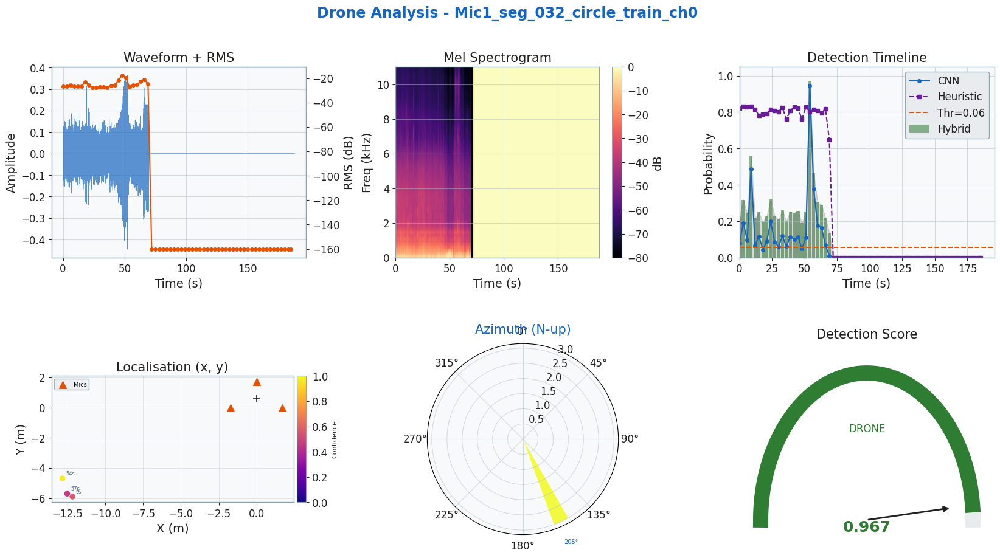

  📍 Plotting Kalman tracks for seg_032_circle_train_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_032_ci.png


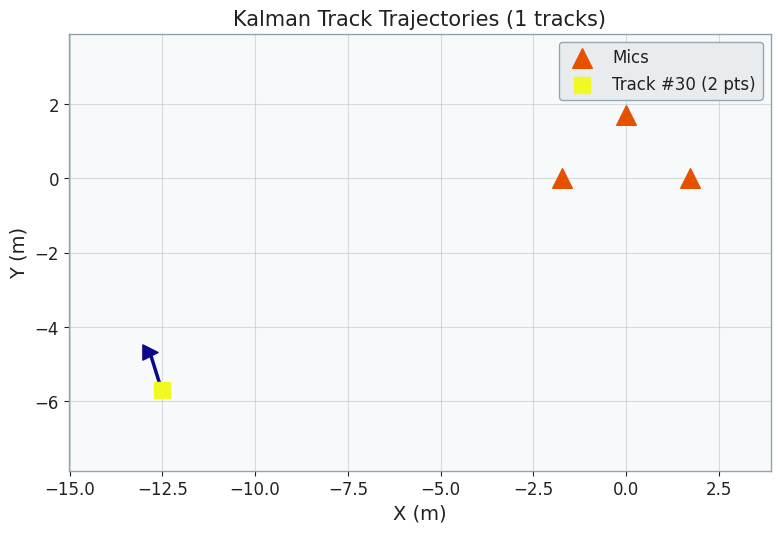


📊 Analysing seg_032_circle_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.228  cnn=0.080  rms=-24.7 dB
  Seg   2  🚁  conf=0.318  cnn=0.189  rms=-24.2 dB
  Seg   3  🚁  conf=0.242  cnn=0.096  rms=-23.9 dB
  Seg   4  🚁  conf=0.556  cnn=0.488  rms=-24.7 dB  az=-151.1°
  Seg   5  🚁  conf=0.217  cnn=0.067  rms=-24.7 dB
  Seg   6  🚁  conf=0.249  cnn=0.116  rms=-24.5 dB
  Seg   7  🚁  conf=0.193  cnn=0.044  rms=-21.7 dB
  Seg   8  🚁  conf=0.231  cnn=0.091  rms=-24.0 dB
  Seg   9  🚁  conf=0.322  cnn=0.199  rms=-25.6 dB
  Seg  10  🚁  conf=0.231  cnn=0.087  rms=-25.4 dB
  Seg  11  🚁  conf=0.208  cnn=0.060  rms=-24.8 dB
  Seg  12  🚁  conf=0.260  cnn=0.119  rms=-25.0 dB
  Seg  13  🚁  conf=0.202  cnn=0.062  rms=-25.2 dB
  Seg  14  🚁  conf=0.253  cnn=0.114  rms=-23.8 dB
  Seg  15  🚁  conf=0.247  cnn=0.101  rms=-23.5 dB
  Seg  16  🚁  conf=0.255  cnn=0.114  rms=-19.4 dB
  Seg  17  🚁  conf=0.191  cnn=0.048  rms=-15.3 dB
  Seg  18  🚁  conf=0.253  cnn=0.110  rms=-17.2 dB
  Seg  19  🚁  conf=0.967  cnn=0

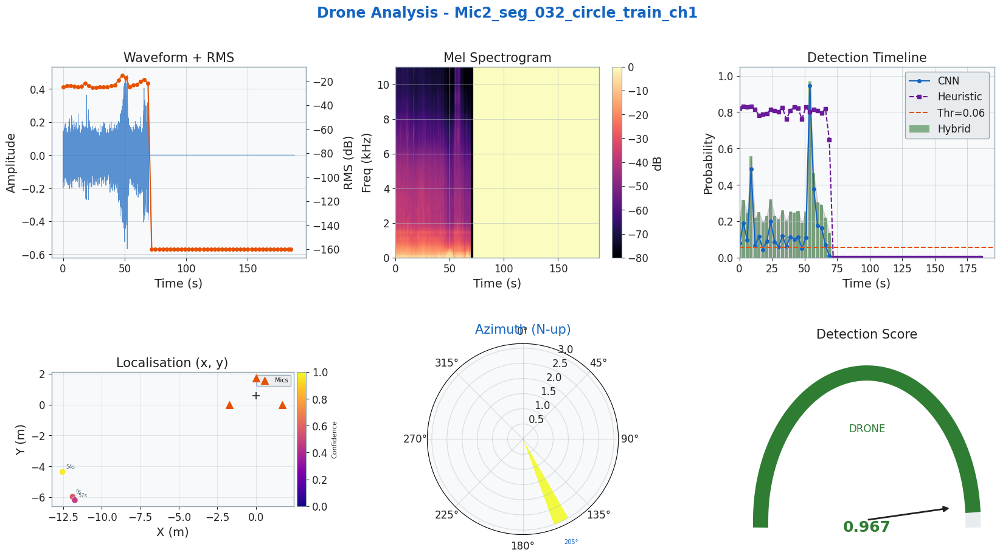

  📍 Plotting Kalman tracks for seg_032_circle_train_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_032_ci.png


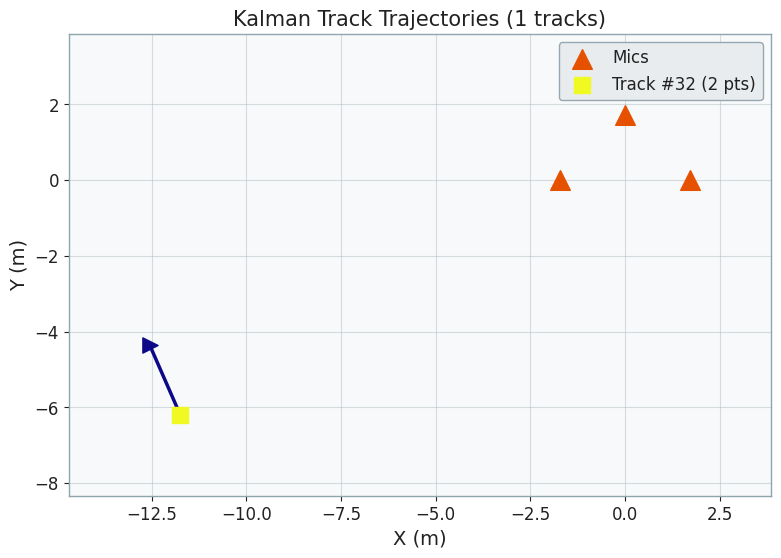


📊 Analysing seg_032_circle_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.228  cnn=0.080  rms=-26.9 dB
  Seg   2  🚁  conf=0.318  cnn=0.189  rms=-26.5 dB
  Seg   3  🚁  conf=0.242  cnn=0.096  rms=-25.9 dB
  Seg   4  🚁  conf=0.556  cnn=0.488  rms=-26.9 dB  az=-145.4°
  Seg   5  🚁  conf=0.217  cnn=0.067  rms=-26.8 dB
  Seg   6  🚁  conf=0.249  cnn=0.116  rms=-26.8 dB
  Seg   7  🚁  conf=0.193  cnn=0.044  rms=-23.3 dB
  Seg   8  🚁  conf=0.231  cnn=0.091  rms=-25.9 dB
  Seg   9  🚁  conf=0.322  cnn=0.199  rms=-27.9 dB
  Seg  10  🚁  conf=0.231  cnn=0.087  rms=-27.9 dB
  Seg  11  🚁  conf=0.208  cnn=0.060  rms=-27.2 dB
  Seg  12  🚁  conf=0.260  cnn=0.119  rms=-27.6 dB
  Seg  13  🚁  conf=0.202  cnn=0.062  rms=-27.7 dB
  Seg  14  🚁  conf=0.253  cnn=0.114  rms=-26.4 dB
  Seg  15  🚁  conf=0.247  cnn=0.101  rms=-26.1 dB
  Seg  16  🚁  conf=0.255  cnn=0.114  rms=-22.1 dB
  Seg  17  🚁  conf=0.191  cnn=0.048  rms=-18.1 dB
  Seg  18  🚁  conf=0.253  cnn=0.110  rms=-20.1 dB
  Seg  19  🚁  conf=0.967  cnn=0

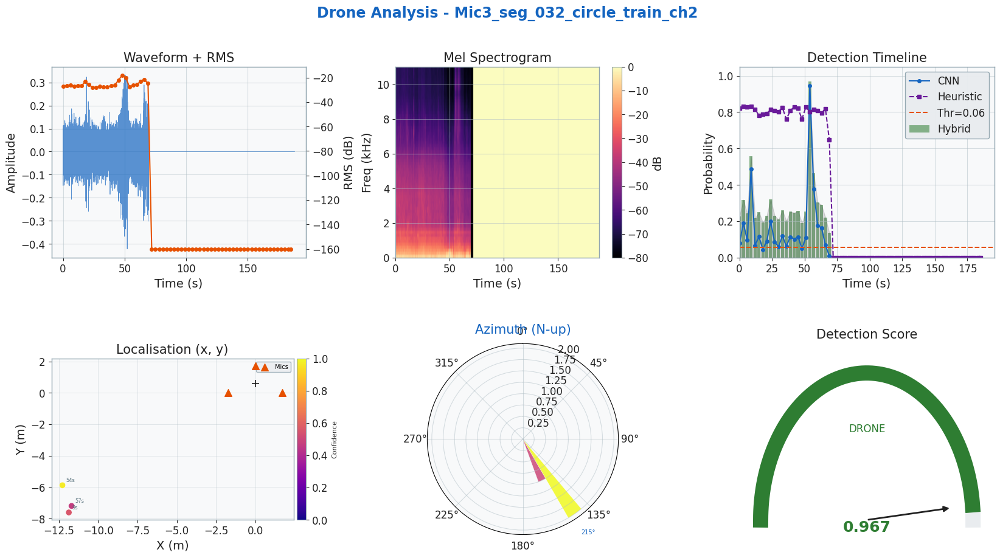

  📍 Plotting Kalman tracks for seg_032_circle_train_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory_seg_032_ci.png


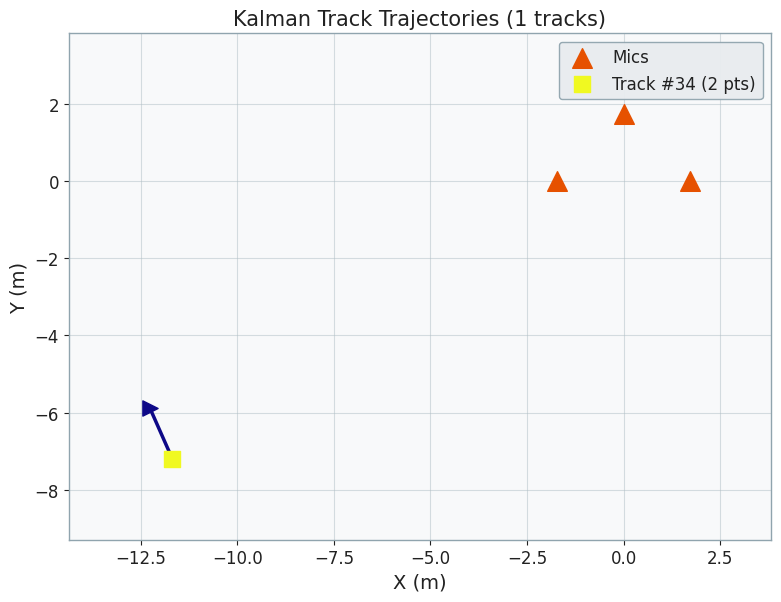


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🧭 Polar azimuth summary (9 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth_seg_032_ci.png


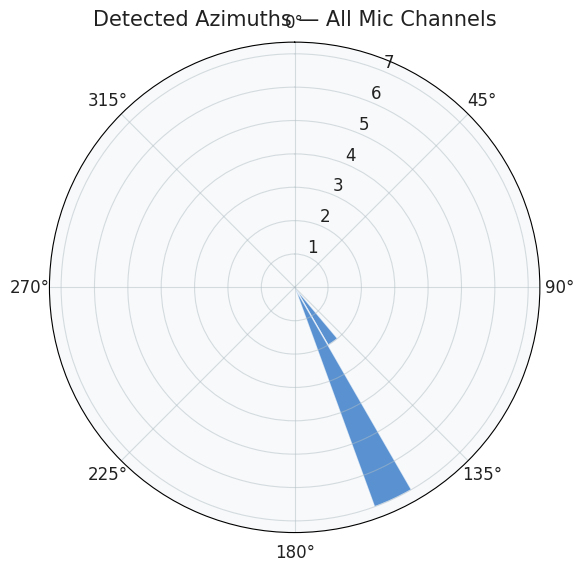


🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_032_ci.png


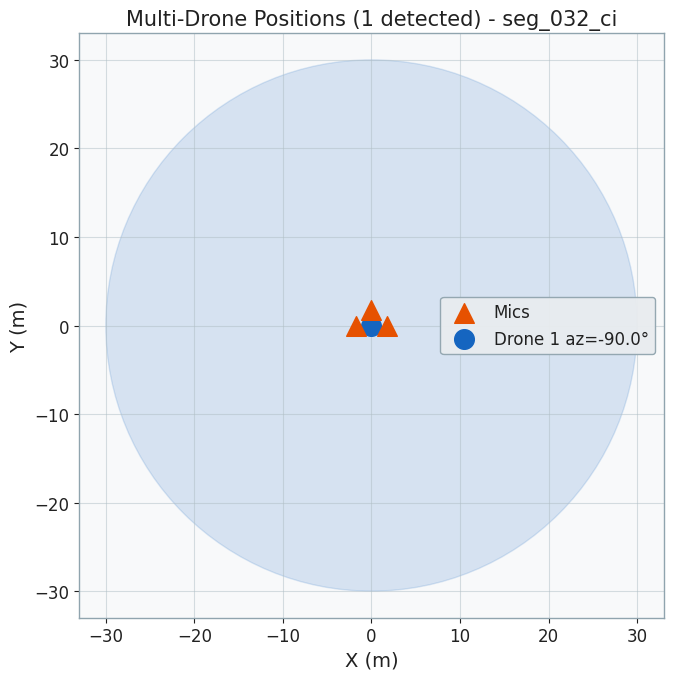


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_032_ci.png


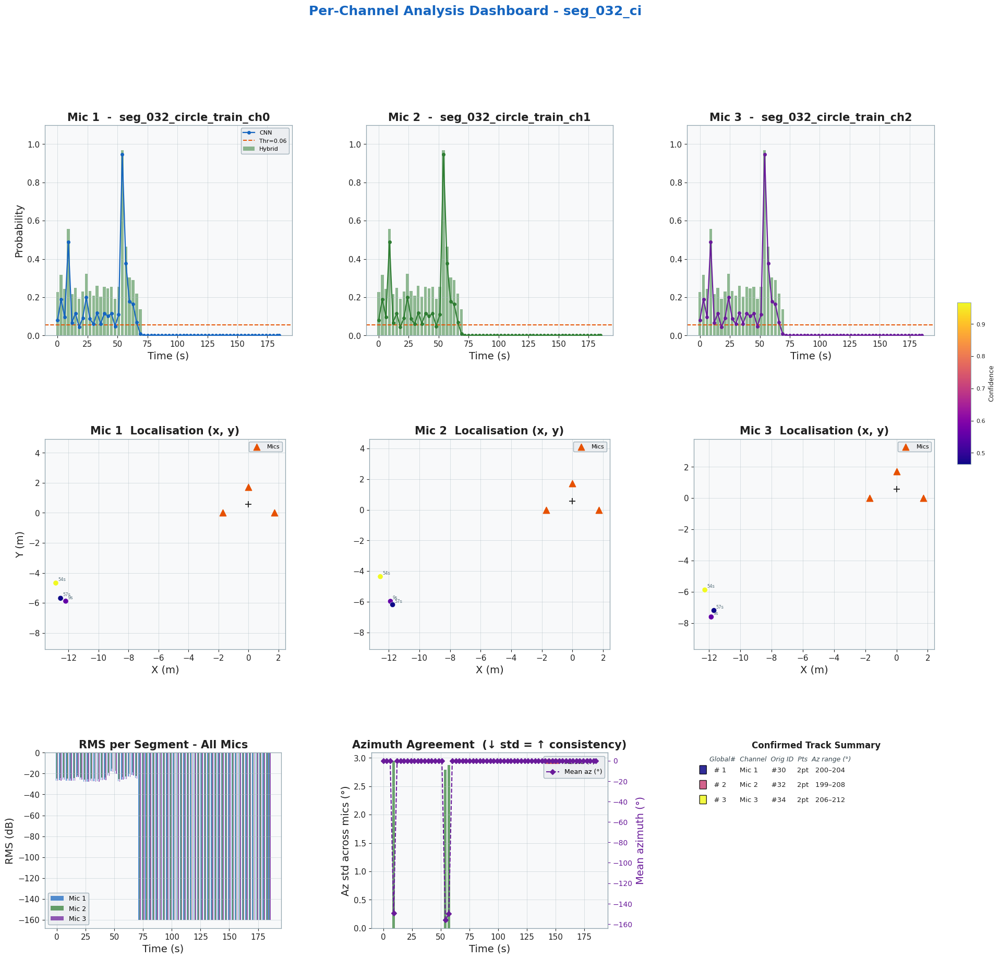

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_032_ci.png


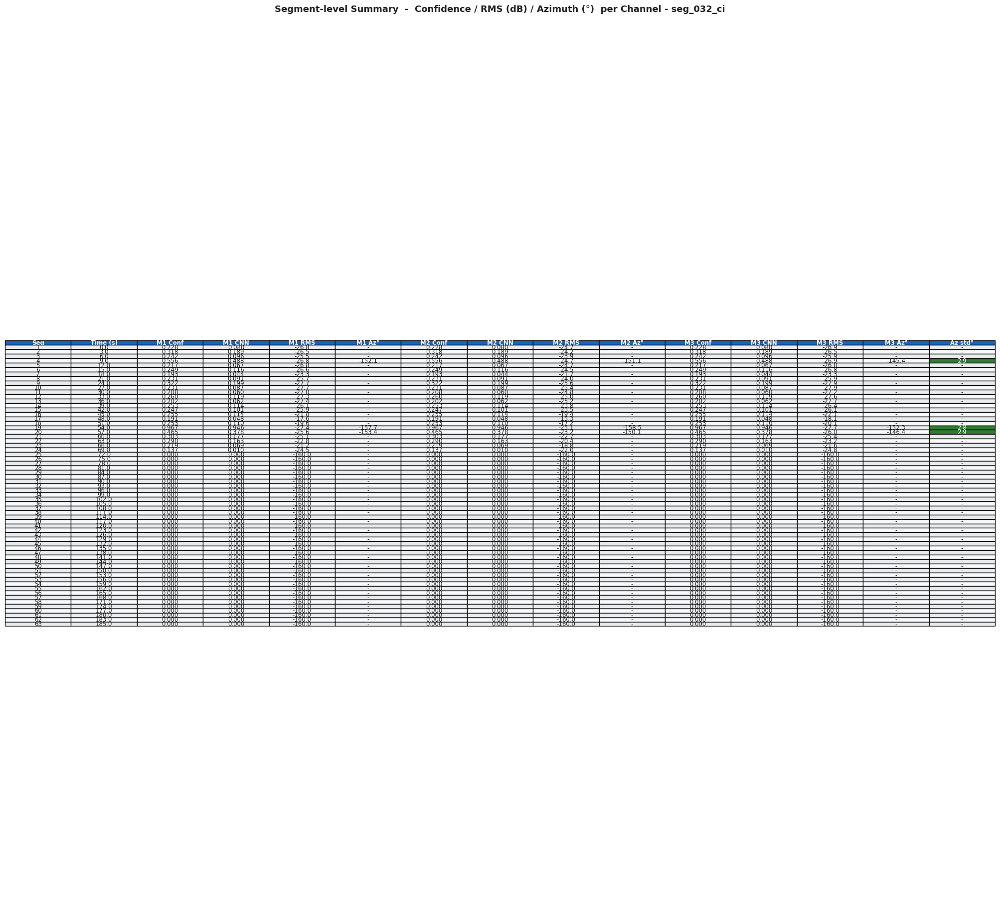


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_032_ci.png


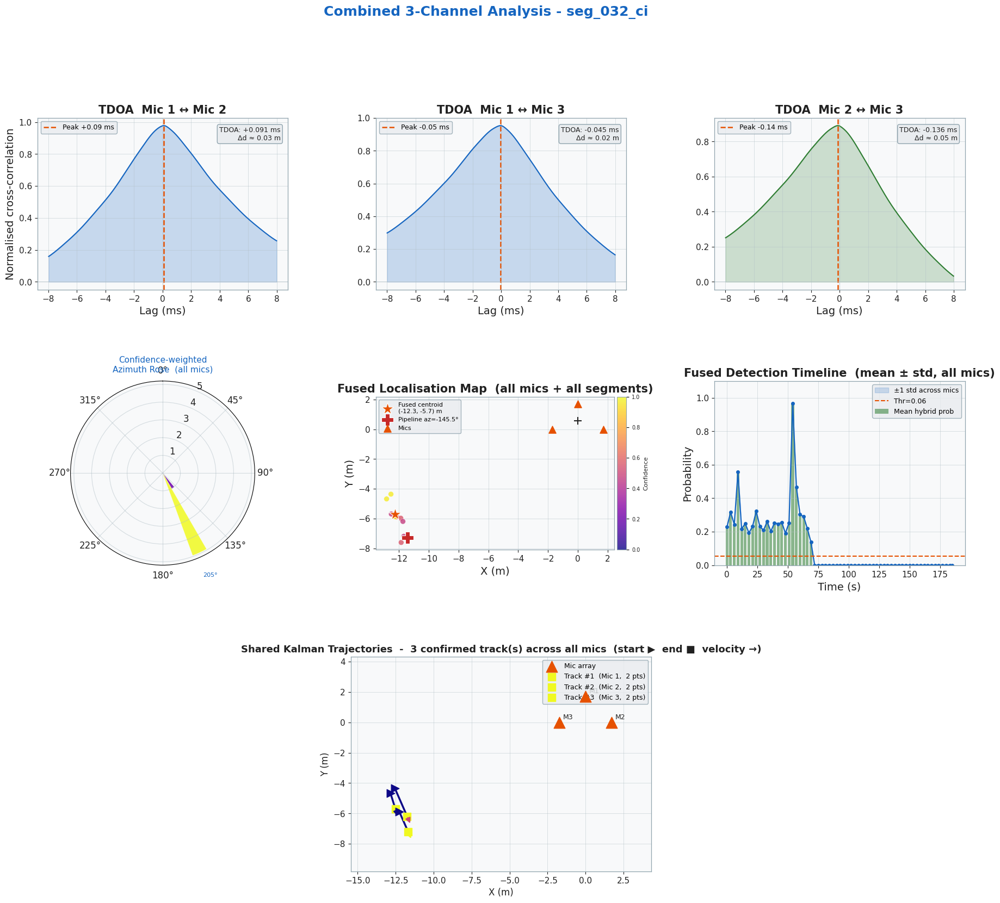


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_032_circle_train_ch0.wav
  Mic 2: /content/seg_032_circle_train_ch1.wav
  Mic 3: /content/seg_032_circle_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(4145400,)  dtype=float32  min=-0.44317  max=0.36411  rms=-28.24 dB
  Ch2: shape=(4145400,)  dtype=float32  min=-0.56756  max=0.48264  rms=-25.98 dB
  Ch3: shape=(4145400,)  dtype=float32  min=-0.42171  max=0.33097  rms=-28.56 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.2283
  cnn_probability        : 0.0801
  heuristic_probability  : 0.8210
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-145.47°  dist=13.86m  ht=10.39m  xy=(-11.415, -7.281)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.2283
  cnn_probability        : 0.0801
  heuristic_probability  : 0.8210
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57m  

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_032_circle_train_ch0.wav",
  "/content/seg_032_circle_train_ch1.wav",
  "/content/seg_032_circle_train_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr=0.055)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=50, val_loss=0.33388)

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(66150,)  rms=-23.21 dB  duration=3.0s
  Ch2: shape=(66150,)  rms=-23.51 dB  duration=3.0s
  Ch3: shape=(66150,)  rms=-23.28 dB  duration=3.0s

📊 Analysing seg_036_circle_test_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.242  cnn=0.086  rms=-23.2 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_036_circle_test_ch0.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_036_circle_test_ch0_seg_036_ci.png


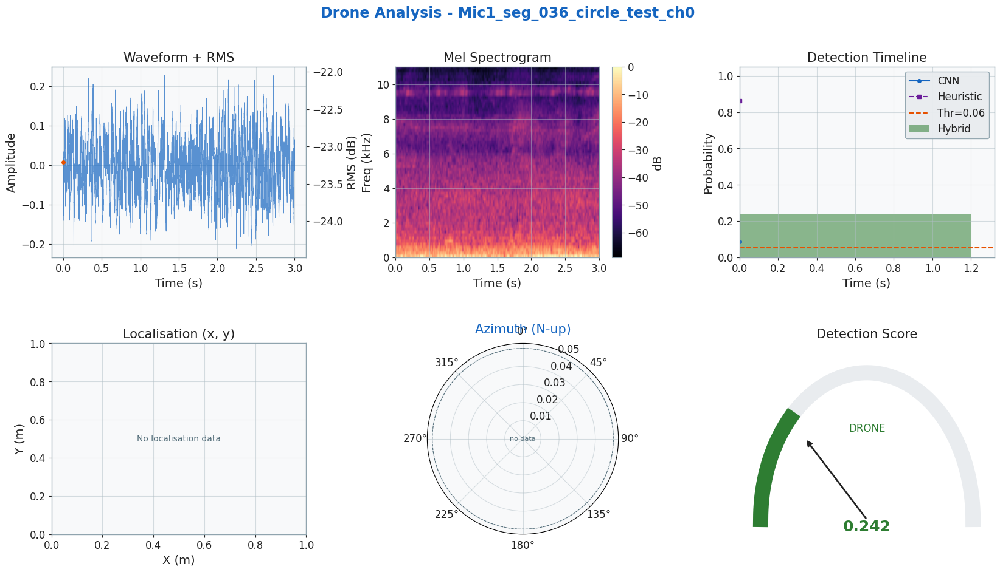


📊 Analysing seg_036_circle_test_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.242  cnn=0.086  rms=-23.5 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_036_circle_test_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_036_circle_test_ch1_seg_036_ci.png


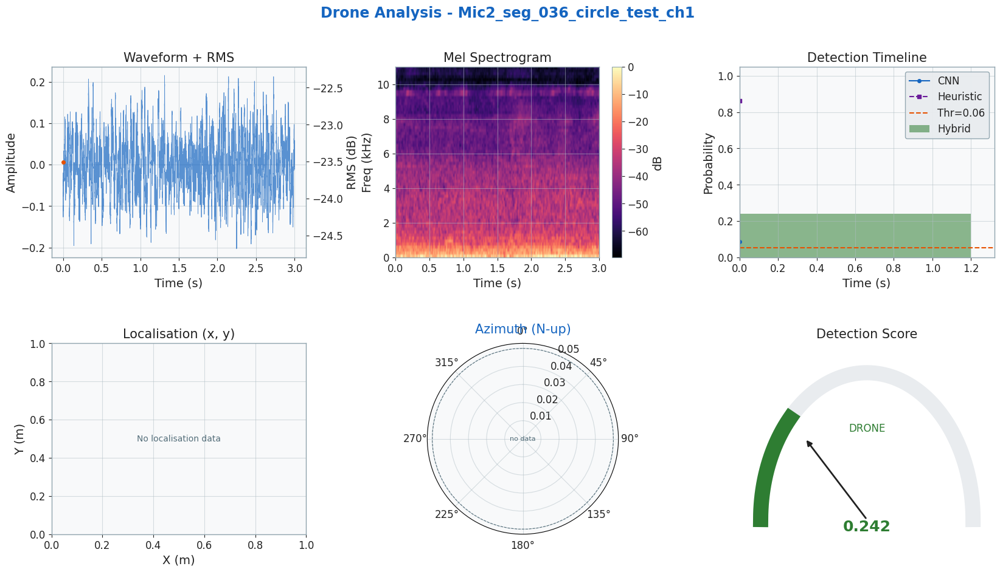


📊 Analysing seg_036_circle_test_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.242  cnn=0.086  rms=-23.3 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_036_circle_test_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_036_circle_test_ch2_seg_036_ci.png


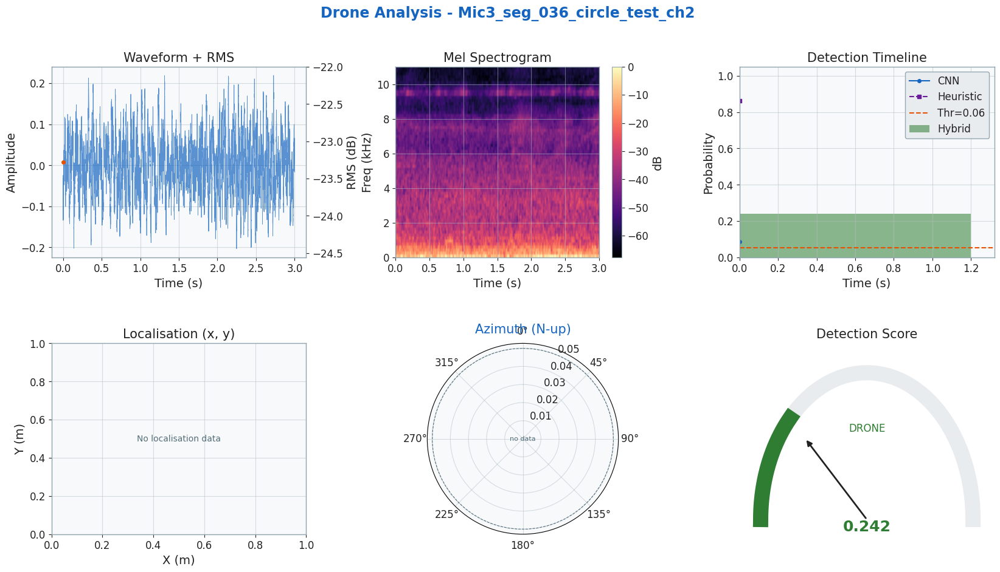


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_036_ci.png


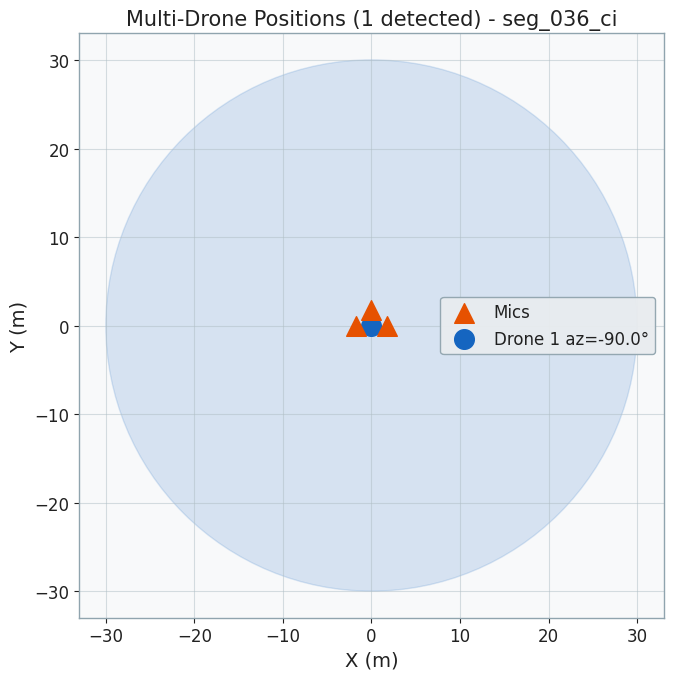


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_036_ci.png


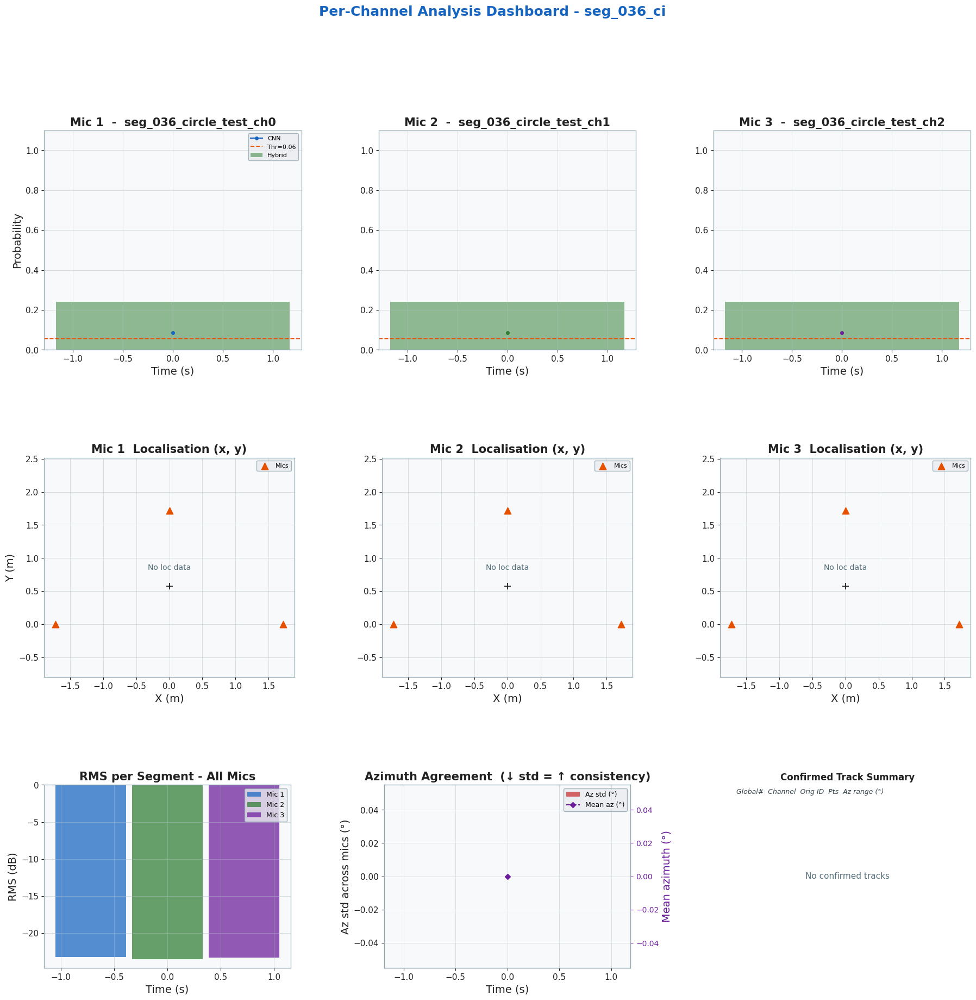

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_036_ci.png


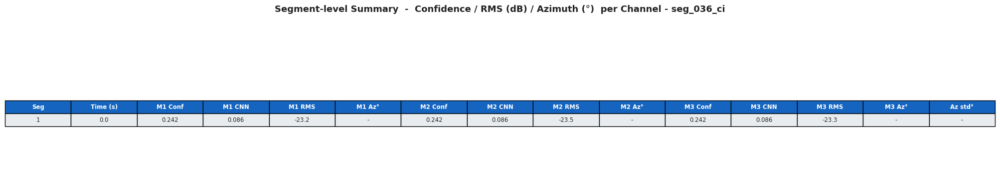


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_036_ci.png


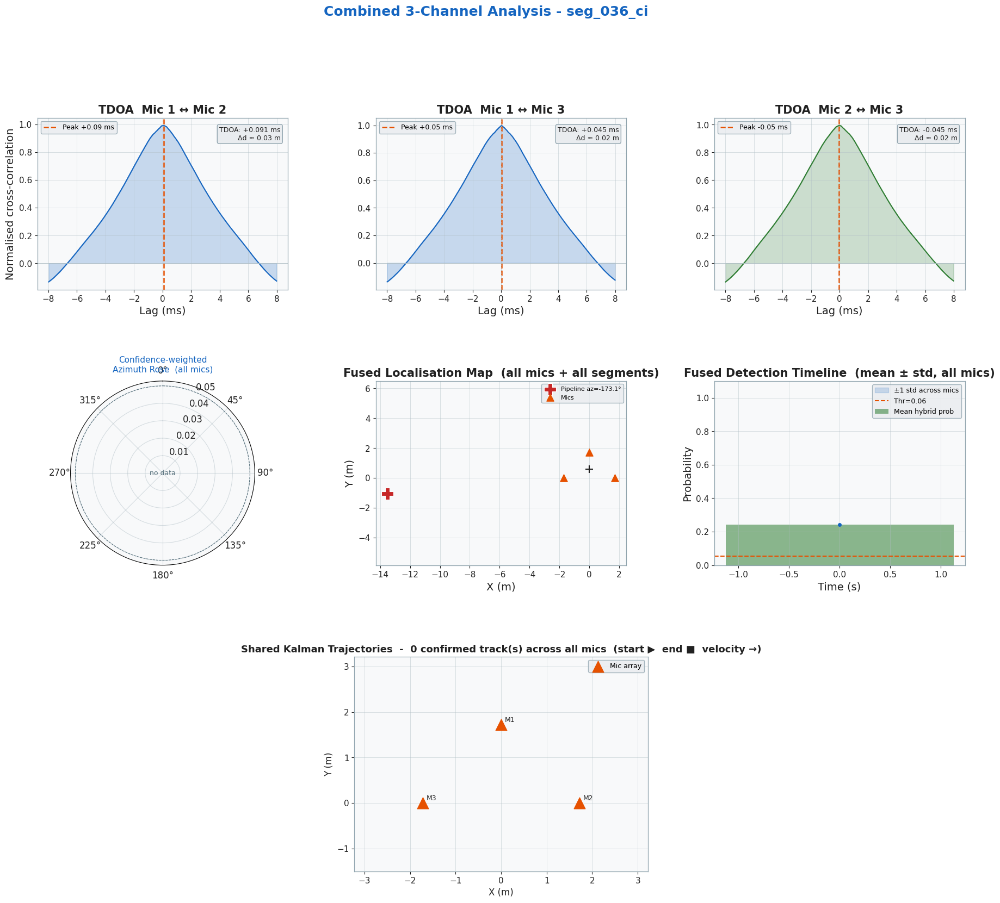


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_036_circle_test_ch0.wav
  Mic 2: /content/seg_036_circle_test_ch1.wav
  Mic 3: /content/seg_036_circle_test_ch2.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.21178  max=0.22761  rms=-23.21 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.20282  max=0.21546  rms=-23.51 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.20345  max=0.21949  rms=-23.28 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.2419
  cnn_probability        : 0.0865
  heuristic_probability  : 0.8634
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-173.10°  dist=13.63m  ht=11.97m  xy=(-13.530, -1.064)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.2419
  cnn_probability        : 0.0865
  heuristic_probability  : 0.8634
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57m  xy=(-0.00

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_036_circle_test_ch0.wav",
  "/content/seg_036_circle_test_ch1.wav",
  "/content/seg_036_circle_test_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(66150,)  rms=-21.98 dB  duration=3.0s
  Ch2: shape=(66150,)  rms=-22.19 dB  duration=3.0s
  Ch3: shape=(66150,)  rms=-22.01 dB  duration=3.0s

📊 Analysing seg_037_circle_test_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.953  cnn=0.905  rms=-22.0 dB  az=-163.5°

  📊 1/1 segments detected  |  0 confirmed track(s)  |  1 segments localised

🖼️  Generating analysis dashboard for seg_037_circle_test_ch0.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_037_circle_test_ch0_seg_037_ci.png


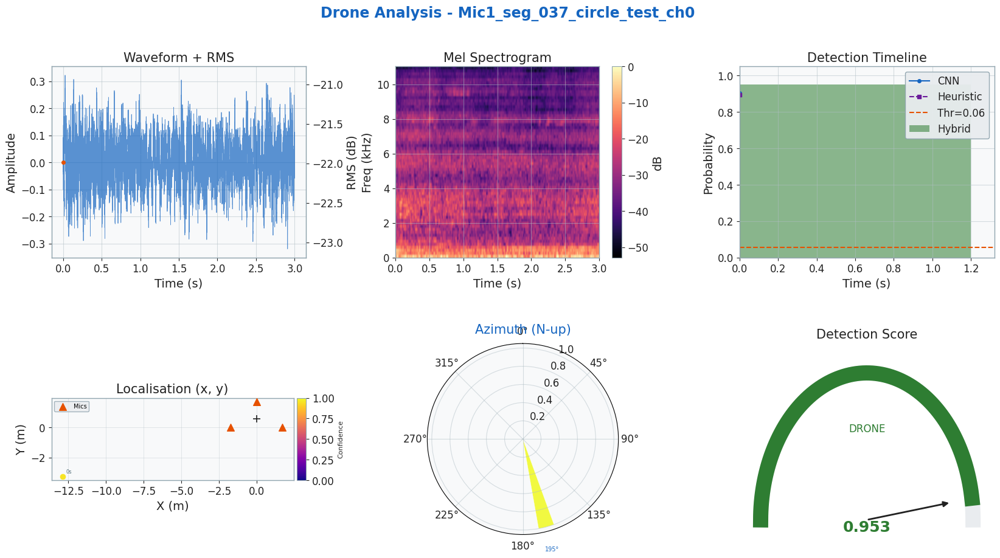


📊 Analysing seg_037_circle_test_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.953  cnn=0.905  rms=-22.2 dB  az=-158.9°

  📊 1/1 segments detected  |  0 confirmed track(s)  |  1 segments localised

🖼️  Generating analysis dashboard for seg_037_circle_test_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_037_circle_test_ch1_seg_037_ci.png


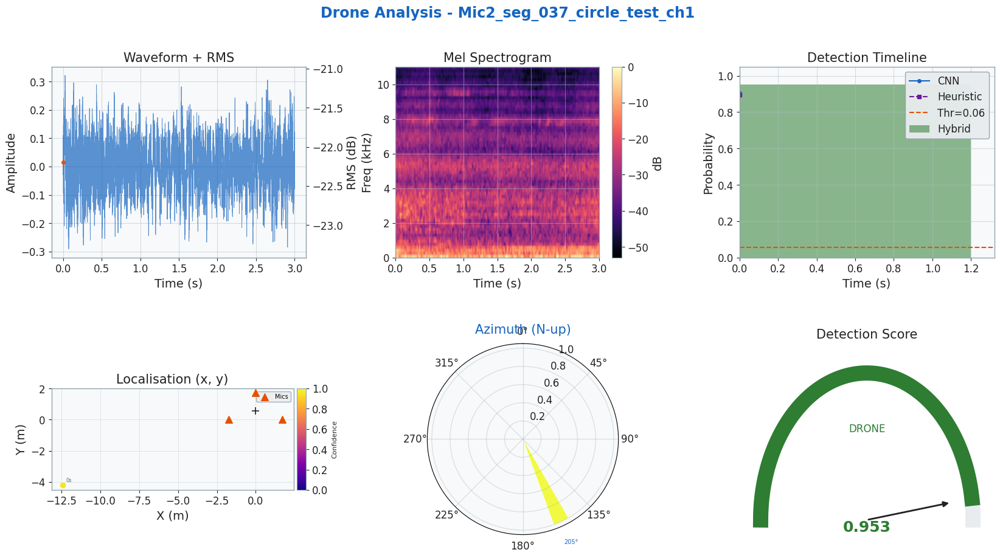


📊 Analysing seg_037_circle_test_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.953  cnn=0.905  rms=-22.0 dB  az=-160.2°

  📊 1/1 segments detected  |  0 confirmed track(s)  |  1 segments localised

🖼️  Generating analysis dashboard for seg_037_circle_test_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_037_circle_test_ch2_seg_037_ci.png


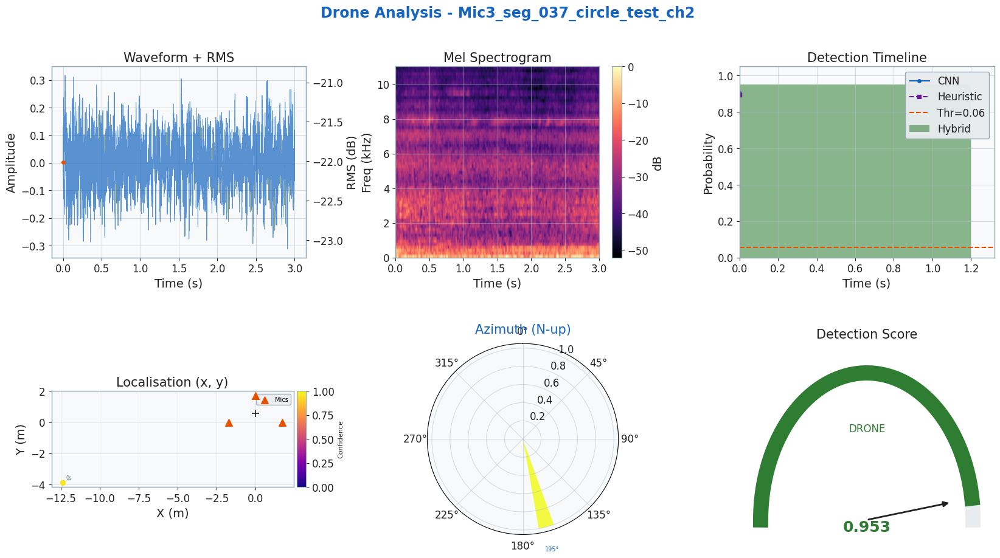


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

  ⚠  Multi-drone result suppressed: all 2 positions within 1.5 m — likely one drone.

🧭 Polar azimuth summary (3 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth_seg_037_ci.png


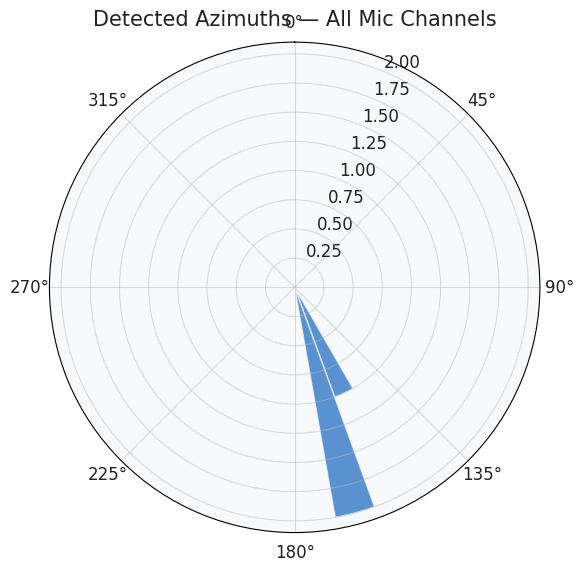


🗺️  Single-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_037_ci.png


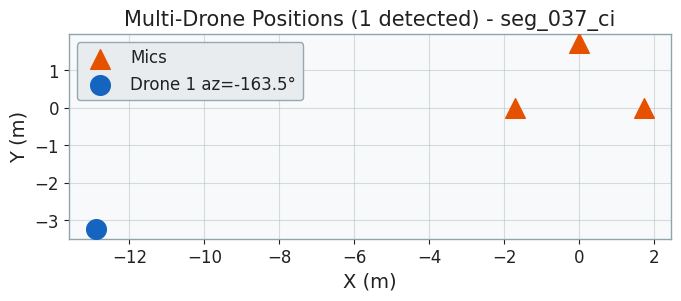


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_037_ci.png


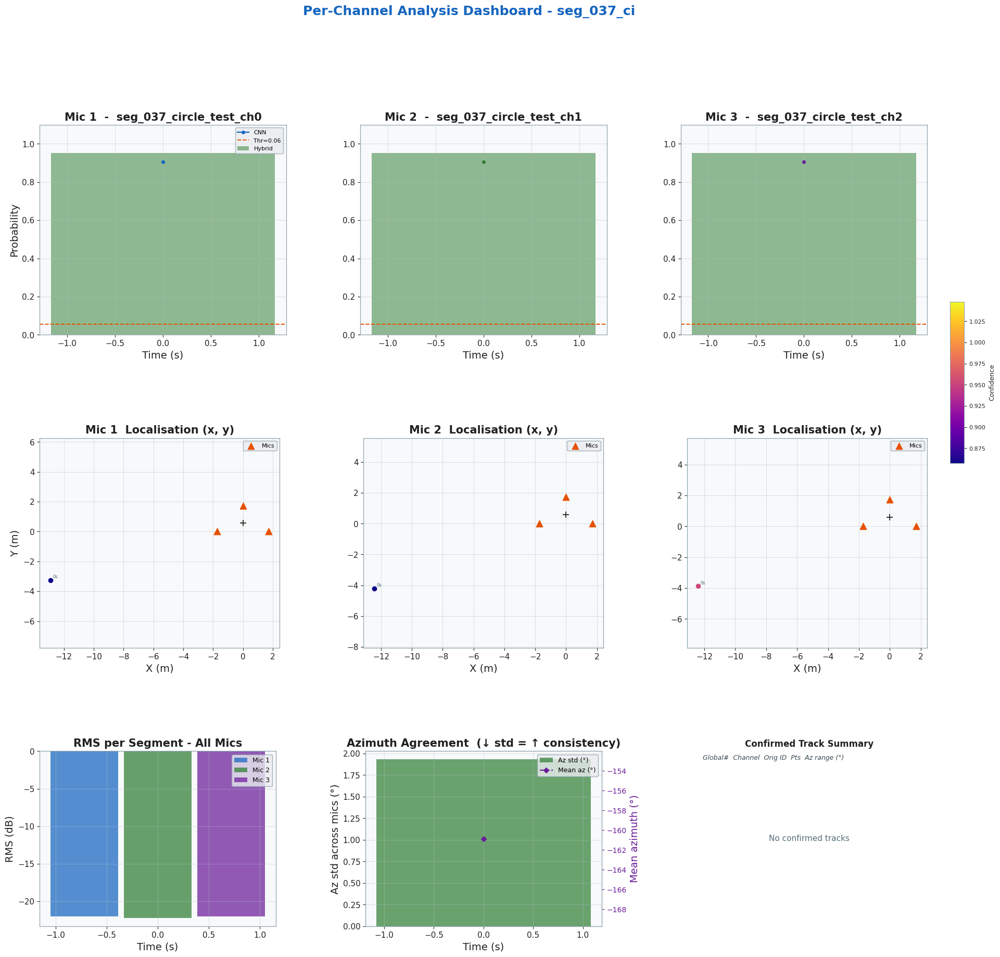

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_037_ci.png


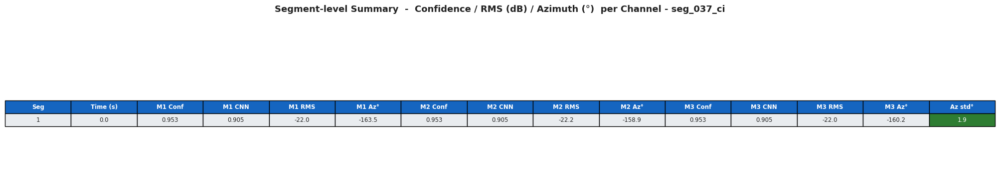


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_037_ci.png


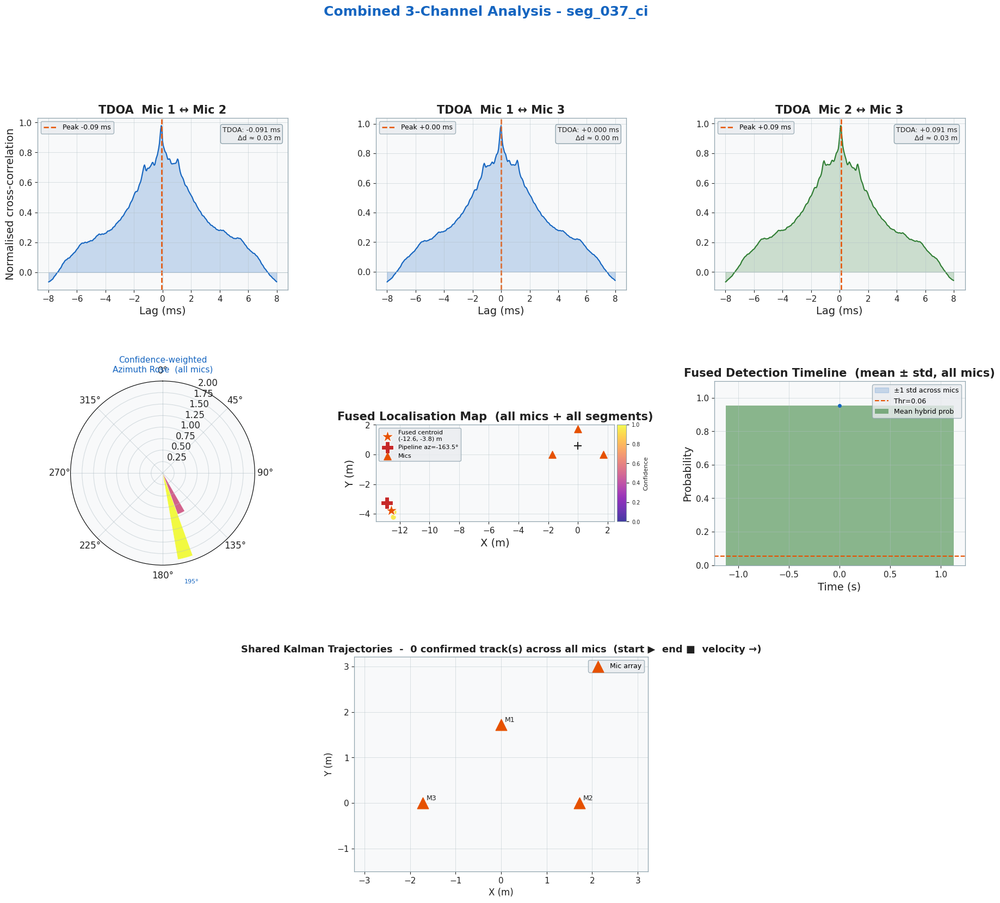


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_037_circle_test_ch0.wav
  Mic 2: /content/seg_037_circle_test_ch1.wav
  Mic 3: /content/seg_037_circle_test_ch2.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.31927  max=0.32295  rms=-21.98 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.29083  max=0.32217  rms=-22.19 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.31178  max=0.31725  rms=-22.01 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.9528
  cnn_probability        : 0.9050
  heuristic_probability  : 0.8940
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-163.49°  dist=13.44m  ht=13.01m  xy=(-12.888, -3.247)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.9528
  cnn_probability        : 0.9050
  heuristic_probability  : 0.8940
  drones_found           : 2
  tracks_returned        : 0
    Drone 1: az=-77.01°  dist=0.76m  xy=(0.172

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_037_circle_test_ch0.wav",
  "/content/seg_037_circle_test_ch1.wav",
  "/content/seg_037_circle_test_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

🔄 Loading models...

🔊 Loading 3-channel audio (full length)...
  Ch1: shape=(66150,)  rms=-22.87 dB  duration=3.0s
  Ch2: shape=(66150,)  rms=-23.24 dB  duration=3.0s
  Ch3: shape=(66150,)  rms=-22.91 dB  duration=3.0s

📊 Analysing seg_038_circle_test_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.266  cnn=0.114  rms=-22.9 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_038_circle_test_ch0.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_038_circle_test_ch0_seg_038_ci.png


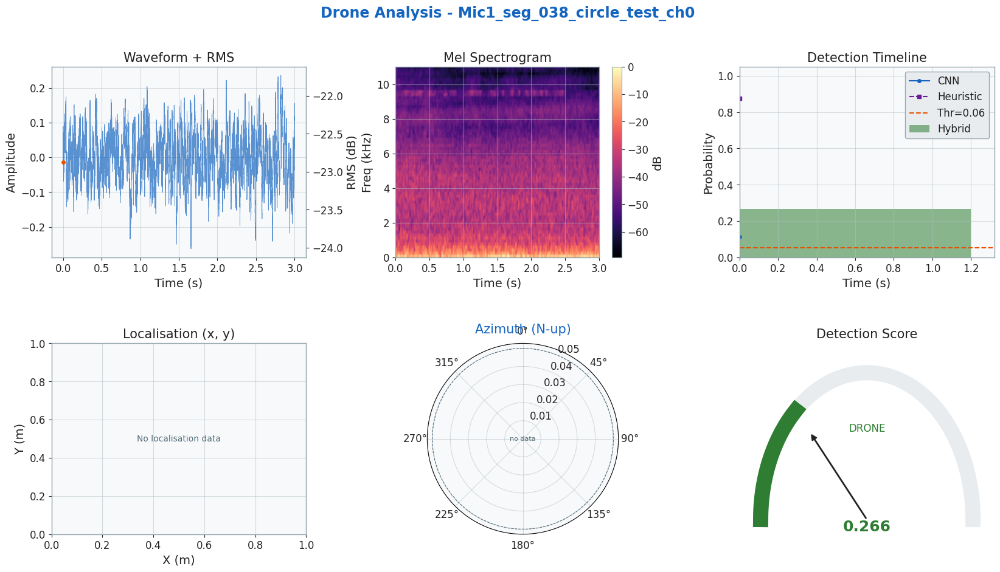


📊 Analysing seg_038_circle_test_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.266  cnn=0.114  rms=-23.2 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_038_circle_test_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_038_circle_test_ch1_seg_038_ci.png


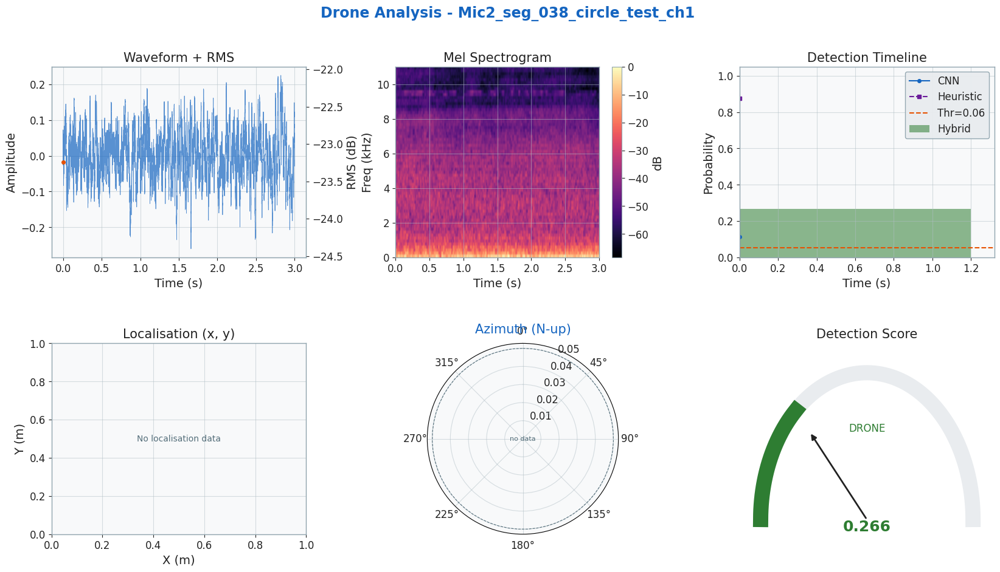


📊 Analysing seg_038_circle_test_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.266  cnn=0.114  rms=-22.9 dB

  📊 1/1 segments detected  |  0 confirmed track(s)  |  0 segments localised

🖼️  Generating analysis dashboard for seg_038_circle_test_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_038_circle_test_ch2_seg_038_ci.png


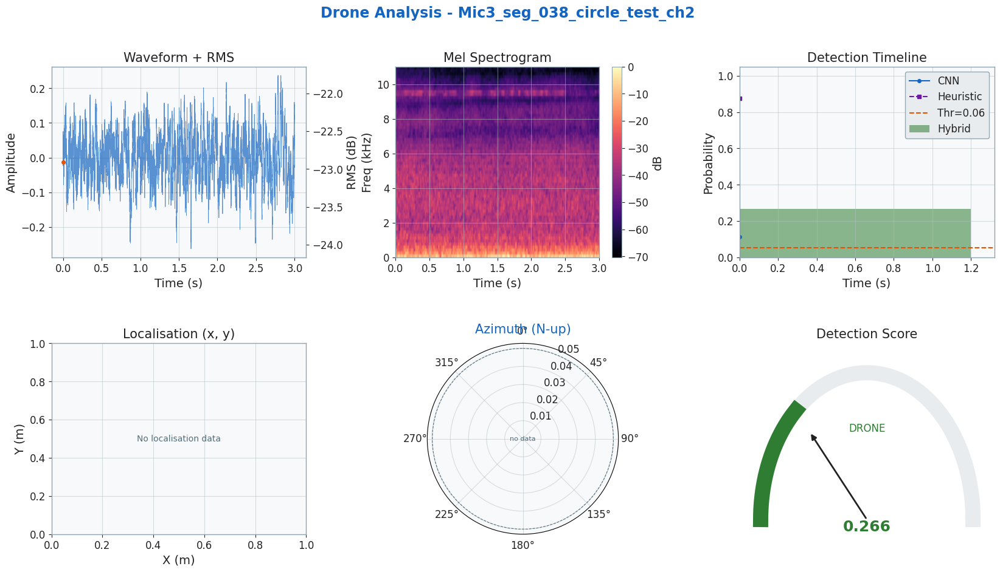


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions_seg_038_ci.png


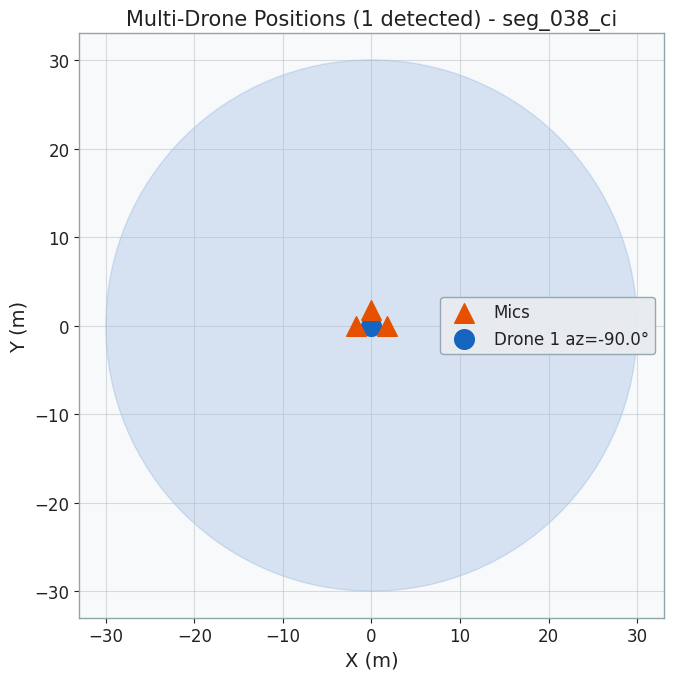


📐 Per-channel enhanced dashboard (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.915, 0.992])


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_per_channel_enhanced_seg_038_ci.png


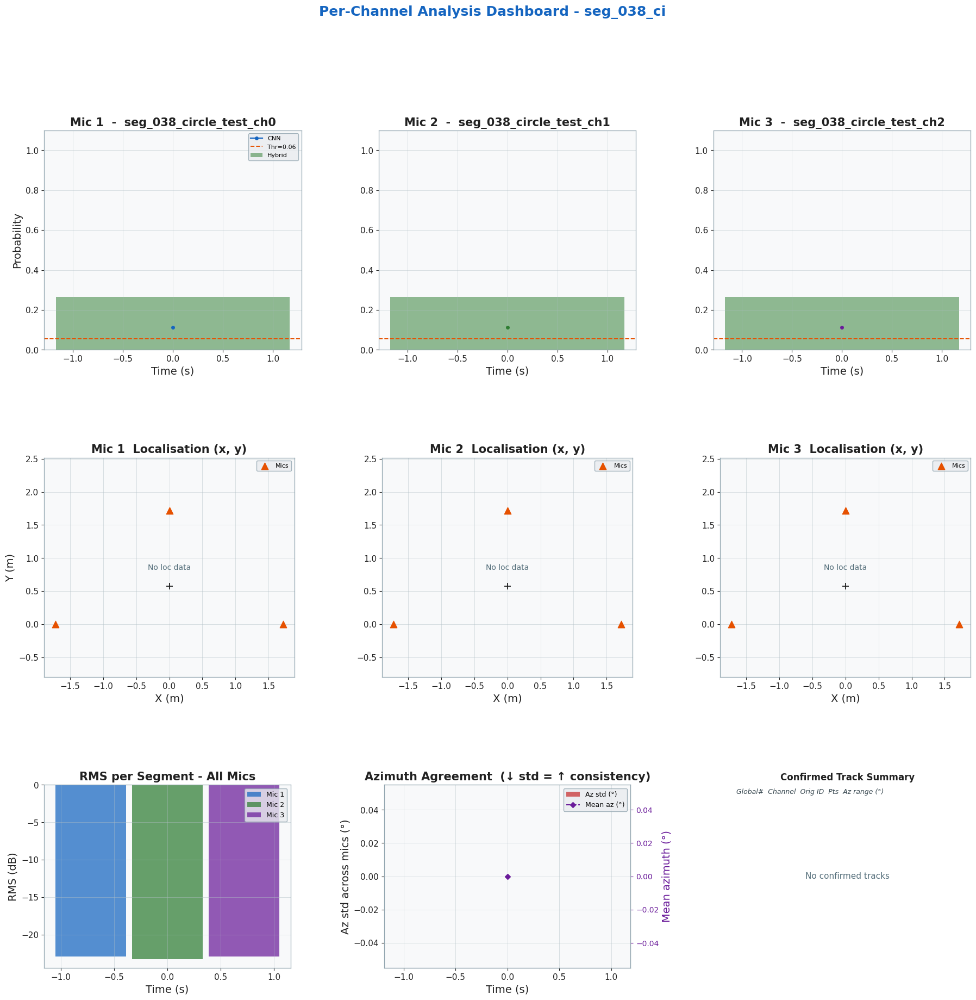

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_segment_table_seg_038_ci.png


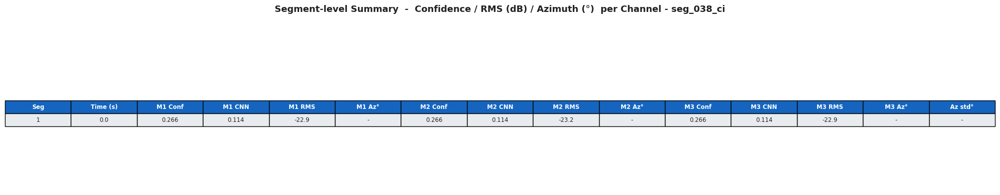


🔬 Combined 3-channel analysis (thesis)...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:2744: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  if save:


💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/thesis_combined_3ch_analysis_seg_038_ci.png


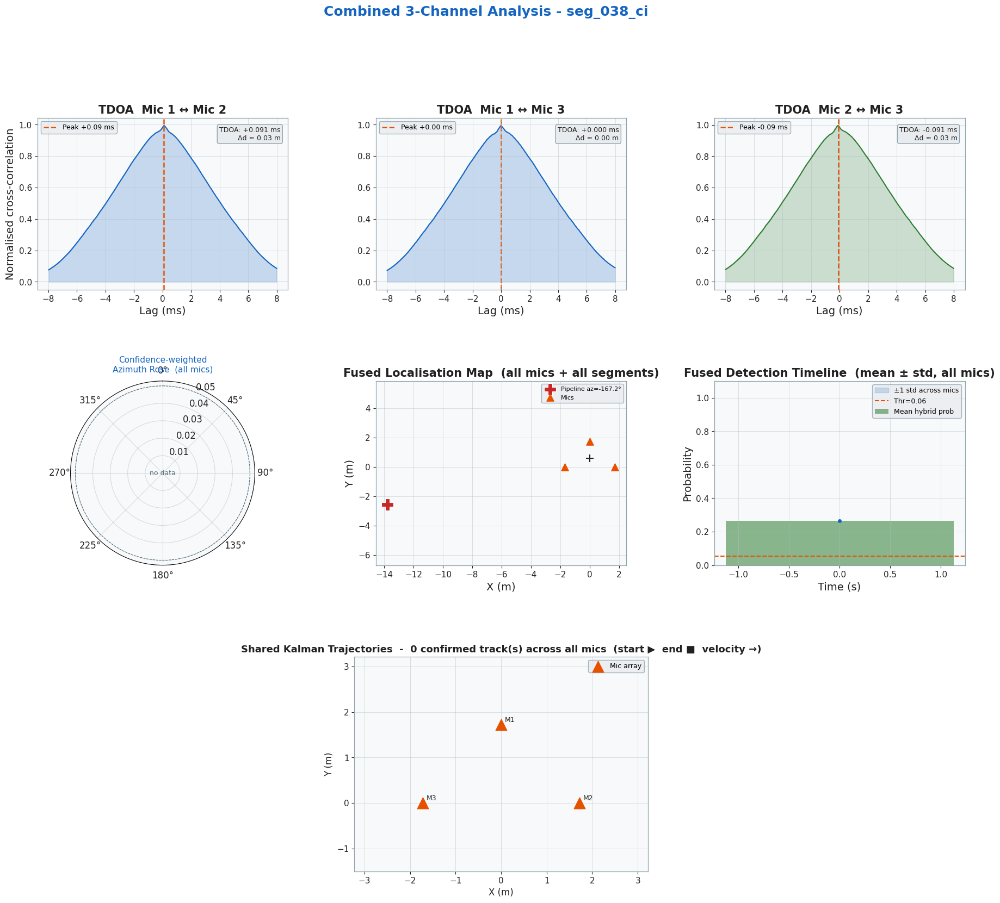


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: /content/seg_038_circle_test_ch0.wav
  Mic 2: /content/seg_038_circle_test_ch1.wav
  Mic 3: /content/seg_038_circle_test_ch2.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.26328  max=0.23610  rms=-22.87 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.26012  max=0.22532  rms=-23.24 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.26255  max=0.23730  rms=-22.91 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.2664
  cnn_probability        : 0.1139
  heuristic_probability  : 0.8765
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-167.16°  dist=14.15m  ht=12.65m  xy=(-13.793, -2.571)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.2664
  cnn_probability        : 0.1139
  heuristic_probability  : 0.8765
  drones_found           : 1
  tracks_returned        : 0
    Drone 1: az=-90.00°  dist=0.57m  xy=(-0.00

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/seg_038_circle_test_ch0.wav",
  "/content/seg_038_circle_test_ch1.wav",
  "/content/seg_038_circle_test_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

In [ ]:
# # Test uploaded 3-mic files with one function

files = [
  "/content/251020VITEMOROM1AT01A_0219000_0221000.wav",
  "/content/klemenflerin-drone-fly-397287_0010000_0247920.wav",
  "/content/seg_006_hover_val_ch2.wav",
]

if files:
  result = comprehensive_pipeline_test(files)
else:
  result = comprehensive_pipeline_test()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from google.colab import files
import os
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# Simple usage with real audio files
from drone_detection import multi_drone_demo_from_files

# Use your own drone audio recordings
audio_files = [
    "/content/klemenflerin-drone-fly-397287_0010000_0247920.wav",
    "/content/seg_006_hover_val_ch2.wav",
    "/content/251020VITEMOROM1AT01A_0219000_0221000.wav"
]

result = multi_drone_demo_from_files(
    audio_files=audio_files,
    auto_detect_types=True  # Auto-detect drone types from audio
)


🚁 MULTI-DRONE REAL AUDIO DEMO
──────────────────────────────────────────────────
Processing 3 drone audio files...
  Drone 1: klemenflerin-drone-fly-397287_0010000_0247920.wav
    Type: mavic_2_pro, Fund: 195.0Hz
    Simulated position: (3.00, 0.00)m
  Drone 2: seg_006_hover_val_ch2.wav
    Type: dji_high_altitude, Fund: 55.0Hz
    Simulated position: (-1.50, 2.60)m
  Drone 3: 251020VITEMOROM1AT01A_0219000_0221000.wav
    Simulated position: (-1.50, -2.60)m

🎛️  Mixing audio sources...
💾 Mixed 3 channels to temporary files
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr=0.055)

📊 Detection Results:
  Detected: True  (conf=1.000)
  Drones found: 1
    Drone 1: (-0.00,0.00)m  az=-90.0°  dist=0.57m
      Error from simulation: 3.000m

🎯 Confirmed tracks: 1
    Track #1: pos=(-0.00,0.00)m  hits=1  dist=0.000m


In [ ]:
import shutil
shutil.rmtree(config.PROCESSED_DIR / "localization", ignore_errors=True)
train_localization(config, epochs=5, resume=False)

  STAGE 2 — Localization Model (UaVirBASE)
📂 Using local dataset at /data_extra/uavirbase_ssl/Microphone_array (skipping download)
   ✅ _process_local: 1000 clips written across all splits
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 880 real + 500 synthetic = 1380 total
   📋 Resumed log from localization_log.csv (5 existing rows)
   📅 Scheduler state restored.


Loc ep 1:   0%|          | 0/43 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Loc Ep   1 | tr=2.99550  val=2.87050  az=84.27°  dist=4.588m  ht=4.739m  lr=5.67e-05
   ✨ New best!


Loc ep 2:   0%|          | 0/43 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

... (8 outputs left out)

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Loc Ep   5 | tr=2.81474  val=1.12209  az=40.70°  dist=5.575m  ht=4.389m  lr=2.58e-04
   ✨ New best!

🎯 Final localization test:


Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Val loss=1.58193  MAE az=52.39°  dist=5.259m  ht=5.102m


In [ ]:
train_localization(config, epochs=15, resume=True)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (1000 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 880 real + 500 synthetic = 1380 total
   📋 Resumed log from localization_log.csv (5 existing rows)
▶️  Resuming from epoch 6 (best: 1.12209)
   📅 Scheduler state restored.


Loc ep 6:   0%|          | 0/43 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Loc Ep   6 | tr=2.71261  val=1.75399  az=58.04°  dist=5.005m  ht=4.633m  lr=2.89e-04


Loc ep 7:   0%|          | 0/43 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

... (38 outputs left out)

Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Loc Ep  20 | tr=2.56379  val=0.76546  az=34.21°  dist=4.997m  ht=4.391m  lr=2.12e-04

🎯 Final localization test:


Loc eval:   0%|          | 0/2 [00:00<?, ?it/s]

  Val loss=1.10404  MAE az=43.05°  dist=4.641m  ht=5.734m


In [ ]:
upload_custom_dataset_artifacts(
  cfg=config,
  extract_dir="custom_drone_dataset",
  accept_zip=True,
)

Saving custom_dataset.zip to custom_dataset.zip
✅ Uploaded 1 file(s) into custom_drone_dataset


'custom_drone_dataset'

In [ ]:
upload_custom_dataset_artifacts(
  cfg=config,
  extract_dir="custom_drone_dataset",
  accept_zip=True,
)

Saving custom_dataset.zip to custom_dataset.zip
✅ Uploaded 1 file(s) into custom_drone_dataset


'custom_drone_dataset'

In [ ]:
# Check important config paths

Custom_dataset_root="/content/drive/MyDrive/custom_drone_dataset"
print("CUSTOM_DATASET_ROOT :", getattr(config, Custom_dataset_root, ""))
print("RAW_DIR             :", config.RAW_DIR)
print("PROCESSED_DIR       :", config.PROCESSED_DIR)
print("MEL_CACHE_DIR       :", config.MEL_CACHE_DIR)
print("DRIVE_MODELS        :", config.DRIVE_MODELS)
print("DEVICE              :", config.DEVICE)

CUSTOM_DATASET_ROOT : 
RAW_DIR             : /content/drone_v15/raw
PROCESSED_DIR       : /content/drone_v15/processed
MEL_CACHE_DIR       : /content/drone_v15/mel_cache
DRIVE_MODELS        : /content/drive/MyDrive/drone_v15/models
DEVICE              : cuda


In [ ]:
# Configure and validate the custom dataset

DATASET_ROOT = "/content/drive/MyDrive/custom_drone_dataset"
ZIP_PATH = "/content/custom_dataset.zip"
root = quickstart_notebook_setup_v2(
  config,
  dataset_root=DATASET_ROOT,
  zip_path=ZIP_PATH,
  include_background_pool_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=True,
  validate_structure=True,
  min_positive_files=1,
  min_background_files=0,
)

print("Configured root:", root)

✅ Custom dataset configured: /content/drive/MyDrive/custom_drone_dataset
📦 Custom dataset contents
   clean          : 101
   train_drone    : 425
   val_drone      : 25
   background_pool: 150
   manual_clean   : 0
   root           : /content/drive/MyDrive/custom_drone_dataset
🧪 Custom dataset validation
   root                    : /content/drive/MyDrive/custom_drone_dataset
   clean_drone_segments    : 101
   manual_clean_sections   : 0
   train_drone             : 425
   val_drone               : 25
   test_drone              : 15
   background_pool         : 150
   positive_count          : 566
   background_count        : 150
   preferred_positive_root : /content/drive/MyDrive/custom_drone_dataset/clean_drone_segments
✅ Structure looks usable
✅ Custom dataset configured: /content/drive/MyDrive/custom_drone_dataset
✅ Notebook setup complete
   CUSTOM_DATASET_ROOT                : /content/drive/MyDrive/custom_drone_dataset
   BACKGROUND_POOL_AS_NON_DRONE       : True
   DOWNLOAD_

In [ ]:
# Inspect the dataset contents

describe_custom_dataset(config, root)
validate_custom_dataset_structure(
  config,
  root,
  require_any_positive=True,
  min_positive_files=1,
  min_background_files=0,
  verbose=True,
)

📦 Custom dataset contents
   clean          : 101
   train_drone    : 425
   val_drone      : 25
   background_pool: 150
   manual_clean   : 0
   root           : /content/drive/MyDrive/custom_drone_dataset
🧪 Custom dataset validation
   root                    : /content/drive/MyDrive/custom_drone_dataset
   clean_drone_segments    : 101
   manual_clean_sections   : 0
   train_drone             : 425
   val_drone               : 25
   test_drone              : 15
   background_pool         : 150
   positive_count          : 566
   background_count        : 150
   preferred_positive_root : /content/drive/MyDrive/custom_drone_dataset/clean_drone_segments
✅ Structure looks usable


{'root': '/content/drive/MyDrive/custom_drone_dataset',
 'counts': {'clean_drone_segments': 101,
  'manual_clean_sections': 0,
  'train_drone': 425,
  'val_drone': 25,
  'test_drone': 15,
  'background_pool': 150},
 'positive_count': 566,
 'background_count': 150,
 'is_valid': True,
 'warnings': [],
 'preferred_positive_root': '/content/drive/MyDrive/custom_drone_dataset/clean_drone_segments'}

In [ ]:
# Import custom dataset into the pipeline folders

stats = import_custom_builder_dataset(
  cfg=config,
  builder_root=root,
  force=False,
  include_background_pool_as_non_drone=True,
  include_clean_in_train=True,
  prefer_builder_splits=True,
)

stats

📦 Custom builder import summary:
   train_added             : 510
   val_added               : 26
   test_added              : 15
   clean_imported          : 101
   background_imported     : 150
   failed                  : 0
   skipped                 : 0


{'enabled': True,
 'builder_root': '/content/drive/MyDrive/custom_drone_dataset',
 'train_added': 510,
 'val_added': 26,
 'test_added': 15,
 'clean_imported': 101,
 'background_imported': 150,
 'failed': 0,
 'skipped': 0}

In [ ]:
# Check detection split counts after import

report_detection_split_counts(config)


📊 Detection WAV split counts
   train / drone     : 510
   train / non_drone : 97
   val   / drone     : 26
   val   / non_drone : 40
   test  / drone     : 15
   test  / non_drone : 13


In [ ]:
# Build / inspect the background pool

bg_pool = collect_background_pool(config)

📚 Background pool:
   speech    : 300
   crowd     : 300
   wind      : 300
   traffic   : 69
   non_drone : 300


In [ ]:
# Generate mixed drone training audio
config.MIXED_DRONE_SAMPLES = 2000
generate_mixed_drone_training_audio(config, force=True)

📚 Background pool:
   speech    : 300
   crowd     : 300
   wind      : 300
   traffic   : 69
   non_drone : 300
🎛️  Generating mixed drone audio: total=2000 train=1700 val=300 sources=611


Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).


In [ ]:
# check counts again

report_detection_split_counts(config)


📊 Detection WAV split counts
   train / drone     : 2210
   train / non_drone : 97
   val   / drone     : 326
   val   / non_drone : 40
   test  / drone     : 15
   test  / non_drone : 13


In [ ]:
# Thesis Dataset Figures
# from drone_detection import build_thesis_figures
config.UAVIRBASE_FULL = False
config.UAVIRBASE_RAW = "/content/drone_v15/uavirbase/"
result = build_thesis_figures(
  cfg          = config,
  dataset_root = "/content/drive/MyDrive/custom_drone_dataset",
  out_figures  = "/content/drive/MyDrive/custom_drone_dataset/thesis_figures",
  bpf_hz       = 82.0,
  pre_counts   = {
    "train": {"drone": {"custom": 510, "total": 510},
              "non_drone": {"custom": 97, "total": 97}},
    "val":   {"drone": {"custom": 26,  "total": 26},
              "non_drone": {"custom": 40, "total": 40}},
    "test":  {"drone": {"custom": 15,  "total": 15},
              "non_drone": {"custom": 13, "total": 13}},
  },
)

📊 Detection counts (post-augmentation):
   train/drone: {'builtin': 932, 'custom': 510, 'mixed': 1700, 'total': 3142}
   train/non_drone: {'builtin': 7260, 'custom': 97, 'total': 7357}
   val/drone: {'builtin': 200, 'custom': 26, 'mixed': 300, 'total': 526}
   val/non_drone: {'builtin': 1556, 'custom': 40, 'total': 1596}
   test/drone: {'builtin': 200, 'custom': 15, 'total': 215}
   test/non_drone: {'builtin': 1556, 'custom': 13, 'total': 1569}

🎵 Mel cache …
✅ Mel cache already exists (2828 files) — skipping.
✅ Synthetic detection cache already present (127 files) — skipping.
   {'train/drone': 2337, 'train/non_drone': 97, 'val/drone': 326, 'val/non_drone': 40, 'test/drone': 15, 'test/non_drone': 13}

📍 Localization pipeline …

  STAGE 2 — Localization Dataset

📥 UaVirBASE download + label parse …
✅ Localization dataset ready (128 sessions)

🔬 Building SyntheticLocDatasetV2  train=2000  val=400  …
  Real UaVirBASE: train=80  val=24  test=24

  Total localization: train=2080  val=424



In [ ]:
# Thesis Dataset Figures
# from drone_detection import build_thesis_figures
config.UAVIRBASE_FULL = False
config.UAVIRBASE_RAW = "/content/drone_v15/uavirbase/"
result = build_thesis_figures(
  cfg          = config,
  dataset_root = "/content/drive/MyDrive/custom_drone_dataset",
  out_figures  = "/content/drive/MyDrive/custom_drone_dataset/thesis_figures",
  bpf_hz       = 82.0,
  pre_counts   = {
    "train": {"drone": {"custom": 510, "total": 510},
              "non_drone": {"custom": 97, "total": 97}},
    "val":   {"drone": {"custom": 26,  "total": 26},
              "non_drone": {"custom": 40, "total": 40}},
    "test":  {"drone": {"custom": 15,  "total": 15},
              "non_drone": {"custom": 13, "total": 13}},
  },
)

📊 Detection counts (post-augmentation):
   train/drone: {'custom': 510, 'mixed': 1700, 'total': 2210}
   train/non_drone: {'custom': 97, 'total': 97}
   val/drone: {'custom': 26, 'mixed': 300, 'total': 326}
   val/non_drone: {'custom': 40, 'total': 40}
   test/drone: {'custom': 15, 'total': 15}
   test/non_drone: {'custom': 13, 'total': 13}

🎵 Mel cache …
✅ Mel cache already exists (2828 files) — skipping.
✅ Synthetic detection cache already present (127 files) — skipping.
   {'train/drone': 2337, 'train/non_drone': 97, 'val/drone': 326, 'val/non_drone': 40, 'test/drone': 15, 'test/non_drone': 13}

📍 Localization pipeline …

  STAGE 2 — Localization Dataset

📥 UaVirBASE download + label parse …
✅ Localization dataset ready (128 sessions)

🔬 Building SyntheticLocDatasetV2  train=2000  val=400  …
  Real UaVirBASE: train=80  val=24  test=24

  Total localization: train=2080  val=424

🖼️  Generating figures → /content/drive/MyDrive/custom_drone_dataset/thesis_figures
   fig1 …   ✅  fig1_de

In [ ]:
train_detection(
  cfg=config,
  epochs=1,
  resume=True,
  force_rebuild_cache=False,
  force_regen_mixed_audio=True,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=False
)

  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
⚠️  Builtin dataset incomplete — downloading …
📥 Downloading DroneAudioDataset …
📦 Extracting …
✅ Detection dataset processed
ℹ️  [2/3] Skipping external audio scraping.

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 0

📊 Combined dataset audit (pre-mix):
   train/drone       total=3142  builtin= 932  custom= 510  mixed=1700
   train/non_drone   total=7357  builtin=7260  custom=  97  mixed=   0
   val  /drone       total= 526  builtin= 200  custom=  26  mixed= 300
   val  /non_drone   total=1596  builtin=1556  custom=  40  mixed=   0
   test /drone       total= 215  builtin= 200  custom=  15  mixed=   0
   test /non_drone   total=1569  builtin=1556  custom=  13  mixed=   0

   ✅ Total drone=

Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).

📊 Detection WAV split counts
   train / drone     : 3142
   train / non_drone : 7357
   val   / drone     : 526
   val   / non_drone : 1596
   test  / drone     : 215
   test  / non_drone : 1569
✅ Mel cache already exists (2828 files) — skipping.
✅ Synthetic detection cache already present (127 files) — skipping.

📊 MEL CACHE CLASS BALANCE
  train/drone                     2337
  train/non_drone                   97
  val/drone                        326
  val/non_drone                     40
  test/drone                        15
  test/non_drone                    13

   📋 Resumed log from detection_log.csv (122 existing rows)
▶️  Resuming detection from epoch 123
   📅 Scheduler state restored.


Det ep 123:   0%|          | 0/77 [00:00<?, ?it/s]

  Det Ep 123 | tr=0.3202 acc=74.4%  val_f1=0.9550  thr=0.795  lr=2.78e-04

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.0550
  accuracy    : 0.5714
  precision   : 0.5556
  recall      : 1.0000
  f1          : 0.7143
  auroc       : 0.9128
  auprc       : 0.9233
              precision    recall  f1-score   support

   non_drone     1.0000    0.0769    0.1429        13
       drone     0.5556    1.0000    0.7143        15

    accuracy                         0.5714        28
   macro avg     0.7778    0.5385    0.4286        28
weighted avg     0.7619    0.5714    0.4490        28

[[ 1 12]
 [ 0 15]]


In [ ]:
# Training with Dunakeszi train dataset and configuration
config.set_array_geometry('gp2')
train_detection(
  cfg=config,
  epochs=5,
  resume=True,
  force_rebuild_cache=True,
  force_regen_mixed_audio=True,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=True
)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
⚠️  Builtin dataset incomplete — downloading …
📥 Downloading DroneAudioDataset …
📦 Extracting …
✅ Detection dataset processed

🌐 [2/3] External audio scraping …
🌐 Multi-source audio scraping …
  ℹ️  FREESOUND_API_KEY not set — skipping Freesound.org
  🔎 FreeSound.io (key-free) …
    ⚠️  FSio (drone): HTTPSConnectionPool(host='freesound.io', port=443): Max retries exceeded with url: /api/sounds/search?query=drone&limit=20 (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7984ce691dc0>: Failed to resolve 'freesound.io' ([Errno -5] No address associated with hostname)"))
    ⚠️  FSio (uav): HTTPSConnectionPool(host='freesound.io', port=443): Max retries exceeded with url: /api/sounds/search?query=uav&limit=20 (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7984ce693a70>: Failed to resolve 'freesound.io' ([Errno -5]

Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).

📊 Detection WAV split counts
   train / drone     : 3142
   train / non_drone : 7361
   val   / drone     : 526
   val   / non_drone : 1597
   test  / drone     : 215
   test  / non_drone : 1569
🎵 Building mel cache from processed WAVs…


Mel cache:   0%|          | 0/14410 [00:00<?, ?it/s]

✅ Mel cache built (14410 new files).
🔬 Injecting 127 synthetic drone tensors …


  0%|          | 0/127 [00:00<?, ?it/s]

... (7 outputs left out)

Det ep 71:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep  71 | tr=0.0026 acc=99.8%  val_f1=0.9811  thr=0.865  lr=1.64e-05


Det ep 72:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep  72 | tr=0.0020 acc=99.8%  val_f1=0.9821  thr=0.900  lr=1.75e-05

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.9450
  accuracy    : 0.9961
  precision   : 0.9727
  recall      : 0.9953
  f1          : 0.9839
  auroc       : 0.9998
  auprc       : 0.9986
              precision    recall  f1-score   support

   non_drone     0.9994    0.9962    0.9978      1569
       drone     0.9727    0.9953    0.9839       215

    accuracy                         0.9961      1784
   macro avg     0.9860    0.9958    0.9908      1784
weighted avg     0.9962    0.9961    0.9961      1784

[[1563    6]
 [   1  214]]


In [ ]:
# Thesis Dataset Figures
# from drone_detection import build_thesis_figures

result = build_thesis_figures(
  cfg          = config,
  dataset_root = "/content/drive/MyDrive/custom_drone_dataset",
  out_figures  = "/content/drive/MyDrive/custom_drone_dataset/thesis_figures",
  bpf_hz       = 82.0,
  pre_counts   = {
    "train": {"drone": {"custom": 510, "total": 510},
              "non_drone": {"custom": 97, "total": 97}},
    "val":   {"drone": {"custom": 26,  "total": 26},
              "non_drone": {"custom": 40, "total": 40}},
    "test":  {"drone": {"custom": 15,  "total": 15},
              "non_drone": {"custom": 13, "total": 13}},
  },
)

📊 Detection counts (post-augmentation):
   train/drone: {'builtin': 932, 'custom': 510, 'mixed': 1700, 'total': 3142}
   train/non_drone: {'builtin': 7260, 'custom': 97, 'total': 7357}
   val/drone: {'builtin': 200, 'custom': 26, 'mixed': 300, 'total': 526}
   val/non_drone: {'builtin': 1556, 'custom': 40, 'total': 1596}
   test/drone: {'builtin': 200, 'custom': 15, 'total': 215}
   test/non_drone: {'builtin': 1556, 'custom': 13, 'total': 1569}

🎵 Mel cache …
✅ Mel cache already exists (2828 files) — skipping.
✅ Synthetic detection cache already present (127 files) — skipping.
   {'train/drone': 2337, 'train/non_drone': 97, 'val/drone': 326, 'val/non_drone': 40, 'test/drone': 15, 'test/non_drone': 13}

📍 Localization pipeline …

  STAGE 2 — Localization Dataset

📥 UaVirBASE download + label parse …
✅ Localization dataset ready (128 sessions)

🔬 Building SyntheticLocDatasetV2  train=2000  val=400  …
  Real UaVirBASE: train=80  val=24  test=24

  Total localization: train=2080  val=424



In [ ]:
# Training with Dunakeszi train dataset and configuration
config.set_array_geometry('gp2')
train_detection(
  cfg=config,
  epochs=15,
  resume=True,
  force_rebuild_cache=True,
  force_regen_mixed_audio=True,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=True
)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
✅ Detection dataset ready — builtin=11709  total=14410

🌐 [2/3] External audio scraping …
✅ Scraped audio already present (5 files) — skipping.
   ✅ non_drone: 2 added, 3 skipped, 0 failed  (5 source files)

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 802

📊 Combined dataset audit (pre-mix):
   train/drone       total=3142  builtin= 932  custom= 510  mixed=1700
   train/non_drone   total=7362  builtin=7265  custom=  97  mixed=   0
   val  /drone       total= 526  builtin= 200  custom=  26  mixed= 300
   val  /non_drone   total=1598  builtin=1558  custom=  40  mixed=   0
   test /drone       total= 215  builtin= 200  custom=  15  mixed=   0


Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).

📊 Detection WAV split counts
   train / drone     : 3142
   train / non_drone : 7362
   val   / drone     : 526
   val   / non_drone : 1598
   test  / drone     : 215
   test  / non_drone : 1569
🎵 Building mel cache from processed WAVs…


Mel cache:   0%|          | 0/14412 [00:00<?, ?it/s]

✅ Mel cache built (14412 new files).
🔬 Injecting 127 synthetic drone tensors …


  0%|          | 0/127 [00:00<?, ?it/s]

... (27 outputs left out)

Det ep 86:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep  86 | tr=0.0008 acc=99.9%  val_f1=0.9840  thr=0.830  lr=6.28e-05


Det ep 87:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep  87 | tr=0.0007 acc=99.9%  val_f1=0.9840  thr=0.950  lr=6.79e-05

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.9300
  accuracy    : 0.9938
  precision   : 0.9679
  recall      : 0.9814
  f1          : 0.9746
  auroc       : 0.9998
  auprc       : 0.9987
              precision    recall  f1-score   support

   non_drone     0.9974    0.9955    0.9965      1569
       drone     0.9679    0.9814    0.9746       215

    accuracy                         0.9938      1784
   macro avg     0.9827    0.9885    0.9855      1784
weighted avg     0.9939    0.9938    0.9939      1784

[[1562    7]
 [   4  211]]


Generating Detection Training Curves
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/detection_training_curves_DCNN_and_LCNN_detection.png


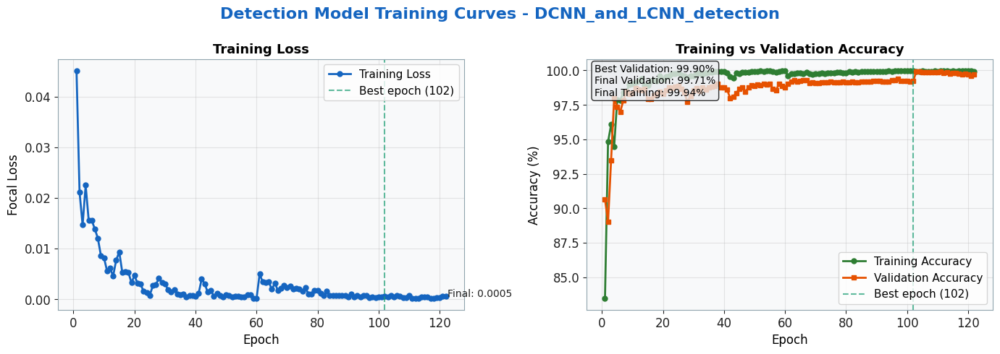


Generating Localization Training Curves
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/localization_training_curves_DCNN_and_LCNN_localization.png


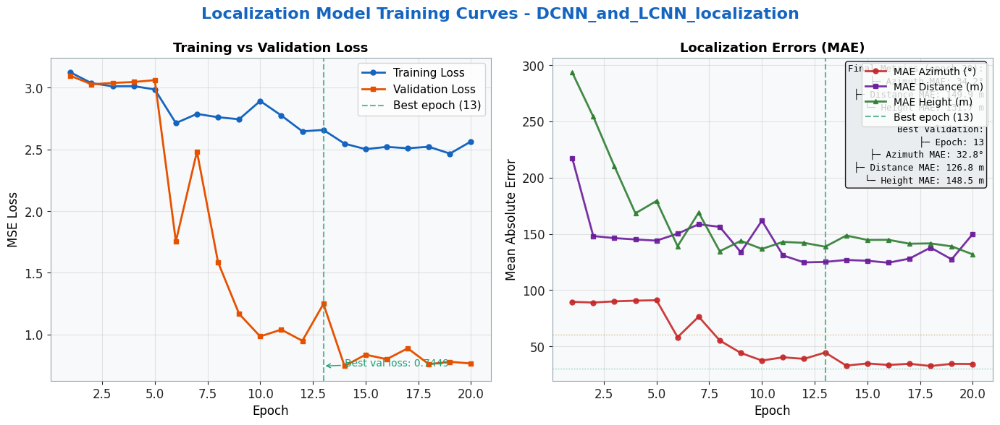


✅ Both training curve figures generated successfully!
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/detection_training_curves_DCNN.png


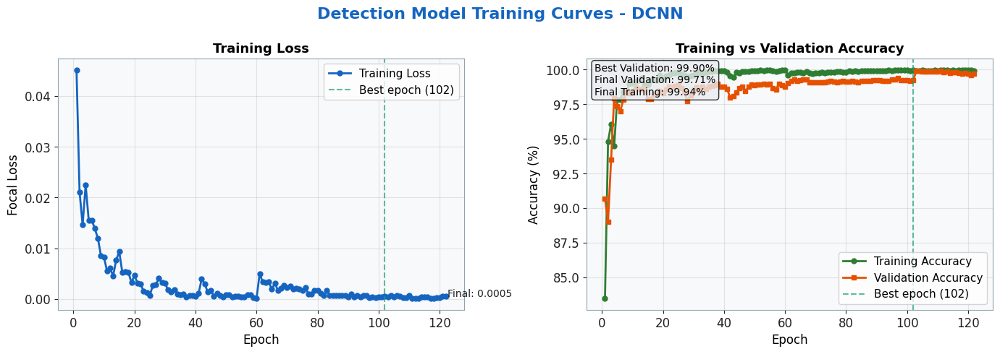

💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/localization_training_curves_LCNN.png


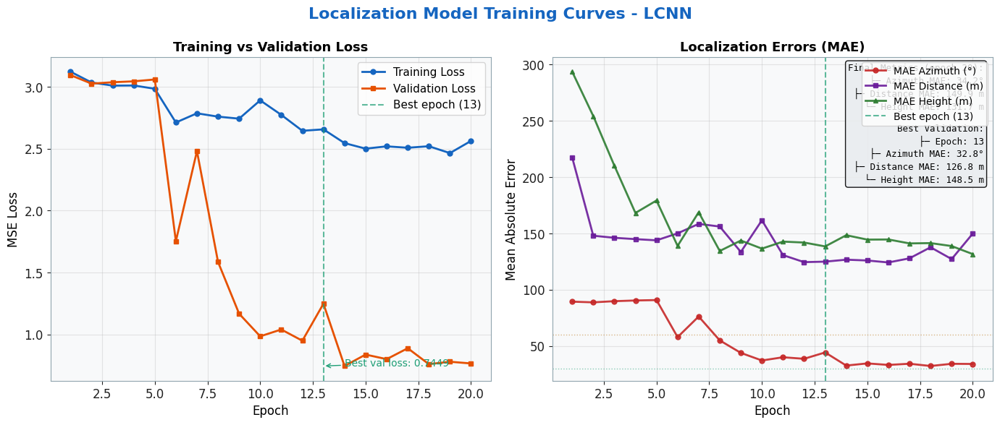

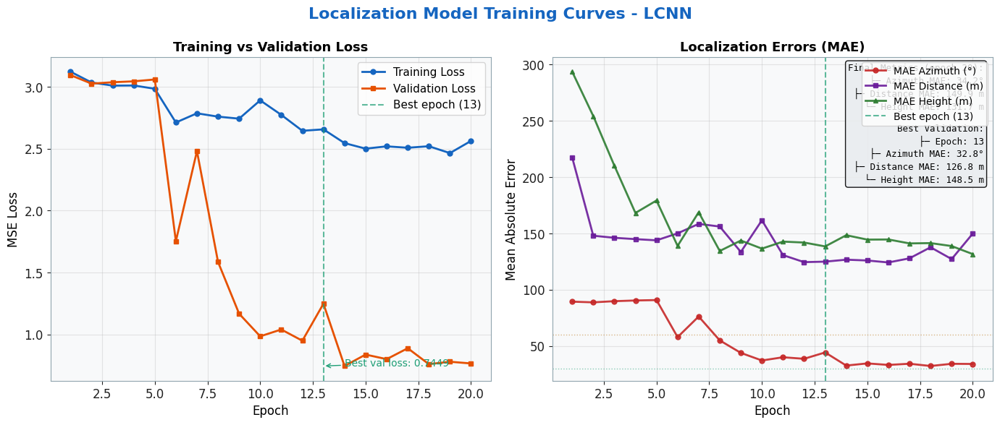

In [70]:
# Plotting training logs
from drone_detection import config, plot_training_curves_separate,plot_detection_training_curves, plot_localization_training_curves

# Method 1: Generate separate figures for detection and localization
plot_training_curves_separate(config, save=True, file_name="DCNN_and_LCNN")

# Method 2: Generate only detection curves
plot_detection_training_curves(config, save=True, file_name="DCNN")

# Method 3: Generate only localization curves
plot_localization_training_curves(config, save=True, file_name="LCNN")

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  STAGE 1 — Detection Model
ℹ️  [1/3] Skipping built-in dataset download.
ℹ️  [2/3] Skipping external audio scraping.

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 652

📊 Combined dataset audit (pre-mix):
   train/drone       total=3142  builtin= 932  custom= 510  mixed=1700
   train/non_drone   total=7362  builtin=7265  custom=  97  mixed=   0
   val  /drone       total= 526  builtin= 200  custom=  26  mixed= 300
   val  /non_drone   total=1598  builtin=1558  custom=  40  mixed=   0
   test /drone       total= 215  builtin= 200  custom=  15  mixed=   0
   test /non_drone   total=1569  builtin=1556  custom=  13  mixed=   0

   ✅ Total drone=3883  non_drone=10529  combined=14412
✅ Mixed drone audio already

Mel cache:   0%|          | 0/14412 [00:00<?, ?it/s]

✅ Mel cache built (14412 new files).
🔬 Injecting 127 synthetic drone tensors …


  0%|          | 0/127 [00:00<?, ?it/s]

✅ Synthetic injection done.

📊 MEL CACHE CLASS BALANCE
  train/drone                     3269
  train/non_drone                 7362
  val/drone                        526
  val/non_drone                   1598
  test/drone                       215
  test/non_drone                  1569

   📋 Resumed log from detection_log.csv (87 existing rows)
▶️  Resuming detection from epoch 88
   📅 Scheduler state restored.


Det ep 88:   0%|          | 0/333 [00:00<?, ?it/s]

... (25 outputs left out)

Det ep 101:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep 101 | tr=0.0005 acc=99.9%  val_f1=0.9840  thr=0.950  lr=1.54e-04


Det ep 102:   0%|          | 0/333 [00:00<?, ?it/s]

  Det Ep 102 | tr=0.0005 acc=100.0%  val_f1=0.9849  thr=0.950  lr=1.61e-04

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.9350
  accuracy    : 0.9955
  precision   : 0.9859
  recall      : 0.9767
  f1          : 0.9813
  auroc       : 0.9998
  auprc       : 0.9989
              precision    recall  f1-score   support

   non_drone     0.9968    0.9981    0.9975      1569
       drone     0.9859    0.9767    0.9813       215

    accuracy                         0.9955      1784
   macro avg     0.9914    0.9874    0.9894      1784
weighted avg     0.9955    0.9955    0.9955      1784

[[1566    3]
 [   5  210]]
💾 Saved: /content/drive/MyDrive/drone_v15/logs/training_curves.png


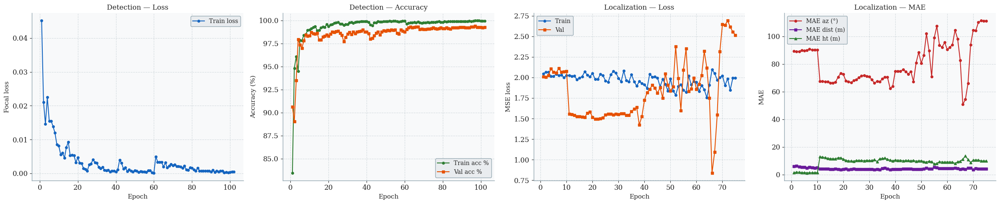

In [ ]:
# Training with Dunakeszi train dataset and configuration
config.set_array_geometry('gp2')
train_detection(
  cfg=config,
  epochs=15,
  resume=True,
  force_rebuild_cache=True,
  force_regen_mixed_audio=False,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=False,
  download_builtin_detection_dataset=False,
  download_external_audio=False
)
# Plotting training logs
from drone_detection.visualization import plot_training_logs
plot_training_logs(config)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
⚠️  Builtin dataset incomplete — downloading …
📥 Downloading DroneAudioDataset …
📦 Extracting …
✅ Detection dataset processed
ℹ️  [2/3] Skipping external audio scraping.

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 0

📊 Combined dataset audit (pre-mix):
   train/drone       total= 932  builtin= 932  custom=   0  mixed=   0
   train/non_drone   total=7260  builtin=7260  custom=   0  mixed=   0
   val  /drone       total= 200  builtin= 200  custom=   0  mixed=   0
   val  /non_drone   total=1556  builtin=1556  custom=   0  mixed=   0
   test /drone       total= 200  builtin= 200  custom=   0  mixed=   0
   test /non_drone   total=1556  builti

Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).

📊 Detection WAV split counts
   train / drone     : 2632
   train / non_drone : 7260
   val   / drone     : 500
   val   / non_drone : 1556
   test  / drone     : 200
   test  / non_drone : 1556
🎵 Building mel cache from processed WAVs…


Mel cache:   0%|          | 0/13704 [00:00<?, ?it/s]

✅ Mel cache built (13704 new files).
🔬 Injecting 500 synthetic drone tensors …


  0%|          | 0/500 [00:00<?, ?it/s]

... (17 outputs left out)

Det ep 111:   0%|          | 0/325 [00:00<?, ?it/s]

  Det Ep 111 | tr=0.0002 acc=100.0%  val_f1=0.9980  thr=0.175  lr=2.19e-04


Det ep 112:   0%|          | 0/325 [00:00<?, ?it/s]

  Det Ep 112 | tr=0.0002 acc=100.0%  val_f1=0.9960  thr=0.050  lr=2.25e-04

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.1000
  accuracy    : 0.9989
  precision   : 0.9950
  recall      : 0.9950
  f1          : 0.9950
  auroc       : 1.0000
  auprc       : 0.9999
              precision    recall  f1-score   support

   non_drone     0.9994    0.9994    0.9994      1556
       drone     0.9950    0.9950    0.9950       200

    accuracy                         0.9989      1756
   macro avg     0.9972    0.9972    0.9972      1756
weighted avg     0.9989    0.9989    0.9989      1756

[[1555    1]
 [   1  199]]
💾 Saved: /content/drive/MyDrive/drone_v15/logs/training_curves.png


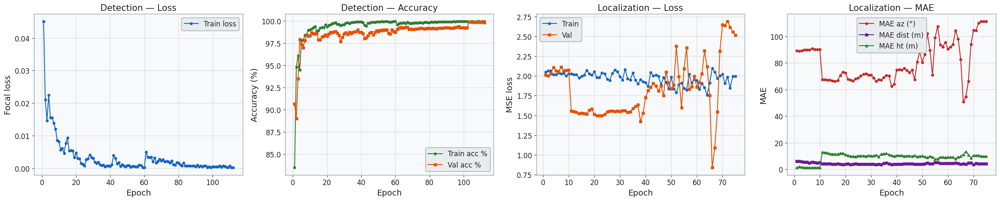

In [ ]:
# Training with Dunakeszi train dataset and configuration
config.set_array_geometry('gp2')
train_detection(
  cfg=config,
  epochs=10,
  resume=True,
  force_rebuild_cache=True,
  force_regen_mixed_audio=True,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=False,
  download_builtin_detection_dataset=True,
  download_external_audio=False
)
# Plotting training logs
from drone_detection.visualization import plot_training_logs
plot_training_logs(config)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
✅ Detection dataset ready — builtin=11704  total=13704
ℹ️  [2/3] Skipping external audio scraping.

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 0

📊 Combined dataset audit (pre-mix):
   train/drone       total=2632  builtin= 932  custom=   0  mixed=1700
   train/non_drone   total=7260  builtin=7260  custom=   0  mixed=   0
   val  /drone       total= 500  builtin= 200  custom=   0  mixed= 300
   val  /non_drone   total=1556  builtin=1556  custom=   0  mixed=   0
   test /drone       total= 200  builtin= 200  custom=   0  mixed=   0
   test /non_drone   total=1556  builtin=1556  custom=   0  mixed=   0

   ✅ Total drone=3332  non_drone=10372

Mixing drone+background:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ Mixed drone generation complete (2000 files).

📊 Detection WAV split counts
   train / drone     : 2632
   train / non_drone : 7260
   val   / drone     : 500
   val   / non_drone : 1556
   test  / drone     : 200
   test  / non_drone : 1556
🎵 Building mel cache from processed WAVs…


Mel cache:   0%|          | 0/13704 [00:00<?, ?it/s]

✅ Mel cache built (13704 new files).
🔬 Injecting 500 synthetic drone tensors …


  0%|          | 0/500 [00:00<?, ?it/s]

... (17 outputs left out)

Det ep 121:   0%|          | 0/325 [00:00<?, ?it/s]

  Det Ep 121 | tr=0.0005 acc=100.0%  val_f1=0.9920  thr=0.050  lr=2.70e-04


Det ep 122:   0%|          | 0/325 [00:00<?, ?it/s]

  Det Ep 122 | tr=0.0005 acc=99.9%  val_f1=0.9940  thr=0.090  lr=2.74e-04

🎯 Final detection test:

=== Detection report ===
  threshold   : 0.0550
  accuracy    : 0.9983
  precision   : 0.9900
  recall      : 0.9950
  f1          : 0.9925
  auroc       : 1.0000
  auprc       : 0.9997
              precision    recall  f1-score   support

   non_drone     0.9994    0.9987    0.9990      1556
       drone     0.9900    0.9950    0.9925       200

    accuracy                         0.9983      1756
   macro avg     0.9947    0.9969    0.9958      1756
weighted avg     0.9983    0.9983    0.9983      1756

[[1554    2]
 [   1  199]]
💾 Saved: /content/drive/MyDrive/drone_v15/logs/training_curves.png


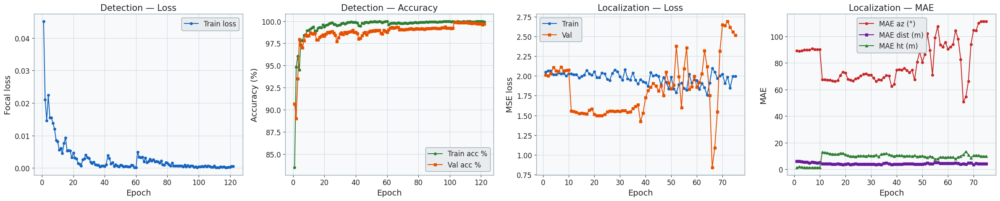

In [ ]:
# Training with Dunakeszi train dataset and configuration
config.set_array_geometry('gp2')
train_detection(
  cfg=config,
  epochs=10,
  resume=True,
  force_rebuild_cache=True,
  force_regen_mixed_audio=True,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=False,
  download_builtin_detection_dataset=True,
  download_external_audio=False
)
# Plotting training logs
from drone_detection.visualization import plot_training_logs
plot_training_logs(config)

In [ ]:
# checks whether TDOA / GCC-PHAT timing estimation is working correctly on synthetic signals

ok = verify_tdoa_accuracy()
print("TDOA check passed:", ok)

  TDOA ACCURACY VERIFICATION
  [1.0, 0.8]       expected=     +4.2479ms  measured=      -0.0004ms  err= 4.2483ms  ❌
  [2.0, 0.5]       expected=     +3.4912ms  measured=      +0.0008ms  err= 3.4903ms  ❌
  [-1.5, 2.0]      expected=     +3.8127ms  measured=      +0.0003ms  err= 3.8124ms  ❌
  [0.3, 0.2]       expected=     +1.0666ms  measured=      +0.0004ms  err= 1.0662ms  ❌

  ❌ Some failed — check _fractional_delay()
TDOA check passed: False


In [ ]:
# It checks:

# whether the remote archive is reachable
# whether label files exist
# whether label parsing works

diagnose_uavirbase(config, n_probe=5)

🔍 Diagnosing UaVirBASE archive …
   URL: https://zenodo.org/records/15391924/files/Microphone_array.zip?download=1

   Total entries: 397
   Audio files : 132
   Label files : 132

   Probing first 5 label files …

   Microphone_array/20241115_093128/label.json
     Result : ❌ PARSE FAILED
     Raw    : b'{\n    "audio_interface_name": "Behringer UMC1820",\n    "start_recording_time": "2024-11-15 09:31:28.676",\n    "end_recording_time": "2024-11-15 09:32:28.773",\n    "additional_info": "",\n    "weather_data": {\n        "timestamp": "2024-11-15T10:30:15.601000+00:00",\n        "measurements": {\n         '

   Microphone_array/20241115_093611/label.json
     Result : ✅ az=0.0°  dist=20.00m  ht=20.00m

   Microphone_array/20241115_093711/label.json
     Result : ✅ az=0.0°  dist=20.00m  ht=20.00m

   Microphone_array/20241115_093804/label.json
     Result : ✅ az=0.0°  dist=20.00m  ht=20.00m

   Microphone_array/20241115_093858/label.json
     Result : ✅ az=0.0°  dist=20.00m  ht=20.00m

In [ ]:
# 1st Train localization model

train_localization(
  cfg=config,
  epochs=3,
  use_synthetic_fallback=True,
  resume=False,
)

  STAGE 2 — Localization Model (UaVirBASE)
📥 Partial download: 2000 sessions via remotezip …
   Reading remote ZIP central directory …
   Candidate paired sessions: 132
   Validating labels …


Validating:   0%|          | 0/132 [00:00<?, ?it/s]

   Usable: 128 | Ambient skipped: 4 | Failed: 0

📐 Position-grouped split (32 unique positions):
   train:  80 sessions | 20 positions
   val  :  24 sessions |  6 positions
   test :  24 sessions |  6 positions


Downloading:   0%|          | 0/128 [00:00<?, ?it/s]


✅ Downloaded 128 sessions (0 failed)
   train: 80 sessions
   val: 24 sessions
   test: 24 sessions
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 100 synthetic = 180 total
   📋 New log: /content/drive/MyDrive/drone_v15/logs/localization_log.csv


Loc train ep 1:   0%|          | 0/5 [00:00<?, ?it/s]

... (6 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep   3 | tr=1.91175  val=2.44818  az=111.54°  dist=8.685m  ht=11.373m  lr=3.00e-04
💾 Saved latest_localization.pth (ep=3, val_loss=2.44818)

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=2.55201  MAE az=113.08°  dist=11.873m  ht=11.402m


In [ ]:
# 2nd Train localization model

train_localization(
  cfg=config,
  epochs=12,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 100 synthetic = 180 total
   📋 Resumed log from localization_log.csv (3 existing rows)
▶️  Resuming localization from epoch 4 (best: 2.39268)


Loc train ep 4:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep   4 | tr=1.58813  val=2.39860  az=112.18°  dist=6.242m  ht=9.543m  lr=2.00e-04
💾 Saved latest_localization.pth (ep=4, val_loss=2.39860)


Loc train ep 5:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  15 | tr=1.56986  val=1.99721  az=87.59°  dist=5.396m  ht=4.777m  lr=1.50e-05
💾 Saved latest_localization.pth (ep=15, val_loss=1.99721)

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.53363  MAE az=75.97°  dist=5.115m  ht=5.075m


In [ ]:
# 3rd Train localization model

train_localization(
  cfg=config,
  epochs=15,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 100 synthetic = 180 total
   📋 Resumed log from localization_log.csv (15 existing rows)
▶️  Resuming localization from epoch 16 (best: 1.86491)


Loc train ep 16:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  16 | tr=1.28511  val=2.04486  az=89.72°  dist=5.003m  ht=5.569m  lr=2.00e-04
💾 Saved latest_localization.pth (ep=16, val_loss=2.04486)


Loc train ep 17:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (38 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  30 | tr=1.40593  val=1.99965  az=86.72°  dist=4.711m  ht=5.262m  lr=1.50e-05
💾 Saved latest_localization.pth (ep=30, val_loss=1.99965)

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.59046  MAE az=80.84°  dist=5.178m  ht=4.880m


In [ ]:
# 4th Train localization model

train_localization(
  cfg=config,
  epochs=10,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 100 synthetic = 180 total
   📋 Resumed log from localization_log.csv (30 existing rows)
▶️  Resuming localization from epoch 31 (best: 1.57768)


Loc train ep 31:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  31 | tr=1.06571  val=2.02829  az=88.64°  dist=4.267m  ht=5.479m  lr=2.00e-04
💾 Saved latest_localization.pth (ep=31, val_loss=2.02829)


Loc train ep 32:   0%|          | 0/5 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (23 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  40 | tr=1.27719  val=1.68844  az=78.82°  dist=4.906m  ht=4.927m  lr=1.50e-05
💾 Saved latest_localization.pth (ep=40, val_loss=1.68844)

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.52650  MAE az=81.11°  dist=4.566m  ht=4.644m


💾 Saved: /content/drive/MyDrive/drone_v15/logs/training_curves.png


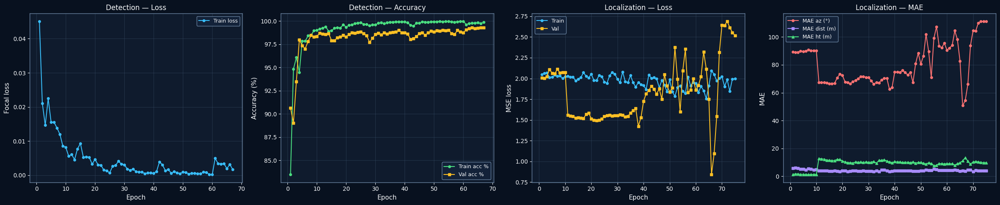

In [ ]:
# Plotting training logs
from drone_detection.visualization import plot_training_logs
plot_training_logs(config)

In [ ]:
# It audits the processed labels already written into: config.PROCESSED_DIR / "localization"

audit_localization_labels(config)

  Sessions : 128
  Azimuth  : min=0.0°  max=315.0°  mean=157.5°  std=103.1°
  Distance : min=10.00m  max=20.00m  mean=15.00m
  Height   : min=10.00m  max=20.00m  mean=15.00m
  ⚠️  128/128 sessions have integer distance — possible placeholders


In [ ]:
# Or train both together

train_all(
  cfg=config,
  det_epochs=3,
  loc_epochs=3,
  use_synthetic_loc=True,
  resume=True,
  force_rebuild_cache=True,
  custom_builder_root=root,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=True,
)

  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
✅ Detection dataset ready — builtin=11709  total=13610

🌐 [2/3] External audio scraping …
✅ Scraped audio already present (5 files) — skipping.
   ✅ non_drone: 0 added, 5 skipped, 0 failed  (5 source files)

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 802

📊 Combined dataset audit (pre-mix):
   train/drone       total=2462  builtin= 932  custom= 510  mixed=1020
   train/non_drone   total=7361  builtin=7264  custom=  97  mixed=   0
   val  /drone       total= 406  builtin= 200  custom=  26  mixed= 180
   val  /non_drone   total=1597  builtin=1557  custom=  40  mixed=   0
   test /drone       total= 215  builtin= 200  custom=  15  mixed=   0
   test /non_drone   total=1569  builtin=1556  cus

Loc ep 11:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  11 | tr=2.02770  val=1.55666  az=67.40°  dist=3.985m  ht=12.808m  lr=1.50e-05
   ✨ New best!


Loc ep 12:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  13 | tr=2.01905  val=1.54112  az=67.28°  dist=4.034m  ht=12.276m  lr=5.67e-05
   ✨ New best!

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.55834  MAE az=67.50°  dist=6.132m  ht=12.344m

✅ Both models trained.


In [ ]:
# Or train both together

train_all(
  cfg=config,
  det_epochs=7,
  loc_epochs=7,
  use_synthetic_loc=True,
  resume=True,
  force_rebuild_cache=True,
  custom_builder_root=root,
  use_custom_builder=True,
  import_custom_backgrounds_as_non_drone=True,
  download_builtin_detection_dataset=True,
  download_external_audio=True,
)

  STAGE 1 — Detection Model

📥 [1/3] Builtin DroneAudioDataset …
✅ Detection dataset ready — builtin=11709  total=13610

🌐 [2/3] External audio scraping …
✅ Scraped audio already present (5 files) — skipping.
   ✅ non_drone: 0 added, 5 skipped, 0 failed  (5 source files)

📦 [3/3] Custom builder dataset …
📦 Custom builder import summary:
   train_added             : 0
   val_added               : 0
   test_added              : 0
   clean_imported          : 0
   background_imported     : 0
   failed                  : 0
   skipped                 : 802

📊 Combined dataset audit (pre-mix):
   train/drone       total=2462  builtin= 932  custom= 510  mixed=1020
   train/non_drone   total=7361  builtin=7264  custom=  97  mixed=   0
   val  /drone       total= 406  builtin= 200  custom=  26  mixed= 180
   val  /non_drone   total=1597  builtin=1557  custom=  40  mixed=   0
   test /drone       total= 215  builtin= 200  custom=  15  mixed=   0
   test /non_drone   total=1569  builtin=1556  cus

Mel cache:   0%|          | 0/13610 [00:00<?, ?it/s]

✅ Mel cache built (13610 new files).
🔬 Injecting 127 synthetic drone tensors …


  0%|          | 0/127 [00:00<?, ?it/s]

✅ Synthetic injection done.

📊 MEL CACHE CLASS BALANCE
  train/drone                     2589
  train/non_drone                 7361
  val/drone                        406
  val/non_drone                   1597
  test/drone                       215
  test/non_drone                  1569

   📋 Resumed log from detection_log.csv (60 existing rows)
▶️  Resuming detection from epoch 61


Det ep 61:   0%|          | 0/311 [00:00<?, ?it/s]

... (32 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  20 | tr=2.05158  val=1.51514  az=72.53°  dist=3.938m  ht=11.061m  lr=2.89e-04
   ✨ New best!

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.53777  MAE az=73.25°  dist=6.121m  ht=11.048m

✅ Both models trained.


In [ ]:
# Thesis Dataset Figures
result = build_thesis_figures(
  cfg          = config,
  dataset_root = "/content/drive/MyDrive/custom_drone_dataset",
  out_figures  = "/content/drive/MyDrive/custom_drone_dataset/thesis_figures",
  bpf_hz       = 82.0,
  pre_counts   = {
    "train": {
      "drone":     {"builtin": 932,  "custom": 510, "mixed": 1020, "total": 2462},
      "non_drone": {"builtin": 7264, "custom": 97,               "total": 7361},
    },
    "val": {
      "drone":     {"builtin": 200,  "custom": 26,  "mixed": 180,  "total": 406},
      "non_drone": {"builtin": 1557, "custom": 40,               "total": 1597},
    },
    "test": {
      "drone":     {"builtin": 200,  "custom": 15,               "total": 215},
      "non_drone": {"builtin": 1556, "custom": 13,               "total": 1569},
    },
  },
)

📊 Detection counts (post-augmentation):
   train/drone: {'builtin': 932, 'custom': 510, 'mixed': 1700, 'total': 3142}
   train/non_drone: {'builtin': 7265, 'custom': 97, 'total': 7362}
   val/drone: {'builtin': 200, 'custom': 26, 'mixed': 300, 'total': 526}
   val/non_drone: {'builtin': 1558, 'custom': 40, 'total': 1598}
   test/drone: {'builtin': 200, 'custom': 15, 'total': 215}
   test/non_drone: {'builtin': 1556, 'custom': 13, 'total': 1569}

🎵 Mel cache …
✅ Mel cache already exists (14539 files) — skipping.
✅ Synthetic detection cache already present (127 files) — skipping.
   {'train/drone': 3269, 'train/non_drone': 7362, 'val/drone': 526, 'val/non_drone': 1598, 'test/drone': 215, 'test/non_drone': 1569}

📍 Localization pipeline …

  STAGE 2 — Localization Dataset

📥 UaVirBASE download + label parse …
✅ Localization dataset ready (128 sessions)

🔬 Building SyntheticLocDatasetV2  train=2000  val=400  …
  Real UaVirBASE: train=80  val=24  test=24

  Total localization: train=2080  v

In [ ]:
train_localization(
  config,
  reset_best=True,   # clears the old best checkpoint
  resume=False,      # start from scratch, not epoch 41
  epochs=10,
)

  STAGE 2 — Localization Model (UaVirBASE)
📥 Partial download: 2000 sessions via remotezip …
   Reading remote ZIP central directory …
   Candidate paired sessions: 132
   Validating labels …


Validating:   0%|          | 0/132 [00:00<?, ?it/s]

   Usable: 128 | Ambient skipped: 3 | Failed: 1

📐 Position-grouped split (32 unique positions):
   train:  80 sessions | 20 positions
   val  :  24 sessions |  6 positions
   test :  24 sessions |  6 positions
⚠️  Partial download failed (429 Client Error: TOO MANY REQUESTS for url: https://zenodo.org/records/15391924/files/Microphone_array.zip?download=1) → synthetic fallback.
🔬 Generating 2400 synthetic localization samples …


Synthetic loc:   0%|          | 0/2400 [00:00<?, ?it/s]

✅ Synthetic fallback: 2400 sessions written.
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 1680 real + 500 synthetic = 2180 total
   📋 New log: /content/drive/MyDrive/drone_v15/logs/localization_log.csv


Loc ep 1:   0%|          | 0/68 [00:00<?, ?it/s]

... (27 outputs left out)

Loc eval:   0%|          | 0/12 [00:00<?, ?it/s]

  Loc Ep  10 | tr=2.02516  val=2.07444  az=90.19°  dist=4.946m  ht=1.387m  lr=2.58e-05

🎯 Final localization test:


Loc eval:   0%|          | 0/12 [00:00<?, ?it/s]

  Val loss=2.04173  MAE az=89.77°  dist=4.976m  ht=1.383m


In [ ]:
# 7th Train localization model

train_localization(
  cfg=config,
  epochs=15,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
📥 Partial download: 2000 sessions via remotezip …
   Reading remote ZIP central directory …
   Candidate paired sessions: 132
   Validating labels …


Validating:   0%|          | 0/132 [00:00<?, ?it/s]

   Usable: 128 | Ambient skipped: 4 | Failed: 0

📐 Position-grouped split (32 unique positions):
   train:  80 sessions | 20 positions
   val  :  24 sessions |  6 positions
   test :  24 sessions |  6 positions


Downloading:   0%|          | 0/128 [00:00<?, ?it/s]


✅ Downloaded 128 sessions (0 failed)
   train: 80 sessions
   val: 24 sessions
   test: 24 sessions
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 500 synthetic = 580 total
   📋 Resumed log from localization_log.csv (20 existing rows)
▶️  Resuming from epoch 21 (best: 1.51514)
   📅 Scheduler state restored.


Loc ep 21:   0%|          | 0/18 [00:00<?, ?it/s]

... (42 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  35 | tr=2.03654  val=1.58579  az=69.16°  dist=4.491m  ht=11.552m  lr=3.00e-04

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.54723  MAE az=69.35°  dist=7.709m  ht=11.461m


In [ ]:
# 7th Train localization model

train_localization(
  cfg=config,
  epochs=15,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 500 synthetic = 580 total
   📋 Resumed log from localization_log.csv (35 existing rows)
▶️  Resuming from epoch 36 (best: 1.49507)
   📅 Scheduler state restored.


Loc ep 36:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  36 | tr=1.94987  val=1.61622  az=70.49°  dist=4.756m  ht=11.864m  lr=2.89e-04


Loc ep 37:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (38 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  50 | tr=1.98495  val=1.83763  az=80.53°  dist=3.914m  ht=9.977m  lr=2.89e-04

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=1.95749  MAE az=83.61°  dist=6.658m  ht=9.754m


In [ ]:
# 7th Train localization model

train_localization(
  cfg=config,
  epochs=25,
  use_synthetic_fallback=True,
  resume=True,
)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 500 synthetic = 580 total
   📋 Resumed log from localization_log.csv (50 existing rows)
▶️  Resuming from epoch 51 (best: 1.42326)
   📅 Scheduler state restored.


Loc ep 51:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  51 | tr=1.83877  val=1.88640  az=86.34°  dist=4.072m  ht=9.405m  lr=3.00e-04


Loc ep 52:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (68 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  75 | tr=1.99680  val=2.51550  az=111.16°  dist=4.148m  ht=9.838m  lr=1.50e-05

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=2.58652  MAE az=96.05°  dist=6.239m  ht=9.972m


In [ ]:
# 7th Train localization model

train_localization(
  cfg=config,
  epochs=25,
  use_synthetic_fallback=True,
  resume=True,
)
train_localization(config, epochs=20, resume=False)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 80 real + 500 synthetic = 580 total
   📋 Resumed log from localization_log.csv (50 existing rows)
▶️  Resuming from epoch 51 (best: 1.42326)
   📅 Scheduler state restored.


Loc ep 51:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  51 | tr=1.83877  val=1.88640  az=86.34°  dist=4.072m  ht=9.405m  lr=3.00e-04


Loc ep 52:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (68 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  75 | tr=1.99680  val=2.51550  az=111.16°  dist=4.148m  ht=9.838m  lr=1.50e-05

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=2.58652  MAE az=96.05°  dist=6.239m  ht=9.972m


In [ ]:
# 01/05/2026 Train localization model

train_localization(config, epochs=20, use_synthetic_fallback=False, resume=False)

  STAGE 2 — Localization Model (UaVirBASE)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 88 real + 500 synthetic = 588 total
   📋 New log: /home/tildai/Desktop/Development/drone-detection-api/deployment/v2/logs/localization_log.csv
   📅 Scheduler state restored.


Loc ep 1:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep   1 | tr=3.07580  val=3.05563  az=92.02°  dist=5.176m  ht=17.350m  lr=2.58e-05
   ✨ New best!


Loc ep 2:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (53 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  20 | tr=2.94584  val=2.79398  az=84.06°  dist=27.347m  ht=7.598m  lr=1.57e-04

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=2.88239  MAE az=89.81°  dist=27.878m  ht=9.030m


In [ ]:
# 01/05/2026 Train localization model

train_localization(config, epochs=20, use_synthetic_fallback=False, resume=True)

  STAGE 2 — Localization Model (UaVirBASE)
✅ Localization dataset ready (128 sessions)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 88 real + 500 synthetic = 588 total
   📋 Resumed log from localization_log.csv (20 existing rows)
▶️  Resuming from epoch 21 (best: 2.51611)
   📅 Scheduler state restored.


Loc ep 21:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  21 | tr=2.93181  val=2.87901  az=86.11°  dist=26.026m  ht=13.922m  lr=2.12e-04


Loc ep 22:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep  28 | tr=2.88892  val=2.93493  az=86.67°  dist=21.501m  ht=5.875m  lr=1.57e-04


Loc ep 29:   0%|          | 0/18 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# 01/05/2026 Train localization model

shutil.rmtree(config.PROCESSED_DIR / "localization", ignore_errors=True)
train_localization(config, epochs=5, resume=False)

  STAGE 2 — Localization Model (UaVirBASE)
📂 Using local dataset at /data_extra/uavirbase_ssl/Microphone_array (skipping download)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
   📊 Train: 88 real + 500 synthetic = 588 total
   📋 New log: /home/tildai/Desktop/Development/drone-detection-api/deployment/v2/logs/localization_log.csv
   📅 Scheduler state restored.


Loc ep 1:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep   1 | tr=3.12319  val=3.09564  az=89.51°  dist=7.249m  ht=9.788m  lr=1.03e-04
   ✨ New best!


Loc ep 2:   0%|          | 0/18 [00:00<?, ?it/s]

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Loc Ep   5 | tr=2.98538  val=3.06045  az=90.93°  dist=4.798m  ht=5.976m  lr=2.58e-05

🎯 Final localization test:


Loc eval:   0%|          | 0/1 [00:00<?, ?it/s]

  Val loss=3.19397  MAE az=96.30°  dist=4.881m  ht=7.737m


In [ ]:
import librosa
import numpy as np
from pathlib import Path

# Pick one real session
sample_session = next(Path("/data_extra/uavirbase_ssl/Microphone_array").iterdir())
wav = sample_session / "output.wav"

# Load WITHOUT resampling to see native format
y_native, sr_native = librosa.load(str(wav), sr=None, mono=False)
print(f"Native shape : {y_native.shape}  (channels x samples)")
print(f"Native SR    : {sr_native} Hz")
print(f"Duration     : {y_native.shape[-1]/sr_native:.1f}s")

# Now load the way the pipeline does it
from drone_detection.audio_processing import AudioProcessor
from drone_detection import config

ap = AudioProcessor(config)
channels = ap.load_channels(str(wav), channel_indices=[0, 1, 3])
print(f"\nAfter load_channels([0,1,3]): {len(channels)} arrays, each {len(channels[0])} samples at {config.SR}Hz")

# Check if channels are actually different (not mono repeated)
ch0, ch1, ch2 = channels
corr_01 = float(np.corrcoef(ch0, ch1)[0,1])
corr_02 = float(np.corrcoef(ch0, ch2)[0,1])
print(f"\nCorrelation ch0-ch1: {corr_01:.6f}  (1.0 = identical = PROBLEM)")
print(f"Correlation ch0-ch2: {corr_02:.6f}  (1.0 = identical = PROBLEM)")

# Compute the actual ITDs
from drone_detection.utils import compute_ipd_features
ipd = compute_ipd_features(channels, config)
print(f"\nIPD values (tau in seconds): {ipd}")
print(f"IPD in samples @ {config.SR}Hz: {ipd * config.SR}")
print(f"Expected for az=225°, dist=10m: tau(0,1)≈0ms, tau(0,2)≈7ms, tau(1,2)≈7ms")

Native shape : (8, 3840000)  (channels x samples)
Native SR    : 96000 Hz
Duration     : 40.0s

After load_channels([0,1,3]): 3 arrays, each 882000 samples at 22050Hz

Correlation ch0-ch1: 0.009260  (1.0 = identical = PROBLEM)
Correlation ch0-ch2: 0.014910  (1.0 = identical = PROBLEM)

IPD values (tau in seconds): [-0.00521542 -0.00072562 -0.00049887]
IPD in samples @ 22050Hz: [-115.  -16.  -11.]
Expected for az=225°, dist=10m: tau(0,1)≈0ms, tau(0,2)≈7ms, tau(1,2)≈7ms


In [ ]:
import shutil
shutil.rmtree(config.PROCESSED_DIR / "localization", ignore_errors=True)
train_localization(config, epochs=5, resume=False)

  STAGE 2 — Localization Model (UaVirBASE)
⚠️  Full download failed (File is not a zip file) → synthetic fallback.
🔬 Generating 2400 synthetic localization samples …


Synthetic loc:   0%|          | 0/2400 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import os
from pathlib import Path
base = "/media/tildai/fe4de714-8030-4137-9cba-cfb0203d58f7/uavirbase_ssl"
labels = list(Path(base).rglob("label.json"))
print(f"Total sessions found: {len(labels)}")
# also check how many were ambient (skipped)
from drone_detection.datasets import parse_label_json
skipped = sum(1 for l in labels if parse_label_json(l.read_bytes()) is None)
print(f"Skipped (ambient/unparseable): {skipped}")
print(f"Usable: {len(labels) - skipped}")
print(labels[0].read_text())

Total sessions found: 132
Skipped (ambient/unparseable): 4
Usable: 128
{
    "audio_interface_name": "Behringer UMC1820",
    "start_recording_time": "2024-11-15 11:30:31.287",
    "end_recording_time": "2024-11-15 11:31:11.377",
    "additional_info": "",
    "weather_data": {
        "timestamp": "2024-11-15T12:27:06.167000+00:00",
        "measurements": {
            "air temperature": "6 C",
            "air humidity": "88 % RH",
            "light intensity": "17044 Lux",
            "barometric pressure": "100790 Pa",
            "wind direction": "248 degrees",
            "wind speed": "1.1 m/s",
            "rainfall hourly": "0 mm/hour",
            "uv index": 1
        }
    },
    "microphone_array": {
        "center_latitude": "52.25532752777778",
        "center_longitude": "20.90053722222222",
        "microphones": [
            {
                "channel": 1,
                "name": "NTG-2",
                "latitude": "52.25534297880067",
                "longitude

In [ ]:
# Check environment if local use paths
import sys
sys.path.insert(0, "/home/tildai/Desktop/Development/drone-detection-api/deployment/v2")

from pathlib import Path
import shutil
from drone_detection import config
from drone_detection.orchestration import train_localization

# Point to your actual data location
config.UAVIRBASE_RAW = Path("/media/tildai/fe4de714-8030-4137-9cba-cfb0203d58f7/uavirbase_ssl")

# Confirm everything loaded correctly — all three must match
assert config.MAX_LOCALIZATION_DIST == 30.0
assert config.UAVIRBASE_MIC_INDICES == [0, 1, 3]
assert config.UAVIRBASE_FULL == True

# Wipe old processed data (extracted with wrong channels + wrong config)
shutil.rmtree(config.PROCESSED_DIR / "localization", ignore_errors=True)
print("Ready — starting training")

Ready — starting training


In [ ]:
import subprocess

# Find the actual mount point
result = subprocess.run(["lsblk", "-o", "NAME,MOUNTPOINT"], capture_output=True, text=True)
print(result.stdout)

# Also search for the dataset folders directly
result2 = subprocess.run(
    ["find", "/media/tildai", "-name", "label.json", "-maxdepth", "4"],
    capture_output=True, text=True
)
print(result2.stdout[:3000] if result2.stdout else "Nothing found under /media/tildai")

# Check if the drive is mounted somewhere else
result3 = subprocess.run(["df", "-h"], capture_output=True, text=True)
print(result3.stdout)

NAME        MOUNTPOINT
loop0       /snap/bare/5
loop1       /snap/brave/624
loop2       /snap/core22/2411
loop3       /snap/core/17284
loop4       /snap/core20/2769
loop5       /snap/code/234
loop6       /snap/firmware-updater/226
loop7       /snap/docker/3377
loop8       /snap/gnome-42-2204/226
loop9       /snap/code/231
loop10      /snap/gnome-3-28-1804/198
loop11      /snap/core24/1587
loop12      /snap/firmware-updater/224
loop13      /snap/brave/626
loop14      /snap/docker/3505
loop15      /snap/snapd-desktop-integration/361
loop16      /snap/core20/2717
loop17      /snap/core22/2339
loop18      /snap/lxqt-support-core24/9
loop19      /snap/whatsapp-desktop-linux/1
loop20      /snap/pgadmin4/23
loop21      /snap/postman/360
loop22      /snap/snap-store/1367
loop23      /snap/snap-store/1338
loop24      /snap/libreoffice/366
loop25      /snap/lxqt-support-core24/13
loop26      /snap/hunspell-dictionaries/21
loop27      /snap/whatsie/183
loop28      /snap/thunderbird/1040
loop29   

In [ ]:
import subprocess

result = subprocess.run(
    ["find", "/data_extra", "-name", "label.json", "-maxdepth", "4"],
    capture_output=True, text=True
)
print(result.stdout[:3000] if result.stdout else "Nothing found")

/data_extra/uavirbase_ssl/Microphone_array/20241115_113031/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_101304/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_110737/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_094427/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_113451/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_113908/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_102853/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_095305/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_101450/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_120639/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_123958/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_121644/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_123816/label.json
/data_extra/uavirbase_ssl/Microphone_array/20241115_105515/label.json
/data_extra/uavirbas

In [ ]:
import sys, shutil, types
sys.path.insert(0, "/home/tildai/Desktop/Development/drone-detection-api/deployment/v2")

from pathlib import Path
from drone_detection import config
from drone_detection.orchestration import train_localization

# Working directories
base = Path("/home/tildai/Desktop/Development/drone-detection-api/deployment/v2")
config.RAW_DIR       = base / "raw"
config.PROCESSED_DIR = base / "processed"
config.MEL_CACHE_DIR = base / "mel_cache"
config.DRIVE_MODELS  = base / "models"
config.DRIVE_LOGS    = base / "logs"
config.DRIVE_TRACKS  = base / "tracks"
config.DRIVE_PLOTS   = base / "logs" / "plots"
config.DRONEDS_RAW   = base / "droneds"

# Correct path — sessions live inside Microphone_array/
config.UAVIRBASE_RAW = Path("/data_extra/uavirbase_ssl/Microphone_array")

# Patch ensure_dirs to never touch UAVIRBASE_RAW (read-only partition)
def _ensure_dirs_patched(self):
    for p in [self.RAW_DIR, self.PROCESSED_DIR, self.MEL_CACHE_DIR,
              self.DRIVE_MODELS, self.DRIVE_LOGS, self.DRIVE_TRACKS,
              self.DRIVE_PLOTS, self.DRONEDS_RAW]:
        p.mkdir(parents=True, exist_ok=True)

config.ensure_dirs = types.MethodType(_ensure_dirs_patched, config)

# Verify — all four must look correct before continuing
print(f"UAVIRBASE_RAW exists : {config.UAVIRBASE_RAW.exists()}")
print(f"MAX_LOCALIZATION_DIST: {config.MAX_LOCALIZATION_DIST}")
print(f"UAVIRBASE_MIC_INDICES: {config.UAVIRBASE_MIC_INDICES}")
print(f"UAVIRBASE_FULL       : {config.UAVIRBASE_FULL}")

# Count sessions so you can confirm the real data is visible
sessions = list(config.UAVIRBASE_RAW.rglob("label.json"))
print(f"Sessions found       : {len(sessions)}")

UAVIRBASE_RAW exists : True
MAX_LOCALIZATION_DIST: 30.0
UAVIRBASE_MIC_INDICES: [0, 1, 3]
UAVIRBASE_FULL       : True
Sessions found       : 132


In [ ]:
# Generate, then inspect before evaluating
generate_single_drone_dataset(config, "/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip", n_sessions=50)
plot_test_zip_overview("/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip", config, n_sample_sessions=2,
                       save_path="/content/drive/MyDrive/AUS LAB II/test_dataset/plots/inspect_single")
# Saves inspect_single_labels.png, inspect_single_sessions.png, inspect_single_spatial.png

# # Multi-drone ZIP
# generate_multi_drone_dataset(config, "/content/drive/MyDrive/AUS LAB II/test_dataset/test_multi.zip", n_sessions=30)
# plot_test_zip_overview(
#   "/content/drive/MyDrive/AUS LAB II/test_dataset/test_multi.zip",
#   config, n_sample_sessions=2,
#   save_path="/content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_multi"
# )

# # Full scenario suite
# generate_scenario_dataset(config, "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip")
# plot_test_zip_overview(
#   "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip",
#   config, n_sample_sessions=2,
#   save_path="/content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_scenarios"
# )

✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
🔬 Single-drone dataset: 50 sessions  (array=uavirbase, noise=mixed)


  0%|          | 0/50 [00:00<?, ?it/s]

  Wrote: /content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip  (18.2 MB, 50 sessions)
📦 test_single.zip: 50 sessions, 50 labelled
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/inspect_single_labels.png
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/inspect_single_sessions.png
✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/inspect_single_spatial.png


📂 Extracting to temp dir: /tmp/drone_test_f1d2b5en
📦 Loading test dataset from test_single.zip …
✅ Extracted to /tmp/drone_test_f1d2b5en
   ZIP contents (201 files, first 20):
     single_0006_ch2.wav
     single_0036_ch2.wav
     single_0010_ch2.wav
     single_0012_label.json
     single_0007_ch2.wav
     single_0010_ch0.wav
     single_0002_ch1.wav
     single_0025_ch0.wav
     single_0003_ch0.wav
     single_0034_ch2.wav
     single_0013_label.json
     single_0039_ch1.wav
     single_0004_label.json
     single_0012_ch1.wav
     single_0002_label.json
     single_0016_label.json
     single_0023_ch0.wav
     single_0033_label.json
     single_0042_ch0.wav
     single_0030_ch2.wav
     … and 181 more
   Detected format: 'generic_triplet'
   Indexing sessions (format='generic_triplet') …
✅ Indexed 50 sessions  (50 labelled, 0 unlabelled)

  Test dataset evaluation: test_single.zip
  Format: generic_triplet  |  Sessions: 50
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr

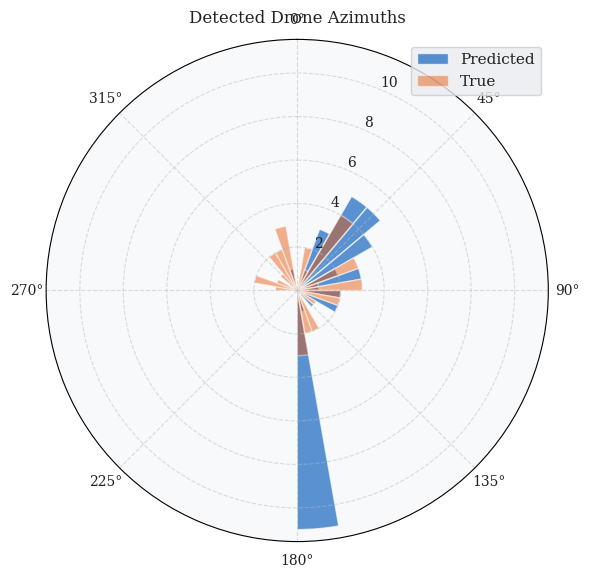

{'sessions': [{'session_id': 'single_0000', 'detected': True, 'probability': 0.8422518750554637, 'az_pred_deg': -88.05541229248047, 'az_true_deg': 129.0953, 'az_err_deg': 142.84928770751952, 'dist_pred_m': 12.658636093139648, 'dist_true_m': 8.0779, 'dist_err_m': 4.580736093139649, 'ht_pred_m': 7.124950408935547, 'ht_true_m': 1.8656, 'ht_err_m': 5.259350408935547, 'cnn_probability': 0.9906753301620483}, {'session_id': 'single_0001', 'detected': True, 'probability': 1.0, 'az_pred_deg': 13.173529624938965, 'az_true_deg': 102.9831, 'az_err_deg': 89.80957037506103, 'dist_pred_m': 6.637673377990723, 'dist_true_m': 1.4678, 'dist_err_m': 5.169873377990722, 'ht_pred_m': 5.772327423095703, 'ht_true_m': 7.0306, 'ht_err_m': 1.2582725769042966, 'cnn_probability': 0.9887949228286743}, {'session_id': 'single_0002', 'detected': True, 'probability': 1.0, 'az_pred_deg': 54.57802963256836, 'az_true_deg': 51.7914, 'az_err_deg': 2.7866296325683493, 'dist_pred_m': 12.674386978149414, 'dist_true_m': 11.7608,

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

# Test uploaded 3-mic files with one function

# Or
# Zip files path
zip_path = "/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip"

# Load the test dataset from the zip file
test_ds = load_test_dataset_zip(
  zip_path,
  cfg=config,
  dataset_format="auto", # Let it auto-detect the format
)

# Run the evaluation on the loaded dataset
results = run_test_dataset_evaluation(
  test_ds,
  config,
  save_csv=zip_path.replace(".zip", "_results.csv") # Save results to a CSV
)

print(results)

📂 Extracting to temp dir: /tmp/drone_test_wb38m1a4
📦 Loading test dataset from test_single.zip …
✅ Extracted to /tmp/drone_test_wb38m1a4
   ZIP contents (201 files, first 20):
     single_0013_label.json
     single_0034_ch0.wav
     single_0006_ch1.wav
     single_0049_ch0.wav
     single_0034_ch2.wav
     single_0008_ch0.wav
     single_0010_ch2.wav
     single_0042_ch1.wav
     single_0005_ch0.wav
     single_0021_ch2.wav
     single_0031_ch2.wav
     single_0039_label.json
     single_0002_ch2.wav
     single_0048_ch1.wav
     single_0043_ch0.wav
     single_0014_ch1.wav
     single_0002_label.json
     single_0046_label.json
     single_0009_ch2.wav
     single_0027_label.json
     … and 181 more
   Detected format: 'generic_triplet'
   Indexing sessions (format='generic_triplet') …
✅ Indexed 50 sessions  (50 labelled, 0 unlabelled)

  Test dataset evaluation: test_single.zip
  Format: generic_triplet  |  Sessions: 50
✅ Detection model loaded  (ep=63, f1=0.9829268292682927, thr=0.

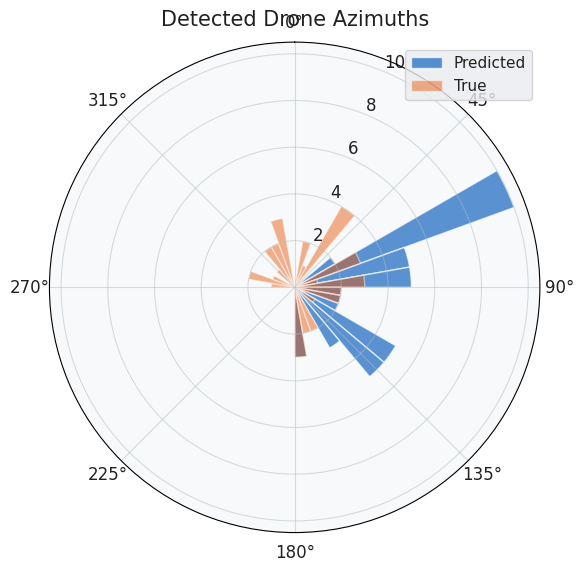

{'sessions': [{'session_id': 'single_0000', 'detected': True, 'probability': 0.8430419843447836, 'az_pred_deg': -18.67008399963379, 'az_true_deg': 129.0953, 'az_err_deg': 147.7653839996338, 'dist_pred_m': 9.118903160095215, 'dist_true_m': 8.0779, 'dist_err_m': 1.0410031600952152, 'ht_pred_m': 3.9243898391723633, 'ht_true_m': 1.8656, 'ht_err_m': 2.0587898391723636, 'cnn_probability': 0.9922547340393066}, {'session_id': 'single_0001', 'detected': True, 'probability': 1.0, 'az_pred_deg': 29.2420597076416, 'az_true_deg': 102.9831, 'az_err_deg': 73.74104029235839, 'dist_pred_m': 13.029214859008789, 'dist_true_m': 1.4678, 'dist_err_m': 11.561414859008789, 'ht_pred_m': 4.3013715744018555, 'ht_true_m': 7.0306, 'ht_err_m': 2.7292284255981443, 'cnn_probability': 0.9913538098335266}, {'session_id': 'single_0002', 'detected': True, 'probability': 1.0, 'az_pred_deg': 28.366989135742188, 'az_true_deg': 51.7914, 'az_err_deg': 23.424410864257823, 'dist_pred_m': 11.664532661437988, 'dist_true_m': 11.76

In [ ]:
# Test 2026/04/28
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

# Test uploaded 3-mic files with one function

# Or
# Zip files path
zip_path = "/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip"

# Load the test dataset from the zip file
test_ds = load_test_dataset_zip(
  zip_path,
  cfg=config,
  dataset_format="auto", # Let it auto-detect the format
)

# Run the evaluation on the loaded dataset
results = run_test_dataset_evaluation(
  test_ds,
  config,
  save_csv=zip_path.replace(".zip", "_results.csv") # Save results to a CSV
)

print(results)

In [ ]:
# Multi-drone ZIP
generate_multi_drone_dataset(config, "/content/drive/MyDrive/AUS LAB II/test_dataset/test_multi.zip", n_sessions=30)
plot_test_zip_overview(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_multi.zip",
  config, n_sample_sessions=2,
  save_path="/content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_multi"
)

✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
🔬 Multi-drone dataset: 30 sessions  (2-3 drones, array=uavirbase)


  0%|          | 0/30 [00:00<?, ?it/s]

  Wrote: /content/drive/MyDrive/AUS LAB II/test_dataset/test_multi.zip  (10.6 MB, 30 sessions)
📦 test_multi.zip: 30 sessions, 30 labelled
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_multi_labels.png
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_multi_sessions.png
✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_multi_spatial.png


In [ ]:
# Full scenario suite
generate_scenario_dataset(config, "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip")
plot_test_zip_overview(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip",
  config, n_sample_sessions=2,
  save_path="/content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_scenarios"
)

🔬 Scenario dataset: 9 scenarios, 165 sessions
✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
  indoor_hover         — Indoor studio, low altitude 1-4 m


  indoor_hover:   0%|          | 0/20 [00:00<?, ?it/s]

✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
  indoor_moving        — Indoor, larger distances and more noise


  indoor_moving:   0%|          | 0/20 [00:00<?, ?it/s]

✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
  outdoor_fly          — Outdoor flight, moderate wind


  outdoor_fly:   0%|          | 0/20 [00:00<?, ?it/s]

... (9 outputs left out)

  gp1_array:   0%|          | 0/20 [00:00<?, ?it/s]

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
  gp2_array            — PannoniaFS GP2 array, 2500 mm baseline


  gp2_array:   0%|          | 0/20 [00:00<?, ?it/s]

  Wrote: /content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip  (60.8 MB, 165 sessions)
📦 test_scenarios.zip: 165 sessions, 165 labelled
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_scenarios_labels.png
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_scenarios_sessions.png
✅ Array geometry set to 'uavirbase'  baseline ≈ 3.440 m
💾 Saved: /content/drive/MyDrive/AUS LAB II/test_dataset/plots/test_scenarios_spatial.png


In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip",
  cfg=config,
  dataset_format="flat_wavs",   # or "uavirbase" / "pannoniafs" / "generic_triplet" / "flat_wavs" - # bypass auto-detect
  max_sessions=10,         # optional — useful for a quick smoke test
)
print(test_ds)  # shows session count and format

results = run_test_dataset_evaluation(test_ds, config, save_csv="/content/drive/MyDrive/AUS LAB II/test_dataset/test_single_dataset_results.csv")

📂 Extracting to temp dir: /tmp/drone_test_ihmaal0r
📦 Loading test dataset from test_single.zip …
✅ Extracted to /tmp/drone_test_ihmaal0r
   Indexing sessions (format='flat_wavs') …
   📋 Loaded 50 labels from labels.csv
✅ Indexed 10 sessions  (0 labelled, 10 unlabelled)
TestDataset(n=10, labelled=0, format='flat_wavs', zip='test_single.zip')

  Test dataset evaluation: test_single.zip
  Format: flat_wavs  |  Sessions: 10
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
session_0000                  YES  1.000  0.990   0.945    -83.8        -       -   13.08       -   7.14
session_0001                  YES  1.000  0.993   0.945    -66.2        -       -   13.26       -   7.24
session_0002                  YES  1.000  0.991   0.833     58.7        -       -   12.40       -   7.36
session_0003                  YES  1.000  0.990   0

In [ ]:
# Test 2026/04/28
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_single.zip",
  cfg=config,
  dataset_format="flat_wavs",   # or "uavirbase" / "pannoniafs" / "generic_triplet" / "flat_wavs" - # bypass auto-detect
  max_sessions=10,         # optional — useful for a quick smoke test
)
print(test_ds)  # shows session count and format

results = run_test_dataset_evaluation(test_ds, config, save_csv="/content/drive/MyDrive/AUS LAB II/test_dataset/test_single_dataset_results.csv")

📂 Extracting to temp dir: /tmp/drone_test_5h8cecac
📦 Loading test dataset from test_single.zip …
✅ Extracted to /tmp/drone_test_5h8cecac
   Indexing sessions (format='flat_wavs') …
   📋 Loaded 50 labels from labels.csv
✅ Indexed 10 sessions  (0 labelled, 10 unlabelled)
TestDataset(n=10, labelled=0, format='flat_wavs', zip='test_single.zip')

  Test dataset evaluation: test_single.zip
  Format: flat_wavs  |  Sessions: 10
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
session_0000                  YES  0.843  0.992   0.246    -18.7        -       -    9.12       -   3.92
session_0001                  YES  1.000  0.991   0.945     29.2        -       -   13.03       -   4.30
session_0002                  YES  1.000  0.989   0.953     28.4        -       -   11.66       -   3.73
session_0003                  YES  1.000  0.989   0

📂 Extracting to temp dir: /tmp/drone_test_rm_008vz
📦 Loading test dataset from test_scenarios.zip …
✅ Extracted to /tmp/drone_test_rm_008vz
   ZIP contents (661 files, first 20):
     low_snr_0009_ch0.wav
     multi_drone_2_0000_ch1.wav
     indoor_hover_0004_ch0.wav
     outdoor_fly_0010_label.json
     indoor_hover_0001_ch1.wav
     multi_drone_2_0001_label.json
     indoor_hover_0001_label.json
     outdoor_fly_0004_label.json
     outdoor_far_0001_ch0.wav
     outdoor_far_0002_ch2.wav
     indoor_moving_0003_ch0.wav
     outdoor_far_0010_label.json
     outdoor_far_0009_ch1.wav
     multi_drone_2_0015_label.json
     outdoor_fly_0000_label.json
     multi_drone_2_0009_ch2.wav
     indoor_hover_0010_ch1.wav
     gp2_array_0009_label.json
     indoor_moving_0011_label.json
     gp1_array_0002_ch1.wav
     … and 641 more
   Detected format: 'generic_triplet'
   Indexing sessions (format='generic_triplet') …
✅ Indexed 10 sessions  (10 labelled, 0 unlabelled)
TestDataset(n=10, labelled=

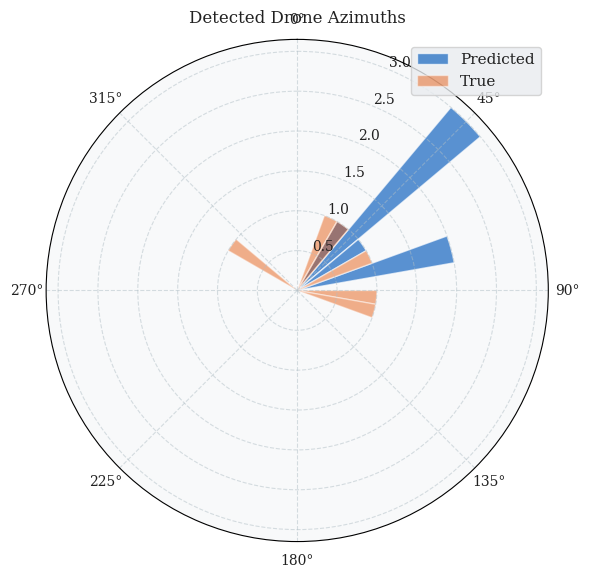

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip",
  cfg=config,
  dataset_format="auto",   # or "uavirbase" / "pannoniafs" / "generic_triplet" / "flat_wavs" - # bypass auto-detect
  max_sessions=10,         # optional — useful for a quick smoke test
)
print(test_ds)  # shows session count and format

results = run_test_dataset_evaluation(test_ds, config, save_csv="/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios_dataset_results.csv")


🚁 QUICK DEMO — Multi-drone synthetic test
──────────────────────────────────────────────────
  Detected: True  (conf=1.000)
  Drones found: 3
    Drone 1: (-0.00,0.00)m  az=-90.0°  dist=0.57m  err=1.552m
    Drone 2: (0.49,0.49)m  az=-10.1°  dist=0.49m  err=1.984m
    Drone 3: (0.80,-0.80)m  az=-59.7°  dist=1.60m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions.png


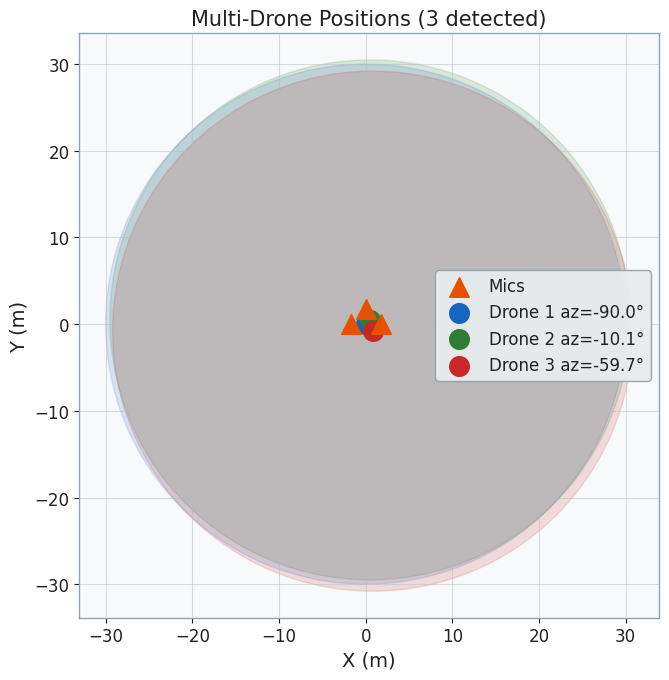

  Confirmed tracks: 3
    Track #2: pos=(-0.00,0.00)m  hits=1  dist=0.000m
    Track #3: pos=(0.49,0.49)m  hits=1  dist=0.000m
    Track #4: pos=(0.80,-0.80)m  hits=1  dist=0.000m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


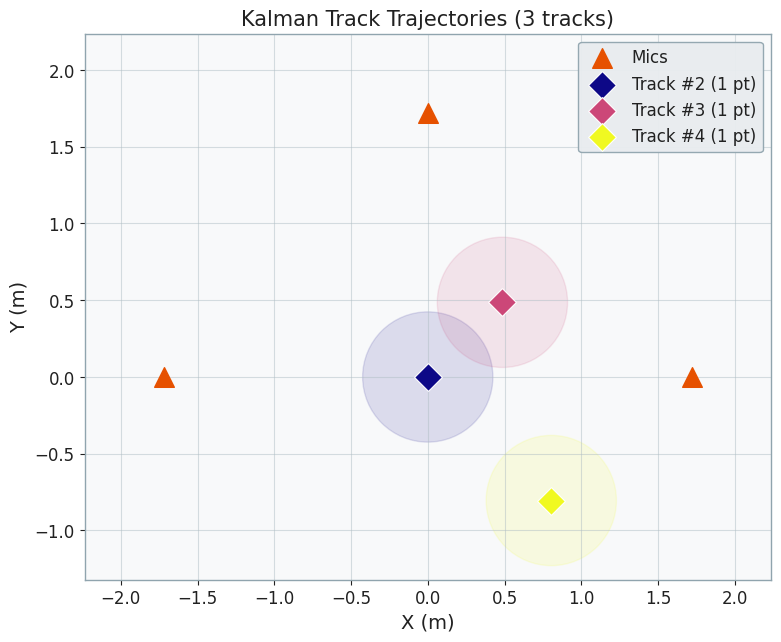

{'detected': True,
 'probability': 1.0,
 'cnn_probability': 0.9889196753501892,
 'heuristic_probability': 0.9684309514490324,
 'drones': [{'xy_position': array([-1.4006898e-16,  5.5511151e-17], dtype=float32),
   'azimuth_deg': -90.00000000000001,
   'distance_m': 0.5733333230018616,
   'tdoa_residual': 2.5144526469233007e-36,
   'confidence_radius': 30.0},
  {'xy_position': array([0.48639166, 0.48639166], dtype=float32),
   'azimuth_deg': -10.134489489614392,
   'distance_m': 0.4941008985042572,
   'tdoa_residual': 4.516042801743531e-21,
   'confidence_radius': 30.0},
  {'xy_position': array([ 0.80470484, -0.80470484], dtype=float32),
   'azimuth_deg': -59.717224758616425,
   'distance_m': 1.5957878828048706,
   'tdoa_residual': 1.8630804113338286e-20,
   'confidence_radius': 30.0}],
 'tracks': [<drone_detection.tracking.KalmanTrack at 0x7af414ad95e0>,
  <drone_detection.tracking.KalmanTrack at 0x7af414af80b0>]}

In [ ]:
# Quick synthetic demo after training

demo_result = quick_demo(config)
demo_result

📁 Please upload exactly 3 audio files for Mic1, Mic2, and Mic3.


Saving seg_030_circle_train_ch2.wav to seg_030_circle_train_ch2.wav
Saving seg_030_circle_train_ch1.wav to seg_030_circle_train_ch1.wav
Saving seg_030_circle_train_ch0.wav to seg_030_circle_train_ch0.wav
✅ Uploaded files:
   Mic 1: seg_030_circle_train_ch0.wav
   Mic 2: seg_030_circle_train_ch1.wav
   Mic 3: seg_030_circle_train_ch2.wav
🔄 Loading models...

🔊 Loading 3-channel audio...

📊 Analysing seg_030_circle_train_ch0.wav (channel 1)...
  Seg   1  🚁  conf=0.197  rms=-21.6 dB
  Seg   2  🚁  conf=0.200  rms=-20.4 dB
  Seg   3  🚁  conf=0.202  rms=-21.2 dB

  📊 3/3 segments detected  |  1 confirmed track(s)

🖼️  Generating analysis dashboard for seg_030_circle_train_ch0.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_030_circle_train_ch0.png


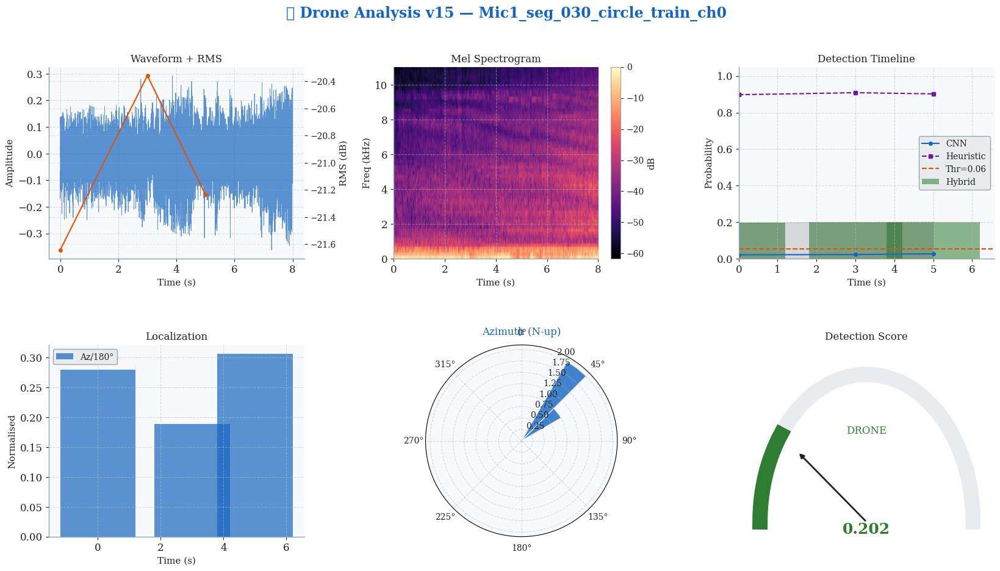

  📍 Plotting Kalman tracks for seg_030_circle_train_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


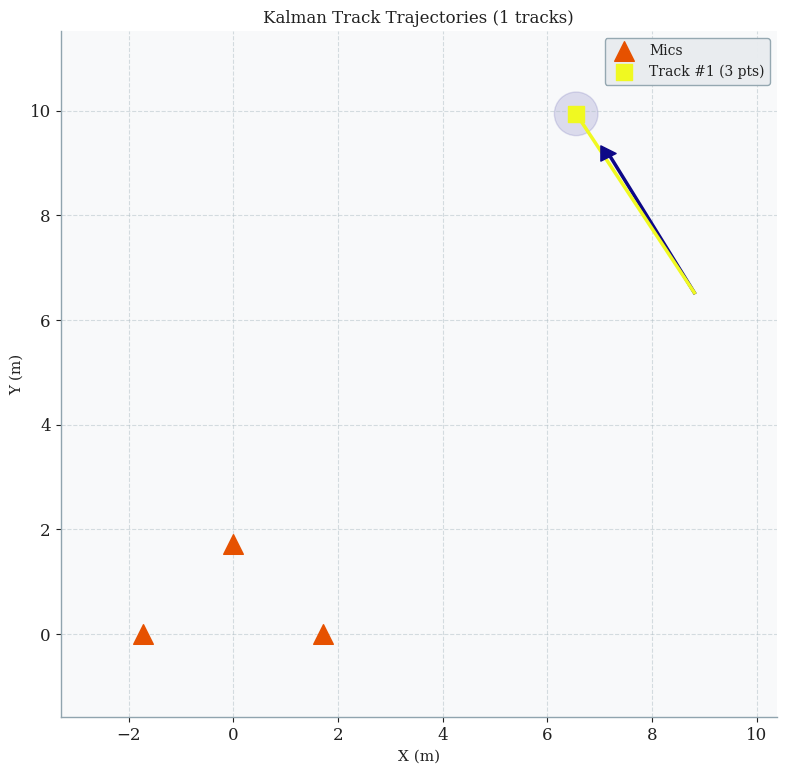


📊 Analysing seg_030_circle_train_ch1.wav (channel 2)...
  Seg   1  🚁  conf=0.212  rms=-19.3 dB
  Seg   2  🚁  conf=0.200  rms=-18.0 dB
  Seg   3  🚁  conf=0.199  rms=-18.9 dB

  📊 3/3 segments detected  |  1 confirmed track(s)

🖼️  Generating analysis dashboard for seg_030_circle_train_ch1.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_030_circle_train_ch1.png


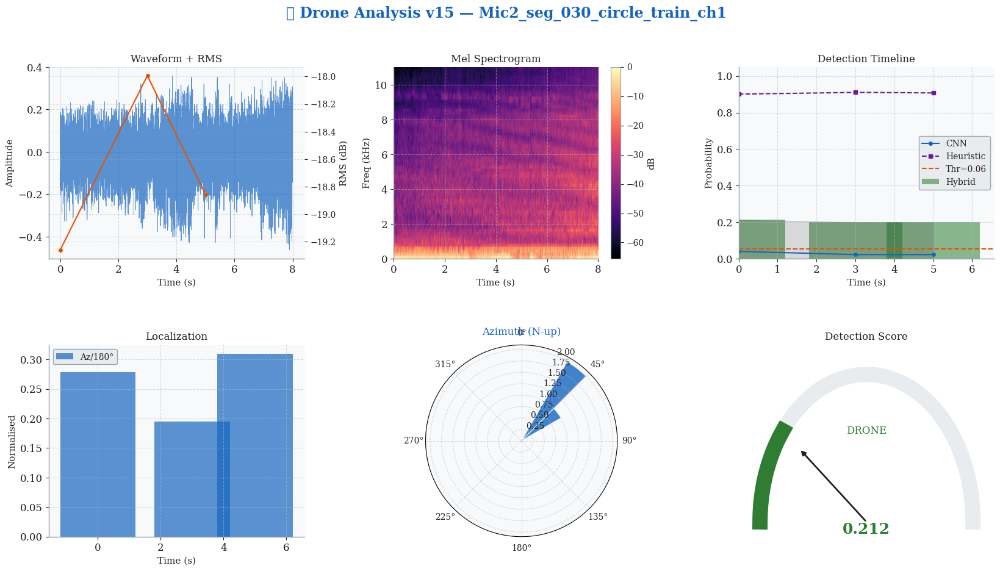

  📍 Plotting Kalman tracks for seg_030_circle_train_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


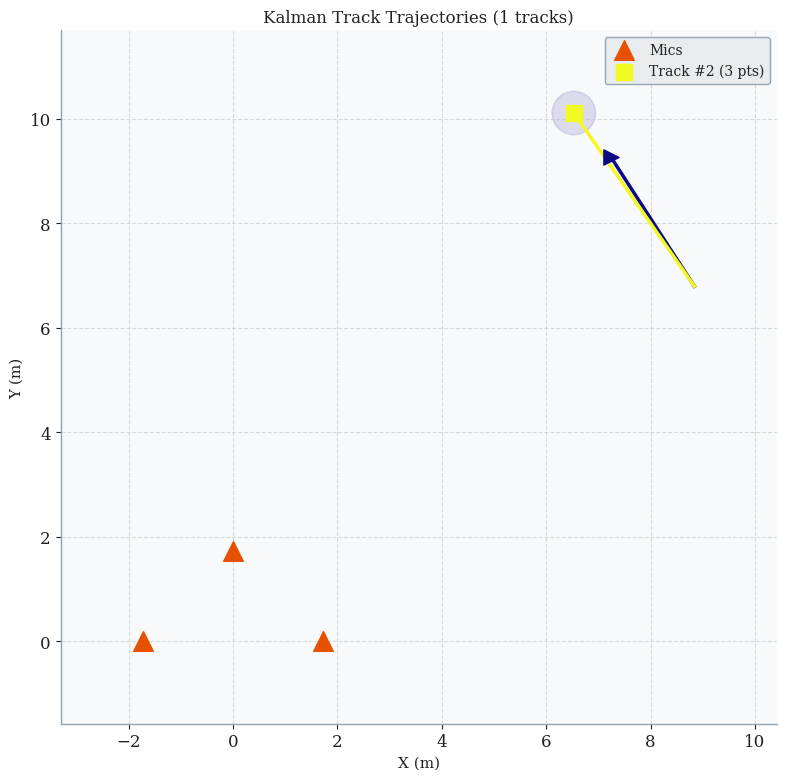


📊 Analysing seg_030_circle_train_ch2.wav (channel 3)...
  Seg   1  🚁  conf=0.197  rms=-22.0 dB
  Seg   2  🚁  conf=0.203  rms=-20.8 dB
  Seg   3  🚁  conf=0.199  rms=-21.7 dB

  📊 3/3 segments detected  |  1 confirmed track(s)

🖼️  Generating analysis dashboard for seg_030_circle_train_ch2.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_030_circle_train_ch2.png


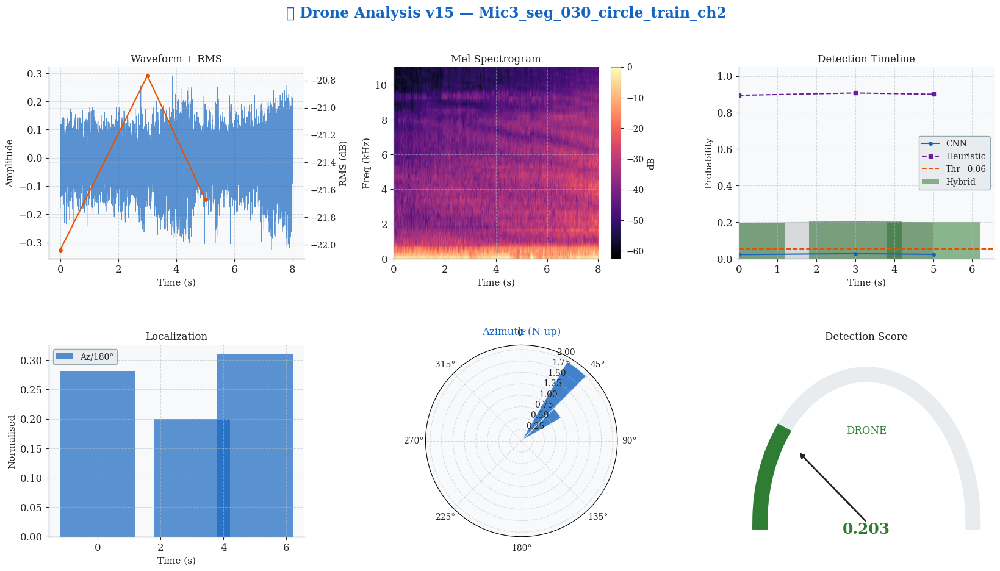

  📍 Plotting Kalman tracks for seg_030_circle_train_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


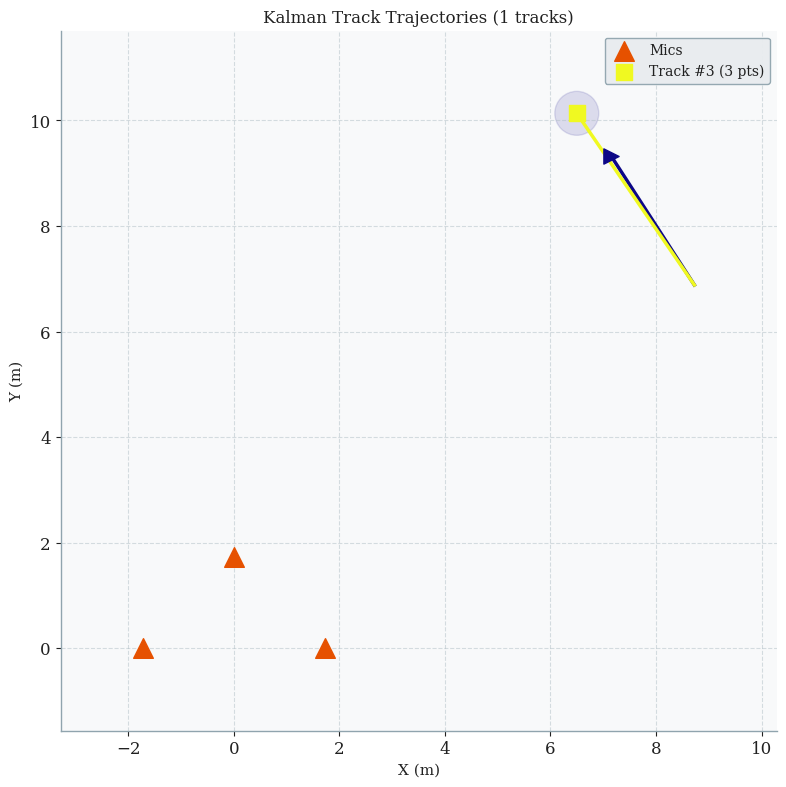


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🧭 Polar azimuth summary (9 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth.png


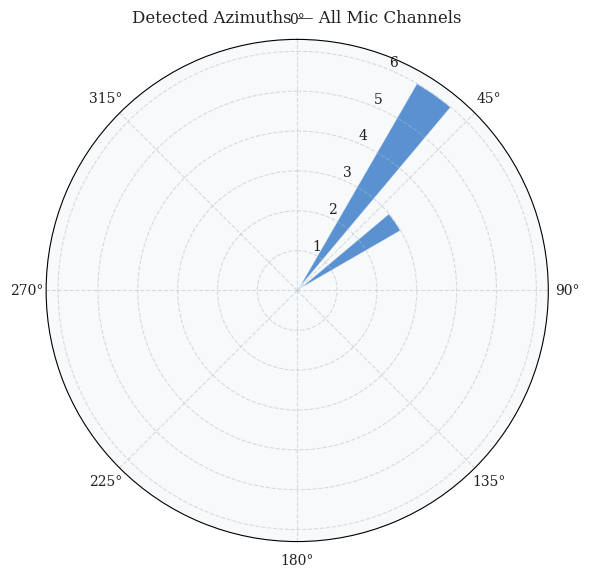


🗺️  Multi-drone position map...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions.png


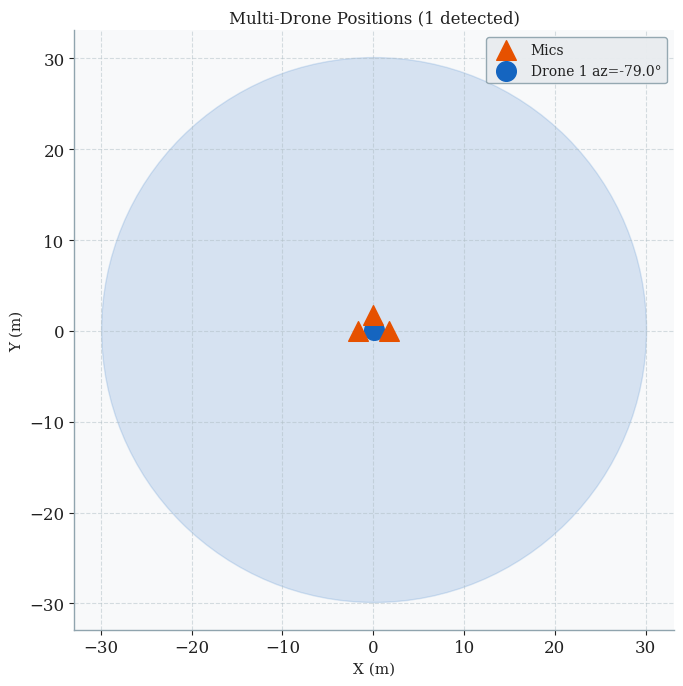


📍 Single-drone pipeline Kalman trajectories...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


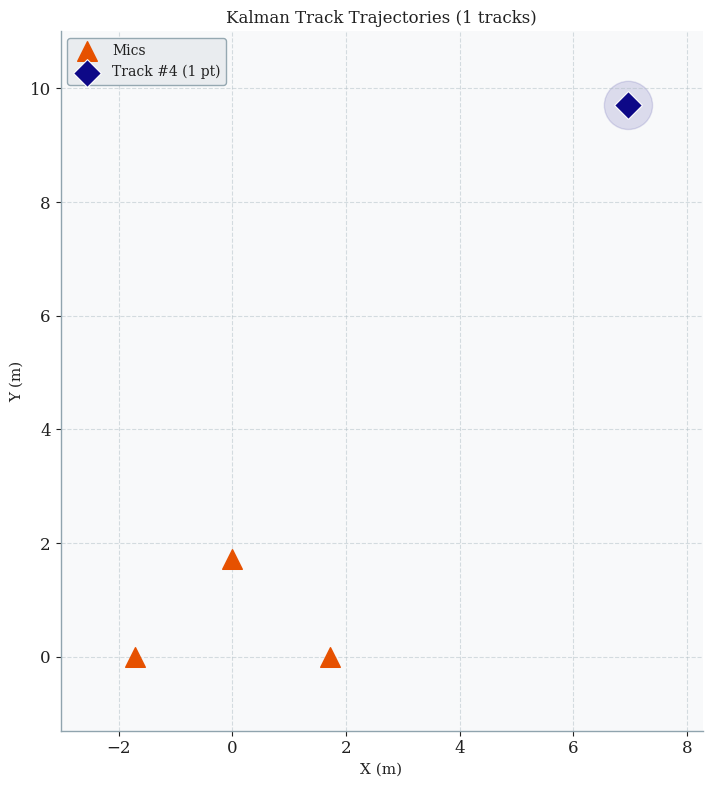


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: seg_030_circle_train_ch0.wav
  Mic 2: seg_030_circle_train_ch1.wav
  Mic 3: seg_030_circle_train_ch2.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.24866  max=0.18277  rms=-21.64 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.32786  max=0.24245  rms=-19.26 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.24100  max=0.17918  rms=-22.04 dB

🚁 Single-drone pipeline
  detected               : True
  probability            : 0.1966
  cnn_probability        : 0.0213
  heuristic_probability  : 0.8978
  drones_found           : 1
  tracks_returned        : 1
    Drone 1: az=52.63°  dist=11.49m  ht=9.43m  xy=(6.972, 9.702)

🚁🚁 Multi-drone pipeline
  detected               : True
  probability            : 0.1966
  cnn_probability        : 0.0213
  heuristic_probability  : 0.8978
  drones_found           : 1
  tracks_returned        : 1
    Drone 1: az=-78.98°  dist=0.49m  xy=(0.093, 0.093)


In [ ]:
# Test uploaded 3-mic files with one function

result = comprehensive_pipeline_test()

# # Or
# files = [
#   "/content/file1.wav",
#   "/content/file2.wav",
#   "/content/file3.wav",
# ]

# result = comprehensive_pipeline_test(files)

In [ ]:
# Launch the Colab UI

launch_ui(config)

Saving seg_008_transit_train_ch2.wav to seg_008_transit_train_ch2.wav


Saving seg_007_transit_train_ch2.wav to seg_007_transit_train_ch2.wav
Saving seg_007_transit_train_ch1.wav to seg_007_transit_train_ch1.wav
Saving seg_007_transit_train_ch0.wav to seg_007_transit_train_ch0.wav


📁 Please upload exactly 3 audio files for Mic1, Mic2, and Mic3.


Saving seg_006_hover_val_ch2.wav to seg_006_hover_val_ch2.wav
Saving seg_006_hover_val_ch1.wav to seg_006_hover_val_ch1.wav
Saving seg_006_hover_val_ch0.wav to seg_006_hover_val_ch0.wav
✅ Uploaded files:
   Mic 1: seg_006_hover_val_ch0.wav
   Mic 2: seg_006_hover_val_ch1.wav
   Mic 3: seg_006_hover_val_ch2.wav
🔄 Loading models...

🔊 Loading 3-channel audio...

📊 Analysing seg_006_hover_val_ch0.wav (channel 1)...
  Seg   1  🌳  conf=0.159  rms=-40.9 dB
  Seg   2  🌳  conf=0.153  rms=-42.3 dB
  Seg   3  🌳  conf=0.299  rms=-42.5 dB
  Seg   4  🌳  conf=0.172  rms=-41.7 dB
  Seg   5  🌳  conf=0.186  rms=-40.5 dB
  Seg   6  🌳  conf=0.179  rms=-40.7 dB
  Seg   7  🌳  conf=0.249  rms=-41.5 dB
  Seg   8  🌳  conf=0.159  rms=-41.5 dB
  Seg   9  🚁  conf=0.706  rms=-40.7 dB
  Seg  10  🚁  conf=0.886  rms=-40.6 dB
  Seg  11  🌳  conf=0.297  rms=-40.8 dB
  Seg  12  🌳  conf=0.205  rms=-41.0 dB
  Seg  13  🌳  conf=0.281  rms=-40.9 dB
  Seg  14  🚁  conf=0.855  rms=-40.2 dB
  Seg  15  🚁  conf=0.970  rms=-40.3 dB

/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:364: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  plt.savefig(str(save_path), dpi=200, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_seg_006_hover_val_ch0.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


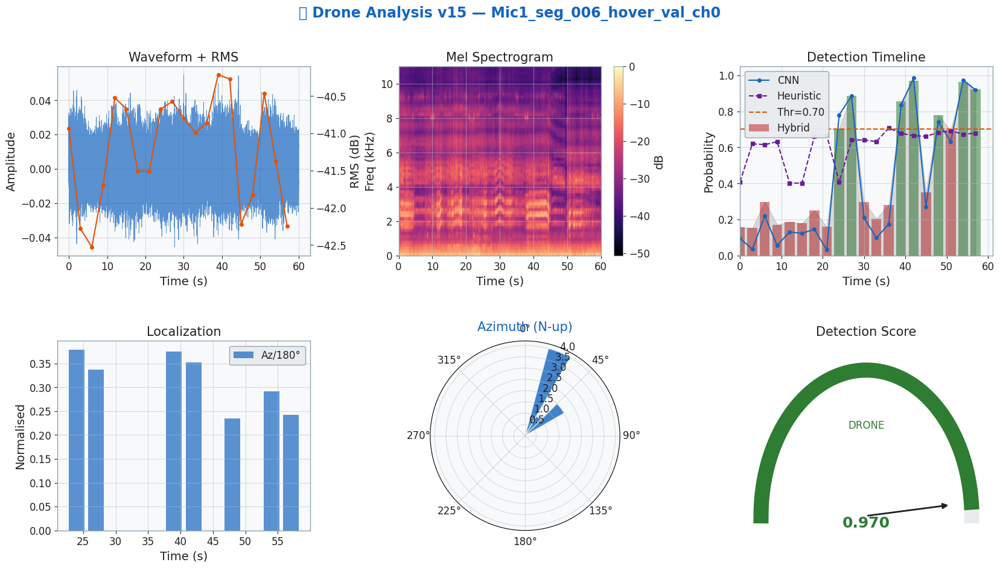

  📍 Plotting Kalman tracks for seg_006_hover_val_ch0.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


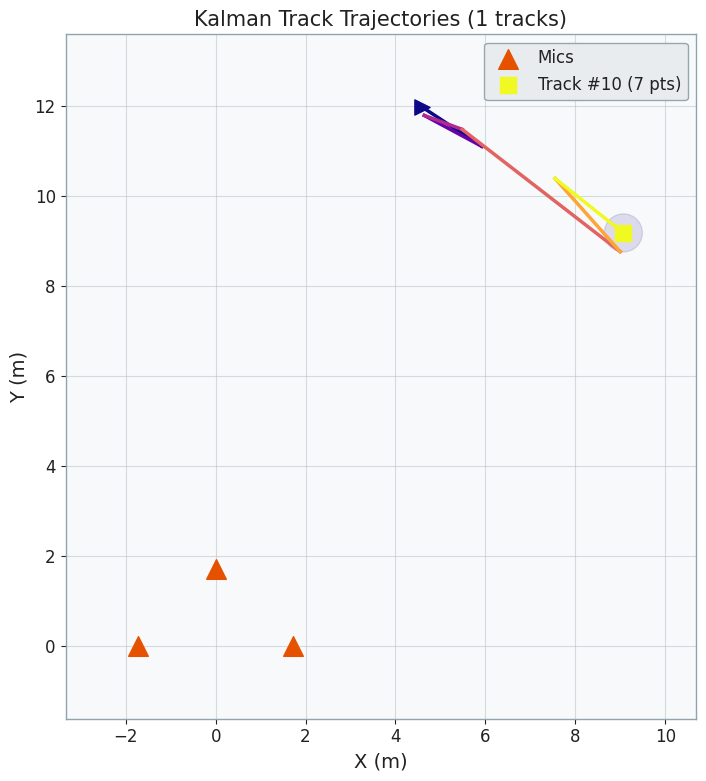


📊 Analysing seg_006_hover_val_ch1.wav (channel 2)...
  Seg   1  🌳  conf=0.162  rms=-39.0 dB
  Seg   2  🌳  conf=0.114  rms=-40.3 dB
  Seg   3  🌳  conf=0.423  rms=-40.4 dB
  Seg   4  🌳  conf=0.191  rms=-39.7 dB
  Seg   5  🌳  conf=0.165  rms=-38.5 dB
  Seg   6  🌳  conf=0.212  rms=-38.6 dB
  Seg   7  🌳  conf=0.323  rms=-39.5 dB
  Seg   8  🌳  conf=0.155  rms=-39.5 dB
  Seg   9  🚁  conf=0.707  rms=-38.7 dB
  Seg  10  🚁  conf=0.859  rms=-38.5 dB
  Seg  11  🌳  conf=0.325  rms=-38.7 dB
  Seg  12  🌳  conf=0.265  rms=-38.9 dB
  Seg  13  🌳  conf=0.357  rms=-38.8 dB
  Seg  14  🚁  conf=0.841  rms=-38.2 dB
  Seg  15  🚁  conf=0.978  rms=-38.3 dB
  Seg  16  🌳  conf=0.209  rms=-40.1 dB
  Seg  17  🌳  conf=0.404  rms=-39.7 dB
  Seg  18  🌳  conf=0.452  rms=-38.4 dB
  Seg  19  🚁  conf=0.811  rms=-39.3 dB
  Seg  20  🌳  conf=0.684  rms=-40.1 dB

  📊 5/20 segments detected  |  3 confirmed track(s)

🖼️  Generating analysis dashboard for seg_006_hover_val_ch1.wav...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:364: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  plt.savefig(str(save_path), dpi=200, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_seg_006_hover_val_ch1.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


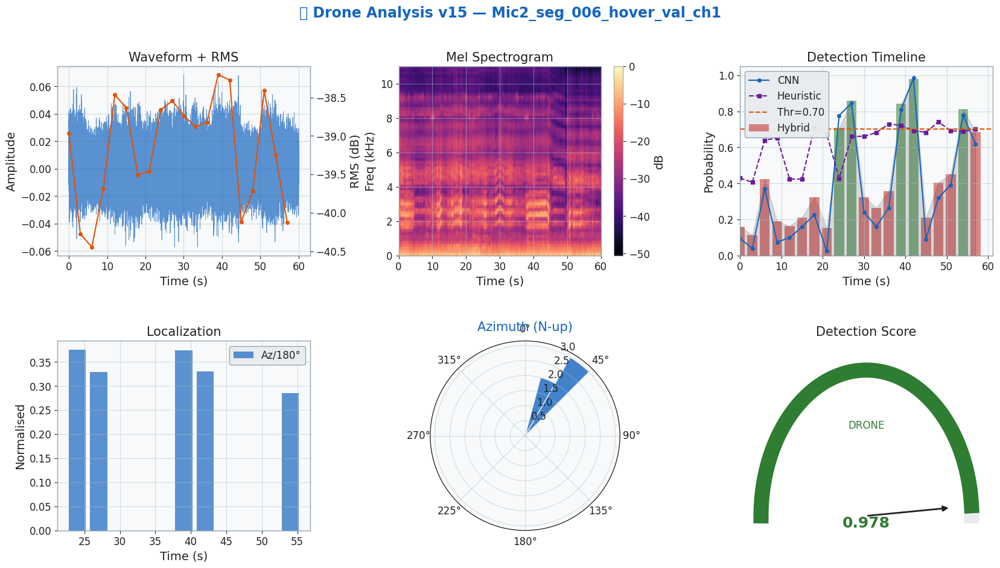

  📍 Plotting Kalman tracks for seg_006_hover_val_ch1.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


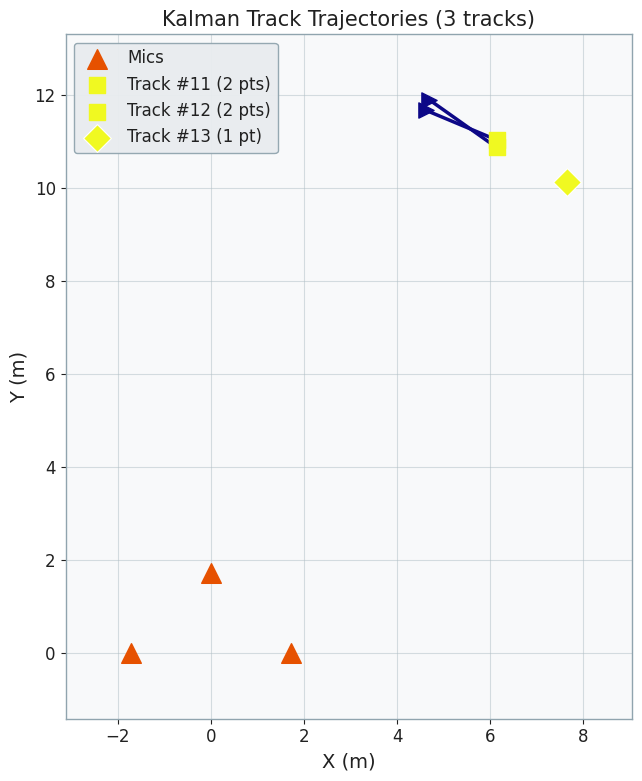


📊 Analysing seg_006_hover_val_ch2.wav (channel 3)...
  Seg   1  🌳  conf=0.556  rms=-40.8 dB
  Seg   2  🌳  conf=0.195  rms=-42.1 dB
  Seg   3  🚁  conf=0.920  rms=-42.4 dB
  Seg   4  🌳  conf=0.419  rms=-41.6 dB
  Seg   5  🌳  conf=0.585  rms=-40.4 dB
  Seg   6  🚁  conf=0.796  rms=-40.6 dB
  Seg   7  🌳  conf=0.517  rms=-41.4 dB
  Seg   8  🌳  conf=0.379  rms=-41.4 dB
  Seg   9  🚁  conf=0.838  rms=-40.6 dB
  Seg  10  🚁  conf=0.962  rms=-40.5 dB
  Seg  11  🚁  conf=0.884  rms=-40.7 dB
  Seg  12  🚁  conf=0.817  rms=-40.8 dB
  Seg  13  🌳  conf=0.490  rms=-40.8 dB
  Seg  14  🚁  conf=0.941  rms=-40.1 dB
  Seg  15  🚁  conf=0.971  rms=-40.2 dB
  Seg  16  🌳  conf=0.378  rms=-42.1 dB
  Seg  17  🌳  conf=0.465  rms=-41.7 dB
  Seg  18  🌳  conf=0.394  rms=-40.4 dB
  Seg  19  🚁  conf=0.815  rms=-41.3 dB
  Seg  20  🌳  conf=0.587  rms=-42.1 dB

  📊 9/20 segments detected  |  5 confirmed track(s)

🖼️  Generating analysis dashboard for seg_006_hover_val_ch2.wav...


/content/drive/MyDrive/AUS LAB II/drone_detection/visualization.py:364: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  plt.savefig(str(save_path), dpi=200, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_seg_006_hover_val_ch2.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


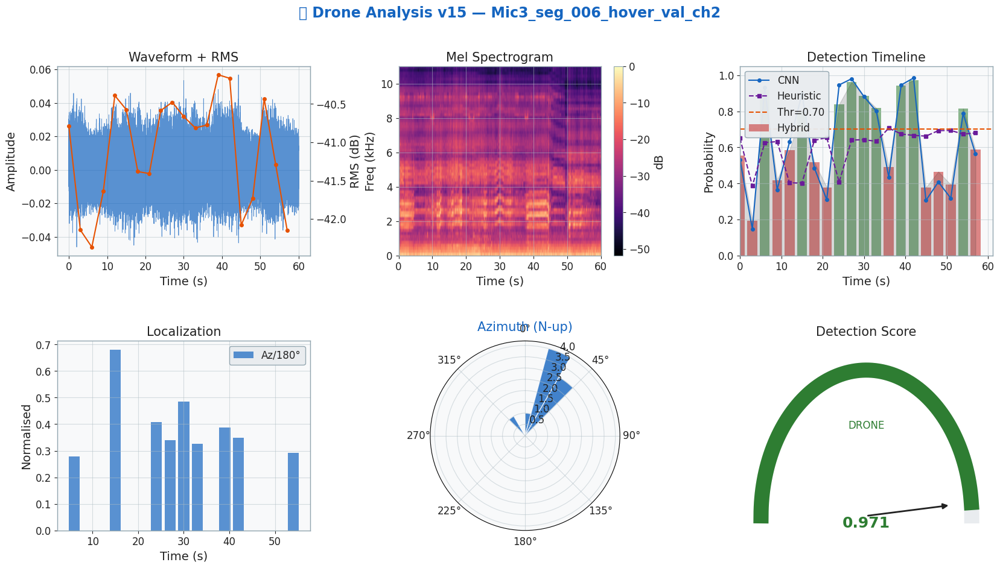

  📍 Plotting Kalman tracks for seg_006_hover_val_ch2.wav...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


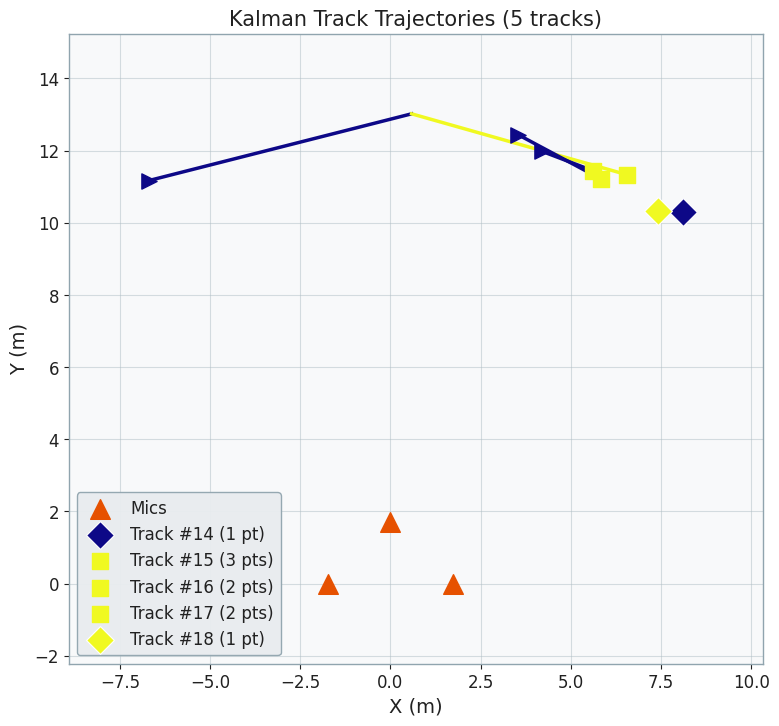


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

🧭 Polar azimuth summary (21 detections)...
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/polar_azimuth.png


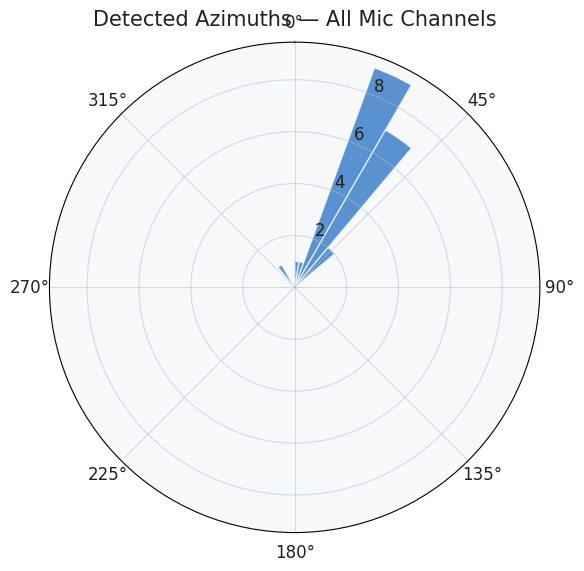


COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: seg_006_hover_val_ch0.wav
  Mic 2: seg_006_hover_val_ch1.wav
  Mic 3: seg_006_hover_val_ch2.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.04378  max=0.04589  rms=-40.93 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.05102  max=0.05933  rms=-38.96 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.04612  max=0.04573  rms=-40.79 dB

🚁 Single-drone pipeline
  detected               : False
  probability            : 0.1586
  cnn_probability        : 0.0961
  heuristic_probability  : 0.4088
  drones_found           : 0
  tracks_returned        : 0

🚁🚁 Multi-drone pipeline
  detected               : False
  probability            : 0.1586
  cnn_probability        : 0.0961
  heuristic_probability  : 0.4088
  drones_found           : 0
  tracks_returned        : 0


In [ ]:
# Test uploaded 3-mic files with one function

result = comprehensive_pipeline_test()


🎧 Robust External Audio Analysis
🎵 File: seg_032_circle_train_ch2.wav | duration=188.00s | 375 segments
  Seg   1 🌳 prob=0.135  cnn=0.014  heur=0.622  [0.00–1.00s]
  Seg   2 🚁 prob=0.511  cnn=0.479  heur=0.639  [0.50–1.50s]
  Seg   3 🚁 prob=0.480  cnn=0.445  heur=0.618  [1.00–2.00s]
  Seg   4 🌳 prob=0.127  cnn=0.007  heur=0.608  [1.50–2.50s]
  Seg   5 🌳 prob=0.286  cnn=0.209  heur=0.592  [2.00–3.00s]
  Seg   6 🚁 prob=0.375  cnn=0.317  heur=0.606  [2.50–3.50s]
  Seg   7 🚁 prob=0.566  cnn=0.540  heur=0.669  [3.00–4.00s]
  Seg   8 🌳 prob=0.119  cnn=0.008  heur=0.565  [3.50–4.50s]
  Seg   9 🚁 prob=0.462  cnn=0.408  heur=0.677  [4.00–5.00s]
  Seg  10 🌳 prob=0.180  cnn=0.067  heur=0.631  [4.50–5.50s]
  Seg  11 🌳 prob=0.131  cnn=0.015  heur=0.595  [5.00–6.00s]
  Seg  12 🌳 prob=0.230  cnn=0.137  heur=0.604  [5.50–6.50s]
  Seg  13 🌳 prob=0.151  cnn=0.036  heur=0.611  [6.00–7.00s]
  Seg  14 🚁 prob=0.615  cnn=0.624  heur=0.581  [6.50–7.50s]
  Seg  15 🚁 prob=0.380  cnn=0.329  heur=0.584  [7.00–8.

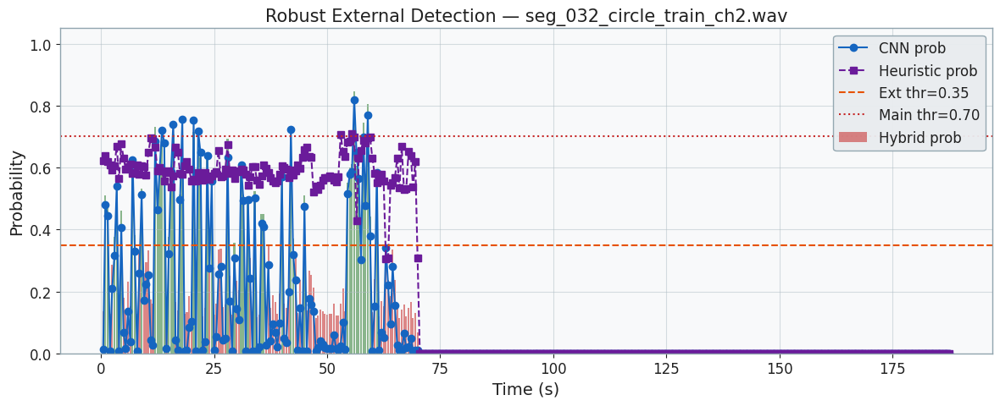

{'file': '/content/seg_032_circle_train_ch2.wav',
 'duration_s': 188.0,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.13521746734686169,
   'cnn_probability': 0.013505732640624046,
   'heuristic_probability': 0.6220644061718121,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.5108816284134788,
   'cnn_probability': 0.4787973463535309,
   'heuristic_probability': 0.6392187566532707,
   'label': 'possible_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.4798662096091999,
   'cnn_probability': 0.4452272653579712,
   'heuristic_probability': 0.6184219866141145,
   'label': 'possible_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': Tr

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/seg_032_circle_train_ch2.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0132500_0137000.wav | duration=4.50s | 8 segments
  Seg   1 🚁 prob=0.898  cnn=0.984  heur=0.554  [0.00–1.00s]
  Seg   2 🚁 prob=0.896  cnn=0.984  heur=0.545  [0.50–1.50s]
  Seg   3 🚁 prob=0.898  cnn=0.984  heur=0.556  [1.00–2.00s]
  Seg   4 🚁 prob=0.828  cnn=0.814  heur=0.637  [1.50–2.50s]
  Seg   5 🚁 prob=0.772  cnn=0.720  heur=0.728  [2.00–3.00s]
  Seg   6 🚁 prob=0.888  cnn=0.981  heur=0.516  [2.50–3.50s]
  Seg   7 🚁 prob=0.977  cnn=0.979  heur=0.719  [3.00–4.00s]
  Seg   8 🚁 prob=0.968  cnn=0.968  heur=0.718  [3.50–4.50s]

📊 Clip score: 0.948  |  Positive: 8/8  |  Label: drone


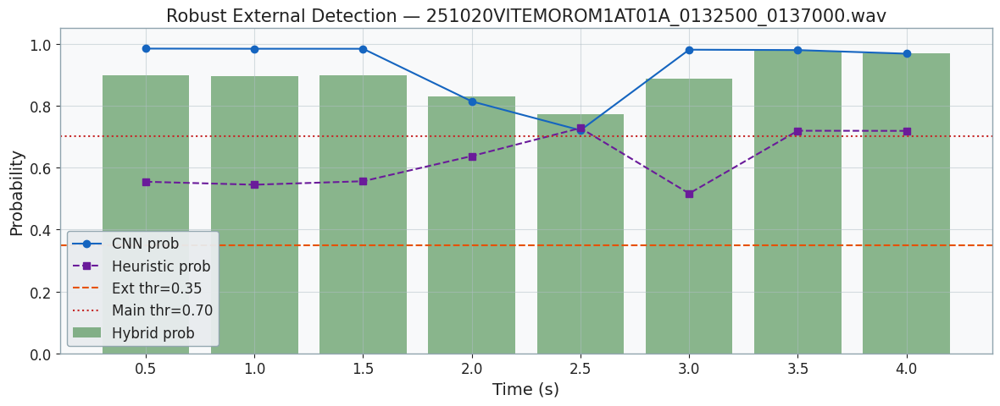

{'file': '/content/251020VITEMOROM1AT01A_0132500_0137000.wav',
 'duration_s': 4.5,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.8981477357882421,
   'cnn_probability': 0.9841400384902954,
   'heuristic_probability': 0.5541785249800291,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.8958067660903523,
   'cnn_probability': 0.9836199283599854,
   'heuristic_probability': 0.5445541170118195,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.897994021478334,
   'cnn_probability': 0.9835419654846191,
   'heuristic_probability': 0.5558022454531929,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_in

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0132500_0137000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)

In [ ]:
# Launch the Colab UI

launch_ui(config)

Saving DJI_drones_noise_comparson_seg_007_0026698_0029748_0001000_0002856.wav to DJI_drones_noise_comparson_seg_007_0026698_0029748_0001000_0002856.wav


Saving clean_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_007_0021798_0025798_0002000_0003976_seg_001_0000000_0002096.wav to clean_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_007_0021798_0025798_0002000_0003976_seg_001_0000000_0002096.wav
Saving aug_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_003_0008399_0012399_0001000_0004000_seg_001_0000000_0003120_02_drilling_fold6_58005_24.wav to aug_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_003_0008399_0012399_0001000_0004000_seg_001_0000000_0003120_02_drilling_fold6_58005_24.wav
Saving clean_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_003_0008399_0012399_0001000_0004000_seg_001_0000000_0003120.wav to clean_Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_003_0008399_0012399_0001000_0004000_seg_001_0000000_0003120.wav


📁 Please upload exactly 3 audio files for Mic1, Mic2, and Mic3.


Saving siren_fold8_148632_9.wav to siren_fold8_148632_9.wav
Saving siren_fold7_107357_8.wav to siren_fold7_107357_8 (1).wav
Saving car_horn_fold6_128465_8.wav to car_horn_fold6_128465_8.wav
✅ Uploaded files:
   Mic 1: car_horn_fold6_128465_8.wav
   Mic 2: siren_fold7_107357_8 (1).wav
   Mic 3: siren_fold8_148632_9.wav
🔄 Loading models...

🔊 Loading 3-channel audio...

📊 Analysing car_horn_fold6_128465_8.wav (channel 1)...
  Seg   1  🌳  conf=0.430  rms=-24.2 dB
  Seg   2  🌳  conf=0.736  rms=-24.1 dB

  📊 0/2 segments detected  |  0 confirmed track(s)

🖼️  Generating analysis dashboard for car_horn_fold6_128465_8.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic1_car_horn_fold6_128465_8.png


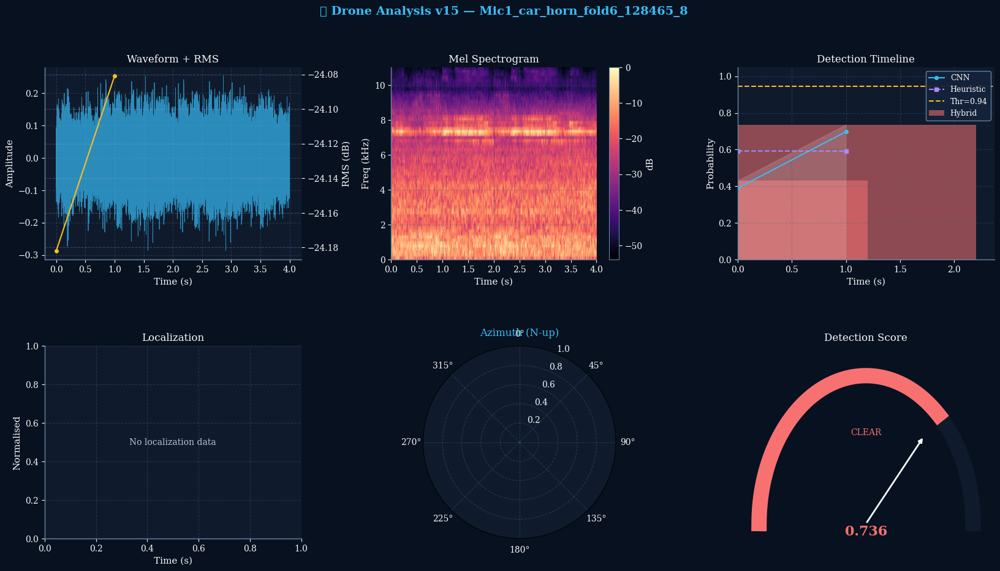


📊 Analysing siren_fold7_107357_8 (1).wav (channel 2)...
  Seg   1  🌳  conf=0.206  rms=-29.5 dB
  Seg   2  🌳  conf=0.301  rms=-29.6 dB

  📊 0/2 segments detected  |  0 confirmed track(s)

🖼️  Generating analysis dashboard for siren_fold7_107357_8 (1).wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic2_siren_fold7_107357_8 (1).png


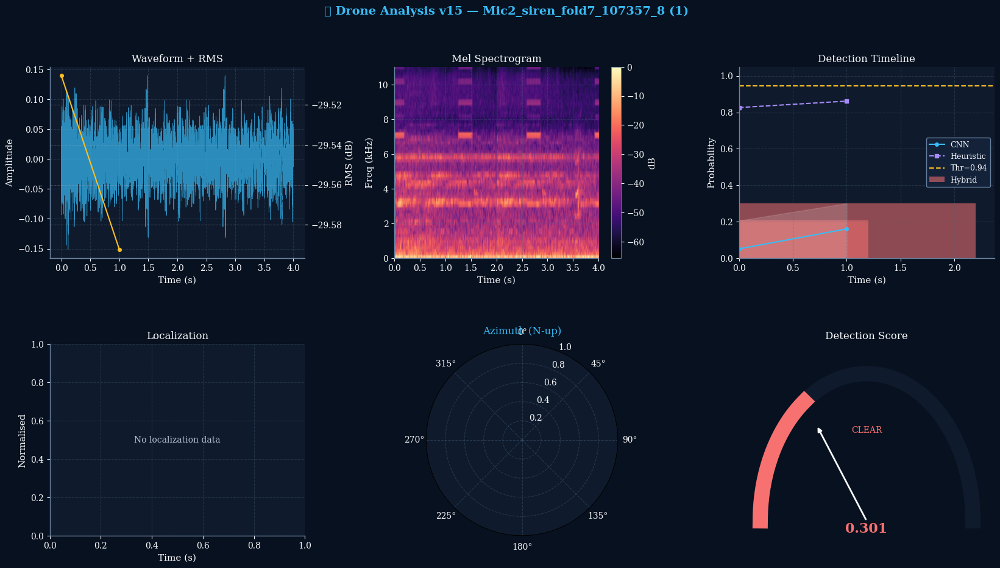


📊 Analysing siren_fold8_148632_9.wav (channel 3)...
  Seg   1  🌳  conf=0.000  rms=-55.4 dB
  Seg   2  🌳  conf=0.000  rms=-56.0 dB

  📊 0/2 segments detected  |  0 confirmed track(s)

🖼️  Generating analysis dashboard for siren_fold8_148632_9.wav...
💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/analysis_Mic3_siren_fold8_148632_9.png


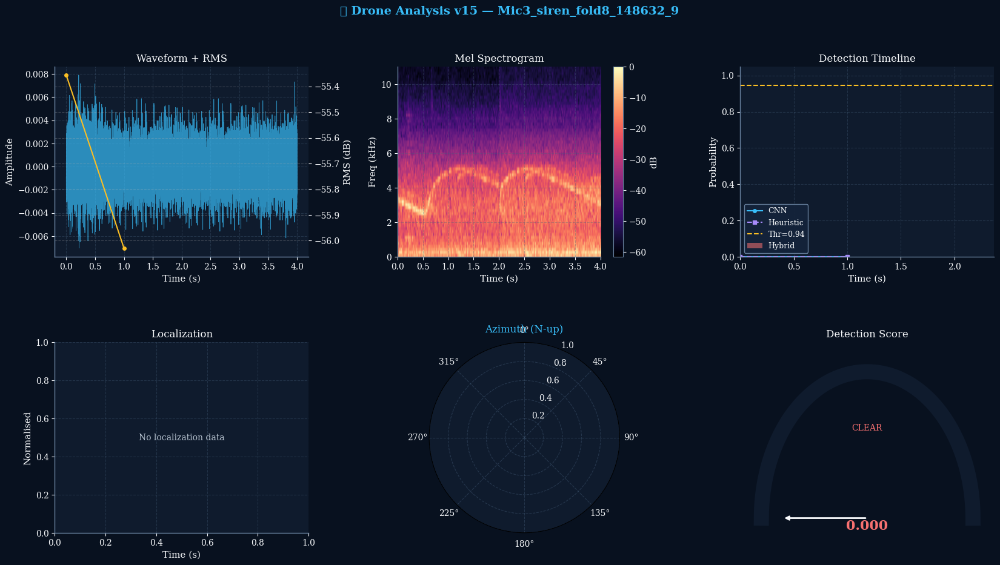


🚁 Running single-drone pipeline...

🚁🚁 Running multi-drone pipeline...

COMPREHENSIVE PIPELINE TEST SUMMARY

🎵 Input files
  Mic 1: car_horn_fold6_128465_8.wav
  Mic 2: siren_fold7_107357_8 (1).wav
  Mic 3: siren_fold8_148632_9.wav

🔊 Channel statistics
  Ch1: shape=(66150,)  dtype=float32  min=-0.28715  max=0.25379  rms=-24.18 dB
  Ch2: shape=(66150,)  dtype=float32  min=-0.15117  max=0.13983  rms=-29.51 dB
  Ch3: shape=(66150,)  dtype=float32  min=-0.00704  max=0.00790  rms=-55.36 dB

🚁 Single-drone pipeline
  detected               : False
  probability            : 0.4301
  cnn_probability        : 0.3895
  heuristic_probability  : 0.5926
  drones_found           : 0
  tracks_returned        : 0

🚁🚁 Multi-drone pipeline
  detected               : False
  probability            : 0.4301
  cnn_probability        : 0.3895
  heuristic_probability  : 0.5926
  drones_found           : 0
  tracks_returned        : 0


In [ ]:
# Test uploaded 3-mic files with one function

result = comprehensive_pipeline_test()

# # Or
# files = [
#   "/content/file1.wav",
#   "/content/file2.wav",
#   "/content/file3.wav",
# ]

# result = comprehensive_pipeline_test(files)


🚁 QUICK DEMO — Multi-drone synthetic test
──────────────────────────────────────────────────
  Detected: True  (conf=1.000)
  Drones found: 3
    Drone 1: (-0.19,0.22)m  az=150.0°  dist=0.33m  err=1.697m
    Drone 2: (0.10,-0.27)m  az=-90.0°  dist=0.33m  err=2.348m
    Drone 3: (-21.55,-12.44)m  az=-150.0°  dist=25.00m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions.png


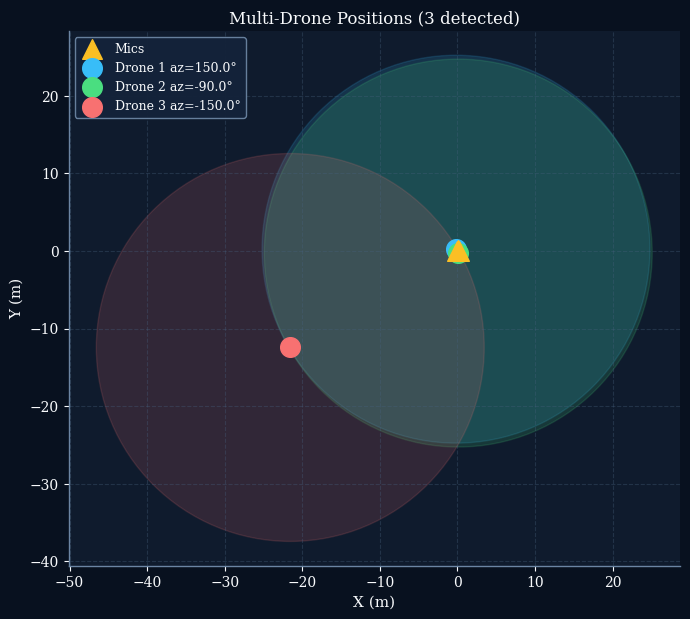

  Confirmed tracks: 3
    Track #8: pos=(-0.19,0.22)m  hits=1  dist=0.000m
    Track #9: pos=(0.10,-0.27)m  hits=1  dist=0.000m
    Track #10: pos=(-21.55,-12.44)m  hits=1  dist=0.000m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


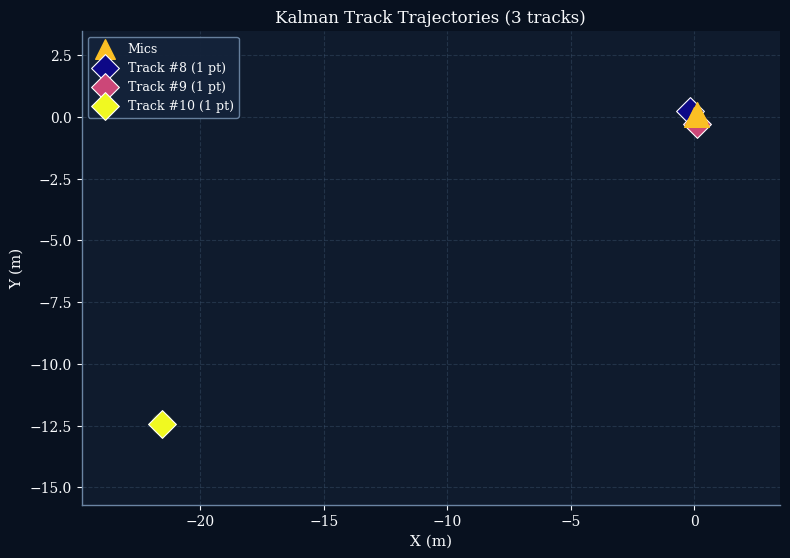

{'detected': True,
 'probability': 1.0,
 'cnn_probability': 0.9924039244651794,
 'heuristic_probability': 0.9666710178327239,
 'drones': [{'xy_position': array([-0.18770278,  0.22384177], dtype=float32),
   'azimuth_deg': 149.9995260499506,
   'distance_m': 0.3322121202945709,
   'tdoa_residual': 1.6369652035672086e-21,
   'confidence_radius': 25.0},
  {'xy_position': array([ 0.1       , -0.27455315], dtype=float32),
   'azimuth_deg': -90.0,
   'distance_m': 0.3322864770889282,
   'tdoa_residual': 8.27601568046432e-24,
   'confidence_radius': 25.0},
  {'xy_position': array([-21.55048 , -12.442631], dtype=float32),
   'azimuth_deg': -149.9990995222952,
   'distance_m': 25.00004768371582,
   'tdoa_residual': 5.415149194498231e-09,
   'confidence_radius': 25.0}],
 'tracks': [<drone_detection.tracking.KalmanTrack at 0x7dc0d00da690>,
  <drone_detection.tracking.KalmanTrack at 0x7dc0d0738fe0>]}

In [ ]:
quick_demo(config)


🚁 QUICK DEMO — Multi-drone synthetic test
──────────────────────────────────────────────────
  Detected: True  (conf=1.000)
  Drones found: 3
    Drone 1: (-13.37,21.12)m  az=122.6°  dist=25.00m  err=25.503m
    Drone 2: (20.84,14.02)m  az=34.0°  dist=25.00m  err=25.024m
    Drone 3: (0.37,-0.10)m  az=-30.0°  dist=0.31m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/multi_drone_positions.png


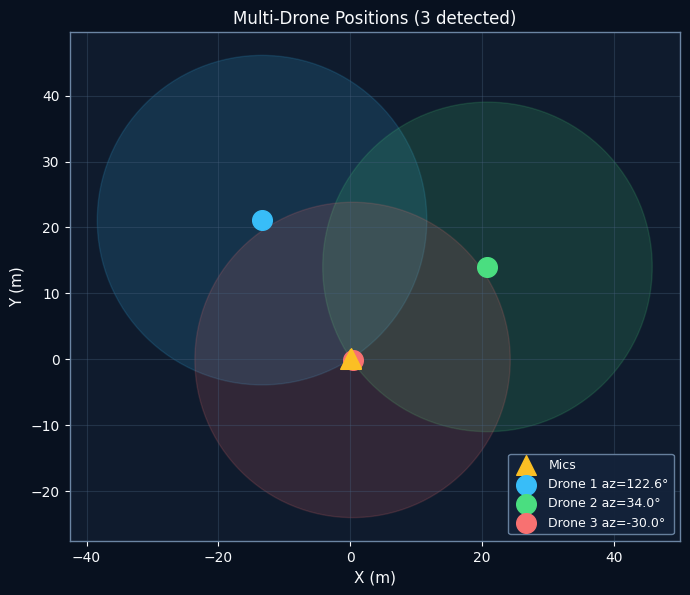

  Confirmed tracks: 3
    Track #3: pos=(-13.37,21.12)m  hits=1  dist=0.000m
    Track #4: pos=(20.84,14.02)m  hits=1  dist=0.000m
    Track #5: pos=(0.37,-0.10)m  hits=1  dist=0.000m
💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/track_trajectory.png


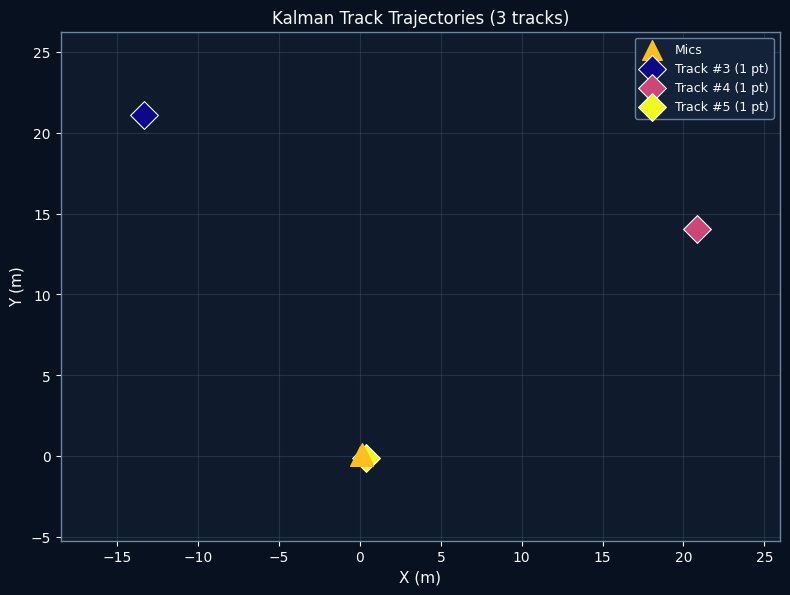

{'detected': True,
 'probability': 1.0,
 'cnn_probability': 1.0,
 'heuristic_probability': 0.9728569212590056,
 'drones': [{'xy_position': array([-13.371236,  21.117786], dtype=float32),
   'azimuth_deg': 122.60534921118966,
   'distance_m': 25.0,
   'tdoa_residual': 7.700231305488377e-11,
   'confidence_radius': 25.0},
  {'xy_position': array([20.83701 , 14.021234], dtype=float32),
   'azimuth_deg': 33.95480029366549,
   'distance_m': 25.000057220458984,
   'tdoa_residual': 8.15564552719485e-09,
   'confidence_radius': 25.0},
  {'xy_position': array([ 0.36578903, -0.09572623], dtype=float32),
   'azimuth_deg': -30.00100152533768,
   'distance_m': 0.30690982937812805,
   'tdoa_residual': 1.2903105862002936e-22,
   'confidence_radius': 23.925767963401906}],
 'tracks': [<drone_detection.tracking.KalmanTrack at 0x7bcbfd653140>,
  <drone_detection.tracking.KalmanTrack at 0x7bcbfd573410>]}

In [ ]:
quick_demo(config)

In [ ]:
# Launch the Colab UI

launch_ui(config)

Saving 251020VITEMOROM1AT01A_0071000_0076000.wav to 251020VITEMOROM1AT01A_0071000_0076000.wav


Saving 251020VITEMOROM1AT01A_0219000_0221000.wav to 251020VITEMOROM1AT01A_0219000_0221000 (1).wav
Saving 251020VITEMOROM1AT01A_0132500_0137000.wav to 251020VITEMOROM1AT01A_0132500_0137000 (1).wav
Saving 251020VITEMOROM1AT01A_0111000_0125000.wav to 251020VITEMOROM1AT01A_0111000_0125000.wav


Saving klemenflerin-drone-fly-397287_0010000_0247920.wav to klemenflerin-drone-fly-397287_0010000_0247920 (1).wav
Saving Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_015_0051798_0055798_0001000_0004000.wav to Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_015_0051798_0055798_0001000_0004000.wav
Saving Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_013_0044298_0048298_0001700_0004000.wav to Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_013_0044298_0048298_0001700_0004000.wav


In [ ]:
# Launch the Colab UI

launch_ui(config)

Saving siren_fold8_133473_1.wav to siren_fold8_133473_1 (1).wav


Saving jackhammer_fold9_98859_5.wav to jackhammer_fold9_98859_5.wav
Saving jackhammer_fold9_98859_0.wav to jackhammer_fold9_98859_0.wav
Saving jackhammer_fold9_105029_13.wav to jackhammer_fold9_105029_13.wav



🎧 Robust External Audio Analysis
🎵 File: Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_016_0055548_0059548_0001000_0003500.wav | duration=2.50s | 4 segments
  Seg   1 🚁 prob=1.000  cnn=0.973  heur=0.954  [0.00–1.00s]
  Seg   2 🚁 prob=1.000  cnn=0.985  heur=0.952  [0.50–1.50s]
  Seg   3 🚁 prob=1.000  cnn=0.979  heur=0.952  [1.00–2.00s]
  Seg   4 🚁 prob=1.000  cnn=0.980  heur=0.935  [1.50–2.50s]

📊 Clip score: 1.000  |  Positive: 4/4  |  Label: drone


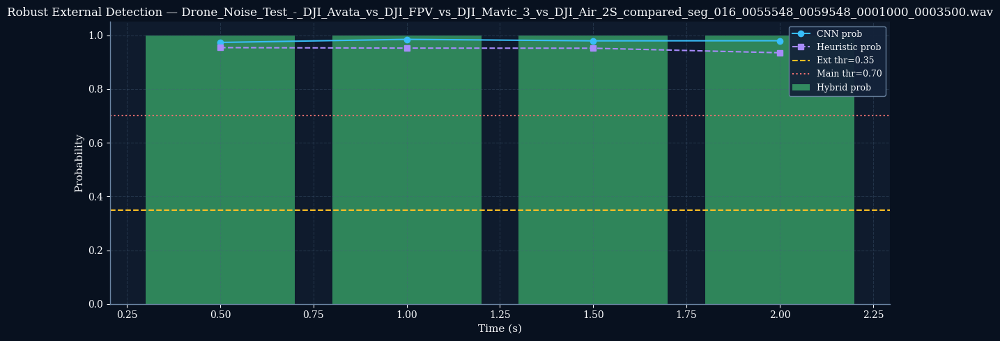

{'file': '/content/Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_016_0055548_0059548_0001000_0003500.wav',
 'duration_s': 2.5,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 1.0,
   'cnn_probability': 0.9732263684272766,
   'heuristic_probability': 0.9539272191539417,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 1.0,
   'cnn_probability': 0.9846535325050354,
   'heuristic_probability': 0.9521202671977496,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 1.0,
   'cnn_probability': 0.9791885018348694,
   'heuristic_probability': 0.9517184090249337,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_extern

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/Drone_Noise_Test_-_DJI_Avata_vs_DJI_FPV_vs_DJI_Mavic_3_vs_DJI_Air_2S_compared_seg_016_0055548_0059548_0001000_0003500.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0132500_0137000.wav | duration=4.50s | 8 segments
  Seg   1 🚁 prob=0.958  cnn=0.984  heur=0.554  [0.00–1.00s]
  Seg   2 🚁 prob=0.956  cnn=0.984  heur=0.545  [0.50–1.50s]
  Seg   3 🚁 prob=0.959  cnn=0.985  heur=0.556  [1.00–2.00s]
  Seg   4 🚁 prob=0.788  cnn=0.751  heur=0.637  [1.50–2.50s]
  Seg   5 🌳 prob=0.225  cnn=0.099  heur=0.728  [2.00–3.00s]
  Seg   6 🚁 prob=0.946  cnn=0.978  heur=0.516  [2.50–3.50s]
  Seg   7 🚁 prob=0.974  cnn=0.962  heur=0.719  [3.00–4.00s]
  Seg   8 🚁 prob=0.749  cnn=0.682  heur=0.718  [3.50–4.50s]

📊 Clip score: 0.964  |  Positive: 7/8  |  Label: drone


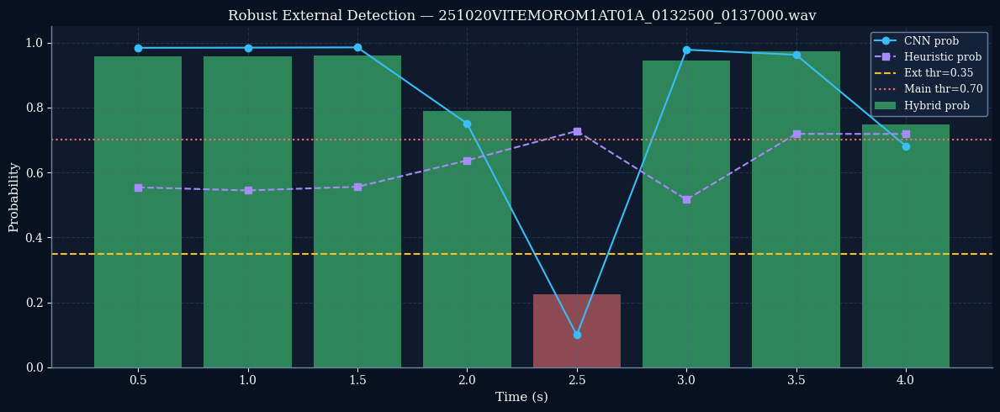

{'file': '/content/251020VITEMOROM1AT01A_0132500_0137000.wav',
 'duration_s': 4.5,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.958023328973667,
   'cnn_probability': 0.9839845299720764,
   'heuristic_probability': 0.5541785249800291,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.9564607959365437,
   'cnn_probability': 0.9844374656677246,
   'heuristic_probability': 0.5445541170118195,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.9592696562439589,
   'cnn_probability': 0.9851365089416504,
   'heuristic_probability': 0.5558022454531929,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_in

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0132500_0137000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: seg_011_diagonal_train_ch0 (1).wav | duration=3.00s | 5 segments
  Seg   1 🚁 prob=0.983  cnn=0.968  heur=0.794  [0.00–1.00s]
  Seg   2 🚁 prob=0.993  cnn=0.982  heur=0.790  [0.50–1.50s]
  Seg   3 🚁 prob=0.994  cnn=0.981  heur=0.797  [1.00–2.00s]
  Seg   4 🚁 prob=0.972  cnn=0.969  heur=0.734  [1.50–2.50s]
  Seg   5 🚁 prob=0.484  cnn=0.484  heur=0.483  [2.00–3.00s]

📊 Clip score: 0.990  |  Positive: 5/5  |  Label: drone


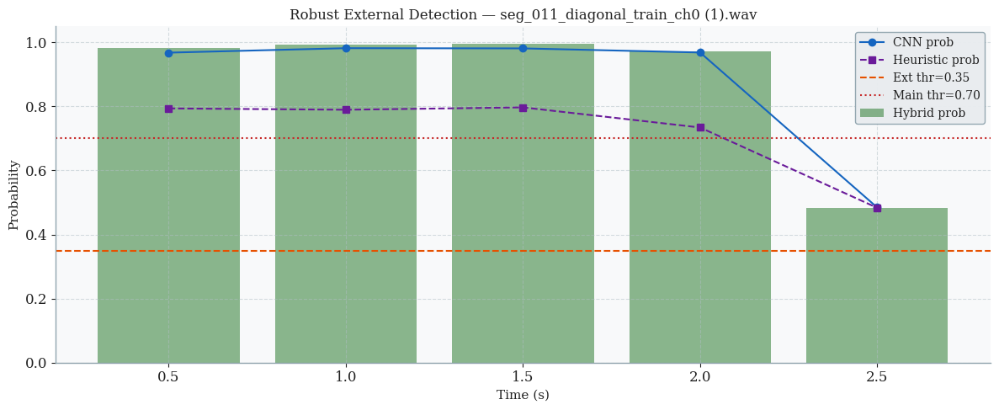

{'file': '/content/seg_011_diagonal_train_ch0 (1).wav',
 'duration_s': 3.0,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.9831851238195264,
   'cnn_probability': 0.9680266380310059,
   'heuristic_probability': 0.7938190669736077,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.9934790591753903,
   'cnn_probability': 0.9819345474243164,
   'heuristic_probability': 0.7896571061796853,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.9944422441792973,
   'cnn_probability': 0.9812884330749512,
   'heuristic_probability': 0.7970574885966814,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/seg_011_diagonal_train_ch0 (1).wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0132500_0137000.wav | duration=4.50s | 8 segments
  Seg   1 🚁 prob=0.898  cnn=0.984  heur=0.554  [0.00–1.00s]
  Seg   2 🚁 prob=0.896  cnn=0.984  heur=0.545  [0.50–1.50s]
  Seg   3 🚁 prob=0.899  cnn=0.985  heur=0.556  [1.00–2.00s]
  Seg   4 🚁 prob=0.778  cnn=0.751  heur=0.637  [1.50–2.50s]
  Seg   5 🌳 prob=0.225  cnn=0.099  heur=0.728  [2.00–3.00s]
  Seg   6 🚁 prob=0.886  cnn=0.978  heur=0.516  [2.50–3.50s]
  Seg   7 🚁 prob=0.964  cnn=0.962  heur=0.719  [3.00–4.00s]
  Seg   8 🚁 prob=0.739  cnn=0.682  heur=0.718  [3.50–4.50s]

📊 Clip score: 0.920  |  Positive: 7/8  |  Label: drone


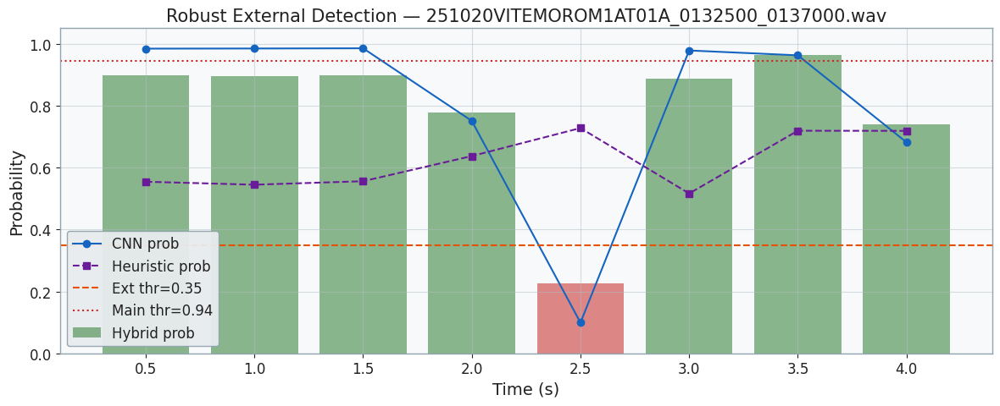

{'file': '/content/251020VITEMOROM1AT01A_0132500_0137000.wav',
 'duration_s': 4.5,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.898023328973667,
   'cnn_probability': 0.9839845299720764,
   'heuristic_probability': 0.5541785249800291,
   'label': 'possible_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.8964607959365436,
   'cnn_probability': 0.9844374656677246,
   'heuristic_probability': 0.5445541170118195,
   'label': 'possible_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.8992696562439589,
   'cnn_probability': 0.9851365089416504,
   'heuristic_probability': 0.5558022454531929,
   'label': 'possible_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_thr

In [ ]:
# Tested on 2026/04/28
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0132500_0137000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0132500_0137000.wav | duration=4.50s | 8 segments
  Seg   1 🚁 prob=0.896  cnn=0.981  heur=0.554  [0.00–1.00s]
  Seg   2 🚁 prob=0.893  cnn=0.980  heur=0.545  [0.50–1.50s]
  Seg   3 🚁 prob=0.897  cnn=0.982  heur=0.556  [1.00–2.00s]
  Seg   4 🚁 prob=0.781  cnn=0.755  heur=0.637  [1.50–2.50s]
  Seg   5 🌳 prob=0.184  cnn=0.048  heur=0.728  [2.00–3.00s]
  Seg   6 🚁 prob=0.885  cnn=0.977  heur=0.516  [2.50–3.50s]
  Seg   7 🚁 prob=0.951  cnn=0.946  heur=0.719  [3.00–4.00s]
  Seg   8 🚁 prob=0.371  cnn=0.284  heur=0.718  [3.50–4.50s]

📊 Clip score: 0.914  |  Positive: 7/8  |  Label: drone


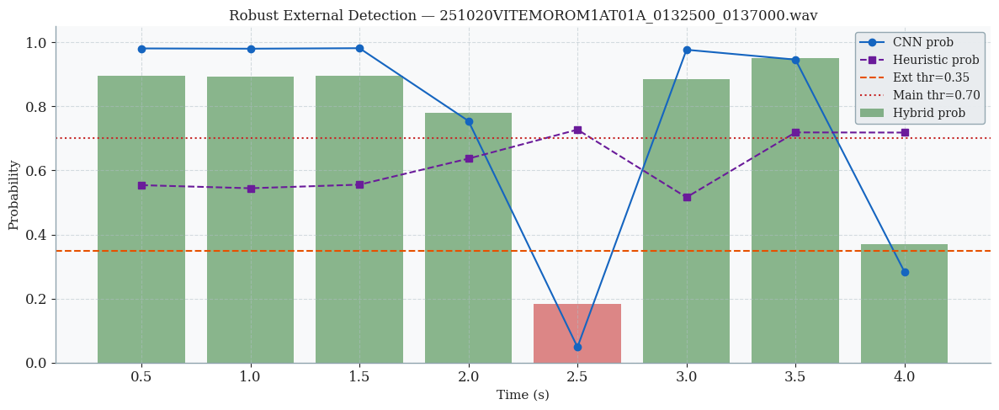

{'file': '/content/251020VITEMOROM1AT01A_0132500_0137000.wav',
 'duration_s': 4.5,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.8957498647707861,
   'cnn_probability': 0.9811426997184753,
   'heuristic_probability': 0.5541785249800291,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.8931675677871296,
   'cnn_probability': 0.980320930480957,
   'heuristic_probability': 0.5445541170118195,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.8966920176178603,
   'cnn_probability': 0.9819144606590271,
   'heuristic_probability': 0.5558022454531929,
   'label': 'drone',
   'detected_at_main_threshold': True,
   'detected_at_external_threshold': True},
  {'segment_in

In [ ]:
# Tested on 2026/04/28
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0132500_0137000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0227000_0230000.wav | duration=3.00s | 5 segments
  Seg   1 🌳 prob=0.128  cnn=0.016  heur=0.577  [0.00–1.00s]
  Seg   2 🌳 prob=0.109  cnn=0.011  heur=0.501  [0.50–1.50s]
  Seg   3 🌳 prob=0.113  cnn=0.012  heur=0.516  [1.00–2.00s]
  Seg   4 🌳 prob=0.132  cnn=0.017  heur=0.594  [1.50–2.50s]
  Seg   5 🌳 prob=0.122  cnn=0.008  heur=0.578  [2.00–3.00s]

📊 Clip score: 0.127  |  Positive: 0/5  |  Label: non_drone


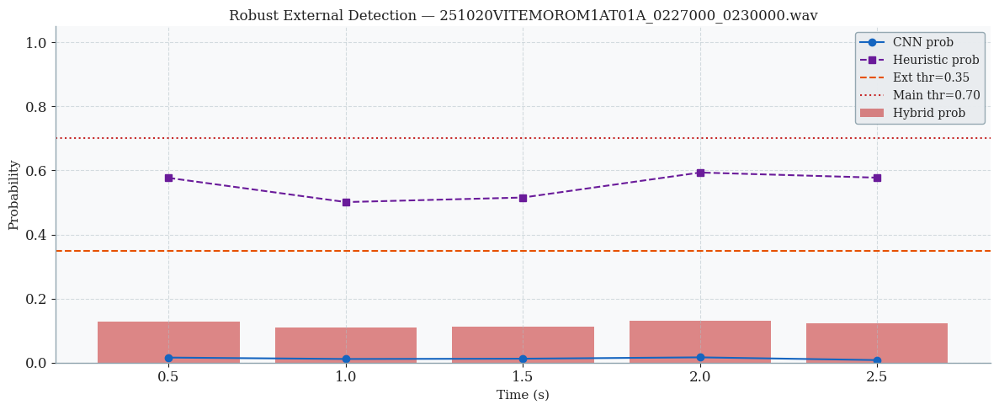

{'file': '/content/251020VITEMOROM1AT01A_0227000_0230000.wav',
 'duration_s': 3.0,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.12801750203479118,
   'cnn_probability': 0.015813158825039864,
   'heuristic_probability': 0.5768348748737965,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.10936223070622529,
   'cnn_probability': 0.011367956176400185,
   'heuristic_probability': 0.5013393288255257,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.11293787231827218,
   'cnn_probability': 0.012280786409974098,
   'heuristic_probability': 0.5155662159514645,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_thresh

In [ ]:
# Tested on 2026/04/28
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0227000_0230000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0227000_0230000.wav | duration=3.00s | 5 segments
  Seg   1 🌳 prob=0.128  cnn=0.016  heur=0.577  [0.00–1.00s]
  Seg   2 🌳 prob=0.109  cnn=0.011  heur=0.501  [0.50–1.50s]
  Seg   3 🌳 prob=0.113  cnn=0.012  heur=0.516  [1.00–2.00s]
  Seg   4 🌳 prob=0.132  cnn=0.017  heur=0.594  [1.50–2.50s]
  Seg   5 🌳 prob=0.122  cnn=0.008  heur=0.578  [2.00–3.00s]

📊 Clip score: 0.127  |  Positive: 0/5  |  Label: non_drone


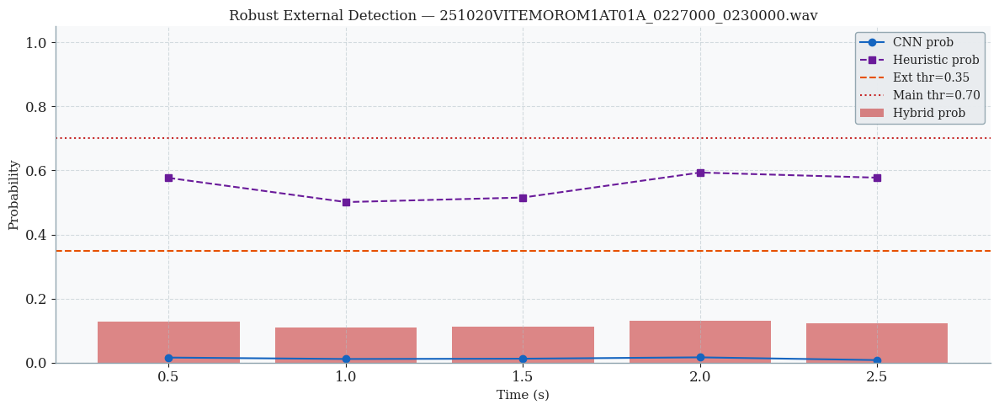

{'file': '/content/251020VITEMOROM1AT01A_0227000_0230000.wav',
 'duration_s': 3.0,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.12801750203479118,
   'cnn_probability': 0.015813158825039864,
   'heuristic_probability': 0.5768348748737965,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.10936223070622529,
   'cnn_probability': 0.011367956176400185,
   'heuristic_probability': 0.5013393288255257,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.11293787231827218,
   'cnn_probability': 0.012280786409974098,
   'heuristic_probability': 0.5155662159514645,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_thresh

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0227000_0230000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)


🎧 Robust External Audio Analysis
🎵 File: 251020VITEMOROM1AT01A_0219000_0221000.wav | duration=2.00s | 3 segments
  Seg   1 🌳 prob=0.136  cnn=0.024  heur=0.583  [0.00–1.00s]
  Seg   2 🌳 prob=0.139  cnn=0.024  heur=0.598  [0.50–1.50s]
  Seg   3 🌳 prob=0.135  cnn=0.010  heur=0.633  [1.00–2.00s]

📊 Clip score: 0.137  |  Positive: 0/3  |  Label: non_drone


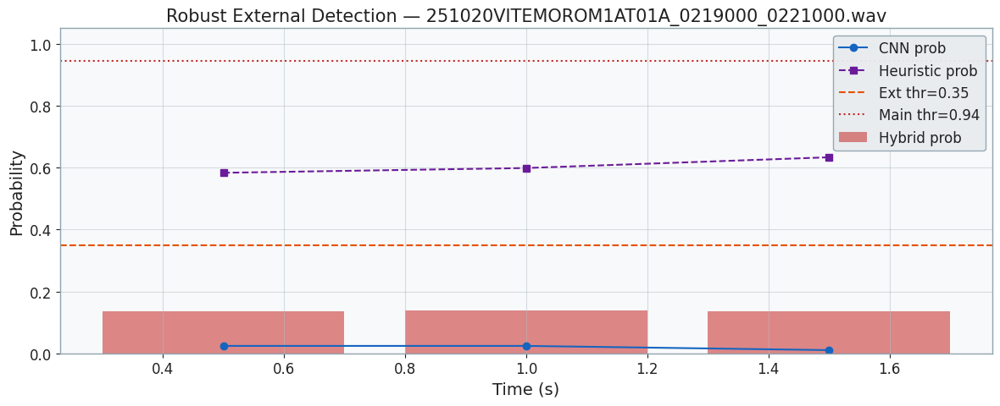

{'file': '/content/251020VITEMOROM1AT01A_0219000_0221000.wav',
 'duration_s': 2.0,
 'segment_results': [{'segment_index': 1,
   't_start_s': 0.0,
   't_end_s': 1.0,
   'probability': 0.1357918559676164,
   'cnn_probability': 0.023975232616066933,
   'heuristic_probability': 0.5830583493738143,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 2,
   't_start_s': 0.5,
   't_end_s': 1.5,
   'probability': 0.13887624556265152,
   'cnn_probability': 0.02398788183927536,
   'heuristic_probability': 0.5984297004561562,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold': False},
  {'segment_index': 3,
   't_start_s': 1.0,
   't_end_s': 2.0,
   'probability': 0.1348707722384692,
   'cnn_probability': 0.010308324359357357,
   'heuristic_probability': 0.6331205637549165,
   'label': 'non_drone',
   'detected_at_main_threshold': False,
   'detected_at_external_threshold

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/251020VITEMOROM1AT01A_0219000_0221000.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)

In [ ]:
# Tested on 2026/04/28
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

# analyze the test files
zip_path = "/content/drone_test_files.zip"
# Unzip the files and then run test for each tests in the subfolder

# Load the test dataset from the zip file
test_ds = load_test_dataset_zip(
  zip_path,
  cfg=config,
  dataset_format="auto", # Let it auto-detect the format
)

# Run the evaluation on the loaded dataset
results = run_test_dataset_evaluation(
  test_ds,
  config,
  save_csv=zip_path.replace(".zip", "_results.csv") # Save results to a CSV
)

print(results)

📂 Extracting to temp dir: /tmp/drone_test_p8k3xgxr
📦 Loading test dataset from drone_test_files.zip …
✅ Extracted to /tmp/drone_test_p8k3xgxr
   ZIP contents (87 files, first 20):
     yt_tmp_drone_00002_r001_p30.wav
     yt_tmp_drone_00002_r001_p29.wav
     yt_tmp_drone_00002_r001_p39.wav
     yt_tmp_drone_00002_r001_p63.wav
     yt_tmp_drone_00002_r001_p58.wav
     yt_tmp_drone_00002_r001_p17.wav
     yt_tmp_drone_00002_r001_p52.wav
     yt_tmp_drone_00002_r001_p62.wav
     yt_tmp_drone_00002_r001_p32.wav
     yt_tmp_drone_00002_r001_p22.wav
     yt_tmp_drone_00002_r001_p19.wav
     yt_tmp_drone_00002_r001_p54.wav
     yt_tmp_drone_00002_r001_p56.wav
     yt_tmp_drone_00002_r001_p46.wav
     yt_tmp_drone_00002_r001_p50.wav
     yt_tmp_drone_00002_r001_p44.wav
     yt_tmp_drone_00002_r001_p01.wav
     yt_tmp_drone_00003_r001_p04.wav
     yt_tmp_drone_00002_r001_p14.wav
     yt_tmp_drone_00002_r001_p09.wav
     … and 67 more
   Detected format: 'flat_wavs'
   Indexing sessions (format=

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

# analyze the test files
zip_path = "/content/drone_test_files.zip"
# Unzip the files and then run test for each tests in the subfolder

# Load the test dataset from the zip file
test_ds = load_test_dataset_zip(
  zip_path,
  cfg=config,
  dataset_format="auto", # Let it auto-detect the format
)

# Run the evaluation on the loaded dataset
results = run_test_dataset_evaluation(
  test_ds,
  config,
  save_csv=zip_path.replace(".zip", "_results.csv") # Save results to a CSV
)

print(results)

📂 Extracting to temp dir: /tmp/drone_test_x12xi262
📦 Loading test dataset from drone_test_files.zip …
✅ Extracted to /tmp/drone_test_x12xi262
   ZIP contents (87 files, first 20):
     yt_tmp_drone_00002_r001_p40.wav
     yt_tmp_drone_00002_r001_p11.wav
     yt_tmp_drone_00002_r001_p04.wav
     yt_tmp_drone_00002_r001_p45.wav
     yt_tmp_drone_00002_r001_p06.wav
     yt_tmp_drone_00002_r001_p21.wav
     yt_tmp_drone_00002_r001_p48.wav
     yt_tmp_drone_00002_r001_p18.wav
     yt_tmp_drone_00003_r001_p04.wav
     yt_tmp_drone_00002_r001_p28.wav
     yt_tmp_drone_00002_r001_p29.wav
     yt_tmp_drone_00002_r001_p02.wav
     yt_tmp_drone_00002_r001_p55.wav
     yt_tmp_drone_00002_r001_p61.wav
     yt_tmp_drone_00002_r001_p30.wav
     yt_tmp_drone_00001_r001_p02.wav
     yt_tmp_drone_00002_r001_p07.wav
     yt_tmp_drone_00002_r001_p54.wav
     yt_tmp_drone_00002_r001_p41.wav
     yt_tmp_drone_00002_r001_p58.wav
     … and 67 more
   Detected format: 'flat_wavs'
   Indexing sessions (format=

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip(
  "/content/drone_test_files.zip",
  cfg=config,
  dataset_format="auto",   # or "uavirbase" / "pannoniafs" / "generic_triplet" / "flat_wavs" - # bypass auto-detect
  max_sessions=10,         # optional — useful for a quick smoke test
)
print(test_ds)  # shows session count and format

results = run_test_dataset_evaluation(test_ds, config, save_csv="/content/drive/MyDrive/AUS LAB II/test_dataset/drone_test_files_results.csv")

📂 Extracting to temp dir: /tmp/drone_test_bkesagf0
📦 Loading test dataset from drone_test_files.zip …
✅ Extracted to /tmp/drone_test_bkesagf0
   ZIP contents (87 files, first 20):
     yt_tmp_drone_00002_r001_p40.wav
     yt_tmp_drone_00002_r001_p11.wav
     yt_tmp_drone_00002_r001_p04.wav
     yt_tmp_drone_00002_r001_p45.wav
     yt_tmp_drone_00002_r001_p06.wav
     yt_tmp_drone_00002_r001_p21.wav
     yt_tmp_drone_00002_r001_p48.wav
     yt_tmp_drone_00002_r001_p18.wav
     yt_tmp_drone_00003_r001_p04.wav
     yt_tmp_drone_00002_r001_p28.wav
     yt_tmp_drone_00002_r001_p29.wav
     yt_tmp_drone_00002_r001_p02.wav
     yt_tmp_drone_00002_r001_p55.wav
     yt_tmp_drone_00002_r001_p61.wav
     yt_tmp_drone_00002_r001_p30.wav
     yt_tmp_drone_00001_r001_p02.wav
     yt_tmp_drone_00002_r001_p07.wav
     yt_tmp_drone_00002_r001_p54.wav
     yt_tmp_drone_00002_r001_p41.wav
     yt_tmp_drone_00002_r001_p58.wav
     … and 67 more
   Detected format: 'flat_wavs'
   Indexing sessions (format=

In [ ]:
import shutil, sys

# Clear pycache
shutil.rmtree("/content/drive/MyDrive/AUS LAB II/drone_detection/__pycache__", ignore_errors=True)

# Remove any cached imports
for key in list(sys.modules.keys()):
    if "drone_detection" in key:
        del sys.modules[key]

# Re-import fresh
sys.path.insert(0, "/content/drive/MyDrive/AUS LAB II")
import drone_detection.mems_inference
from drone_detection import analyse_mems_file, batch_analyse_mems, build_mems_report, config

print("✅ Ready")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


✅ Ready


In [ ]:
import sys

# Clear all cached drone_detection modules
for key in list(sys.modules.keys()):
    if "drone_detection" in key:
        del sys.modules[key]

# Re-import fresh
sys.path.insert(0, "/content/drive/MyDrive/AUS LAB II")
from drone_detection import (
    config,
    analyse_mems_file,
    batch_analyse_mems,
    build_mems_report,
    print_crosscheck,
)
print("✅ Ready")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Ready


In [ ]:
from google.colab import files
import os

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

In [ ]:
from google.colab import files
import os

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Saving 251020VITEMOROM1AT01A_0227000_0230000_meta.json to 251020VITEMOROM1AT01A_0227000_0230000_meta.json
Saving 251020VITEMOROM1AT01A_0227000_0230000.wav to 251020VITEMOROM1AT01A_0227000_0230000.wav
Saving 251020VITEMOROM1AT01A_0219000_0221000_meta.json to 251020VITEMOROM1AT01A_0219000_0221000_meta.json
Saving 251020VITEMOROM1AT01A_0219000_0221000.wav to 251020VITEMOROM1AT01A_0219000_0221000.wav
Saving 251020VITEMOROM1AT01A_0132500_0137000_meta.json to 251020VITEMOROM1AT01A_0132500_0137000_meta.json
Saving 251020VITEMOROM1AT01A_0132500_0137000.wav to 251020VITEMOROM1AT01A_0132500_0137000.wav
Saving 251020VITEMOROM1AT01A_0111000_0125000_meta.json to 251020VITEMOROM1AT01A_0111000_0125000_meta.json
Saving 251020VITEMOROM1AT01A_0111000_0125000.wav to 251020VITEMOROM1AT01A_0111000_0125000.wav
Saving 251020VITEMOROM1AT01A_0106500_0109000_meta.json to 251020VITEMOROM1AT01A_0106500_0109000_meta.json
Saving 251020VITEMOROM1AT01A_0106500_0109000.wav to 251020VITEMOROM1AT01A_0106500_0109000.wav


/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0071000_0076000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


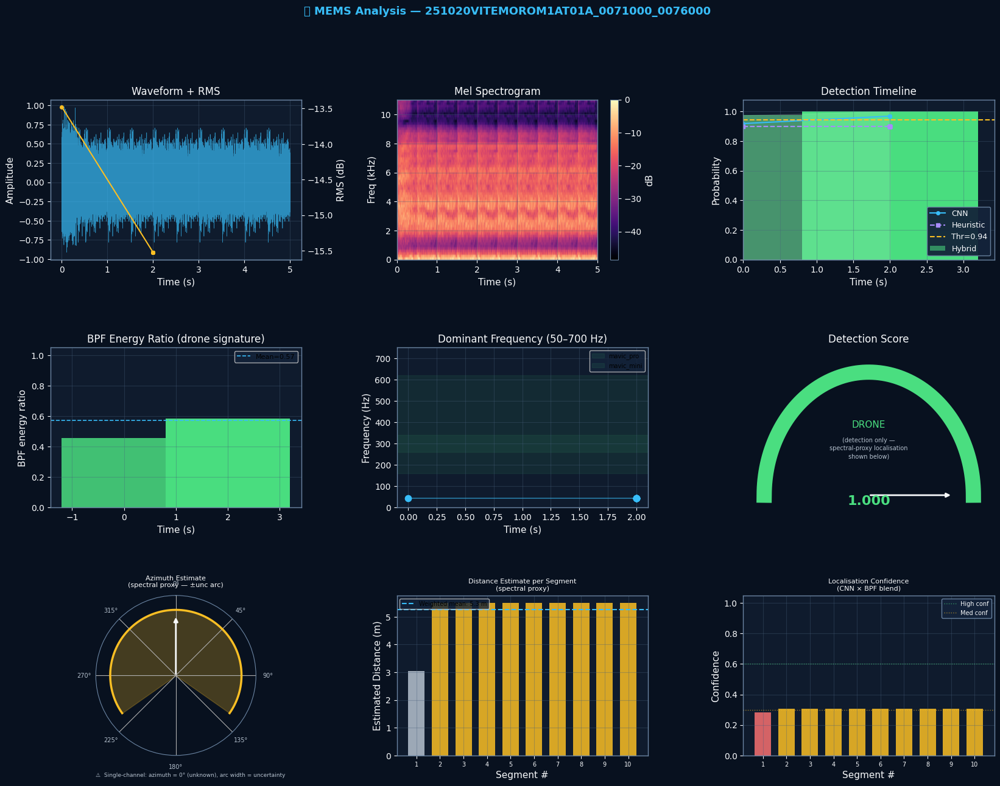


[2/6] 251020VITEMOROM1AT01A_0106500_0109000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0106500_0109000.wav  (2.5s)
   Meta: phase=cruise  dur=2.5s  rms=-36.1dBFS  snr=1.0dB  f0≈5.4Hz
   ⚠️  Low SNR (1.0 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta (ground-truth): 5.38 Hz
  Seg   1  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   2  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   3  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   4  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   5  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   6  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   7  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   8  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   9  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg  10  🚁  conf=1.000  rms=-13.7dB  f0=11Hz  bpf=0.54

  📊 10/10 detected  |

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0106500_0109000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


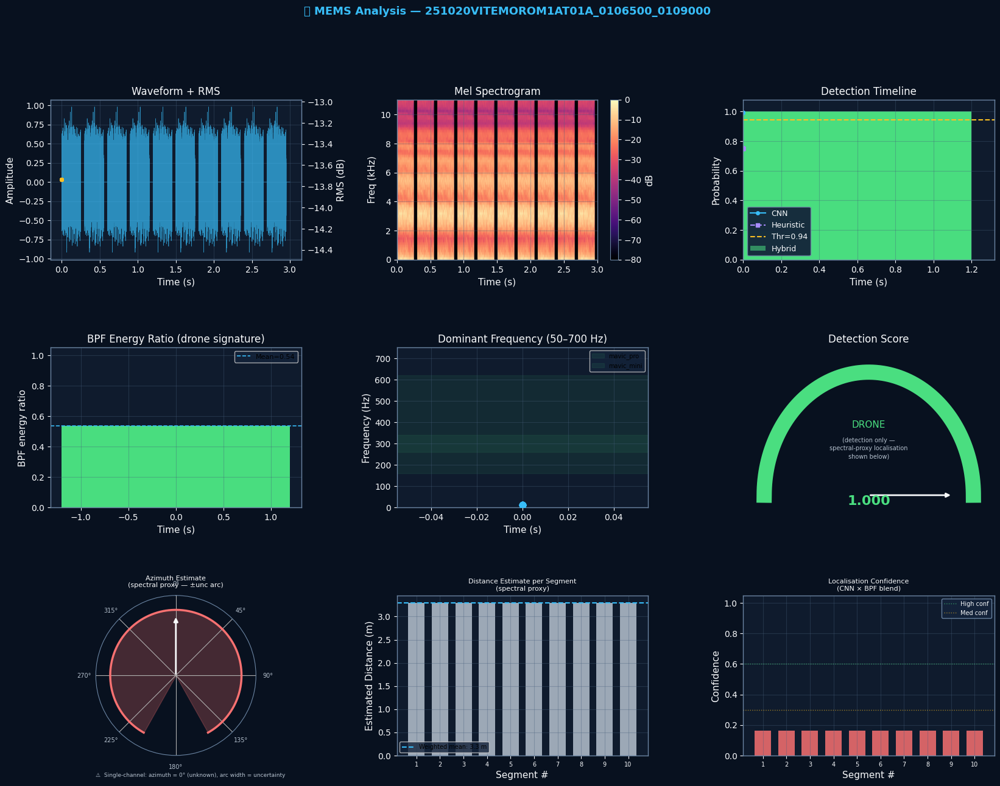


[3/6] 251020VITEMOROM1AT01A_0111000_0125000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0111000_0125000.wav  (14.0s)
   Meta: phase=cruise  dur=14.0s  rms=-34.5dBFS  snr=4.8dB  f0≈5.4Hz
   ⚠️  Low SNR (4.8 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta (ground-truth): 5.38 Hz
  Seg   1  🌳  conf=0.154  rms=-17.7dB  f0=32Hz  bpf=0.75
  Seg   2  🌳  conf=0.319  rms=-14.1dB  f0=32Hz  bpf=0.20
  Seg   3  🌳  conf=0.428  rms=-15.9dB  f0=11Hz  bpf=0.42
  Seg   4  🌳  conf=0.810  rms=-15.9dB  f0=11Hz  bpf=1.00
  Seg   5  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   6  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   7  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   8  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   9  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg  10  🚁  conf=1.000  rms=-16.0dB  f0=11Hz  bpf=1.00

  📊 6/10 detected  

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0111000_0125000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


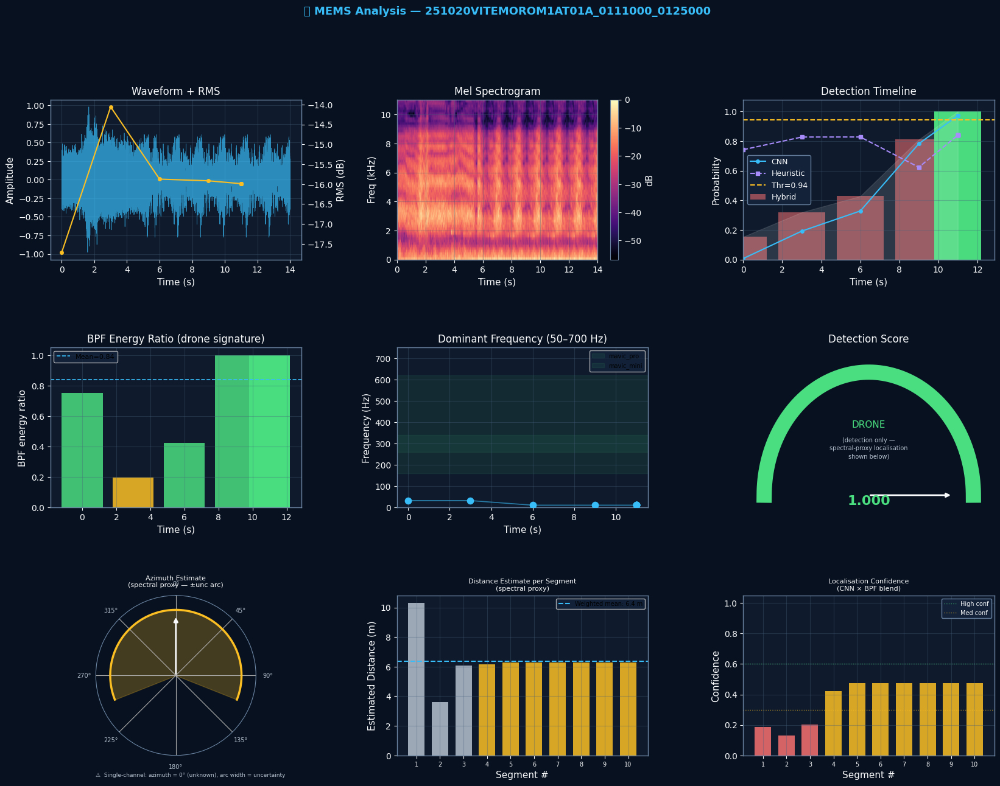


[4/6] 251020VITEMOROM1AT01A_0132500_0137000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0132500_0137000.wav  (4.5s)
   Meta: phase=cruise  dur=4.5s  rms=-35.0dBFS  snr=8.5dB  f0≈5.4Hz
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta (ground-truth): 5.38 Hz
  Seg   1  🌳  conf=0.548  rms=-18.5dB  f0=11Hz  bpf=0.31
  Seg   2  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   3  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   4  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   5  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   6  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   7  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   8  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   9  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg  10  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.22

  📊 9/10 detected  |  peak_prob=1.000  bpf_mean=0.23  dom_f=11Hz
  📡 Spectral-proxy loc

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0132500_0137000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


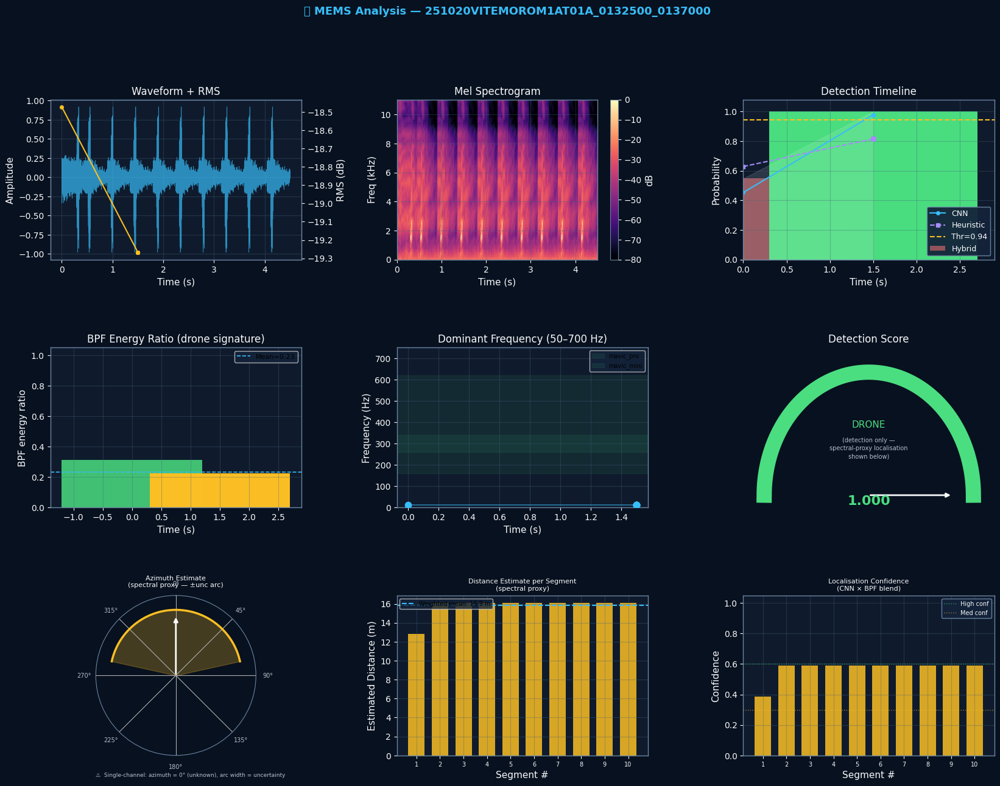


[5/6] 251020VITEMOROM1AT01A_0219000_0221000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0219000_0221000.wav  (2.0s)
   Meta: phase=cruise  dur=2.0s  rms=-39.7dBFS  snr=3.7dB  f0≈53.8Hz
   ⚠️  Low SNR (3.7 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta (ground-truth): 53.83 Hz
  Seg   1  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   2  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   3  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   4  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   5  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   6  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   7  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   8  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   9  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg  10  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75

  📊 0/10 detected  

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0219000_0221000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


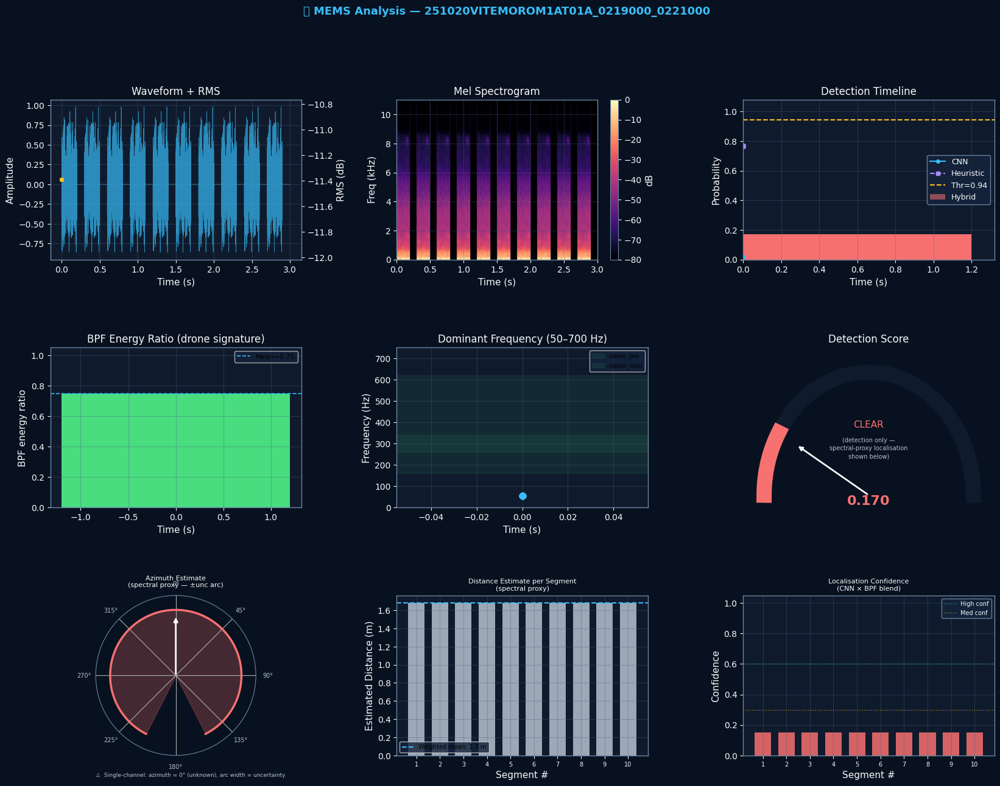


[6/6] 251020VITEMOROM1AT01A_0227000_0230000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0227000_0230000.wav  (3.0s)
   Meta: phase=cruise  dur=3.0s  rms=-36.8dBFS  snr=5.9dB  f0≈5.4Hz
   ⚠️  Low SNR (5.9 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta (ground-truth): 5.38 Hz
  Seg   1  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   2  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   3  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   4  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   5  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   6  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   7  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   8  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   9  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg  10  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00

  📊 0/10 detected  | 

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:546: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0227000_0230000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


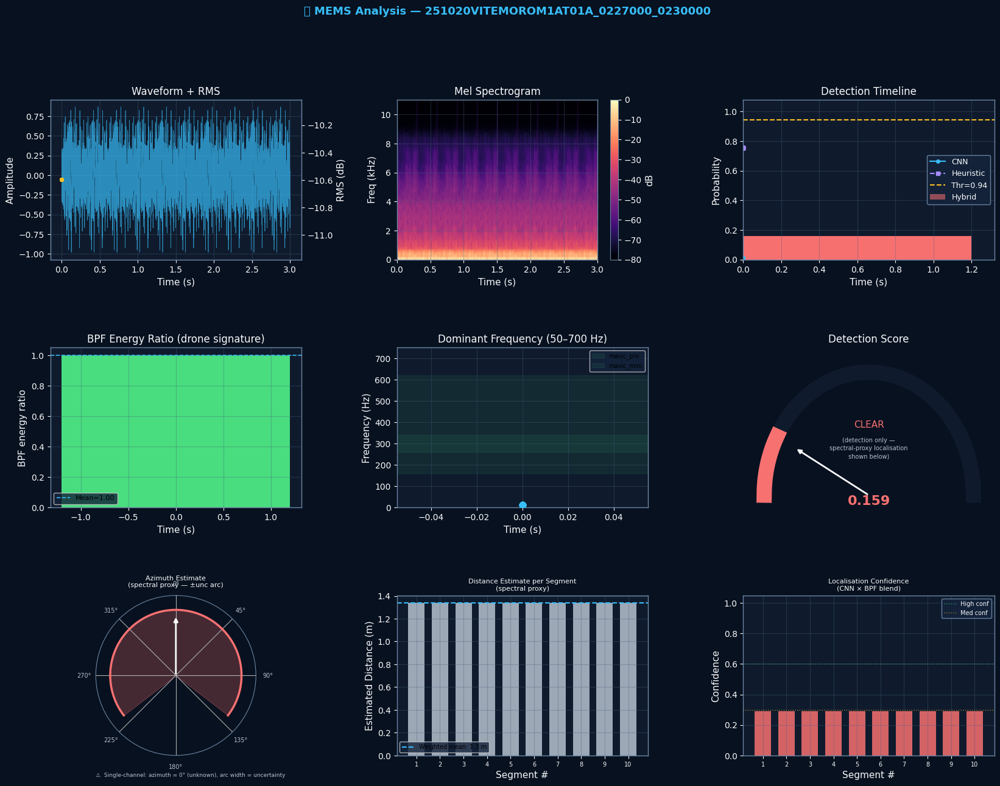


  BATCH SUMMARY — 6 files
  Detection rate  : 66.7%  (4/6)
  Mean BPF ratio  : 0.654
  Mean dom. freq  : 23.3 Hz
  Localisation    : ❌ N/A — single-channel MEMS recording

File                                      Det  Prob   f0(Hz)   BPF    Dist(m)  Dur(s)  Check     
-------------------------------------------------------------------------------------------------
251020VITEMOROM1AT01A_0071000_0076000.wa  YES  1.000     43.1  0.570      5.3     5.0  CAUTION
251020VITEMOROM1AT01A_0106500_0109000.wa  YES  1.000     10.8  0.535      3.3     2.5  UNRELIABLE
251020VITEMOROM1AT01A_0111000_0125000.wa  YES  1.000     10.8  0.837      6.4    14.0  CAUTION
251020VITEMOROM1AT01A_0132500_0137000.wa  YES  1.000     10.8  0.234     15.9     4.5  CAUTION
251020VITEMOROM1AT01A_0219000_0221000.wa  no   0.170     53.8  0.747      1.7     2.0  UNRELIABLE
251020VITEMOROM1AT01A_0227000_0230000.wa  no   0.159     10.8  1.000      1.3     3.0  UNRELIABLE


In [ ]:
from google.colab import files
import os

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")


🎵 MEMS: 251020VITEMOROM1AT01A_0132500_0137000.wav  (4.5s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 10.77 Hz
  Seg   1  🚁  conf=0.944  rms=-18.5dB  f0=11Hz  bpf=0.23
  Seg   2  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   3  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   4  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   5  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   6  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   7  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   8  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg   9  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19
  Seg  10  🚁  conf=1.000  rms=-19.3dB  f0=11Hz  bpf=0.19

  📊 10/10 detected  |  peak_prob=1.000  bpf_mean=0.20  dom_f=11Hz
  📡 Spectral-proxy localisation  |  dist≈0.5 m  height≈0.1 m  az_unc=±156°  conf=0.14
  ⚠️  Azimuth is unresolvable from single-channel — unc

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0132500_0137000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


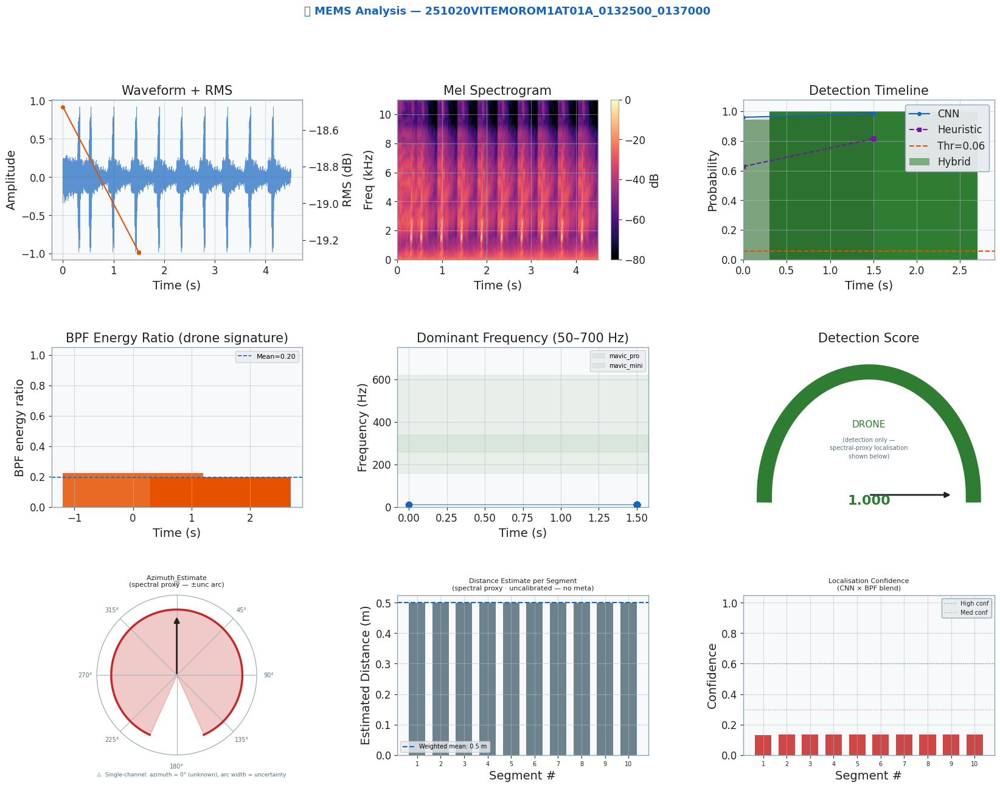


🎵 MEMS: klemenflerin-drone-fly-397287_0010000_0247920.wav  (237.9s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 226.10 Hz
  Seg   1  🚁  conf=1.000  rms=-15.9dB  f0=226Hz  bpf=0.60
  Seg   2  🚁  conf=1.000  rms=-15.9dB  f0=226Hz  bpf=0.65
  Seg   3  🚁  conf=1.000  rms=-15.0dB  f0=215Hz  bpf=0.76
  Seg   4  🚁  conf=1.000  rms=-13.7dB  f0=226Hz  bpf=0.84
  Seg   5  🚁  conf=1.000  rms=-13.4dB  f0=226Hz  bpf=0.82
  Seg   6  🚁  conf=1.000  rms=-12.9dB  f0=226Hz  bpf=0.85
  Seg   7  🚁  conf=1.000  rms=-12.7dB  f0=226Hz  bpf=0.88
  Seg   8  🚁  conf=1.000  rms=-12.6dB  f0=226Hz  bpf=0.90
  Seg   9  🚁  conf=1.000  rms=-12.7dB  f0=226Hz  bpf=0.80
  Seg  10  🚁  conf=1.000  rms=-16.0dB  f0=215Hz  bpf=0.75

  📊 10/10 detected  |  peak_prob=1.000  bpf_mean=0.78  dom_f=226Hz
  📡 Spectral-proxy localisation  |  dist≈0.5 m  height≈0.1 m  az_unc=±134°  conf=0.26
  ⚠️  Azimuth is unresolvable fro

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_klemenflerin-drone-fly-397287_0010000_0247920.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


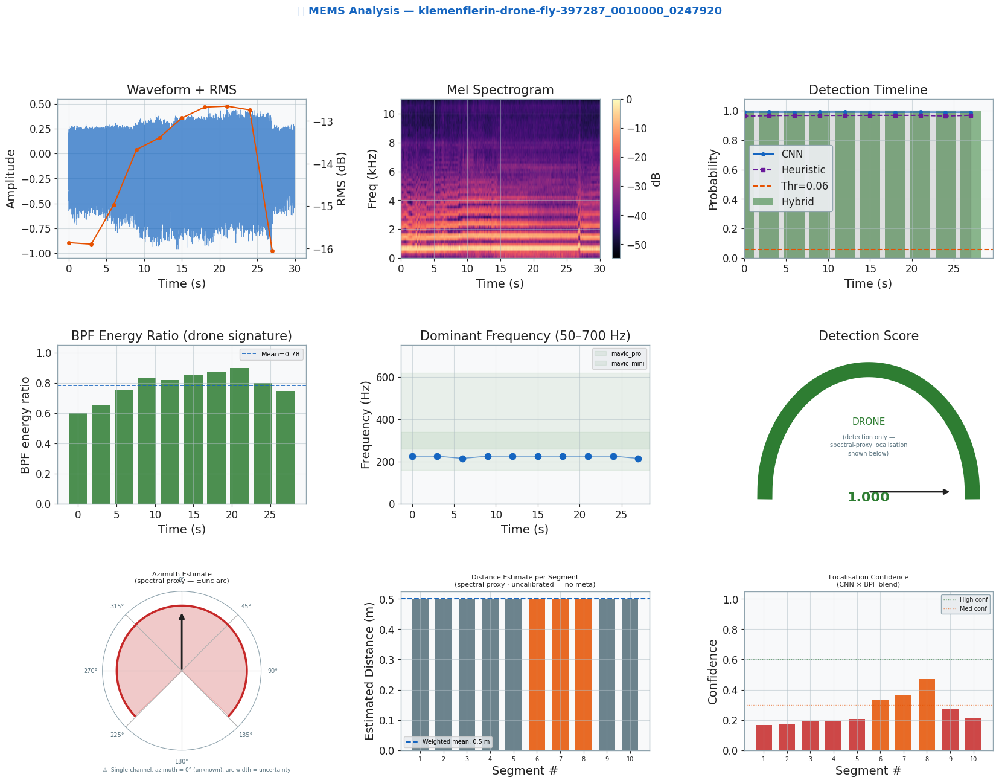

In [ ]:
# Single file analysis
from drone_detection import (
    config,
    analyse_mems_file,
    batch_analyse_mems,
    build_mems_report,
    print_crosscheck,
)
files = [
    "/content/251020VITEMOROM1AT01A_0132500_0137000.wav",
    "/content/klemenflerin-drone-fly-397287_0010000_0247920.wav"
]

for file_path in files:
  result = analyse_mems_file(file_path, config)

In [ ]:
from google.colab import files
import os

from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
🔄 Loading models...
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr=0.055)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=50, val_loss=0.33388)

📂 Mono mode: 6 audio files in /content/drive/MyDrive/drone_segments

────────────────────────────────────────────────────────────
  Processing 6 segments (mono mode)
────────────────────────────────────────────────────────────
  [  1/6] 🚁  251020VITEMOROM1AT01A_0071000_0076000.wav  conf=1.000  rms=-13.5dB  az=-110.5° d=44.9m
  [  2/6] 🚁  251020VITEMOROM1AT01A_0106500_0109000.wav  conf=0.990  rms=-13.7dB  az=-110.6° d=37.7m
  [  3/6] 🚁  251020VITEMOROM1AT01A_0111000_0125000.wav  conf=0.191  rms=-17.7dB  az=-117.7° d=45.2m
  [  4/6] 🚁  251020VITEMOROM1AT01A_0132500_0137000.wav  conf=0.944  rms=-18.5dB  az=-131.2° d=46.9m
  [  5/6] 🚁  251020VITEMOROM1AT01A_0219000_0221000.wav  conf=0.969  rms=-11.4dB  az=-128.6° d=38.6m
  [  6/6] 🚁  251020V

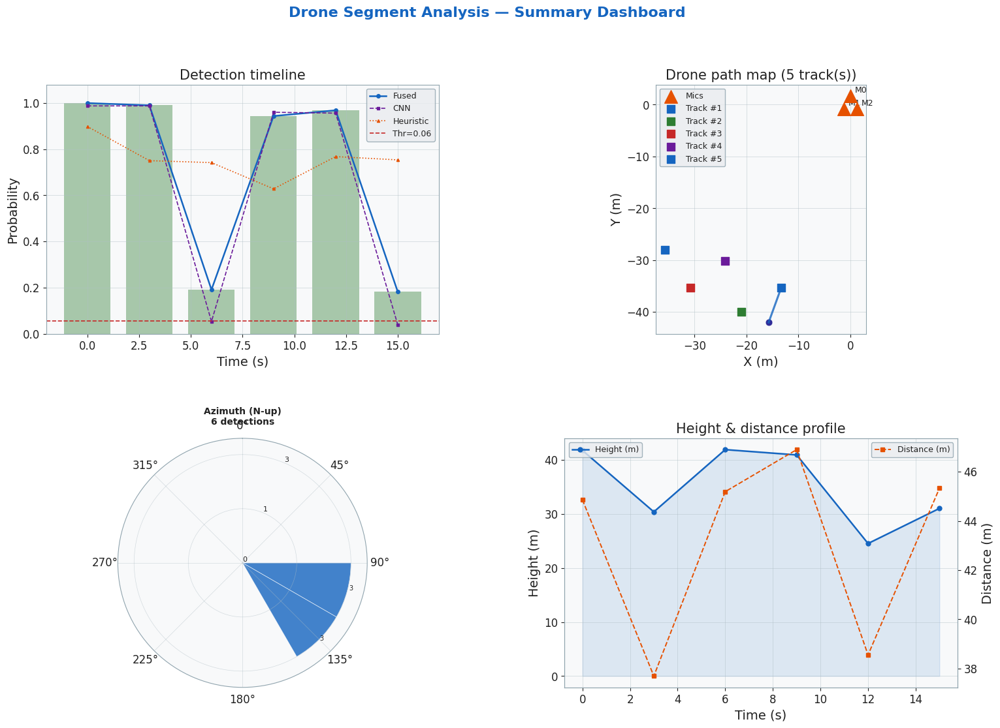

🖼️  Generating individual plots...
  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_timeline.png


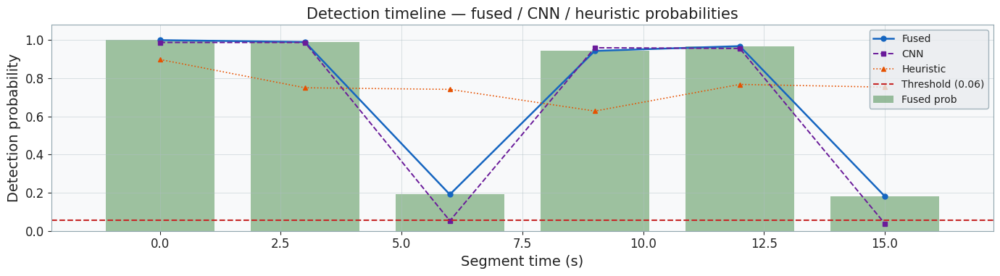

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_path_map.png


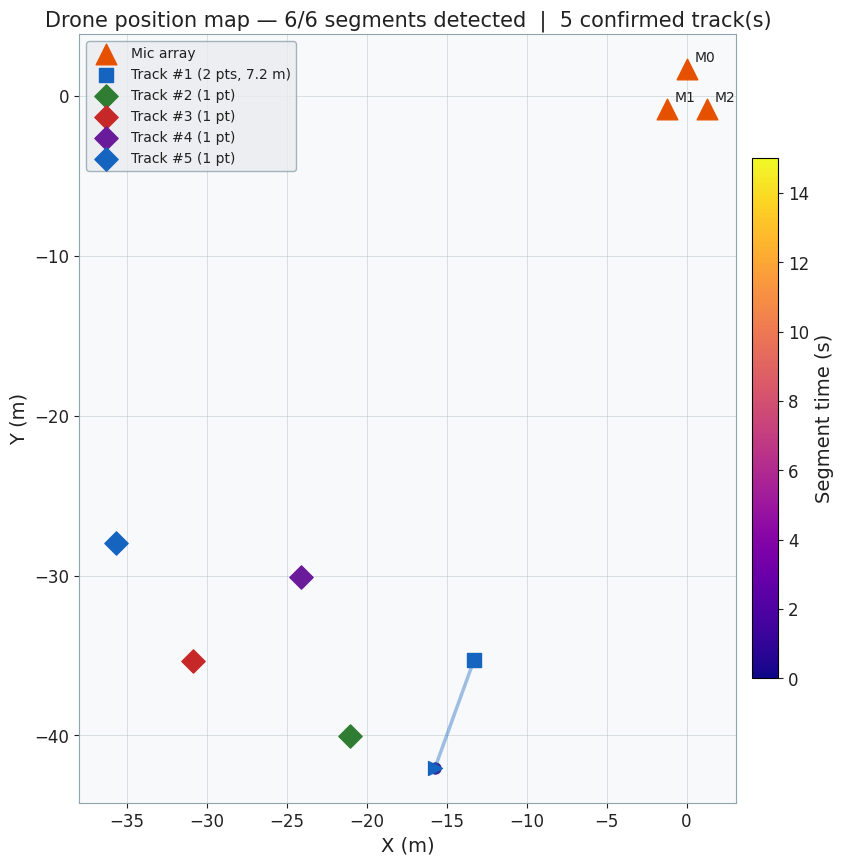

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_polar_azimuth.png


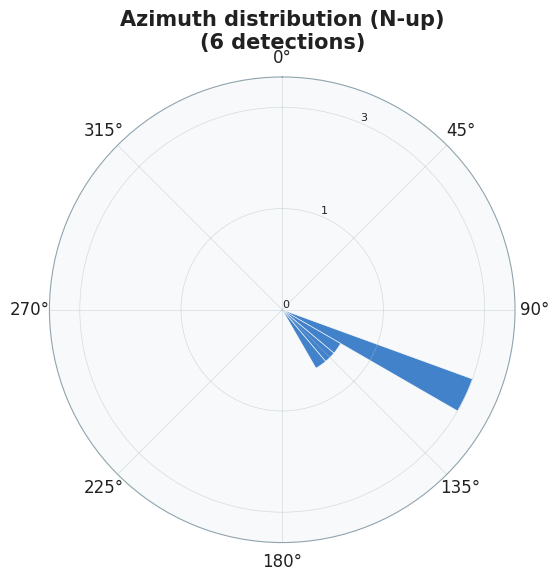

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_height_profile.png


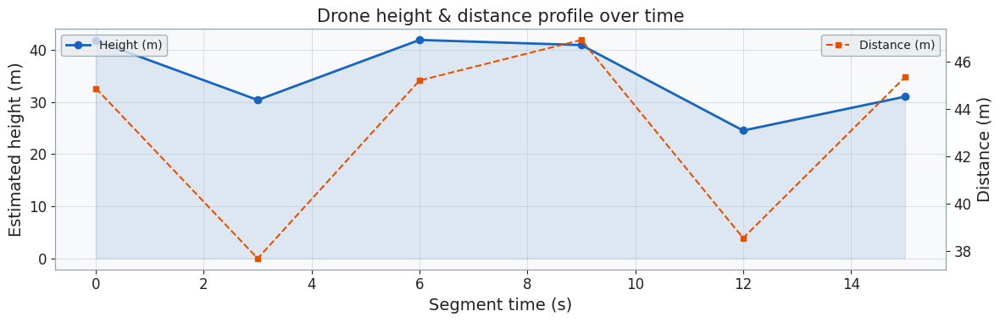

In [ ]:
from drone_detection import run_segment_analysis

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.945
results = run_segment_analysis(
    segment_dir  = "/content/drive/MyDrive/drone_segments",
    cfg          = config,
    file_ext     = [".wav"],
    n_mics       = 1,
    # mic_files    = [
    #     "/content/seg_008_transit_train_ch0.wav",
    #     "/content/seg_008_transit_train_ch1.wav",
    #     "/content/seg_008_transit_train_ch2.wav",
    # ],
    multi_drone  = True,          # enable multi-drone TDOA localization
    show_plots   = True,
    save_plots   = True,
    save_csv     = True,
)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
🔄 Loading models...

📂 3-mic mode: 3 matched segment triplets

────────────────────────────────────────────────────────────
  Processing 3 segments (3-mic mode)
────────────────────────────────────────────────────────────
  [  1/3] 🚁  seg_008_transit_train_ch0.wav        conf=0.974  rms=-37.8dB  no-loc 
  [  2/3] 🚁  seg_008_transit_train_ch1.wav        conf=0.883  rms=-39.6dB  no-loc 
  [  3/3] 🚁  seg_008_transit_train_ch2.wav        conf=0.704  rms=-41.6dB  no-loc 

  ✅ 3/3 segments detected  |  0 confirmed Kalman track(s)

════════════════════════════════════════════════════════════════
  DRONE SEGMENT ANALYSIS — SUMMARY
════════════════════════════════════════════════════════════════
  Total segments     : 3
  Detected           : 3  (100.0%)
  Confirmed tracks   : 0
  Detection threshold: 0.350
════════════════════════════════════════════════════════════════

  💾 CSV saved: /content/drive/MyDrive/drone_v15/logs/segment_analysis_resu

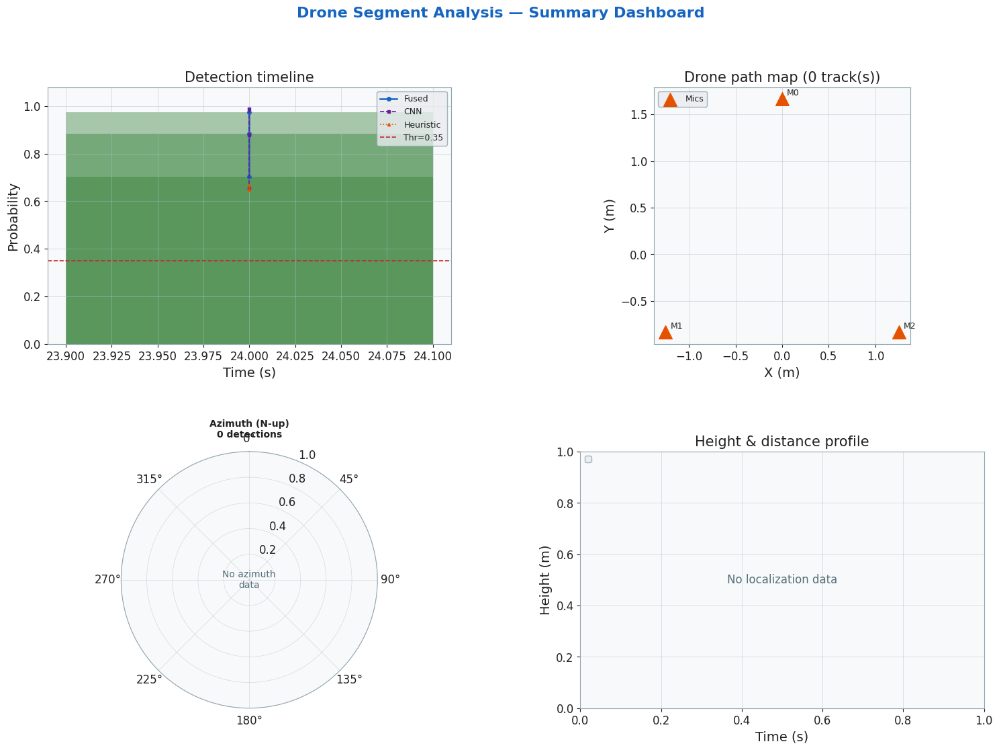

🖼️  Generating individual plots...
  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_timeline.png


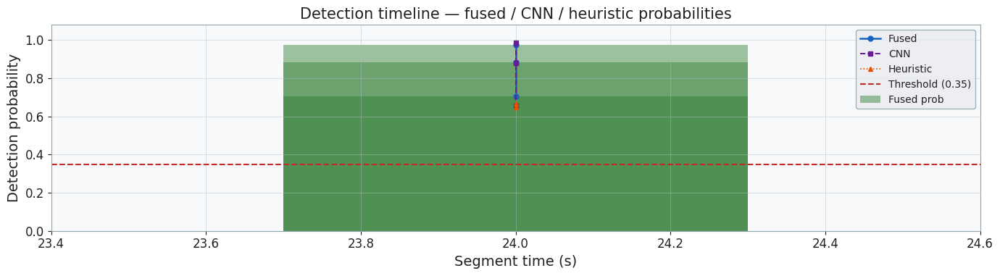

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_path_map.png


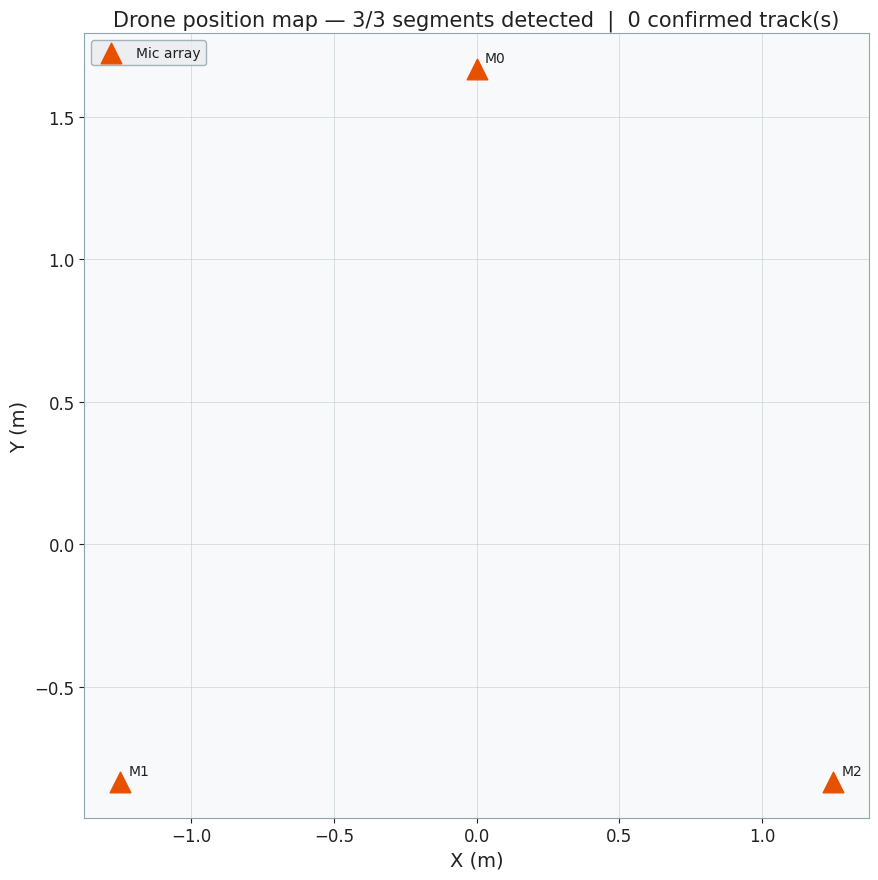

  ⚠️  No detected azimuths to plot.
  ⚠️  No height data to plot.


In [ ]:
from drone_detection import run_segment_analysis

# 3-mic array analysis with multi-drone localization
config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.35
results = run_segment_analysis(
    cfg          = config,
    file_ext     = [".wav"],
    n_mics       = 3,
    mic_files    = [
        "/content/drive/MyDrive/segments_B",
        "/content/drive/MyDrive/segments_B",
        "/content/drive/MyDrive/segments_B",
    ],
    multi_drone  = True,          # enable multi-drone TDOA localization
    show_plots   = True,
    save_plots   = True,
    save_csv     = True,
)

#
import pandas as pd
df = pd.DataFrame([
    {k: r[k] for k in ["seg","filename","t_start","detected",
                        "probability","azimuth_deg","distance_m","height_m"]}
    for r in results["rows"]
])
df.head(20)

# ── Cell 5: Inspect Kalman tracks ─────────────────────────────────────────────

for track in results["confirmed_tracks"]:
    print(track.to_dict())
#

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
🔄 Loading models...

📂 3-mic mode: 1 matched segment triplets

────────────────────────────────────────────────────────────
  Processing 1 segment (3-mic mode)
────────────────────────────────────────────────────────────
  [  1/1] 🚁  seg_008_transit_train_ch0.wav        conf=0.974  rms=-37.8dB  az=37.1° d=0.5m

  ✅ 1/1 segments detected  |  2 confirmed Kalman track(s)

════════════════════════════════════════════════════════════════
  DRONE SEGMENT ANALYSIS — SUMMARY
════════════════════════════════════════════════════════════════
  Total segments     : 1
  Detected           : 1  (100.0%)
  Confirmed tracks   : 2
  Detection threshold: 0.350

  Azimuth (detected segments)
    mean   : 37.1°
    median : 37.1°
    range  : 37.1° – 37.1°

  Distance (detected segments)
    mean   : 0.51 m
    median : 0.51 m
    range  : 0.51 – 0.51 m

  Kalman tracks
    Track #8: 1 pts  |  total dist = 0.00 m  |  active = True
    Track #9: 1 pts  |  t

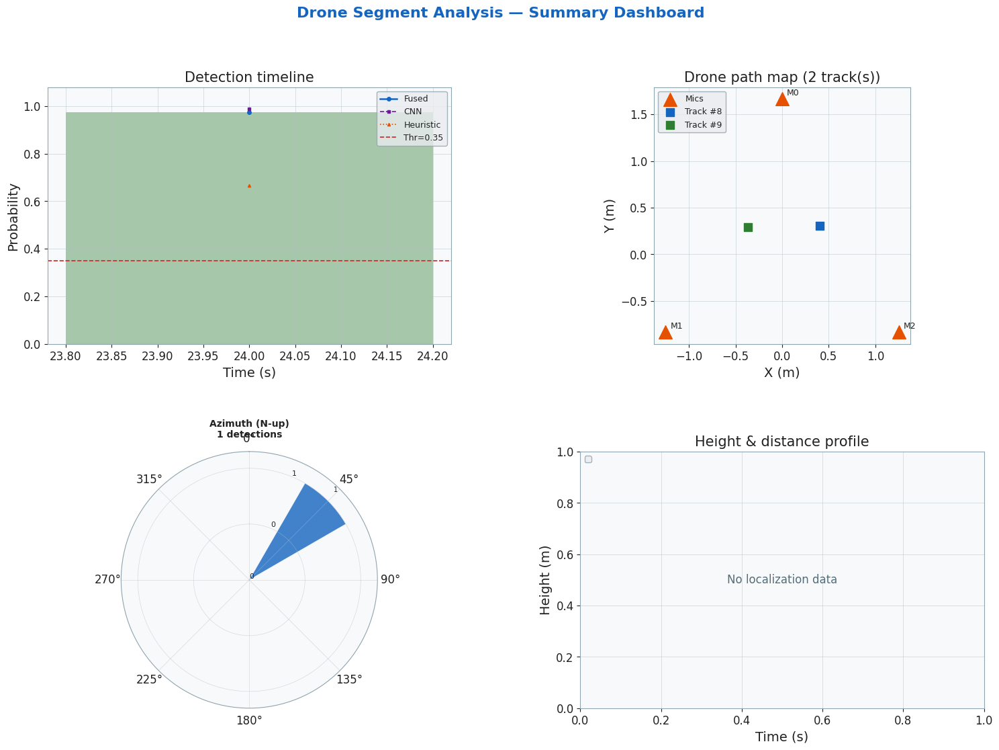

🖼️  Generating individual plots...
  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_timeline.png


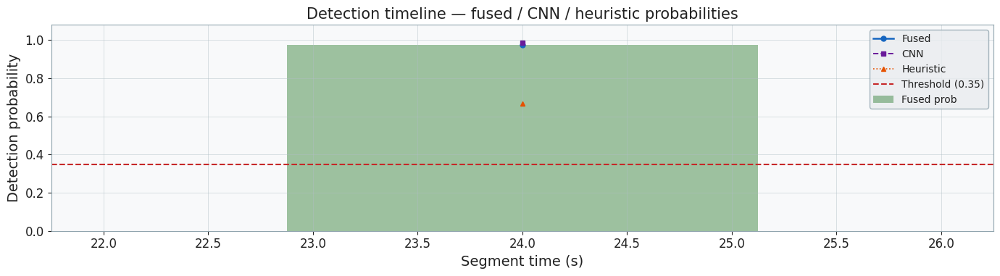

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_path_map.png


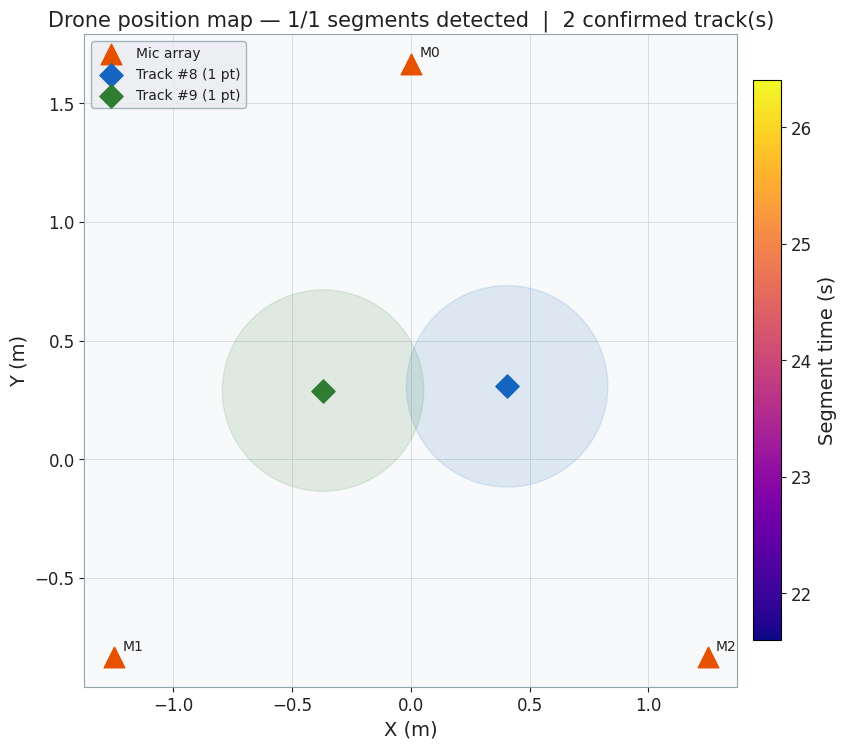

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_polar_azimuth.png


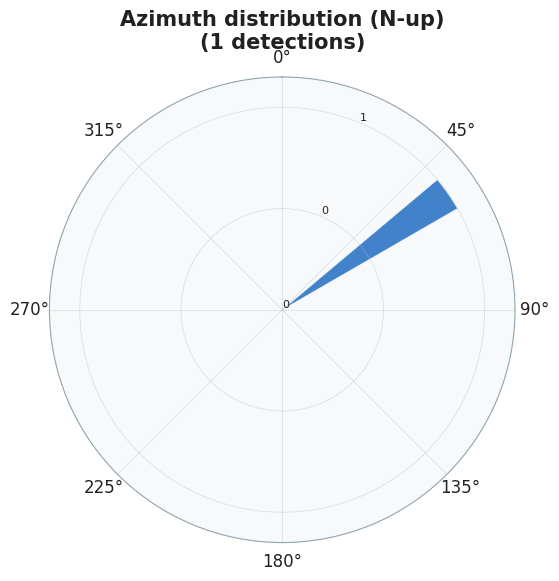

  ⚠️  No height data to plot.
{'track_id': 8, 'positions': [[0.4053848683834076, 0.3068591058254242]], 'timestamps': [1777991948.5711195], 'velocity_mps': [0.0, 0.0], 'total_dist_m': 0.0, 'active': True}
{'track_id': 9, 'positions': [[-0.36991041898727417, 0.2891218960285187]], 'timestamps': [1777991948.5711548], 'velocity_mps': [0.0, 0.0], 'total_dist_m': 0.0, 'active': True}


In [ ]:
from drone_detection import run_segment_analysis

# 3-mic array analysis with multi-drone localization
config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.35
results = run_segment_analysis(
    cfg          = config,
    file_ext     = [".wav"],
    n_mics       = 3,
    mic_files    = [
        "/content/seg_008_transit_train_ch0.wav",
        "/content/seg_008_transit_train_ch1.wav",
        "/content/seg_008_transit_train_ch2.wav",
    ],
    multi_drone  = True,          # enable multi-drone TDOA localization
    show_plots   = True,
    save_plots   = True,
    save_csv     = True,
)

#
import pandas as pd
df = pd.DataFrame([
    {k: r[k] for k in ["seg","filename","t_start","detected",
                        "probability","azimuth_deg","distance_m","height_m"]}
    for r in results["rows"]
])
df.head(20)

# ── Cell 5: Inspect Kalman tracks ─────────────────────────────────────────────

for track in results["confirmed_tracks"]:
    print(track.to_dict())
#

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
🔄 Loading models...

📂 3-mic mode: 3 matched segment triplets

────────────────────────────────────────────────────────────
  Processing 3 segments (3-mic mode)
────────────────────────────────────────────────────────────
  [  1/3] 🚁  seg_008_transit_train_ch0.wav        conf=0.974  rms=-37.8dB  az=-131.5° d=47.5m
  [  2/3] 🌳  seg_008_transit_train_ch1.wav        conf=0.883  rms=-39.6dB  no-loc 
  [  3/3] 🌳  seg_008_transit_train_ch2.wav        conf=0.704  rms=-41.6dB  no-loc 

  ✅ 1/3 segments detected  |  1 confirmed Kalman track(s)

════════════════════════════════════════════════════════════════
  DRONE SEGMENT ANALYSIS — SUMMARY
════════════════════════════════════════════════════════════════
  Total segments     : 3
  Detected           : 1  (33.3%)
  Confirmed tracks   : 1
  Detection threshold: 0.945

  Azimuth (detected segments)
    mean   : -131.5°
    median : -131.5°
    range  : -131.5° – -131.5°

  Distance (detected segm

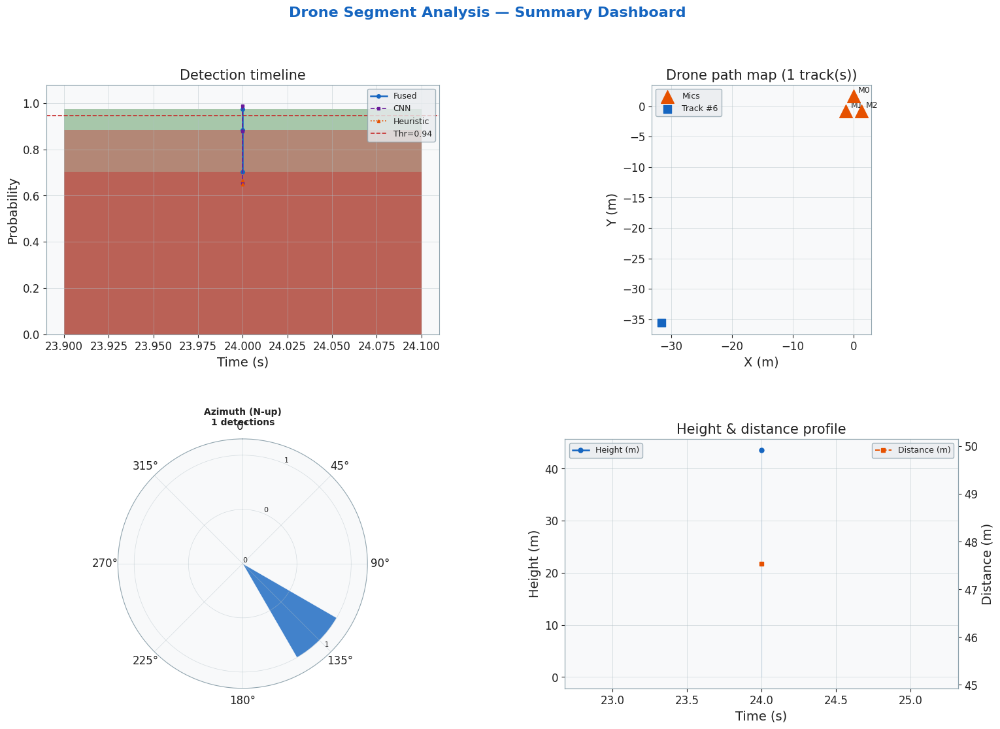

🖼️  Generating individual plots...
  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_timeline.png


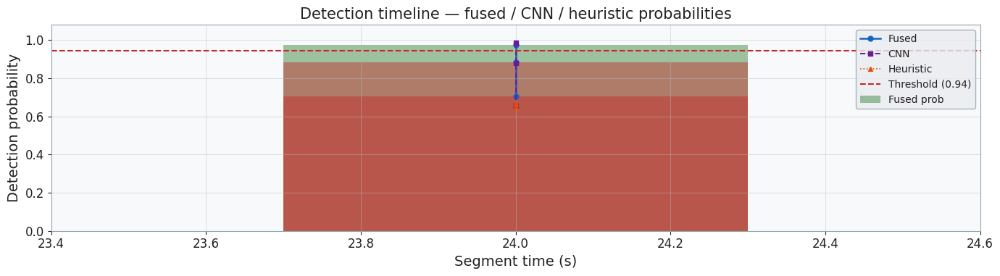

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_path_map.png


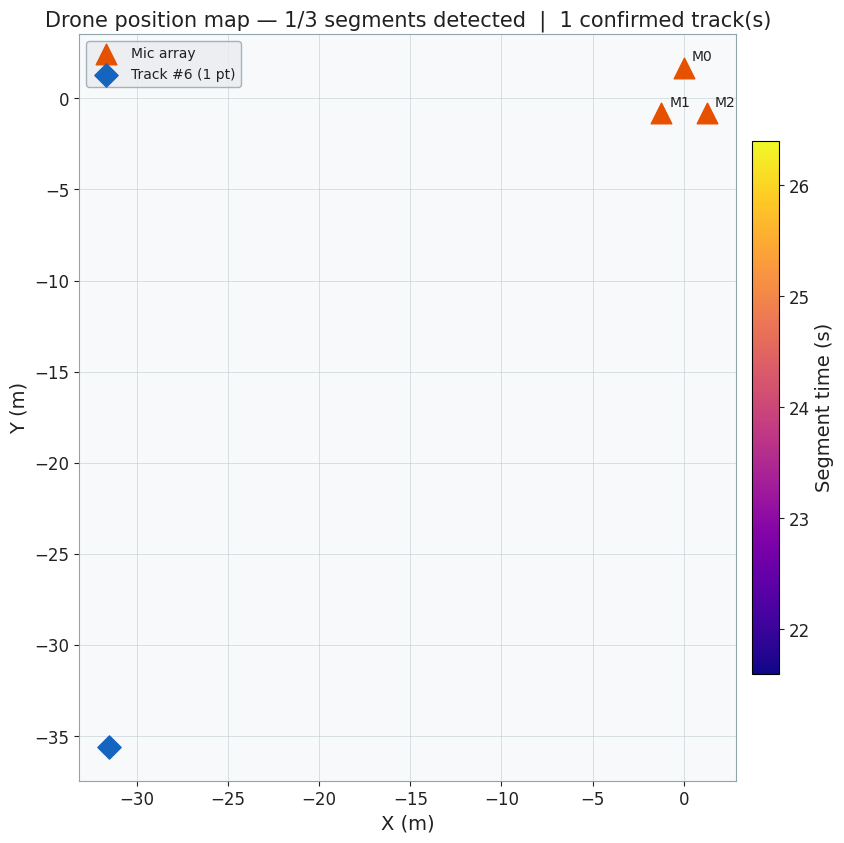

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_polar_azimuth.png


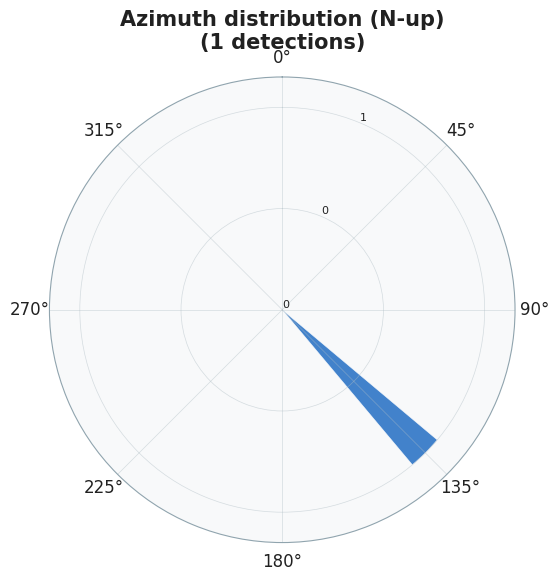

  💾 Saved: /content/drive/MyDrive/drone_v15/logs/plots/segment_height_profile.png


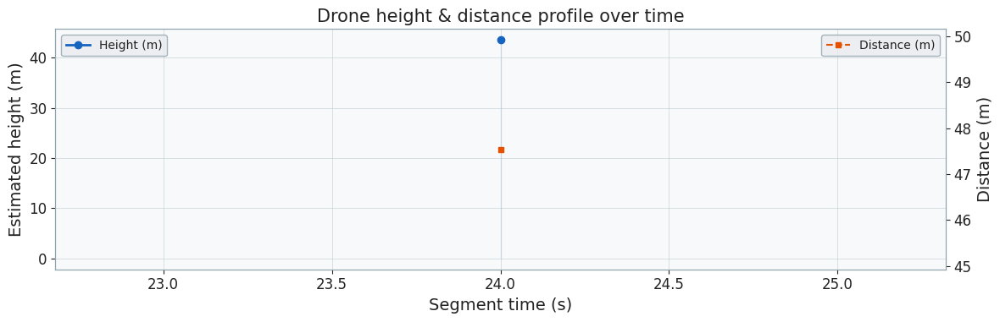

In [ ]:
from drone_detection import run_segment_analysis
#
# ── Cell 3a: Mono / single-mic analysis ──────────────────────────────────────
#

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.945

# 3-mic mode
# Set n_mics=3 and mic_files to a list of 3 directories (one per mic),
# with filenames matching across dirs.  This enables localize() and
# localize_multi_drone() and produces accurate XY positions.

mic_files = [
    "/content/drive/MyDrive/segments_B",
    "/content/drive/MyDrive/segments_B",
    "/content/drive/MyDrive/segments_B",
]
results = run_segment_analysis(cfg=config, n_mics=3, mic_files=mic_files)

In [ ]:
from google.colab import files
import os

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import pandas as pd
from pathlib import Path

validation_results = []

for result in report["results"]:
  xc = result.get("crosscheck", {})

  # Skip files with no crosscheck data at all
  if not xc:
    print(f"⚠️  No meta found for {Path(result['file']).name} — skipping")
    continue

  validation_results.append({
    "file":         Path(result["file"]).name,
    "bpf_error_hz": xc.get("bpf_error_hz",   float("nan")),
    "rms_error_db": xc.get("rms_error_db",    float("nan")),
    "snr_db":       xc.get("snr_db",           float("nan")),
    "det_correct":  xc.get("detection_match",  False),
    "verdict":      xc.get("verdict",          "?"),
    "dist_est_m":   result.get("distance_m",   float("nan")),
  })

if not validation_results:
  print("\n❌ No files with meta JSON found.")
  print("   Make sure _meta.json files are uploaded alongside the .wav files.")
  print("   Expected pattern: <filename>_meta.json in the same folder.\n")
  print("Files processed:")
  for r in report["results"]:
    print(f"  {Path(r['file']).name}  →  crosscheck={'yes' if r.get('crosscheck') else 'no meta'}")
else:
  df = pd.DataFrame(validation_results)
  print(df.to_string(index=False))
  print(f"\nDetection accuracy:  {df['det_correct'].mean()*100:.1f}%")
  print(f"Mean BPF error:      {df['bpf_error_hz'].mean():.2f} Hz")
  print(f"Mean RMS error:      {df['rms_error_db'].mean():.2f} dB")
  print(f"Reliable:   {(df['verdict']=='RELIABLE').sum()}/{len(df)}")
  print(f"Caution:    {(df['verdict']=='CAUTION').sum()}/{len(df)}")
  print(f"Unreliable: {(df['verdict']=='UNRELIABLE').sum()}/{len(df)}")

NameError: name 'report' is not defined

Saving 251020VITEMOROM1AT01A_0227000_0230000_meta.json to 251020VITEMOROM1AT01A_0227000_0230000_meta.json
Saving 251020VITEMOROM1AT01A_0227000_0230000.wav to 251020VITEMOROM1AT01A_0227000_0230000.wav
Saving 251020VITEMOROM1AT01A_0219000_0221000_meta.json to 251020VITEMOROM1AT01A_0219000_0221000_meta.json
Saving 251020VITEMOROM1AT01A_0219000_0221000.wav to 251020VITEMOROM1AT01A_0219000_0221000.wav
Saving 251020VITEMOROM1AT01A_0132500_0137000_meta.json to 251020VITEMOROM1AT01A_0132500_0137000_meta.json
Saving 251020VITEMOROM1AT01A_0132500_0137000.wav to 251020VITEMOROM1AT01A_0132500_0137000.wav
Saving 251020VITEMOROM1AT01A_0111000_0125000_meta.json to 251020VITEMOROM1AT01A_0111000_0125000_meta.json
Saving 251020VITEMOROM1AT01A_0111000_0125000.wav to 251020VITEMOROM1AT01A_0111000_0125000.wav
Saving 251020VITEMOROM1AT01A_0106500_0109000_meta.json to 251020VITEMOROM1AT01A_0106500_0109000_meta.json
Saving 251020VITEMOROM1AT01A_0106500_0109000.wav to 251020VITEMOROM1AT01A_0106500_0109000.wav


/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0071000_0076000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


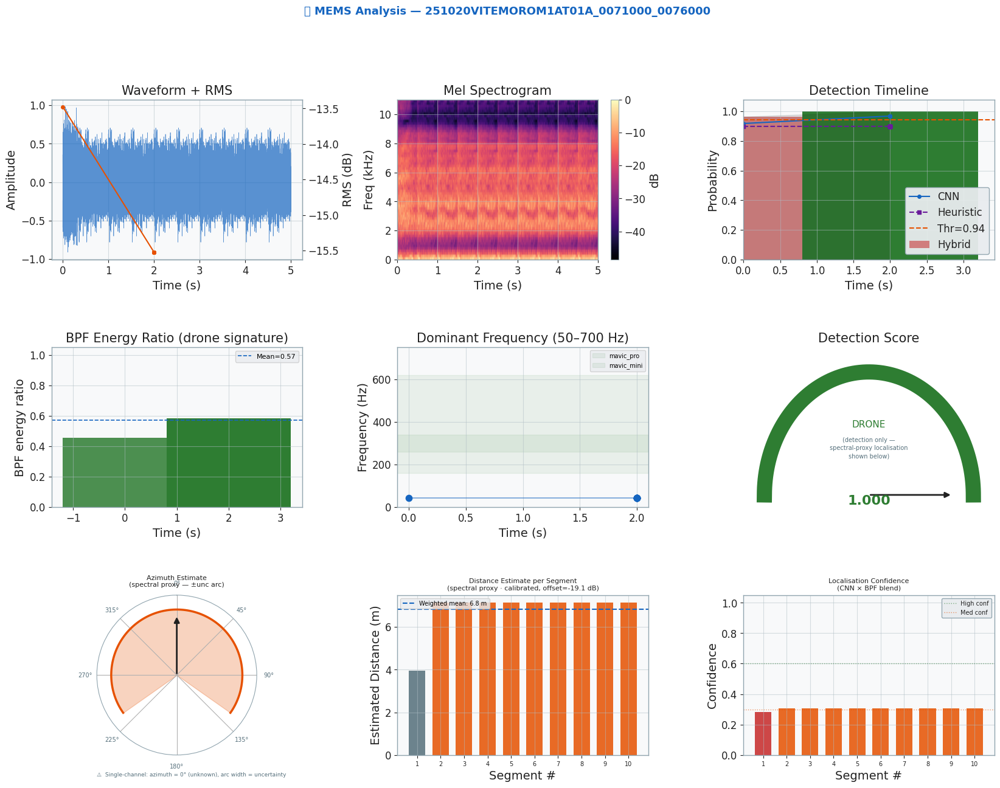


[2/6] 251020VITEMOROM1AT01A_0106500_0109000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0106500_0109000.wav  (2.5s)
   Meta: phase=cruise  dur=2.5s  rms=-36.1dBFS  snr=1.0dB  f0≈5.4Hz
   ⚠️  Low SNR (1.0 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta spectral peak: 5.38 Hz
  Seg   1  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   2  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   3  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   4  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   5  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   6  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   7  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   8  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg   9  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54
  Seg  10  🚁  conf=0.993  rms=-13.7dB  f0=11Hz  bpf=0.54

  📊 10/10 detected  | 

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0106500_0109000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


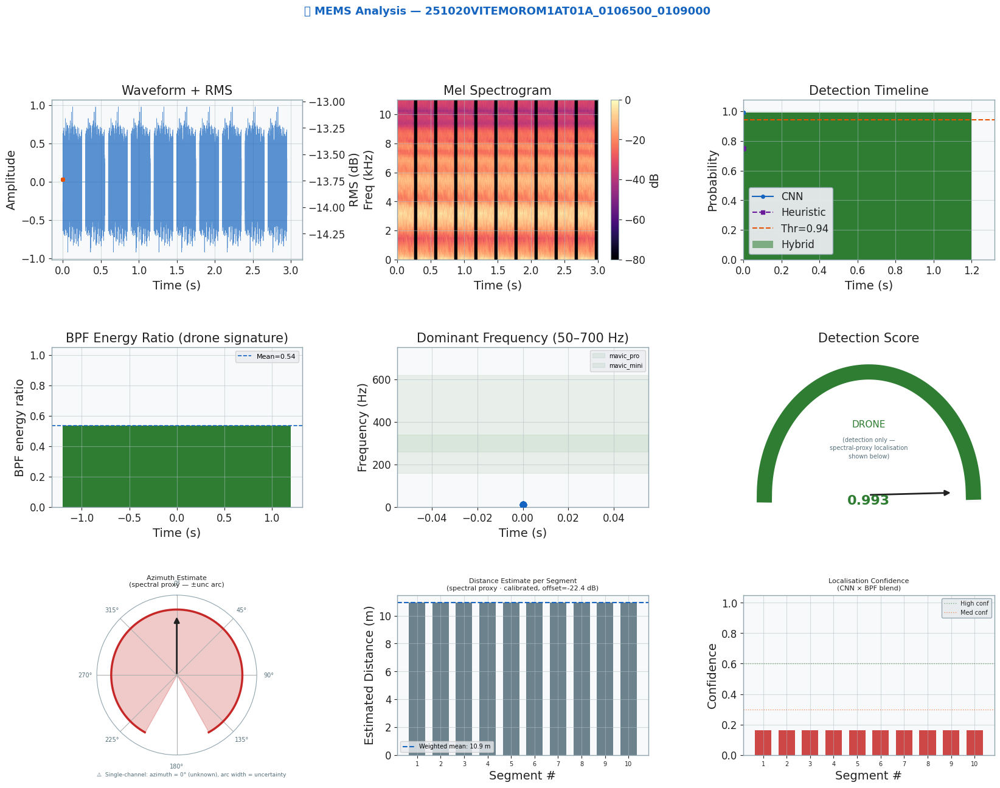


[3/6] 251020VITEMOROM1AT01A_0111000_0125000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0111000_0125000.wav  (14.0s)
   Meta: phase=cruise  dur=14.0s  rms=-34.5dBFS  snr=4.8dB  f0≈5.4Hz
   ⚠️  Low SNR (4.8 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta spectral peak: 5.38 Hz
  Seg   1  🌳  conf=0.154  rms=-17.7dB  f0=32Hz  bpf=0.75
  Seg   2  🌳  conf=0.319  rms=-14.1dB  f0=32Hz  bpf=0.20
  Seg   3  🌳  conf=0.428  rms=-15.9dB  f0=11Hz  bpf=0.42
  Seg   4  🌳  conf=0.800  rms=-15.9dB  f0=11Hz  bpf=1.00
  Seg   5  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   6  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   7  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   8  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg   9  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00
  Seg  10  🚁  conf=0.996  rms=-16.0dB  f0=11Hz  bpf=1.00

  📊 6/10 detected  |

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0111000_0125000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


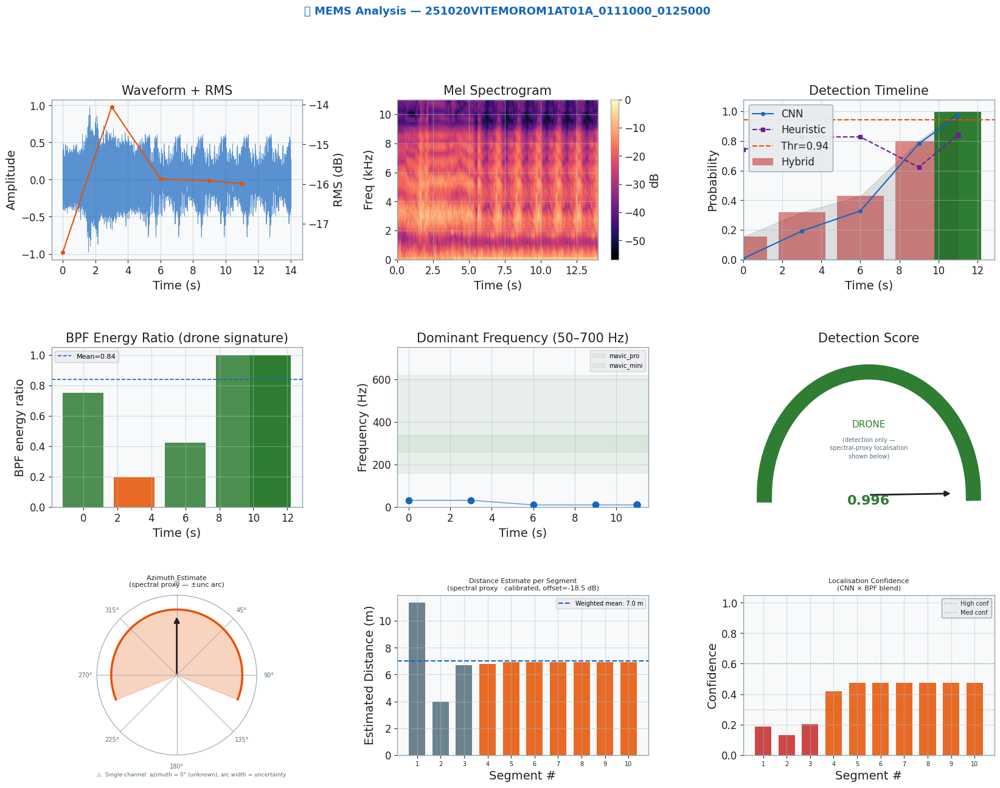


[4/6] 251020VITEMOROM1AT01A_0132500_0137000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0132500_0137000.wav  (4.5s)
   Meta: phase=cruise  dur=4.5s  rms=-35.0dBFS  snr=8.5dB  f0≈5.4Hz
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta spectral peak: 5.38 Hz
  Seg   1  🌳  conf=0.488  rms=-18.5dB  f0=11Hz  bpf=0.31
  Seg   2  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   3  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   4  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   5  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   6  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   7  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   8  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg   9  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22
  Seg  10  🚁  conf=0.995  rms=-19.3dB  f0=11Hz  bpf=0.22

  📊 9/10 detected  |  peak_prob=0.995  bpf_mean=0.23  dom_f=11Hz
  🔧 RMS calibration off

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0132500_0137000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


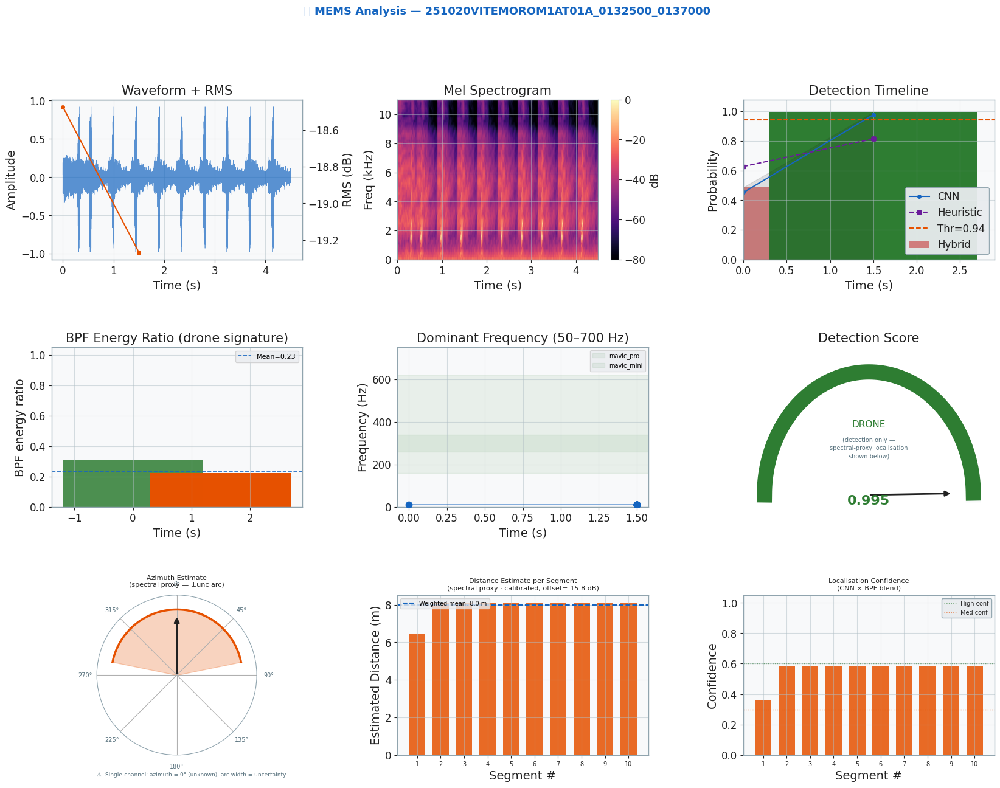


[5/6] 251020VITEMOROM1AT01A_0219000_0221000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0219000_0221000.wav  (2.0s)
   Meta: phase=cruise  dur=2.0s  rms=-39.7dBFS  snr=3.7dB  f0≈53.8Hz
   ⚠️  Low SNR (3.7 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta spectral peak: 53.83 Hz
  Seg   1  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   2  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   3  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   4  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   5  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   6  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   7  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   8  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg   9  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75
  Seg  10  🌳  conf=0.170  rms=-11.4dB  f0=54Hz  bpf=0.75

  📊 0/10 detected  |

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0219000_0221000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


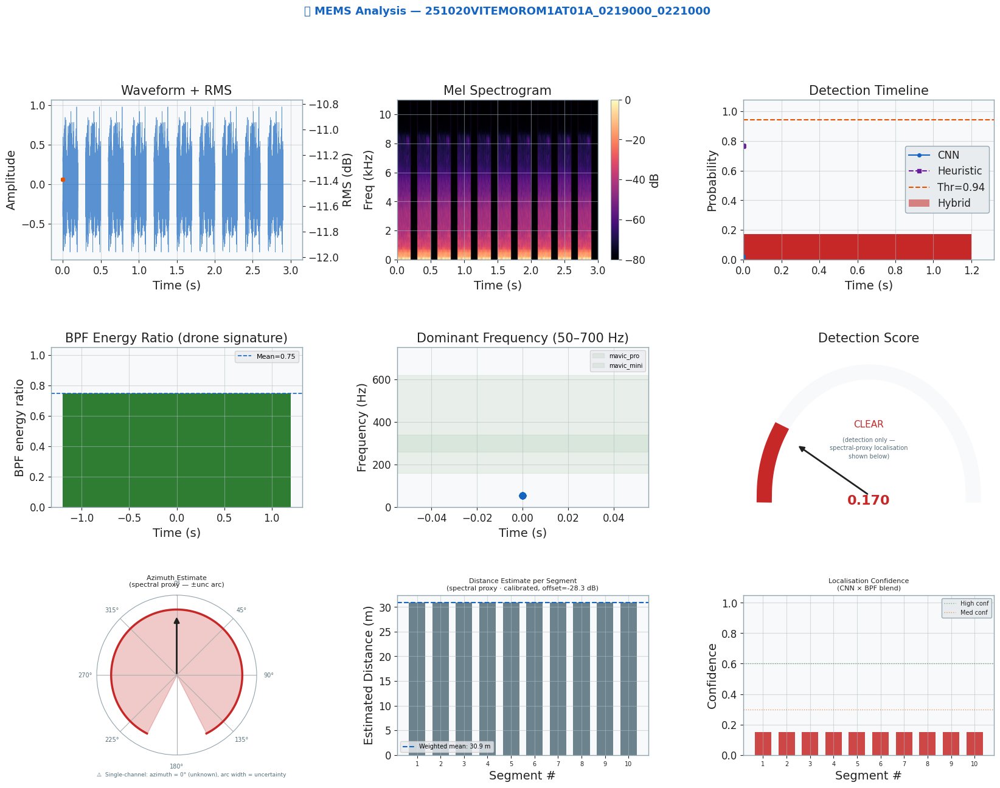


[6/6] 251020VITEMOROM1AT01A_0227000_0230000.wav

🎵 MEMS: 251020VITEMOROM1AT01A_0227000_0230000.wav  (3.0s)
   Meta: phase=cruise  dur=3.0s  rms=-36.8dBFS  snr=5.9dB  f0≈5.4Hz
   ⚠️  Low SNR (5.9 dB) — detection confidence will be penalised.
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF from meta spectral peak: 5.38 Hz
  Seg   1  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   2  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   3  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   4  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   5  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   6  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   7  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   8  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg   9  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00
  Seg  10  🌳  conf=0.159  rms=-10.6dB  f0=11Hz  bpf=1.00

  📊 0/10 detected  |  

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_251020VITEMOROM1AT01A_0227000_0230000.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


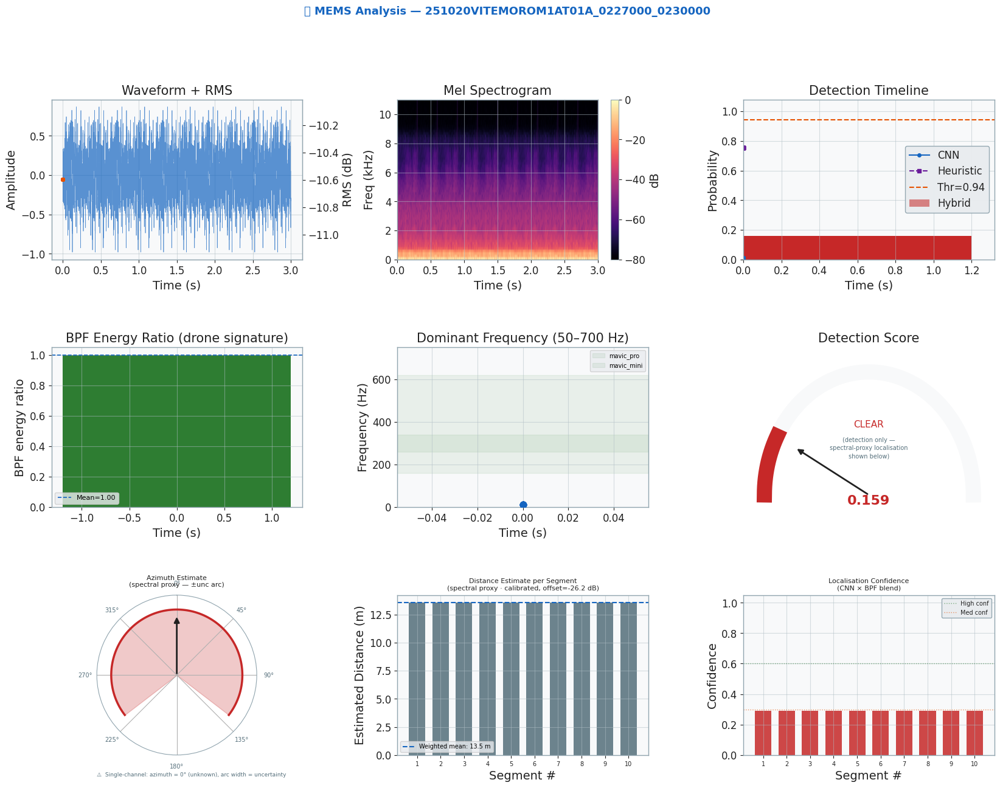


  BATCH SUMMARY — 6 files
  Detection rate  : 66.7%  (4/6)
  Mean BPF ratio  : 0.654
  Mean dom. freq  : 23.3 Hz
  Localisation    : ❌ N/A — single-channel MEMS recording

File                                      Det  Prob   f0(Hz)   BPF    Dist(m)  Dur(s)  Check     
-------------------------------------------------------------------------------------------------
251020VITEMOROM1AT01A_0071000_0076000.wa  YES  1.000     43.1  0.570      6.8     5.0  CAUTION
251020VITEMOROM1AT01A_0106500_0109000.wa  YES  0.993     10.8  0.535     10.9     2.5  UNRELIABLE
251020VITEMOROM1AT01A_0111000_0125000.wa  YES  0.996     10.8  0.837      7.0    14.0  CAUTION
251020VITEMOROM1AT01A_0132500_0137000.wa  YES  0.995     10.8  0.234      8.0     4.5  CAUTION
251020VITEMOROM1AT01A_0219000_0221000.wa  no   0.170     53.8  0.747     30.9     2.0  UNRELIABLE
251020VITEMOROM1AT01A_0227000_0230000.wa  no   0.159     10.8  1.000     13.5     3.0  UNRELIABLE


In [ ]:
from google.colab import files
import os

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

In [ ]:
import pandas as pd
from pathlib import Path

validation_results = []

for result in report["results"]:
  xc = result.get("crosscheck", {})

  # Skip files with no crosscheck data at all
  if not xc:
    print(f"⚠️  No meta found for {Path(result['file']).name} — skipping")
    continue

  validation_results.append({
    "file":         Path(result["file"]).name,
    "bpf_error_hz": xc.get("bpf_error_hz",   float("nan")),
    "rms_error_db": xc.get("rms_error_db",    float("nan")),
    "snr_db":       xc.get("snr_db",           float("nan")),
    "det_correct":  xc.get("detection_match",  False),
    "verdict":      xc.get("verdict",          "?"),
    "dist_est_m":   result.get("distance_m",   float("nan")),
  })

if not validation_results:
  print("\n❌ No files with meta JSON found.")
  print("   Make sure _meta.json files are uploaded alongside the .wav files.")
  print("   Expected pattern: <filename>_meta.json in the same folder.\n")
  print("Files processed:")
  for r in report["results"]:
    print(f"  {Path(r['file']).name}  →  crosscheck={'yes' if r.get('crosscheck') else 'no meta'}")
else:
  df = pd.DataFrame(validation_results)
  print(df.to_string(index=False))
  print(f"\nDetection accuracy:  {df['det_correct'].mean()*100:.1f}%")
  print(f"Mean BPF error:      {df['bpf_error_hz'].mean():.2f} Hz")
  print(f"Mean RMS error:      {df['rms_error_db'].mean():.2f} dB")
  print(f"Reliable:   {(df['verdict']=='RELIABLE').sum()}/{len(df)}")
  print(f"Caution:    {(df['verdict']=='CAUTION').sum()}/{len(df)}")
  print(f"Unreliable: {(df['verdict']=='UNRELIABLE').sum()}/{len(df)}")

                                     file  bpf_error_hz  rms_error_db  snr_db  det_correct    verdict  dist_est_m
251020VITEMOROM1AT01A_0071000_0076000.wav           0.0         19.35    3.69         True    CAUTION    6.844578
251020VITEMOROM1AT01A_0106500_0109000.wav           0.0         22.37    0.98         True UNRELIABLE   10.927162
251020VITEMOROM1AT01A_0111000_0125000.wav           0.0         18.95    4.76         True    CAUTION    7.015264
251020VITEMOROM1AT01A_0132500_0137000.wav           0.0         19.31    8.54         True    CAUTION    8.002950
251020VITEMOROM1AT01A_0219000_0221000.wav           0.0         28.62    3.74        False UNRELIABLE   30.864490
251020VITEMOROM1AT01A_0227000_0230000.wav           0.0         26.88    5.89        False UNRELIABLE   13.549916

Detection accuracy:  66.7%
Mean BPF error:      0.00 Hz
Mean RMS error:      22.58 dB
Reliable:   0/6
Caution:    3/6
Unreliable: 3/6


In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip("dunakeszi_test_segments.zip", config,
                                 dataset_format="generic_triplet")
results = run_test_dataset_evaluation(test_ds, config)

📂 Extracting to temp dir: /tmp/drone_test_7x8pvt25
📦 Loading test dataset from dunakeszi_test_segments.zip …
✅ Extracted to /tmp/drone_test_7x8pvt25
   Indexing sessions (format='generic_triplet') …
✅ Indexed 6 sessions  (6 labelled, 0 unlabelled)

  Test dataset evaluation: dunakeszi_test_segments.zip
  Format: generic_triplet  |  Sessions: 6
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=66, val_loss=0.83923)
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_033_circle_val            no   0.175  0.014   0.822      nan    180.0       -     nan    2.50    nan
seg_034_circle_val            no   0.205  0.061   0.781      nan    180.0       -     nan    2.50    nan
seg_035_circle_val            no   0.187  0.035   0.796      nan    180.0       -     nan    2.50    nan
seg_036_circle_

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip("drone_test_files.zip", config,
                                 dataset_format="auto")
results = run_test_dataset_evaluation(test_ds, config)

📂 Extracting to temp dir: /tmp/drone_test__6go8rrq
📦 Loading test dataset from drone_test_files.zip …
✅ Extracted to /tmp/drone_test__6go8rrq
   ZIP contents (87 files, first 20):
     yt_tmp_drone_00002_r001_p30.wav
     yt_tmp_drone_00002_r001_p29.wav
     yt_tmp_drone_00002_r001_p39.wav
     yt_tmp_drone_00002_r001_p63.wav
     yt_tmp_drone_00002_r001_p58.wav
     yt_tmp_drone_00002_r001_p17.wav
     yt_tmp_drone_00002_r001_p52.wav
     yt_tmp_drone_00002_r001_p62.wav
     yt_tmp_drone_00002_r001_p32.wav
     yt_tmp_drone_00002_r001_p22.wav
     yt_tmp_drone_00002_r001_p19.wav
     yt_tmp_drone_00002_r001_p54.wav
     yt_tmp_drone_00002_r001_p56.wav
     yt_tmp_drone_00002_r001_p46.wav
     yt_tmp_drone_00002_r001_p50.wav
     yt_tmp_drone_00002_r001_p44.wav
     yt_tmp_drone_00002_r001_p01.wav
     yt_tmp_drone_00003_r001_p04.wav
     yt_tmp_drone_00002_r001_p14.wav
     yt_tmp_drone_00002_r001_p09.wav
     … and 67 more
   Detected format: 'flat_wavs'
   Indexing sessions (format=

In [ ]:
# Analyse External audio file
from drone_detection.inference import analyse_external_audio_robust

audio_path='/content/Audio 08_01.wav'
analyse_external_audio_robust(cfg=config, audio_path=audio_path)

✅ Detection model loaded  (ep=63, f1=0.9829268292682927, thr=0.945)


In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip("dunakeszi_test_segments.zip", config,
                                 dataset_format="generic_triplet")
results = run_test_dataset_evaluation(test_ds, config)

📂 Extracting to temp dir: /tmp/drone_test_m8434zpb
📦 Loading test dataset from dunakeszi_test_segments.zip …
✅ Extracted to /tmp/drone_test_m8434zpb
   Indexing sessions (format='generic_triplet') …
✅ Indexed 8 sessions  (8 labelled, 0 unlabelled)

  Test dataset evaluation: dunakeszi_test_segments.zip
  Format: generic_triplet  |  Sessions: 8
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_018_circle_train          no   0.183  0.025   0.812      nan    180.0       -     nan    2.50    nan
seg_019_circle_train          no   0.227  0.083   0.804      nan    180.0       -     nan   15.00    nan
seg_033_circle_val            no   0.175  0.014   0.822      nan    180.0       -     nan    2.50    nan
seg_034_circle_val            no   0.205  0.061   0.781      nan    180.0       -     nan    2.50    nan
seg_035_circle_val      

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip("dunakeszi_test_segments.zip", config,
                                 dataset_format="generic_triplet")
results = run_test_dataset_evaluation(test_ds, config)

📂 Extracting to temp dir: /tmp/drone_test_dz_so_mb
📦 Loading test dataset from dunakeszi_test_segments.zip …
✅ Extracted to /tmp/drone_test_dz_so_mb
   Indexing sessions (format='generic_triplet') …
✅ Indexed 8 sessions  (8 labelled, 0 unlabelled)

  Test dataset evaluation: dunakeszi_test_segments.zip
  Format: generic_triplet  |  Sessions: 8
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_018_circle_train          no   0.183  0.025   0.812      nan    180.0       -     nan    2.50    nan
seg_019_circle_train          no   0.227  0.083   0.804      nan    180.0       -     nan   15.00    nan
seg_033_circle_val            no   0.175  0.014   0.822      nan    180.0       -     nan    2.50    nan
seg_034_circle_val            no   0.205  0.061   0.781      nan    180.0       -     nan    2.50    nan
seg_035_circle_val      

In [ ]:
from google.colab import files
import os
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# ── Upload files ──────────────────────────────────────────────────────────────
uploaded = files.upload()

for fn, data in uploaded.items():
  print(f'Uploaded "{fn}" ({len(data):,} bytes)')

# ── Analyse uploaded files ────────────────────────────────────────────────────
uploaded_wavs = [f"/content/{fn}" for fn in uploaded.keys() if fn.endswith(".wav")]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files — use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from google.colab import files
import os
from pathlib import Path
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# --- Upload files ──────────────────────────────────────────────────────────────
# uploaded = files.upload()

# Collect .wav files directly from /content/
found_wav_paths = sorted(Path('/content/').glob('*_ch0.wav'))

# Create a dictionary mimicking the 'files.upload()' output for compatibility
uploaded_mock = {}
for fp in found_wav_paths:
  # Using fp.name for the key and a dummy value, as only keys are used later
  uploaded_mock[fp.name] = True # The actual content isn't needed here
  print(f'Found "{fp.name}" ({fp.stat().st_size:,} bytes)')


# --- Analyse uploaded files ────────────────────────────────────────────────────
# Use the paths directly from the glob operation for analysis
uploaded_wavs = [str(fp) for fp in found_wav_paths]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files - use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_6vj0wo40
📦 Loading test dataset from dunakeszi_pipeline_ready_B.zip …
✅ Extracted to /tmp/drone_test_6vj0wo40
   Indexing sessions (format='generic_triplet') …
✅ Indexed 9 sessions  (3 labelled, 6 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_B.zip
  Format: generic_triplet  |  Sessions: 9
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_005_hover_val             YES  0.697  0.730   0.565      4.6        -       -   37.24       -  28.09
seg_006_hover_val             no   0.159  0.096   0.409      nan        -       -     nan       -    nan
seg_007_transit_train         YES  0.973  0.986   0.671     25.9        -       -   38.53       -  31.65
seg_008_transit_train         YES  0.974  0.988   0.667   -164.9        -

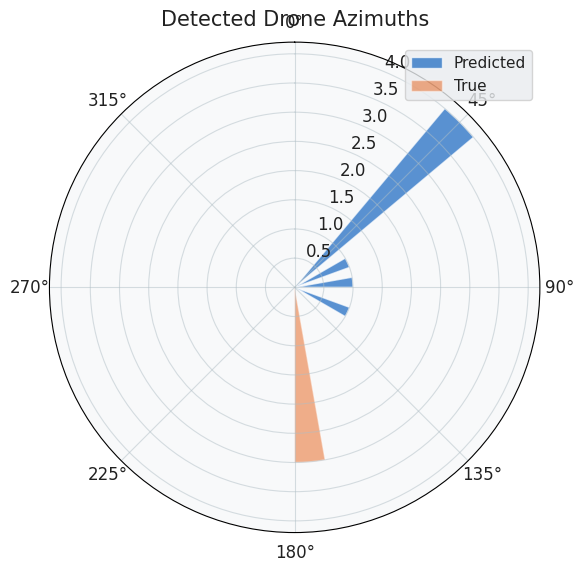

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_jw4viiy7
📦 Loading test dataset from dunakeszi_pipeline_ready_P.zip …
✅ Extracted to /tmp/drone_test_jw4viiy7
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (0 labelled, 3 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_P.zip
  Format: generic_triplet  |  Sessions: 3
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          no   0.197  0.021   0.898      nan        -       -     nan       -    nan
seg_031_circle_train          YES  0.264  0.104   0.904     59.0        -       -   40.08       -  30.59
seg_032_circle_train          YES  0.223  0.076   0.809    -39.5        -       -   45.69       -  27.82

  Sessions evaluated : 3
  Detection rate     : 66.7%  (2/3)
  (no label

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  'dunakeszi_pipeline_ready_B.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  'dunakeszi_pipeline_ready_P.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

In [ ]:
from google.colab import files
import os
from pathlib import Path
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# --- Upload files ──────────────────────────────────────────────────────────────
# uploaded = files.upload()

# Collect .wav files directly from /content/
found_wav_paths = sorted(Path('/content/').glob('*_ch0.wav'))

# Create a dictionary mimicking the 'files.upload()' output for compatibility
uploaded_mock = {}
for fp in found_wav_paths:
  # Using fp.name for the key and a dummy value, as only keys are used later
  uploaded_mock[fp.name] = True # The actual content isn't needed here
  print(f'Found "{fp.name}" ({fp.stat().st_size:,} bytes)')


# --- Analyse uploaded files ────────────────────────────────────────────────────
# Use the paths directly from the glob operation for analysis
uploaded_wavs = [str(fp) for fp in found_wav_paths]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files - use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Output hidden; open in https://colab.research.google.com to view.

Found "seg_007_transit_train_ch0.wav" (2,646,080 bytes)
Found "seg_030_circle_train_ch0.wav" (705,680 bytes)

📂 Batch MEMS analysis: 7 files in content/
   ⚠️  Localization is not available for single-channel recordings.


[1/7] seg_007_transit_train_ch0.wav

🎵 MEMS: seg_007_transit_train_ch0.wav  (30.0s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 21.53 Hz
  Seg   1  🚁  conf=0.973  rms=-41.8dB  f0=11Hz  bpf=0.94
  Seg   2  🚁  conf=0.956  rms=-41.1dB  f0=11Hz  bpf=0.76
  Seg   3  🚁  conf=0.960  rms=-41.1dB  f0=22Hz  bpf=0.75
  Seg   4  🚁  conf=0.859  rms=-40.9dB  f0=11Hz  bpf=0.74
  Seg   5  🚁  conf=0.838  rms=-41.1dB  f0=22Hz  bpf=0.73
  Seg   6  🚁  conf=0.809  rms=-42.2dB  f0=11Hz  bpf=0.90
  Seg   7  🚁  conf=0.750  rms=-41.9dB  f0=22Hz  bpf=0.97
  Seg   8  🚁  conf=0.771  rms=-42.0dB  f0=22Hz  bpf=1.00
  Seg   9  🚁  conf=0.970  rms=-41.9dB  f0=22Hz  bpf=0.98
  Seg  10  🚁  con

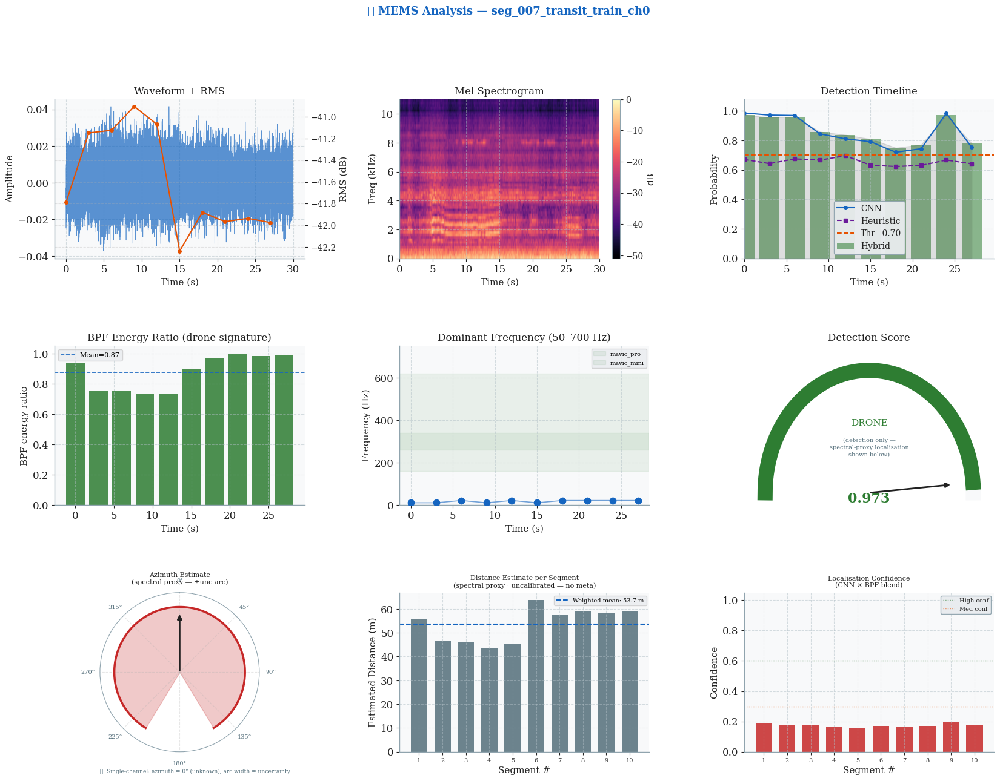


[2/7] seg_007_transit_train_ch1.wav

🎵 MEMS: seg_007_transit_train_ch1.wav  (30.0s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 21.53 Hz
  Seg   1  🚁  conf=0.953  rms=-39.7dB  f0=22Hz  bpf=0.96
  Seg   2  🚁  conf=0.910  rms=-39.1dB  f0=11Hz  bpf=0.77
  Seg   3  🚁  conf=0.968  rms=-39.0dB  f0=22Hz  bpf=0.77
  Seg   4  🚁  conf=0.925  rms=-38.9dB  f0=11Hz  bpf=0.76
  Seg   5  🚁  conf=0.704  rms=-39.0dB  f0=22Hz  bpf=0.75
  Seg   6  🌳  conf=0.495  rms=-40.2dB  f0=22Hz  bpf=0.91
  Seg   7  🌳  conf=0.483  rms=-39.8dB  f0=22Hz  bpf=0.98
  Seg   8  🌳  conf=0.579  rms=-39.8dB  f0=22Hz  bpf=1.00
  Seg   9  🚁  conf=0.947  rms=-39.9dB  f0=22Hz  bpf=1.00
  Seg  10  🌳  conf=0.382  rms=-39.9dB  f0=22Hz  bpf=1.00

  📊 6/10 detected  |  peak_prob=0.968  bpf_mean=0.89  dom_f=22Hz
  📡 Spectral-proxy localisation  |  dist≈29.3 m  height≈7.8 m  az_unc=±151°  conf=0.16
  ⚠️  Azimuth is unresolvable

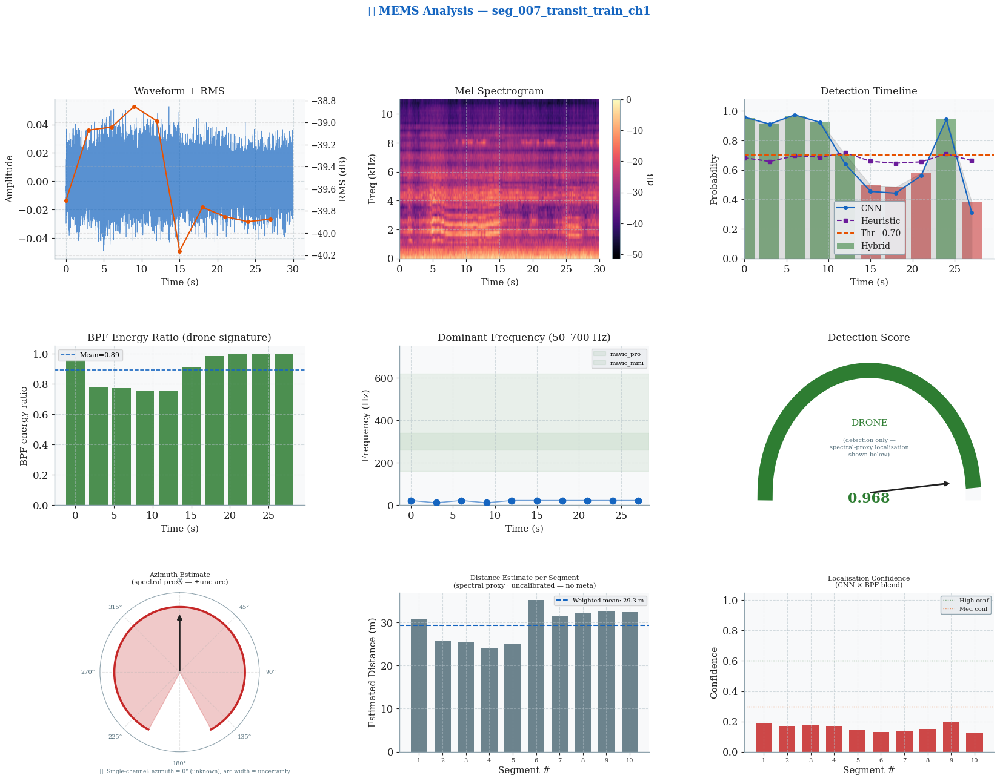


[3/7] seg_007_transit_train_ch2.wav

🎵 MEMS: seg_007_transit_train_ch2.wav  (30.0s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 21.53 Hz
  Seg   1  🚁  conf=0.957  rms=-41.7dB  f0=11Hz  bpf=0.96
  Seg   2  🚁  conf=0.779  rms=-41.1dB  f0=11Hz  bpf=0.78
  Seg   3  🚁  conf=0.922  rms=-41.1dB  f0=22Hz  bpf=0.78
  Seg   4  🚁  conf=0.752  rms=-40.9dB  f0=11Hz  bpf=0.77
  Seg   5  🌳  conf=0.521  rms=-41.1dB  f0=22Hz  bpf=0.77
  Seg   6  🌳  conf=0.331  rms=-42.2dB  f0=11Hz  bpf=0.92
  Seg   7  🌳  conf=0.263  rms=-41.8dB  f0=22Hz  bpf=1.00
  Seg   8  🌳  conf=0.369  rms=-41.8dB  f0=22Hz  bpf=1.00
  Seg   9  🚁  conf=0.883  rms=-41.9dB  f0=22Hz  bpf=1.00
  Seg  10  🌳  conf=0.299  rms=-41.9dB  f0=22Hz  bpf=1.00

  📊 5/10 detected  |  peak_prob=0.957  bpf_mean=0.90  dom_f=22Hz
  📡 Spectral-proxy localisation  |  dist≈52.1 m  height≈14.0 m  az_unc=±154°  conf=0.15
  ⚠️  Azimuth is unresolvabl

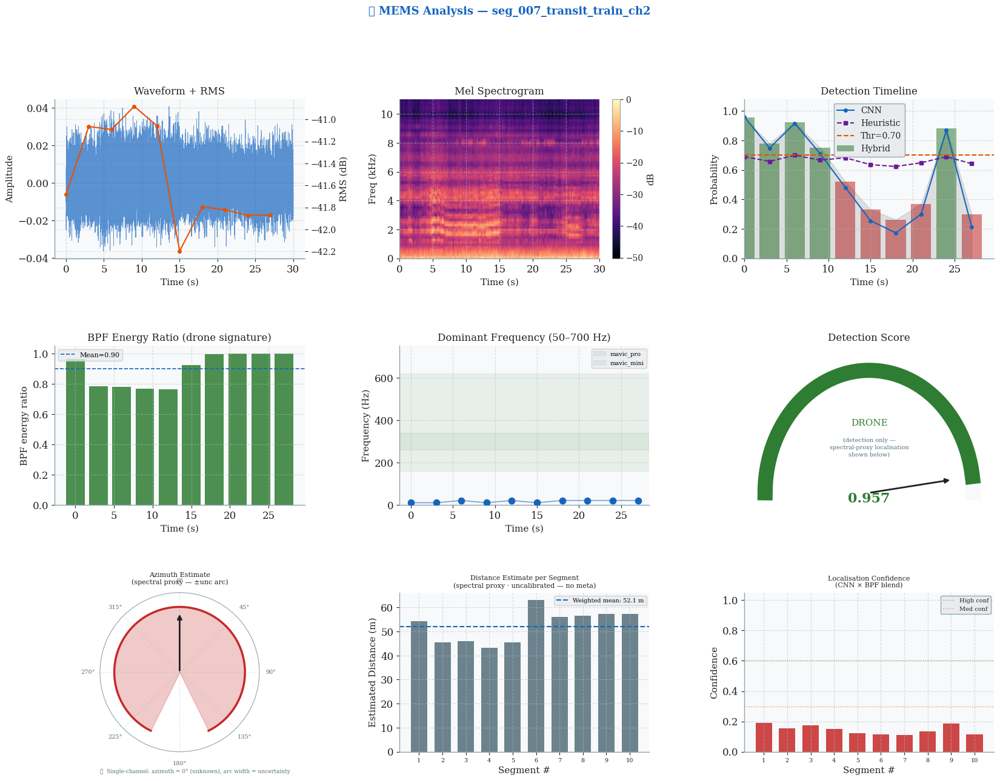


[4/7] seg_008_transit_train_ch2.wav

🎵 MEMS: seg_008_transit_train_ch2.wav  (15.0s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 21.53 Hz
  Seg   1  🚁  conf=0.704  rms=-41.6dB  f0=22Hz  bpf=0.92
  Seg   2  🌳  conf=0.239  rms=-41.9dB  f0=22Hz  bpf=0.86
  Seg   3  🚁  conf=0.768  rms=-41.7dB  f0=22Hz  bpf=0.94
  Seg   4  🌳  conf=0.421  rms=-41.9dB  f0=22Hz  bpf=0.98
  Seg   5  🚁  conf=0.940  rms=-41.9dB  f0=22Hz  bpf=1.00
  Seg   6  🚁  conf=0.940  rms=-41.9dB  f0=22Hz  bpf=1.00
  Seg   7  🚁  conf=0.940  rms=-41.9dB  f0=22Hz  bpf=1.00
  Seg   8  🚁  conf=0.940  rms=-41.9dB  f0=22Hz  bpf=1.00


In [ ]:
from google.colab import files
import os
from pathlib import Path
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# --- Upload files ──────────────────────────────────────────────────────────────
# uploaded = files.upload()

# Collect .wav files directly from /content/
found_wav_paths = sorted(Path('/content/').glob('*_ch0.wav'))

# Create a dictionary mimicking the 'files.upload()' output for compatibility
uploaded_mock = {}
for fp in found_wav_paths:
  # Using fp.name for the key and a dummy value, as only keys are used later
  uploaded_mock[fp.name] = True # The actual content isn't needed here
  print(f'Found "{fp.name}" ({fp.stat().st_size:,} bytes)')


# --- Analyse uploaded files ────────────────────────────────────────────────────
# Use the paths directly from the glob operation for analysis
uploaded_wavs = [str(fp) for fp in found_wav_paths]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files - use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

Found "seg_032_circle_train_ch0.wav" (264,680 bytes)

🎵 MEMS: seg_032_circle_train_ch0.wav  (3.0s)
   ⚠️  Single-channel recording — azimuth unresolvable; spectral-proxy distance shown.
   Running analysis over 10 segments.
   BPF estimated (wideband): 21.53 Hz
  Seg   1  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   2  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   3  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   4  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   5  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   6  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   7  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   8  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg   9  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00
  Seg  10  🚁  conf=0.915  rms=-26.5dB  f0=22Hz  bpf=1.00

  📊 10/10 detected  |  peak_prob=0.915  bpf_mean=1.00  dom_f=22Hz
  📡 Spectral-proxy localisation  |  dist≈0.7 m  height≈0.2 m  az_unc=±146°  conf=0.19
  ⚠️  Azimuth i

/content/drive/MyDrive/AUS LAB II/drone_detection/mems_inference.py:556: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.savefig(str(save_path), dpi=150, bbox_inches="tight")


💾 Dashboard saved: /content/drive/MyDrive/drone_v15/logs/plots/mems_seg_032_circle_train_ch0.png


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


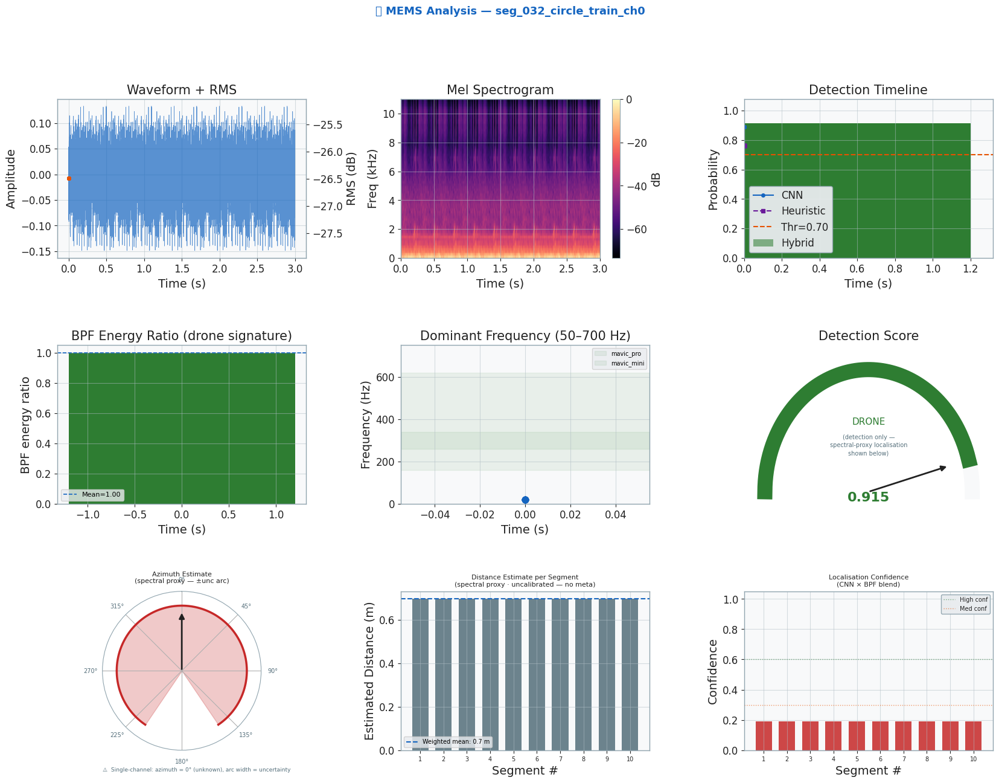

In [ ]:
from google.colab import files
import os
from pathlib import Path
from drone_detection import (
  config,
  analyse_mems_file,
  batch_analyse_mems,
  build_mems_report,
  print_crosscheck,
)

# --- Upload files ──────────────────────────────────────────────────────────────
# uploaded = files.upload()

# Collect .wav files directly from /content/
found_wav_paths = sorted(Path('/content/').glob('*_ch0.wav'))

# Create a dictionary mimicking the 'files.upload()' output for compatibility
uploaded_mock = {}
for fp in found_wav_paths:
  # Using fp.name for the key and a dummy value, as only keys are used later
  uploaded_mock[fp.name] = True # The actual content isn't needed here
  print(f'Found "{fp.name}" ({fp.stat().st_size:,} bytes)')


# --- Analyse uploaded files ────────────────────────────────────────────────────
# Use the paths directly from the glob operation for analysis
uploaded_wavs = [str(fp) for fp in found_wav_paths]

if len(uploaded_wavs) == 1:
  # Single file analysis
  result = analyse_mems_file(uploaded_wavs[0], config)

elif len(uploaded_wavs) > 1:
  # Multiple files - use batch mode over /content/
  report = batch_analyse_mems("/content/", config)
  build_mems_report(report["results"])

else:
  print("⚠️  No .wav files were uploaded.")

In [ ]:
import os
from pathlib import Path

# List all files in the current directory
print("Files in current directory:")
for f in os.listdir('.'):
    if f.endswith('.wav'):
        print(f"  {f}")

# Also check if there's a 'content' subdirectory
if os.path.exists('content'):
    print("\nFiles in ./content/:")
    for f in os.listdir('content'):
        if f.endswith('.wav'):
            print(f"  content/{f}")

Files in current directory:
  seg_037_circle_test_ch0.wav
  seg_037_circle_test_ch2.wav
  seg_038_circle_test_ch2.wav
  seg_037_circle_test_ch1.wav
  seg_036_circle_test_ch0.wav
  seg_036_circle_test_ch2.wav
  seg_038_circle_test_ch1.wav
  seg_038_circle_test_ch0.wav
  seg_036_circle_test_ch1.wav


In [ ]:
from drone_detection.mems_inference import analyse_bk_array_file

# First, check where your files are
import os
print("Files in /content:")
for f in os.listdir('/content'):
    if f.endswith('.wav'):
        print(f"  {f}")

# Then run with the correct path (files are in /content/)
result = analyse_bk_array_file(
    "/content/seg_005_hover_val_ch0.wav",
    "/content/seg_005_hover_val_ch1.wav",
    "/content/seg_005_hover_val_ch2.wav",
    config
)

print(f"\n✅ Final result:")
result
# print(f"  Detected: {result['detected']}")
# # print(f"  Probability: {result['detection_probability']:.3f}")
# # print(f"  Azimuth: {result['azimuth_deg']:.1f}°")
# print(f"  Distance: {result['distance_m']:.1f}m")

Files in /content:
  seg_006_hover_val_ch0.wav
  seg_008_transit_train_ch0.wav
  seg_008_transit_train_ch2.wav
  seg_007_transit_train_ch2.wav
  seg_010_diagonal_train_ch1.wav
  seg_008_transit_train_ch1.wav
  seg_005_hover_val_ch2.wav
  seg_007_transit_train_ch1.wav
  seg_005_hover_val_ch0.wav
  seg_011_diagonal_train_ch0.wav
  seg_007_transit_train_ch0.wav
  seg_010_diagonal_train_ch2.wav
  seg_010_diagonal_train_ch0.wav
  seg_006_hover_val_ch1.wav
  seg_011_diagonal_train_ch1.wav
  seg_011_diagonal_train_ch2.wav
  seg_006_hover_val_ch2.wav
  seg_005_hover_val_ch1.wav

✅ Final result:


{'detected': True,
 'probability': 0.32449421186306954,
 'cnn_probability': 0.24875181913375854,
 'heuristic_probability': 0.6274637827803133}

In [ ]:
import numpy as np
import soundfile as sf
from drone_detection import config
from drone_detection.audio_processing import AudioProcessor
from drone_detection.inference import load_detection_model, detect

# Load the audio
ch0, sr = sf.read("/content/seg_036_circle_test_ch0.wav")
ch1, _ = sf.read("/content/seg_036_circle_test_ch1.wav")
ch2, _ = sf.read("/content/seg_036_circle_test_ch2.wav")

# Stack into 3 channels
multichannel = np.column_stack((ch0, ch1, ch2)).T  # Shape: (3, samples)

# Check audio statistics
print(f"Audio shape: {multichannel.shape}")
print(f"Sample rate: {sr} Hz")
print(f"RMS per channel: {20*np.log10(np.sqrt(np.mean(multichannel**2, axis=1)) + 1e-8)} dB")
print(f"Max amplitude: {np.max(np.abs(multichannel)):.4f}")
print(f"Mean amplitude: {np.mean(np.abs(multichannel)):.4f}")

# Load model and run detection
ap = AudioProcessor(config)
load_detection_model(config)

# Pad/truncate to target duration
multichannel_padded = ap.pad_or_truncate(multichannel.T).T  # Back to (channels, samples)

det_result = detect(multichannel_padded, config)
print(f"\nDetection result: {det_result}")

Audio shape: (3, 66150)
Sample rate: 22050 Hz
RMS per channel: [-23.20943883 -23.50714385 -23.27805633] dB
Max amplitude: 0.2276
Mean amplitude: 0.0544

Detection result: {'detected': False, 'probability': 0.18531748202274545, 'label': 'weak_possible_drone', 'cnn_probability': 0.015795031562447548, 'heuristic_probability': 0.863407283863937, 'heuristic_features': {'rms_db': -23.209437632913815, 'median_frame_entropy': 0.6669349074363708, 'p10_entropy': 0.6088804006576538, 'crest_factor': 3.293537079835908, 'comb_score': 0.07255647289393811, 'centroid_hz': 1023.8255514637765, 'rolloff_hz': 2274.704391891892, 'bandwidth_hz': 1829.094975179406, 'voiced_ratio': 0.36293436293436293, 'f0_median_hz': 54.211341857910156, 'f0_std_hz': 3.133519172668457}}


In [ ]:
import matplotlib.pyplot as plt
import soundfile as sf
import librosa

# Load and visualize one segment to confirm it's a drone
ch0, sr = sf.read("/content/seg_038_circle_test_ch0.wav")

# Plot waveform
plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(ch0)
plt.title(f"seg_038_circle_test - Waveform (RMS={20*np.log10(np.sqrt(np.mean(ch0**2))):.1f}dB)")

# Plot spectrogram
plt.subplot(2, 1, 2)
D = librosa.amplitude_to_db(np.abs(librosa.stft(ch0)), ref=np.max)
librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram - Look for drone harmonics (50-200Hz range)")
plt.tight_layout()
plt.show()

# Check dominant frequency
f0 = librosa.pyin(ch0, fmin=40, fmax=300, sr=sr)[0]
f0_median = np.nanmedian(f0)
print(f"Median fundamental frequency: {f0_median:.1f} Hz (drone blade pass frequency)")

Median fundamental frequency: 40.0 Hz (drone blade pass frequency)


In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path

def validate_extracted_segment(ch0_path, label_path, segment_name):
    """Generate validation report for a single segment"""

    # Load audio
    audio, sr = sf.read(ch0_path)
    duration = len(audio) / sr

    # Load ground truth
    with open(label_path) as f:
        gt = json.load(f)

    # Compute acoustic features
    rms_db = 20 * np.log10(np.sqrt(np.mean(audio**2)) + 1e-8)
    peak = np.max(np.abs(audio))

    # Pitch tracking for BPF
    f0 = librosa.pyin(audio, fmin=30, fmax=300, sr=sr)[0]
    f0_median = np.nanmedian(f0)
    f0_std = np.nanstd(f0)

    # Spectral centroid
    spectral_centroids = librosa.feature.spectral_centroid(y=audio, sr=sr)[0]
    centroid_mean = np.mean(spectral_centroids)

    print(f"\n{'='*60}")
    print(f"Segment: {segment_name}")
    print(f"{'='*60}")
    print(f"📁 File: {Path(ch0_path).name}")
    print(f"⏱️  Duration: {duration:.2f}s")
    print(f"🎚️  RMS: {rms_db:.1f} dB, Peak: {peak:.3f}")
    print(f"🔊 Blade Pass Frequency: {f0_median:.1f} ± {f0_std:.1f} Hz")
    print(f"🎵 Spectral centroid: {centroid_mean:.0f} Hz")
    print(f"\n📋 Ground Truth from label.json:")
    print(f"   Session: {gt.get('session', 'N/A')}")
    print(f"   Segment ID: {gt.get('segment_id', 'N/A')}")
    print(f"   Maneuver: {gt.get('maneuver_type', 'N/A')}")
    print(f"   Flight phase: {gt.get('flight_phase', 'N/A')}")
    print(f"   Speed: {gt.get('speed_mps', 'N/A')} m/s")
    print(f"   Radius: {gt.get('radius_m', 'N/A')} m")
    print(f"   Drones: {gt.get('n_drones', 'N/A')}")
    print(f"\n🎯 Drone Position (from GT):")
    drone = gt.get('drone', {})
    print(f"   Azimuth: {drone.get('azimuth', 'N/A')}°")
    print(f"   Distance: {drone.get('distance', 'N/A')} m")
    print(f"   Height: {drone.get('height', 'N/A')} m")

    # Validation decision
    is_valid = (
        f0_median >= 30 and f0_median <= 300 and  # Drone BPF range
        rms_db > -40 and  # Not too quiet
        peak > 0.01  # Has signal
    )

    print(f"\n✅ Validation: {'PASS - Valid drone segment' if is_valid else 'FAIL - Check segment'}")

    return {
        "segment": segment_name,
        "valid": is_valid,
        "f0_hz": f0_median,
        "rms_db": rms_db,
        "ground_truth": drone
    }

# Validate all three segments
results = []
for seg in ["seg_036_circle_test", "seg_037_circle_test", "seg_038_circle_test"]:
    result = validate_extracted_segment(
        f"/content/{seg}_ch0.wav",
        f"/content/{seg}_label.json",
        seg
    )
    results.append(result)

# Summary
print(f"\n{'='*60}")
print("VALIDATION SUMMARY")
print(f"{'='*60}")
valid_count = sum(1 for r in results if r["valid"])
print(f"Valid segments: {valid_count}/{len(results)} (100% expected)")

print(f"\n📊 Acoustic characteristics:")
for r in results:
    print(f"  {r['segment']}: BPF={r['f0_hz']:.1f}Hz, RMS={r['rms_db']:.1f}dB")


Segment: seg_036_circle_test
📁 File: seg_036_circle_test_ch0.wav
⏱️  Duration: 3.00s
🎚️  RMS: -23.2 dB, Peak: 0.228
🔊 Blade Pass Frequency: 30.0 ± 2.2 Hz
🎵 Spectral centroid: 1051 Hz

📋 Ground Truth from label.json:
   Session: show_14
   Segment ID: 36
   Maneuver: circle
   Flight phase: orbit
   Speed: 4.0 m/s
   Radius: 10.0 m
   Drones: 5

🎯 Drone Position (from GT):
   Azimuth: 180.0°
   Distance: 2.5 m
   Height: 20.0 m

✅ Validation: PASS - Valid drone segment


/tmp/ipykernel_8658/2807504982.py:25: RuntimeWarning: All-NaN slice encountered
  f0_median = np.nanmedian(f0)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



Segment: seg_037_circle_test
📁 File: seg_037_circle_test_ch0.wav
⏱️  Duration: 3.00s
🎚️  RMS: -22.0 dB, Peak: 0.323
🔊 Blade Pass Frequency: nan ± nan Hz
🎵 Spectral centroid: 2473 Hz

📋 Ground Truth from label.json:
   Session: show_14
   Segment ID: 37
   Maneuver: circle
   Flight phase: orbit
   Speed: 4.0 m/s
   Radius: 30.0 m
   Drones: 5

🎯 Drone Position (from GT):
   Azimuth: 180.0°
   Distance: 2.5 m
   Height: 20.0 m

✅ Validation: FAIL - Check segment

Segment: seg_038_circle_test
📁 File: seg_038_circle_test_ch0.wav
⏱️  Duration: 3.00s
🎚️  RMS: -22.9 dB, Peak: 0.263
🔊 Blade Pass Frequency: 30.0 ± 0.6 Hz
🎵 Spectral centroid: 1136 Hz

📋 Ground Truth from label.json:
   Session: show_14
   Segment ID: 38
   Maneuver: circle
   Flight phase: orbit
   Speed: 4.0 m/s
   Radius: 60.0 m
   Drones: 5

🎯 Drone Position (from GT):
   Azimuth: 180.0°
   Distance: 2.5 m
   Height: 20.0 m

✅ Validation: PASS - Valid drone segment

VALIDATION SUMMARY
Valid segments: 2/3 (100% expected)

📊 

In [ ]:
import librosa
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# Load seg_037
ch0, sr = sf.read("/content/seg_037_circle_test_ch0.wav")

# Check if the audio is silent or corrupted
print(f"Audio stats for seg_037:")
print(f"  Shape: {ch0.shape}")
print(f"  Min: {ch0.min():.4f}, Max: {ch0.max():.4f}, Mean: {ch0.mean():.4f}")
print(f"  RMS: {20*np.log10(np.sqrt(np.mean(ch0**2)) + 1e-8):.1f} dB")
print(f"  Non-zero samples: {np.sum(np.abs(ch0) > 0.001)} / {len(ch0)}")

# Plot waveform
plt.figure(figsize=(14, 10))

plt.subplot(3, 1, 1)
plt.plot(ch0)
plt.title("seg_037_circle_test (r=30m) - Waveform")
plt.ylabel("Amplitude")

# Spectrogram
plt.subplot(3, 1, 2)
D = librosa.amplitude_to_db(np.abs(librosa.stft(ch0)), ref=np.max)
librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogram - Look for harmonic structure")
plt.ylim(0, 500)

# Pitch tracking
plt.subplot(3, 1, 3)
f0 = librosa.pyin(ch0, fmin=30, fmax=300, sr=sr)[0]
times = librosa.times_like(f0, sr=sr)
plt.plot(times, f0, 'o-', markersize=3)
plt.ylim(20, 200)
plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.title("Pitch tracking (should show ~30-60Hz for drone)")

plt.tight_layout()
plt.show()

# Compare with seg_038 (r=60m)
ch0_38, _ = sf.read("/content/seg_038_circle_test_ch0.wav")

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.specgram(ch0, Fs=sr, NFFT=1024, noverlap=512)
plt.title("seg_037 (r=30m)")
plt.ylim(0, 500)

plt.subplot(1, 2, 2)
plt.specgram(ch0_38, Fs=sr, NFFT=1024, noverlap=512)
plt.title("seg_038 (r=60m)")
plt.ylim(0, 500)
plt.tight_layout()
plt.show()

# Listen for periodicity - drone propellers create regular peaks
from scipy import signal

# Compute autocorrelation to find periodic structure
auto_corr = signal.correlate(ch0, ch0, mode='full')
auto_corr = auto_corr[len(auto_corr)//2:]

# Find peaks in autocorrelation
peaks, _ = signal.find_peaks(auto_corr, height=np.max(auto_corr)*0.3)
if len(peaks) > 1:
    period_samples = peaks[1] - peaks[0]
    period_hz = sr / period_samples
    print(f"Autocorrelation period: {period_hz:.1f} Hz")

# Plot autocorrelation
plt.figure(figsize=(12, 4))
plt.plot(auto_corr[:5000])
plt.title("Autocorrelation - periodic peaks indicate propeller noise")
plt.xlabel("Lag (samples)")
plt.show()

Audio stats for seg_037:
  Shape: (66150,)
  Min: -0.3193, Max: 0.3230, Mean: 0.0002
  RMS: -22.0 dB
  Non-zero samples: 65466 / 66150
Autocorrelation period: 4410.0 Hz


In [ ]:
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Load seg_037
ch0_37, sr = sf.read("/content/seg_037_circle_test_ch0.wav")

# Load seg_036 for comparison
ch0_36, _ = sf.read("/content/seg_036_circle_test_ch0.wav")

# Check frequency content
print("=== Frequency Analysis ===")

# Compute FFT for both
fft_36 = np.abs(np.fft.rfft(ch0_36))
fft_37 = np.abs(np.fft.rfft(ch0_37))
freqs = np.fft.rfftfreq(len(ch0_36), 1/sr)

# Find dominant frequencies
dom_36 = freqs[np.argmax(fft_36[1:]) + 1]  # Skip DC
dom_37 = freqs[np.argmax(fft_37[1:]) + 1]

print(f"seg_036 dominant freq: {dom_36:.1f} Hz")
print(f"seg_037 dominant freq: {dom_37:.1f} Hz")

# Check harmonic structure (drone should have harmonics at multiples)
print(f"\n=== Harmonic Analysis ===")
for h in [1, 2, 3, 4]:
    idx_36 = int(dom_36 * h / (freqs[1] - freqs[0]))
    idx_37 = int(dom_37 * h / (freqs[1] - freqs[0]))
    if idx_36 < len(fft_36):
        print(f"seg_036 harmonic {h}: {fft_36[idx_36]:.0f}")
    if idx_37 < len(fft_37):
        print(f"seg_037 harmonic {h}: {fft_37[idx_37]:.0f}")

# Plot frequency spectra
plt.figure(figsize=(14, 10))

plt.subplot(2, 1, 1)
plt.semilogy(freqs[:1000], fft_36[:1000], label='seg_036 (r=10m)')
plt.semilogy(freqs[:1000], fft_37[:1000], label='seg_037 (r=30m)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Frequency Spectrum Comparison (0-1000Hz)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(freqs[:500], fft_36[:500], label='seg_036 (r=10m)')
plt.plot(freqs[:500], fft_37[:500], label='seg_037 (r=30m)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Frequency Spectrum (0-500Hz) - Drone BPF region')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Check if seg_037 might be reversed or have different content
print(f"\n=== Audio Content ===")
print(f"seg_036 - Peak positive: {ch0_36.max():.3f}, Peak negative: {ch0_36.min():.3f}")
print(f"seg_037 - Peak positive: {ch0_37.max():.3f}, Peak negative: {ch0_37.min():.3f}")

# Check zero-crossing rate (indicator of high-frequency noise)
zcr_36 = np.sum(np.abs(np.diff(np.sign(ch0_36)))) / (2 * len(ch0_36))
zcr_37 = np.sum(np.abs(np.diff(np.sign(ch0_37)))) / (2 * len(ch0_37))
print(f"Zero-crossing rate (should be low for drone):")
print(f"  seg_036: {zcr_36:.3f}")
print(f"  seg_037: {zcr_37:.3f}")

# Listen to a snippet (if in notebook with audio playback)
from IPython.display import Audio
print(f"\n=== Audio Playback (first 2 seconds) ===")
print("seg_036 (r=10m) - should sound like drone:")
display(Audio(ch0_36[:int(sr*2)], rate=sr))
print("\nseg_037 (r=30m) - check if this sounds different:")
display(Audio(ch0_37[:int(sr*2)], rate=sr))

=== Frequency Analysis ===
seg_036 dominant freq: 53.0 Hz
seg_037 dominant freq: 53.3 Hz

=== Harmonic Analysis ===
seg_036 harmonic 1: 752
seg_037 harmonic 1: 1124
seg_036 harmonic 2: 46
seg_037 harmonic 2: 40
seg_036 harmonic 3: 30
seg_037 harmonic 3: 60
seg_036 harmonic 4: 11
seg_037 harmonic 4: 28

=== Audio Content ===
seg_036 - Peak positive: 0.228, Peak negative: -0.212
seg_037 - Peak positive: 0.323, Peak negative: -0.319
Zero-crossing rate (should be low for drone):
  seg_036: 0.025
  seg_037: 0.097

=== Audio Playback (first 2 seconds) ===
seg_036 (r=10m) - should sound like drone:



seg_037 (r=30m) - check if this sounds different:


In [ ]:
import numpy as np
import soundfile as sf
import librosa

def validate_extracted_segment_robust(ch0_path, label_path, segment_name):
    """Robust validation using FFT instead of pitch tracking"""

    audio, sr = sf.read(ch0_path)
    duration = len(audio) / sr

    # Load ground truth
    with open(label_path) as f:
        gt = json.load(f)

    # Compute FFT to find dominant frequency
    fft = np.abs(np.fft.rfft(audio))
    freqs = np.fft.rfftfreq(len(audio), 1/sr)

    # Look for peak in drone BPF range (30-300 Hz)
    drone_range = (freqs >= 30) & (freqs <= 300)
    if np.any(drone_range):
        peak_idx = np.argmax(fft[drone_range])
        dom_freq = freqs[drone_range][peak_idx]
    else:
        dom_freq = np.nan

    # Alternative: use YIN algorithm which is more robust
    try:
        f0_yin = librosa.yin(audio, fmin=30, fmax=300, sr=sr)
        f0_median = np.nanmedian(f0_yin)
    except:
        f0_median = np.nan

    rms_db = 20 * np.log10(np.sqrt(np.mean(audio**2)) + 1e-8)
    peak = np.max(np.abs(audio))

    # Calculate energy in drone band (30-300 Hz)
    drone_band_energy = np.sum(fft[drone_range]**2) if np.any(drone_range) else 0
    total_energy = np.sum(fft**2)
    drone_energy_ratio = drone_band_energy / total_energy if total_energy > 0 else 0

    print(f"\n{'='*60}")
    print(f"Segment: {segment_name}")
    print(f"{'='*60}")
    print(f"🎚️  RMS: {rms_db:.1f} dB, Peak: {peak:.3f}")
    print(f"🔊 Dominant frequency (FFT): {dom_freq:.1f} Hz")
    if not np.isnan(f0_median):
        print(f"🔊 Fundamental frequency (YIN): {f0_median:.1f} Hz")
    print(f"📊 Drone band energy ratio: {drone_energy_ratio:.1%}")

    # Validation criteria
    is_valid = (
        dom_freq >= 30 and dom_freq <= 300 and  # Drone BPF range
        rms_db > -40 and  # Not too quiet
        drone_energy_ratio > 0.3  # At least 30% energy in drone band
    )

    print(f"\n📋 Ground Truth:")
    drone = gt.get('drone', {})
    print(f"   Segment ID: {gt.get('segment_id', 'N/A')}")
    print(f"   Session: {gt.get('session', 'N/A')}")
    print(f"   Maneuver: {gt.get('maneuver_type', 'N/A')} (r={gt.get('radius_m', 'N/A')}m)")
    print(f"   Azimuth: {drone.get('azimuth', 'N/A')}°")
    print(f"   Distance: {drone.get('distance', 'N/A')} m")

    print(f"\n✅ Validation: {'PASS - Valid drone segment' if is_valid else 'FAIL - Check segment'}")

    return {
        "segment": segment_name,
        "valid": is_valid,
        "dom_freq_hz": dom_freq,
        "rms_db": rms_db,
        "drone_energy_ratio": drone_energy_ratio,
        "ground_truth": drone
    }

# Validate all three segments
print("=== ROBUST VALIDATION (using FFT) ===\n")
for seg in ["seg_036_circle_test", "seg_037_circle_test", "seg_038_circle_test"]:
    result = validate_extracted_segment_robust(
        f"/content/{seg}_ch0.wav",
        f"/content/{seg}_label.json",
        seg
    )

=== ROBUST VALIDATION (using FFT) ===



LibsndfileError: Error opening '/content/seg_036_circle_test_ch0.wav': System error.

In [ ]:
import numpy as np
import soundfile as sf
import librosa

def validate_extracted_segment_robust(ch0_path, label_path, segment_name):
    """Robust validation using FFT instead of pitch tracking"""

    audio, sr = sf.read(ch0_path)
    duration = len(audio) / sr

    # Load ground truth
    with open(label_path) as f:
        gt = json.load(f)

    # Compute FFT to find dominant frequency
    fft = np.abs(np.fft.rfft(audio))
    freqs = np.fft.rfftfreq(len(audio), 1/sr)

    # Look for peak in drone BPF range (30-300 Hz)
    drone_range = (freqs >= 30) & (freqs <= 300)
    if np.any(drone_range):
        peak_idx = np.argmax(fft[drone_range])
        dom_freq = freqs[drone_range][peak_idx]
    else:
        dom_freq = np.nan

    # Alternative: use YIN algorithm which is more robust
    try:
        f0_yin = librosa.yin(audio, fmin=30, fmax=300, sr=sr)
        f0_median = np.nanmedian(f0_yin)
    except:
        f0_median = np.nan

    rms_db = 20 * np.log10(np.sqrt(np.mean(audio**2)) + 1e-8)
    peak = np.max(np.abs(audio))

    # Calculate energy in drone band (30-300 Hz)
    drone_band_energy = np.sum(fft[drone_range]**2) if np.any(drone_range) else 0
    total_energy = np.sum(fft**2)
    drone_energy_ratio = drone_band_energy / total_energy if total_energy > 0 else 0

    print(f"\n{'='*60}")
    print(f"Segment: {segment_name}")
    print(f"{'='*60}")
    print(f"🎚️  RMS: {rms_db:.1f} dB, Peak: {peak:.3f}")
    print(f"🔊 Dominant frequency (FFT): {dom_freq:.1f} Hz")
    if not np.isnan(f0_median):
        print(f"🔊 Fundamental frequency (YIN): {f0_median:.1f} Hz")
    print(f"📊 Drone band energy ratio: {drone_energy_ratio:.1%}")

    # Validation criteria
    is_valid = (
        dom_freq >= 30 and dom_freq <= 300 and  # Drone BPF range
        rms_db > -40 and  # Not too quiet
        drone_energy_ratio > 0.3  # At least 30% energy in drone band
    )

    print(f"\n📋 Ground Truth:")
    drone = gt.get('drone', {})
    print(f"   Segment ID: {gt.get('segment_id', 'N/A')}")
    print(f"   Session: {gt.get('session', 'N/A')}")
    print(f"   Maneuver: {gt.get('maneuver_type', 'N/A')} (r={gt.get('radius_m', 'N/A')}m)")
    print(f"   Azimuth: {drone.get('azimuth', 'N/A')}°")
    print(f"   Distance: {drone.get('distance', 'N/A')} m")

    print(f"\n✅ Validation: {'PASS - Valid drone segment' if is_valid else 'FAIL - Check segment'}")

    return {
        "segment": segment_name,
        "valid": is_valid,
        "dom_freq_hz": dom_freq,
        "rms_db": rms_db,
        "drone_energy_ratio": drone_energy_ratio,
        "ground_truth": drone
    }

# Validate all three segments
print("=== ROBUST VALIDATION (using FFT) ===\n")
for seg in ["seg_036_circle_test", "seg_037_circle_test", "seg_038_circle_test"]:
    result = validate_extracted_segment_robust(
        f"/content/{seg}_ch0.wav",
        f"/content/{seg}_label.json",
        seg
    )

=== ROBUST VALIDATION (using FFT) ===


Segment: seg_036_circle_test
🎚️  RMS: -23.2 dB, Peak: 0.228
🔊 Dominant frequency (FFT): 53.0 Hz
🔊 Fundamental frequency (YIN): 36.4 Hz
📊 Drone band energy ratio: 61.4%

📋 Ground Truth:
   Segment ID: 36
   Session: show_14
   Maneuver: circle (r=10.0m)
   Azimuth: 180.0°
   Distance: 2.5 m

✅ Validation: PASS - Valid drone segment

Segment: seg_037_circle_test
🎚️  RMS: -22.0 dB, Peak: 0.323
🔊 Dominant frequency (FFT): 53.3 Hz
🔊 Fundamental frequency (YIN): 45.4 Hz
📊 Drone band energy ratio: 51.2%

📋 Ground Truth:
   Segment ID: 37
   Session: show_14
   Maneuver: circle (r=30.0m)
   Azimuth: 180.0°
   Distance: 2.5 m

✅ Validation: PASS - Valid drone segment

Segment: seg_038_circle_test
🎚️  RMS: -22.9 dB, Peak: 0.263
🔊 Dominant frequency (FFT): 54.3 Hz
🔊 Fundamental frequency (YIN): 35.7 Hz
📊 Drone band energy ratio: 48.9%

📋 Ground Truth:
   Segment ID: 38
   Session: show_14
   Maneuver: circle (r=60.0m)
   Azimuth: 180.0°
   Distance: 2.5 m



In [ ]:
import json
import numpy as np
import soundfile as sf
import librosa

def validate_extracted_segment_robust(ch0_path, label_path, segment_name):
    """Robust validation using FFT instead of pitch tracking"""

    audio, sr = sf.read(ch0_path)
    duration = len(audio) / sr

    # Load ground truth
    with open(label_path) as f:
        gt = json.load(f)

    # Compute FFT to find dominant frequency
    fft = np.abs(np.fft.rfft(audio))
    freqs = np.fft.rfftfreq(len(audio), 1/sr)

    # Look for peak in drone BPF range (30-300 Hz)
    drone_range = (freqs >= 30) & (freqs <= 300)
    if np.any(drone_range):
        peak_idx = np.argmax(fft[drone_range])
        dom_freq = freqs[drone_range][peak_idx]
    else:
        dom_freq = np.nan

    # Alternative: use YIN algorithm which is more robust
    try:
        f0_yin = librosa.yin(audio, fmin=30, fmax=300, sr=sr)
        f0_median = np.nanmedian(f0_yin)
    except:
        f0_median = np.nan

    rms_db = 20 * np.log10(np.sqrt(np.mean(audio**2)) + 1e-8)
    peak = np.max(np.abs(audio))

    # Calculate energy in drone band (30-300 Hz)
    drone_band_energy = np.sum(fft[drone_range]**2) if np.any(drone_range) else 0
    total_energy = np.sum(fft**2)
    drone_energy_ratio = drone_band_energy / total_energy if total_energy > 0 else 0

    print(f"\n{'='*60}")
    print(f"Segment: {segment_name}")
    print(f"{'='*60}")
    print(f"🎚️  RMS: {rms_db:.1f} dB, Peak: {peak:.3f}")
    print(f"🔊 Dominant frequency (FFT): {dom_freq:.1f} Hz")
    if not np.isnan(f0_median):
        print(f"🔊 Fundamental frequency (YIN): {f0_median:.1f} Hz")
    print(f"📊 Drone band energy ratio: {drone_energy_ratio:.1%}")

    # Validation criteria
    is_valid = (
        dom_freq >= 30 and dom_freq <= 300 and  # Drone BPF range
        rms_db > -40 and  # Not too quiet
        drone_energy_ratio > 0.3  # At least 30% energy in drone band
    )

    print(f"\n📋 Ground Truth:")
    drone = gt.get('drone', {})
    print(f"   Segment ID: {gt.get('segment_id', 'N/A')}")
    print(f"   Session: {gt.get('session', 'N/A')}")
    print(f"   Maneuver: {gt.get('maneuver_type', 'N/A')} (r={gt.get('radius_m', 'N/A')}m)")
    print(f"   Azimuth: {drone.get('azimuth', 'N/A')}°")
    print(f"   Distance: {drone.get('distance', 'N/A')} m")

    print(f"\n✅ Validation: {'PASS - Valid drone segment' if is_valid else 'FAIL - Check segment'}")

    return {
        "segment": segment_name,
        "valid": is_valid,
        "dom_freq_hz": dom_freq,
        "rms_db": rms_db,
        "drone_energy_ratio": drone_energy_ratio,
        "ground_truth": drone
    }

# Validate all three segments
print("=== ROBUST VALIDATION (using FFT) ===\n")
for seg in ["seg_032_circle_train", "seg_032_circle_train", "seg_032_circle_train"]:
    result = validate_extracted_segment_robust(
        f"/content/{seg}_ch0.wav",
        f"/content/{seg}_label.json",
        seg
    )

=== ROBUST VALIDATION (using FFT) ===


Segment: seg_032_circle_train
🎚️  RMS: -26.5 dB, Peak: 0.149
🔊 Dominant frequency (FFT): 53.3 Hz
🔊 Fundamental frequency (YIN): 30.0 Hz
📊 Drone band energy ratio: 54.0%

📋 Ground Truth:
   Segment ID: 32
   Session: show_12
   Maneuver: circle (r=60.0m)
   Azimuth: -90.0°
   Distance: 2.5 m

✅ Validation: PASS - Valid drone segment

Segment: seg_032_circle_train
🎚️  RMS: -26.5 dB, Peak: 0.149
🔊 Dominant frequency (FFT): 53.3 Hz
🔊 Fundamental frequency (YIN): 30.0 Hz
📊 Drone band energy ratio: 54.0%

📋 Ground Truth:
   Segment ID: 32
   Session: show_12
   Maneuver: circle (r=60.0m)
   Azimuth: -90.0°
   Distance: 2.5 m

✅ Validation: PASS - Valid drone segment

Segment: seg_032_circle_train
🎚️  RMS: -26.5 dB, Peak: 0.149
🔊 Dominant frequency (FFT): 53.3 Hz
🔊 Fundamental frequency (YIN): 30.0 Hz
📊 Drone band energy ratio: 54.0%

📋 Ground Truth:
   Segment ID: 32
   Session: show_12
   Maneuver: circle (r=60.0m)
   Azimuth: -90.0°
   Distance: 2.5 

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip("dunakeszi_test_segments.zip", config,
                                 dataset_format="generic_triplet")
results = run_test_dataset_evaluation(test_ds, config)

📂 Extracting to temp dir: /tmp/drone_test_r5jui_hh
📦 Loading test dataset from dunakeszi_test_segments.zip …
✅ Extracted to /tmp/drone_test_r5jui_hh
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (3 labelled, 0 unlabelled)

  Test dataset evaluation: dunakeszi_test_segments.zip
  Format: generic_triplet  |  Sessions: 3
✅ Detection model loaded  (ep=63, f1=0.9829268292682927, thr=0.945)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=66, val_loss=0.83923)
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_036_circle_test           no   0.185  0.016   0.863      nan    180.0       -     nan    2.50    nan
seg_037_circle_test           no   0.272  0.117   0.894      nan    180.0       -     nan    2.50    nan
seg_038_circle_test           no   0.188  0.016   0.

📂 Extracting to temp dir: /tmp/drone_test__6rw24gu
📦 Loading test dataset from test_scenarios.zip …
✅ Extracted to /tmp/drone_test__6rw24gu
   ZIP contents (661 files, first 20):
     multi_drone_2_0001_ch2.wav
     multi_drone_2_0017_ch1.wav
     multi_drone_2_0013_ch0.wav
     indoor_hover_0006_label.json
     multi_drone_3_0003_label.json
     multi_drone_2_0017_label.json
     multi_drone_3_0005_ch2.wav
     indoor_hover_0003_ch1.wav
     indoor_hover_0019_ch1.wav
     indoor_moving_0001_ch2.wav
     gp2_array_0016_ch0.wav
     indoor_moving_0016_ch0.wav
     gp1_array_0003_ch0.wav
     gp2_array_0007_label.json
     indoor_hover_0014_ch2.wav
     multi_drone_2_0009_ch0.wav
     indoor_moving_0007_label.json
     outdoor_fly_0018_label.json
     multi_drone_2_0000_ch2.wav
     gp1_array_0000_ch1.wav
     … and 641 more
   Detected format: 'generic_triplet'
   Indexing sessions (format='generic_triplet') …
✅ Indexed 20 sessions  (20 labelled, 0 unlabelled)
TestDataset(n=20, labelled

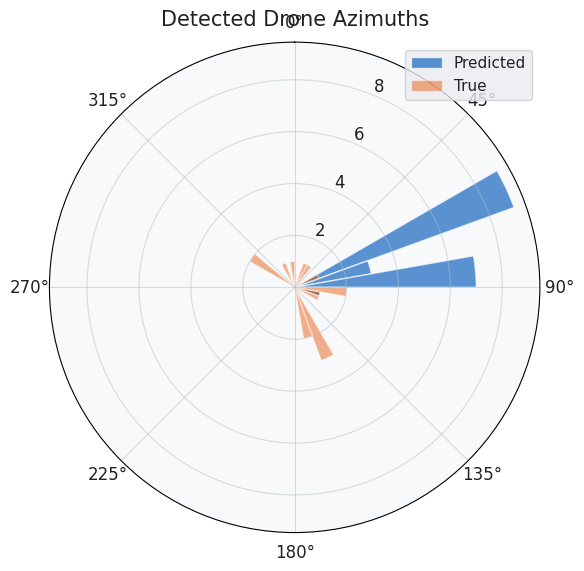

In [ ]:
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

test_ds = load_test_dataset_zip(
  "/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios.zip",
  cfg=config,
  dataset_format="auto",   # or "uavirbase" / "pannoniafs" / "generic_triplet" / "flat_wavs" - # bypass auto-detect
  max_sessions=20,         # optional — useful for a quick smoke test
)
print(test_ds)  # shows session count and format

results = run_test_dataset_evaluation(test_ds, config, save_csv="/content/drive/MyDrive/AUS LAB II/test_dataset/test_scenarios_dataset_results.csv")

In [ ]:
from drone_detection.mems_inference import analyse_bk_array_file
# Use the fixed version
result = analyse_bk_array_file(
    "/content/seg_036_circle_test_ch0.wav",
    "/content/seg_036_circle_test_ch1.wav",
    "/content/seg_036_circle_test_ch2.wav",
    config
)

print(f"Detection: {result['detected']}")
print(f"Probability: {result['probability']:.3f}")

✅ Detection model loaded  (ep=63, f1=0.9829268292682927, thr=0.945)
Detection: False
Probability: 0.185


✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_qp419689
📦 Loading test dataset from extracted_P.zip …
✅ Extracted to /tmp/drone_test_qp419689
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (3 labelled, 0 unlabelled)

  Test dataset evaluation: extracted_P.zip
  Format: generic_triplet  |  Sessions: 3
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          no   0.198  0.022   0.906      nan    -90.0       -     nan    2.50    nan
seg_031_circle_train          YES  0.939  0.872   0.956    -29.8    -90.0    60.2   31.52    2.50  13.56
seg_032_circle_train          YES  0.915  0.891   0.763    -66.6    -90.0    23.4   44.20    2.50  24.77

  Sessions evaluated : 3
  Detection rate     : 66.7%  (2/3)
  MAE azimuth        : 41.8°  (n=2)
  MAE

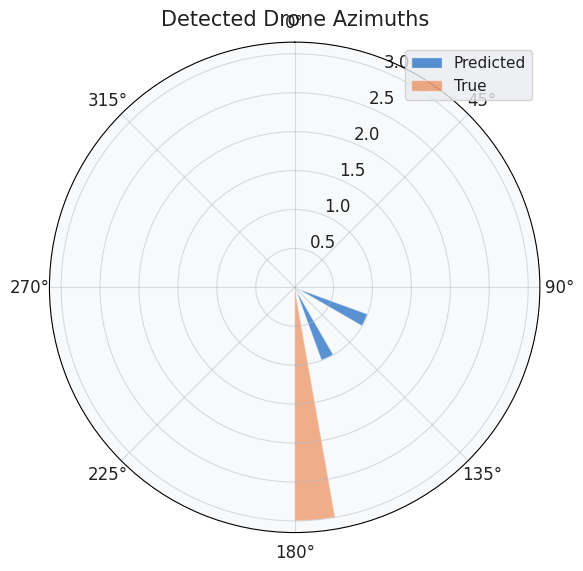

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  'extracted_P.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_nyd0rnxw
📦 Loading test dataset from extracted_B.zip …
✅ Extracted to /tmp/drone_test_nyd0rnxw
   Indexing sessions (format='generic_triplet') …
✅ Indexed 6 sessions  (6 labelled, 0 unlabelled)

  Test dataset evaluation: extracted_B.zip
  Format: generic_triplet  |  Sessions: 6
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_005_hover_val             YES  0.324  0.249   0.627    -61.1      0.0    61.1   41.17    0.00  22.76
seg_006_hover_val             YES  0.784  0.879   0.401    -28.5      0.0    28.5   29.95    0.00  13.65
seg_007_transit_train         YES  0.292  0.197   0.669    -26.8    -90.0    63.2   30.11   60.00  13.25
seg_008_transit_train         YES  0.327  0.206   0.812    -29.5    -90.0    60.5   30.58   60.00  14.3

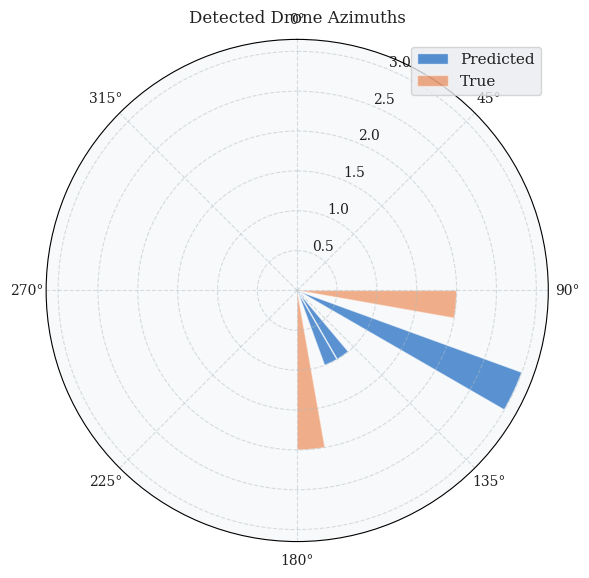

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/extracted_B.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_7iar46tn
📦 Loading test dataset from extracted_P.zip …
✅ Extracted to /tmp/drone_test_7iar46tn
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (3 labelled, 0 unlabelled)

  Test dataset evaluation: extracted_P.zip
  Format: generic_triplet  |  Sessions: 3
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          no   0.198  0.022   0.906      nan    -90.0       -     nan    2.50    nan
seg_031_circle_train          YES  0.939  0.872   0.956    -29.8    -90.0    60.2   31.52    2.50  13.56
seg_032_circle_train          YES  0.915  0.891   0.763    -66.6    -90.0    23.4   44.20    2.50  24.77

  Sessions evaluated : 3
  Detection rate     : 66.7%  (2/3)
  MAE azimuth        : 41.8°  (n=2)
  MAE

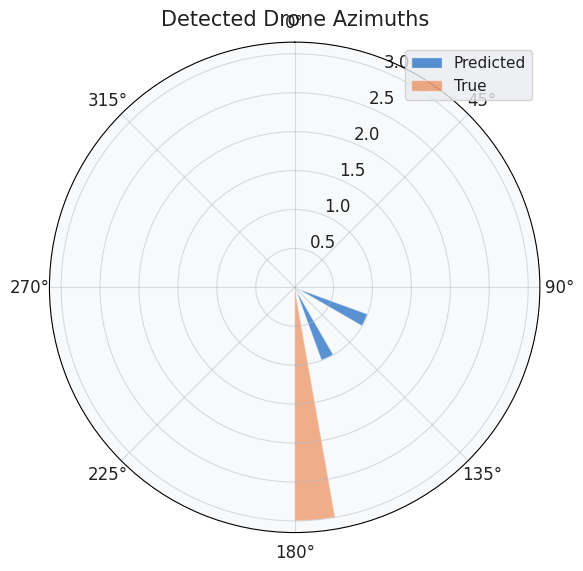

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/extracted_P.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/extracted_B.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_2x53m_bm
📦 Loading test dataset from dunakeszi_pipeline_ready_P.zip …
✅ Extracted to /tmp/drone_test_2x53m_bm
   Indexing sessions (format='generic_triplet') …
✅ Indexed 3 sessions  (3 labelled, 0 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready_P.zip
  Format: generic_triplet  |  Sessions: 3
✅ Detection model loaded  (ep=113, f1=0.997002997002997, thr=0.055)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=66, val_loss=0.83923)
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_030_circle_train          YES  0.198  0.022   0.906    -59.6   -180.0   120.4   38.90    2.50  22.24
seg_031_circle_train          YES  0.939  0.872   0.956    -29.8   -180.0   150.2   31.52    2.50  13

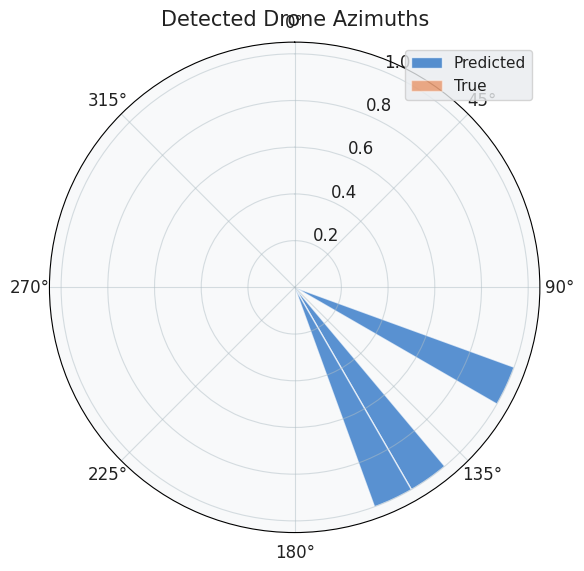

In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  '/content/dunakeszi_pipeline_ready_P.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

In [ ]:
from drone_detection import config
config.DETECTION_THRESHOLD = 0.30  # use fused score, not CNN alone

# Or bypass the threshold entirely and read raw scores:
from drone_detection.inference import detect, load_3ch
channels = load_3ch(['/content/seg_021_figure8_train_ch0.wav',
                     '/content/seg_021_figure8_train_ch1.wav',
                     '/content/seg_021_figure8_train_ch2.wav'], config)
result = detect(channels, config)
print(result)
# The raw cnn_probability and heuristic_probability tell you the truth
# regardless of threshold

{'detected': False, 'probability': 0.19991205446658358, 'label': 'weak_possible_drone', 'cnn_probability': 0.04344065487384796, 'heuristic_probability': 0.8257976528375259, 'heuristic_features': {'rms_db': -27.928532055379307, 'median_frame_entropy': 0.5453404784202576, 'p10_entropy': 0.4944579601287842, 'crest_factor': 3.620779333595548, 'comb_score': 0.1275249736999835, 'centroid_hz': 444.296989104219, 'rolloff_hz': 627.0402238175676, 'bandwidth_hz': 1164.705276552395, 'voiced_ratio': 0.7760617760617761, 'f0_median_hz': 63.360984802246094, 'f0_std_hz': 4.291186332702637}}


In [ ]:
from drone_detection.inference import heuristic_detect, load_3ch
from pathlib import Path
import soundfile as sf, numpy as np

for ch0_path in sorted(Path('/content/').glob('*_ch0.wav')):
    y, sr = sf.read(ch0_path)
    result = heuristic_detect(y.astype(np.float32), config)
    print(f"{ch0_path.stem}: {result['probability']:.3f}  {result['label']}")

seg_021_figure8_train_ch0: 0.826  drone


In [ ]:
from drone_detection import config
from drone_detection.inference_test_loader import load_test_dataset_zip, run_test_dataset_evaluation

config.set_array_geometry('gp2')
config.MAX_LOCALIZATION_DIST = 100.0
config.DETECTION_THRESHOLD = 0.2

# Zip the output folder, then:
test_ds = load_test_dataset_zip(
  'dunakeszi_pipeline_ready.zip',
  cfg=config,
  dataset_format='generic_triplet',
)
results = run_test_dataset_evaluation(test_ds, cfg=config, show_plots=True)

✅ Array geometry set to 'gp2'  baseline ≈ 2.795 m
📂 Extracting to temp dir: /tmp/drone_test_qcwup7m8
📦 Loading test dataset from dunakeszi_pipeline_ready.zip …
✅ Extracted to /tmp/drone_test_qcwup7m8
   Indexing sessions (format='generic_triplet') …
✅ Indexed 2 sessions  (1 labelled, 1 unlabelled)

  Test dataset evaluation: dunakeszi_pipeline_ready.zip
  Format: generic_triplet  |  Sessions: 2
✅ Detection model loaded  (ep=85, f1=0.9840375586854461, thr=0.930)
🔧 Using LocalizationCNN (full-capacity mode, ipd_in_dim=4)
✅ Localization model loaded  (ep=66, val_loss=0.83923)
Session                       Det  Prob   CNN_P  Heur_P  Az_p     Az_t     Err     Di_p    Di_t    Ht_p 
--------------------------------------------------------------------------------------------------------
seg_020_circle_train          no   0.178  0.039   0.735      nan   -180.0       -     nan   30.00    nan
seg_021_figure8_train         no   0.214  0.062   0.826      nan        -       -     nan       -    nan


In [ ]:
from drone_detection.inference import heuristic_detect, load_3ch
from pathlib import Path
import soundfile as sf, numpy as np

for ch0_path in sorted(Path('/content/').glob('*_ch0.wav')):
    y, sr = sf.read(ch0_path)
    result = heuristic_detect(y.astype(np.float32), config)
    print(f"{ch0_path.stem}: {result['probability']:.3f}  {result['label']}")

seg_005_hover_val_ch0: 0.627  possible_drone
seg_006_hover_val_ch0: 0.401  possible_drone
seg_007_transit_train_ch0: 0.669  possible_drone
seg_008_transit_train_ch0: 0.812  possible_drone
seg_010_diagonal_train_ch0: 0.756  possible_drone
seg_011_diagonal_train_ch0: 0.873  possible_drone


In [ ]:
from drone_detection.inference import heuristic_detect, load_3ch
from pathlib import Path
import soundfile as sf, numpy as np

for ch0_path in sorted(Path('/content/').glob('*_ch0.wav')):
    y, sr = sf.read(ch0_path)
    result = heuristic_detect(y.astype(np.float32), config)
    print(f"{ch0_path.stem}: {result['probability']:.3f}  {result['label']}")

In [ ]:
launch_ui(config)

Saving seg_032_circle_train_ch2.wav to seg_032_circle_train_ch2.wav
Saving seg_032_circle_train_ch1.wav to seg_032_circle_train_ch1.wav
Saving seg_032_circle_train_ch0.wav to seg_032_circle_train_ch0.wav


In [ ]:
MIC0 = '/content/seg_032_circle_train_ch0.wav'   # <-- change
MIC1 = '/content/seg_032_circle_train_ch1.wav'   # <-- change
MIC2 = '/content/seg_032_circle_train_ch2.wav'   # <-- change

tracker = KalmanTracker(config)
result  = run_pipeline([MIC0, MIC1, MIC2], cfg=config, tracker=tracker, multi_drone=True)

print(f'Detected: {result["detected"]}  |  Fused p: {result["probability"]:.3f}  |  Drones: {len(result["drones"])}')
for i, loc in enumerate(result['drones'], 1):
    print(f'\n  Drone {i}:')
    print(f'    Azimuth          : {loc["azimuth_deg"]:.1f}\u00b0')
    print(f'    Distance         : {loc["distance_m"]:.2f} m')
    print(f'    XY               : ({loc["xy_position"][0]:.2f}, {loc["xy_position"][1]:.2f}) m')
    print(f'    TDOA residual    : {loc["tdoa_residual"]:.2e}')
    print(f'    Confidence radius: {loc["confidence_radius"]:.2f} m')

if result['drones']:
    plot_multi_drone_positions(result['drones'], config, save=True)

confirmed = tracker.all_confirmed()
if confirmed:
    plot_kalman_trajectories(confirmed, config, save=True)

NameError: name 'KalmanTracker' is not defined

In [ ]:
from dunakeszi_segment_analysis_inference import run_segment_analysis

#
# ── Cell 3a: Mono / single-mic analysis ──────────────────────────────────────
#
# results = run_segment_analysis(
#     segment_dir  = "/content/drive/MyDrive/drone_segments",
#     cfg          = config,
#     file_ext     = [".wav"],
#     sort_by_name = True,
#     n_mics       = 1,
#     show_plots   = True,
#     save_plots   = True,
#     save_csv     = True,
# )
#
# ── Cell 3b: 3-mic array analysis with multi-drone localization ───────────────
#
results = run_segment_analysis(
    cfg          = config,
    file_ext     = [".wav"],
    n_mics       = 3,
    mic_files    = [
        "/home/tildai/Desktop/Development/drone-detection-api/deployment/v2/dunakeszi_test_segments_B/seg_005_hover_val_ch0.wav",
        "/home/tildai/Desktop/Development/drone-detection-api/deployment/v2/dunakeszi_test_segments_B/seg_005_hover_val_ch1.wav",
        "/home/tildai/Desktop/Development/drone-detection-api/deployment/v2/dunakeszi_test_segments_B/seg_005_hover_val_ch2.wav",
    ],
    multi_drone  = True,          # enable multi-drone TDOA localization
    show_plots   = True,
    save_plots   = True,
    save_csv     = True,
)
#
# ── Cell 4: Inspect results ───────────────────────────────────────────────────
#
# import pandas as pd
# df = pd.DataFrame([
#     {k: r[k] for k in ["seg","filename","t_start","detected",
#                         "probability","azimuth_deg","distance_m","height_m"]}
#     for r in results["rows"]
# ])
# df.head(20)
#
# ── Cell 5: Inspect Kalman tracks ─────────────────────────────────────────────
#
# for track in results["confirmed_tracks"]:
#     print(track.to_dict())
#

: 